## Data 2D maps — continued analysis

Continue investigating incident-photon-energy versus electron-kinetic-energy maps, production bunch-response corrections, and run-dependent yield variations.

Copied from `Bunch investigations.ipynb`, starting at **Data 2D maps** and continuing through the end. The setup below supplies the earlier imports, calibration, metadata readers, and counting/correction helpers required by these cells. Run it before the copied analysis sections.

**Datasets:** the 150C 271.5–275.0 eV and 7 June / 147C 274.0–276.0 eV aggregate lists are retained in their respective loading cells. The independent chronology section discovers available runs, including 276.5 eV when present. Exact combined-H5 paths and train trimming come from aggregate provenance. Aggregate files resolve relative to `config.COMBINED_DIR`; calibration is `config.COMBINED_DIR.parent / "Calibrations" / "etof_energy_calibration_t0_scan.json"`. The setup retains the source notebook's default `FLASH_ENV=remote`.

**Steps:** load datasets, learn production Cb, calculate and compare spectra/maps, check fixed-GMD and KE windows, compare temperature series, and inspect chronology/monitors. Original cuts, calibration, binning, normalisation, and execution settings are preserved. Outputs and execution counts are cleared for a fresh session. Full-data cells should run on a compute node on Maxwell; this notebook has not been executed during copying.


## Setup copied from the original notebook


In [1]:
import os
import sys
import re
import json
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

os.environ.setdefault("FLASH_ENV", "remote")


def find_repo_root(start=None):
    start = Path.cwd().resolve() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "analysis" / "scripts").exists():
            return path

    fallback = Path("/home/mmanresa/glycine26")
    if (fallback / "analysis" / "scripts").exists():
        return fallback

    raise RuntimeError("Could not find repository root containing analysis/scripts")


repo_root = find_repo_root()
scripts_dir = repo_root / "analysis" / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))

import config

AGG_DIR = Path(config.COMBINED_DIR)
CALIB_PATH = (
    Path(config.COMBINED_DIR).parent
    / "Calibrations"
    / "etof_energy_calibration_t0_scan.json"
)

with open(CALIB_PATH, "r", encoding="utf-8") as handle:
    calib = json.load(handle)

best_t0 = calib["t0_tof_units"]
best_slope = calib["slope_eV_tof_unit2"]
best_E0 = calib["E0_eV"]


def tof_to_ke(tof):
    tof = np.asarray(tof, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ke = best_slope / (tof - best_t0) ** 2 + best_E0
    return np.where(tof > best_t0, ke, np.nan)


plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
})

print("repo_root:", repo_root)
print("combined :", AGG_DIR)
print("calib    :", CALIB_PATH)

repo_root: /home/mmanresa/glycine26
combined : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined
calib    : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/Calibrations/etof_energy_calibration_t0_scan.json


In [2]:
# Earlier parameter definitions used by the counting helper and comparison settings.
LAG_KE_RANGE = (180.0, 265.0)
DELAY_ZERO_STAGE = 0.0
FS_PER_STAGE_UNIT = 3.33 / 10000.0
DELAY_WINDOW_FS = None


In [3]:
# Train-selection and aggregate-path helpers used by the copied analysis.
def keep_mask_like_compute_aggregates_from_h5(handle, trim_start=0, trim_end=0):
    if "between_tdc_files" not in handle:
        return np.ones(handle["gmd"].shape[0], dtype=bool)

    between_tdc_files = handle["between_tdc_files"][:].astype(bool)
    good_positions = np.where(~between_tdc_files)[0]

    if trim_end > 0:
        good_positions = good_positions[trim_start:-trim_end]
    else:
        good_positions = good_positions[trim_start:]

    keep = np.zeros(between_tdc_files.shape[0], dtype=bool)
    keep[good_positions] = True
    return keep

def aggregate_path(filename):
    path = Path(filename)
    return path if path.is_absolute() else AGG_DIR / path

def photon_energy_from_name(path):
    match = re.search(r"([0-9]+(?:\.[0-9]+)?)eV", Path(path).name)
    return float(match.group(1)) if match else np.nan

def delay_window_to_stage_window(delay_window_fs):
    if delay_window_fs is None:
        return None

    lo_fs, hi_fs = delay_window_fs
    lo_stage = lo_fs / FS_PER_STAGE_UNIT + DELAY_ZERO_STAGE
    hi_stage = hi_fs / FS_PER_STAGE_UNIT + DELAY_ZERO_STAGE

    return min(lo_stage, hi_stage), max(lo_stage, hi_stage)


In [4]:
# --- Aggregate metadata loader ---

def load_aggregate_info(path):
    path = Path(path)
    with h5py.File(path, "r") as handle:
        metadata = {}
        for key in handle.attrs:
            value = handle.attrs[key]
            if isinstance(value, bytes):
                value = value.decode()
            elif isinstance(value, np.ndarray):
                value = value.tolist()
            metadata[key] = value

        info = {
            "path": path,
            "metadata": metadata,
            "tof_edges": handle["tof_edges"][:],
            "gmd_edges": handle["gmd_edges"][:],
            "n_per_bin": handle["n_per_bin"][:],
            "G": handle["G"][:],
            "D_shape": handle["D"].shape if "D" in handle else None,
            "z_edges": handle["z_edges"][:] if "z_edges" in handle else None,
        }

    return info

In [5]:
BUNCH_CORR_RANGE = (0, 101)

def electron_counts_from_tof(tofs_e, ke_range=LAG_KE_RANGE):
    valid = tofs_e > 0
    counts = np.zeros(tofs_e.shape[:2], dtype=np.int32)
    if np.any(valid):
        ke = tof_to_ke(tofs_e[valid])
        in_range = (ke >= ke_range[0]) & (ke < ke_range[1])
        flat_index = np.flatnonzero(valid)[in_range] // tofs_e.shape[-1]
        counts.flat[:] = np.bincount(flat_index, minlength=counts.size)
    return counts

def build_bunch_factor(sum_e, sum_gmd, sum_shots, bunch_range=BUNCH_CORR_RANGE):
    b0, b1 = bunch_range
    response = np.divide(sum_e, sum_gmd, out=np.full_like(sum_e, np.nan), where=sum_gmd > 0)
    band_mean = np.sum(sum_e[:, b0:b1], axis=1) / np.sum(sum_gmd[:, b0:b1], axis=1)
    relative = response / band_mean[:, None]
    valid = np.isfinite(relative)
    weights = np.where(valid, sum_shots, 0.0)
    factor = np.divide(np.sum(np.where(valid, relative * weights, 0.0), axis=0), np.sum(weights, axis=0), out=np.full(sum_e.shape[1], np.nan), where=np.sum(weights, axis=0) > 0)
    w = np.sum(sum_shots[:, b0:b1], axis=0)
    factor /= np.average(factor[b0:b1], weights=w)
    return factor


def _stream_dataset_metrics(ds, chunk_trains, gmd_bands):
    tot_shots, tot_gmd, tot_elec = 0, 0.0, 0.0
    band_acc = {l: {"shots": 0, "sum_gmd": 0.0, "electrons": 0.0} for l in gmd_bands}
    with h5py.File(Path(ds["source_h5"]), "r") as f:
        keep = keep_mask_like_compute_aggregates_from_h5(f, trim_start=ds["trim_start"], trim_end=ds["trim_end"])
        n_trains = f["gmd"].shape[0]
        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]
            if not np.any(row_keep): continue
            gmd, tofs, valid = f["gmd"][start:stop][row_keep].astype(float), f["tofs_e"][start:stop][row_keep], np.isfinite(f["gmd"][start:stop][row_keep])
            if np.any(valid):
                tot_shots += int(np.count_nonzero(valid)); tot_gmd += float(np.sum(gmd[valid])); tot_elec += _count_selected_electrons(tofs[valid])
            for l, (lo, hi) in gmd_bands.items():
                sel = valid & (gmd >= lo) & (gmd < hi)
                if np.any(sel):
                    band_acc[l]["shots"] += int(np.count_nonzero(sel))
                    band_acc[l]["sum_gmd"] += float(np.sum(gmd[sel]))
                    band_acc[l]["electrons"] += _count_selected_electrons(tofs[sel])
    return {"shots": tot_shots, "sum_gmd": tot_gmd, "electrons": tot_elec, "bands": band_acc}


def _count_selected_electrons(tofs):
    if tofs.size == 0: return 0.0
    return float(np.count_nonzero(np.isfinite(tofs) & (tofs > 0))) if USE_ALL_ELECTRONS else float(np.sum(electron_counts_from_tof(tofs, ke_range=ELECTRON_KE_RANGE)))


## Data 2D maps

In [6]:
CB_AGG_FILENAMES = [
    "glycine_delay_scan_150C_long_271.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_271.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_272.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5",
    # Add any other aggregate files you want to include, for example:
    # "glycine_delay_scan_150C_272.0eV_aggregates_tr_etof1.h5",
    # "glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5",
    # ...
]

In [7]:
# --- Production Cb map: load all incident-energy datasets ----------------

PROD2D_CB_REF_KE_RANGE = (220.0, 260.0)

# Use the range over which the multi-energy Cb was established.
PROD2D_GMD_RANGE = (1.0, 12.0)
PROD2D_CB_GMD_BANDS = [
    (1.0, 2.0),
    (3.0, 4.0),
    (5.0, 6.0),
    (6.0, 8.0),
    (8.0, 12.0),
]

PROD2D_TOF_RANGE = (800, 1200)
PROD2D_KE_RANGE = (180.0, 280.0)
PROD2D_CHUNK_TRAINS = 250

prod2d_datasets = []

for filename in CB_AGG_FILENAMES:
    agg_path = aggregate_path(filename)

    if not agg_path.exists():
        raise FileNotFoundError(f"Aggregate file not found:\n{agg_path}")

    agg_info = load_aggregate_info(agg_path)

    input_h5 = agg_info["metadata"].get("input_h5", "")
    if isinstance(input_h5, bytes):
        input_h5 = input_h5.decode()

    source_h5_i = Path(input_h5)

    if not source_h5_i.exists():
        raise FileNotFoundError(f"Source H5 not found:\n{source_h5_i}")

    prod2d_datasets.append({
        "photon_energy_ev": photon_energy_from_name(agg_path),
        "agg_path": agg_path,
        "source_h5": source_h5_i,
        "trim_start": int(agg_info["metadata"].get("trim_start", 0) or 0),
        "trim_end": int(agg_info["metadata"].get("trim_end", 0) or 0),
    })

prod2d_datasets = sorted(
    prod2d_datasets,
    key=lambda ds: ds["photon_energy_ev"],
)

print("Production-map datasets:")
for ds in prod2d_datasets:
    print(
        f"  {ds['photon_energy_ev']:5.1f} eV  "
        f"{ds['source_h5'].name}"
    )

Production-map datasets:
  271.0 eV  glycine_delay_scan_150C_long_271.0eV.h5
  271.5 eV  glycine_delay_scan_150C_long_271.5eV.h5
  272.0 eV  glycine_delay_scan_150C_long_272.0eV.h5
  272.5 eV  glycine_delay_scan_150C_272.5eV.h5
  273.0 eV  glycine_delay_scan_150C_273.0eV.h5
  273.5 eV  glycine_delay_scan_150C_273.5eV.h5
  274.0 eV  glycine_delay_scan_150C_274.0eV.h5
  274.5 eV  glycine_delay_scan_150C_274.5eV.h5
  275.0 eV  glycine_delay_scan_150C_275.0eV.h5


In [8]:
# --- Production Cb and corrected spectrum for every incident energy ------

tof_edges_prod2d = np.arange(PROD2D_TOF_RANGE[0] - 0.5, PROD2D_TOF_RANGE[1] + 1.0, 1.0)

ke_edges_prod2d = tof_to_ke(tof_edges_prod2d)
reverse_ke_prod2d = ke_edges_prod2d[0] > ke_edges_prod2d[-1]

if reverse_ke_prod2d:
    ke_edges_prod2d = ke_edges_prod2d[::-1]

ke_centres_prod2d = 0.5 * (ke_edges_prod2d[:-1] + ke_edges_prod2d[1:])
ke_widths_prod2d = np.diff(ke_edges_prod2d)

ke_select_prod2d = (
    np.isfinite(ke_centres_prod2d)
    & np.isfinite(ke_widths_prod2d)
    & (ke_widths_prod2d > 0)
    & (ke_centres_prod2d >= PROD2D_KE_RANGE[0])
    & (ke_centres_prod2d < PROD2D_KE_RANGE[1])
)

ke_idx_prod2d = np.where(ke_select_prod2d)[0]

if ke_idx_prod2d.size == 0:
    raise ValueError("No KE bins fall inside PROD2D_KE_RANGE.")

if not np.all(np.diff(ke_idx_prod2d) == 1):
    raise ValueError("Selected KE bins are unexpectedly non-contiguous.")

ke_plot_prod2d = ke_centres_prod2d[ke_select_prod2d]
ke_width_plot_prod2d = ke_widths_prod2d[ke_select_prod2d]
ke_edges_plot_prod2d = ke_edges_prod2d[ke_idx_prod2d[0] : ke_idx_prod2d[-1] + 2]


def production_cb_and_spectrum_2d(ds):
    """
    Learn one full-data Cb for this incident energy and return the
    ordinary and production-Cb-corrected eTOF spectra.
    """
    source_h5 = Path(ds["source_h5"])

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )

        n_trains, n_bunch = handle["gmd"].shape
        n_bands = len(PROD2D_CB_GMD_BANDS)
        n_tof = len(tof_edges_prod2d) - 1

        # Quantities used to learn Cb.
        sum_e_ref = np.zeros((n_bands, n_bunch))
        sum_gmd_ref = np.zeros_like(sum_e_ref)
        sum_shots_ref = np.zeros_like(sum_e_ref)

        # Quantities used for the final spectrum.
        spectral_counts = np.zeros(n_tof)
        sum_gmd_by_bunch = np.zeros(n_bunch)
        shots_by_bunch = np.zeros(n_bunch, dtype=np.int64)

        for start in range(0, n_trains, PROD2D_CHUNK_TRAINS):
            stop = min(start + PROD2D_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            tofs = handle["tofs_e"][start:stop][row_keep]

            # -------------------------------------------------------------
            # Reference electrons used to determine Cb.
            # -------------------------------------------------------------
            ref_counts = electron_counts_from_tof(tofs, ke_range=PROD2D_CB_REF_KE_RANGE).astype(float)

            for j, (lo, hi) in enumerate(PROD2D_CB_GMD_BANDS):
                band = np.isfinite(gmd) & (gmd >= lo) & (gmd < hi)

                sum_e_ref[j] += np.sum(np.where(band, ref_counts, 0.0), axis=0)
                sum_gmd_ref[j] += np.sum(np.where(band, gmd, 0.0), axis=0)
                sum_shots_ref[j] += np.sum(band, axis=0)

            # -------------------------------------------------------------
            # Full spectrum. Shot selection remains based on RAW GMD.
            # -------------------------------------------------------------
            selected = (
                np.isfinite(gmd)
                & (gmd >= PROD2D_GMD_RANGE[0])
                & (gmd < PROD2D_GMD_RANGE[1])
            )

            events = tofs[selected].reshape(-1)
            valid_hits = (
                np.isfinite(events)
                & (events >= PROD2D_TOF_RANGE[0])
                & (events <= PROD2D_TOF_RANGE[1])
            )

            spectral_counts += np.histogram(events[valid_hits], bins=tof_edges_prod2d)[0]
            sum_gmd_by_bunch += np.sum(np.where(selected, gmd, 0.0), axis=0)
            shots_by_bunch += np.sum(selected, axis=0)

    # One production Cb learned from ALL valid trains.
    cb = build_bunch_factor(
        sum_e_ref, sum_gmd_ref, sum_shots_ref, bunch_range=(0, n_bunch)
    )

    if not np.all(np.isfinite(cb)):
        raise ValueError(f"Non-finite production Cb at {ds['photon_energy_ev']:g} eV.")

    # The ordinary and corrected total exposures.
    sum_gmd = np.sum(sum_gmd_by_bunch)
    sum_gmd_eff = np.sum(sum_gmd_by_bunch * cb)

    if reverse_ke_prod2d:
        spectral_counts = spectral_counts[::-1]

    counts_plot = spectral_counts[ke_select_prod2d]

    with np.errstate(invalid="ignore", divide="ignore"):
        spectrum_gmd = counts_plot / sum_gmd / ke_width_plot_prod2d
        spectrum_cb = counts_plot / sum_gmd_eff / ke_width_plot_prod2d

    return {
        "photon_energy_ev": ds["photon_energy_ev"],
        "cb": cb,
        "sum_gmd": sum_gmd,
        "sum_gmd_eff": sum_gmd_eff,
        "correction_scale": sum_gmd / sum_gmd_eff,
        "shots": int(np.sum(shots_by_bunch)),
        "spectrum_gmd": spectrum_gmd,
        "spectrum_cb": spectrum_cb,
    }


prod2d_results = []

for ds in prod2d_datasets:
    print(f"Processing {ds['photon_energy_ev']:g} eV ...")
    prod2d_results.append(production_cb_and_spectrum_2d(ds))

print("\nProduction corrections:")
print("energy    Cb range          sumG/sum(GCb)")

for result in prod2d_results:
    print(
        f"{result['photon_energy_ev']:5.1f}   "
        f"{np.min(result['cb']):.4f}-{np.max(result['cb']):.4f}       "
        f"{result['correction_scale']:.5f}"
    )

Processing 271 eV ...
Processing 271.5 eV ...
Processing 272 eV ...
Processing 272.5 eV ...
Processing 273 eV ...
Processing 273.5 eV ...
Processing 274 eV ...
Processing 274.5 eV ...
Processing 275 eV ...

Production corrections:
energy    Cb range          sumG/sum(GCb)
271.0   0.8227-1.1964       0.99917
271.5   0.8641-1.1550       1.00012
272.0   0.8649-1.1759       1.00069
272.5   0.7407-1.2566       1.00005
273.0   0.6944-1.3351       1.00177
273.5   0.5853-1.3451       1.00335
274.0   0.4371-1.2914       0.99958
274.5   0.4655-1.2677       0.99691
275.0   0.5033-1.2849       0.99489


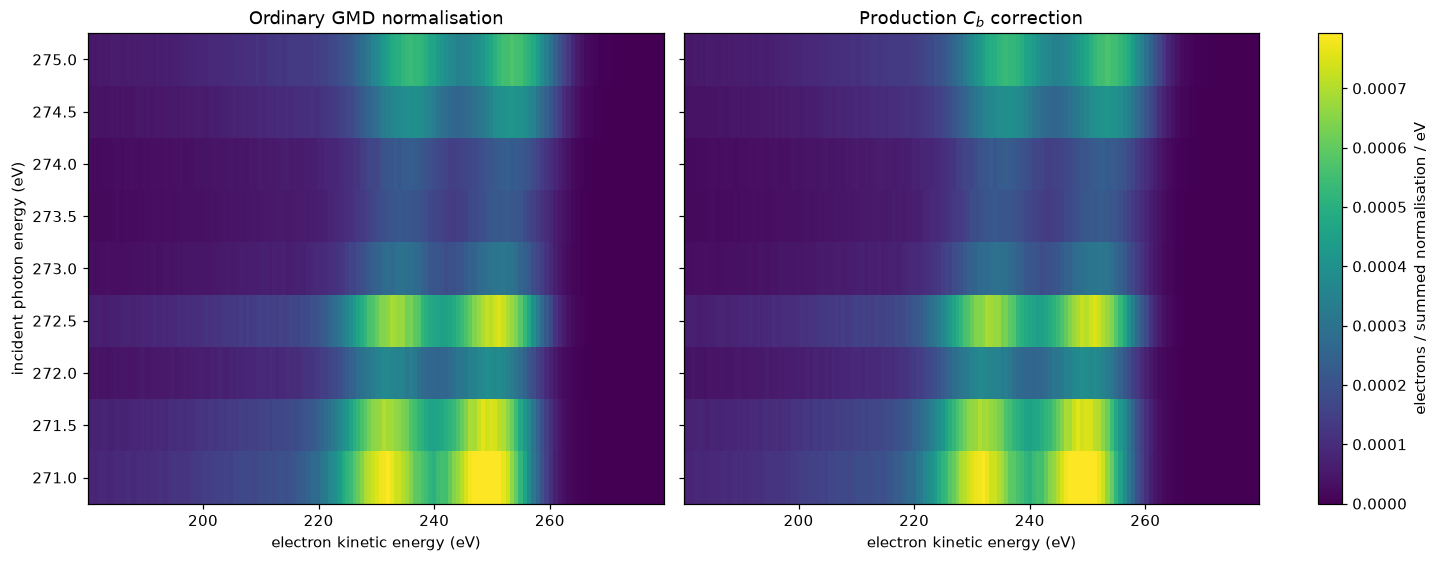

In [9]:
# --- Incident-energy vs electron-KE map before and after production Cb ---

prod2d_energy = np.array([r["photon_energy_ev"] for r in prod2d_results])
map_gmd = np.vstack([r["spectrum_gmd"] for r in prod2d_results])
map_cb = np.vstack([r["spectrum_cb"] for r in prod2d_results])

def centres_to_edges(x):
    x = np.asarray(x, dtype=float)
    if x.size < 2: raise ValueError("At least two centres are required.")
    edges = np.empty(x.size + 1)
    edges[1:-1] = 0.5 * (x[:-1] + x[1:])
    edges[0] = x[0] - 0.5 * (x[1] - x[0])
    edges[-1] = x[-1] + 0.5 * (x[-1] - x[-2])
    return edges

energy_edges_prod2d = centres_to_edges(prod2d_energy)

all_values = np.concatenate([map_gmd[np.isfinite(map_gmd)], map_cb[np.isfinite(map_cb)]])
vmin = np.nanpercentile(all_values, 1)
vmax = np.nanpercentile(all_values, 99.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True, constrained_layout=True)

for ax, values, title in zip(
    axes,
    [map_gmd, map_cb],
    ["Ordinary GMD normalisation", r"Production $C_b$ correction"],
):
    im = ax.pcolormesh(
        ke_edges_plot_prod2d,
        energy_edges_prod2d,
        values,
        shading="auto",
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_xlabel("electron kinetic energy (eV)")
    ax.set_title(title)

axes[0].set_ylabel("incident photon energy (eV)")

fig.colorbar(im, ax=axes, label="electrons / summed normalisation / eV")

# fig.suptitle(
#     rf"$C_b$ learned independently at each incident energy from "
#     f"{PROD2D_CB_REF_KE_RANGE[0]:g}-{PROD2D_CB_REF_KE_RANGE[1]:g} eV electrons"
# )

plt.show()

### Diagnostics

energy    shots        mean GMD    e/shot       e/uJ        Cb RMS (%)
271.0   2,804,602     4.8492    0.145445    0.029993        8.755
271.5   2,806,160     4.5868    0.120864    0.026350        6.698
272.0   2,563,180     4.3679    0.062131    0.014225        7.033
272.5   2,721,652     4.5042    0.116275    0.025815       12.172
273.0   2,873,007     5.6024    0.061885    0.011046       16.921
273.5   2,937,232     6.0786    0.049974    0.008221       20.631
274.0   2,930,225     6.0464    0.053081    0.008779       24.906
274.5   2,945,935     5.8937    0.089751    0.015228       24.994
275.0   2,941,913     5.7754    0.118393    0.020500       23.492


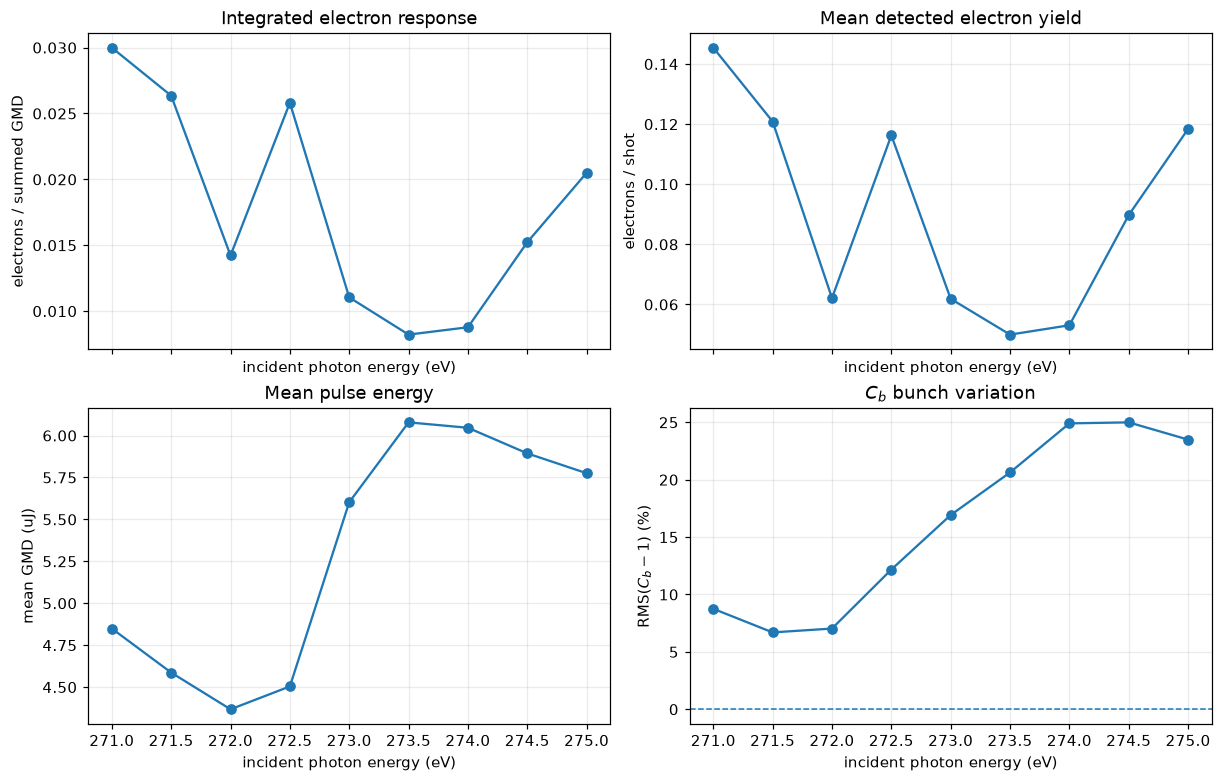

In [10]:

# --- Diagnose incident-energy-dependent scaling in the 2D map -----------

diag_sum_gmd = np.array([
    result["sum_gmd"]
    for result in prod2d_results
])

diag_shots = np.array([
    result["shots"]
    for result in prod2d_results
])

diag_mean_gmd = diag_sum_gmd / diag_shots

# Integral of spectrum over the plotted KE range:
# electrons / summed GMD.
diag_e_per_gmd = np.array([
    np.nansum(
        result["spectrum_gmd"]
        * ke_width_plot_prod2d
    )
    for result in prod2d_results
])

# Convert back to mean detected electrons per selected shot.
diag_e_per_shot = (
    diag_e_per_gmd
    * diag_sum_gmd
    / diag_shots
)

# RMS bunch-dependent deviation of Cb from 1, in percent.
diag_cb_rms = np.array([
    100.0 * np.sqrt(np.mean((np.asarray(result["cb"], dtype=float) - 1.0)**2))
    for result in prod2d_results
])

print(
    "energy    shots        mean GMD    "
    "e/shot       e/uJ        Cb RMS (%)"
)

for i, energy in enumerate(prod2d_energy):
    print(
        f"{energy:5.1f}  "
        f"{diag_shots[i]:10,d}  "
        f"{diag_mean_gmd[i]:9.4f}  "
        f"{diag_e_per_shot[i]:10.6f}  "
        f"{diag_e_per_gmd[i]:10.6f}  "
        f"{diag_cb_rms[i]:11.3f}"
    )

fig, axes = plt.subplots(
    2, 2, figsize=(11, 7),
    sharex=True, constrained_layout=True,
)

axes[0, 0].plot(prod2d_energy, diag_e_per_gmd, "o-")
axes[0, 0].set_ylabel("electrons / summed GMD")
axes[0, 0].set_title("Integrated electron response")

axes[0, 1].plot(prod2d_energy, diag_e_per_shot, "o-")
axes[0, 1].set_ylabel("electrons / shot")
axes[0, 1].set_title("Mean detected electron yield")

axes[1, 0].plot(prod2d_energy, diag_mean_gmd, "o-")
axes[1, 0].set_ylabel("mean GMD (uJ)")
axes[1, 0].set_title("Mean pulse energy")

axes[1, 1].plot(prod2d_energy, diag_cb_rms, "o-")
axes[1, 1].axhline(0.0, ls="--", lw=1)
axes[1, 1].set_ylabel(r"RMS($C_b-1$) (%)")
axes[1, 1].set_title(r"$C_b$ bunch variation")

for ax in axes.flat:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)

plt.show()


Fixing GMD to see if the effect persists

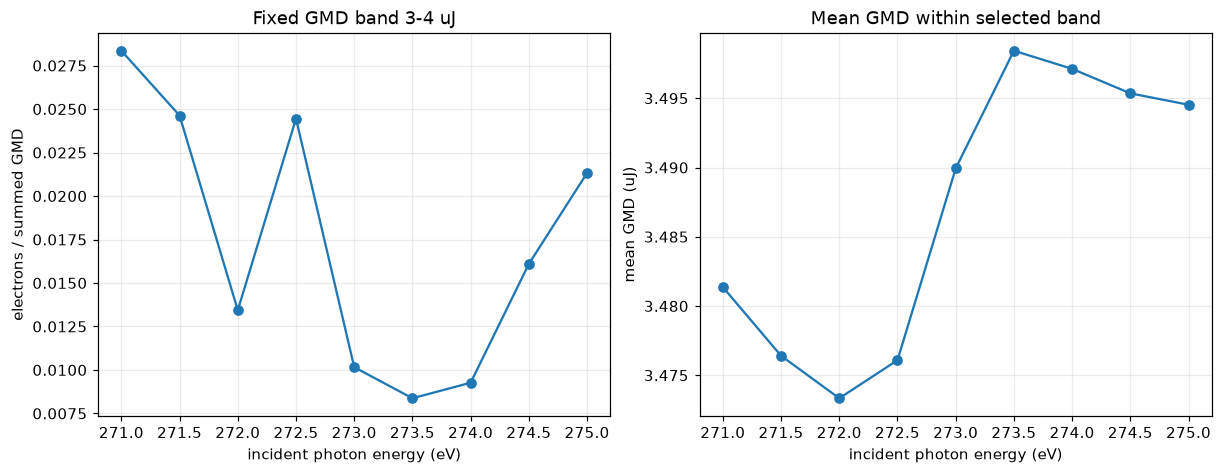

energy    shots       mean GMD    electrons/uJ
271.0     390,495     3.4814      0.028355
271.5     402,544     3.4764      0.024628
272.0     368,767     3.4733      0.013434
272.5     395,602     3.4761      0.024452
273.0     357,425     3.4899      0.010158
273.5     331,289     3.4984      0.008372
274.0     334,485     3.4971      0.009266
274.5     349,515     3.4954      0.016098
275.0     356,780     3.4945      0.021325


In [11]:
# --- Fixed-GMD-band test across incident photon energy -------------------

FIXED_MAP_GMD_RANGE = (3.0, 4.0)
fixed_band_results = []

for ds in prod2d_datasets:
    energy = ds["photon_energy_ev"]
    counts = np.zeros(len(tof_edges_prod2d) - 1, dtype=float)
    sum_gmd = 0.0
    shots = 0

    with h5py.File(ds["source_h5"], "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, PROD2D_CHUNK_TRAINS):
            stop = min(start + PROD2D_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            tofs = handle["tofs_e"][start:stop][row_keep]

            selected = (
                np.isfinite(gmd)
                & (gmd >= FIXED_MAP_GMD_RANGE[0])
                & (gmd < FIXED_MAP_GMD_RANGE[1])
            )
            events = tofs[selected].reshape(-1)
            valid_hits = (
                np.isfinite(events)
                & (events >= PROD2D_TOF_RANGE[0])
                & (events <= PROD2D_TOF_RANGE[1])
            )

            counts += np.histogram(events[valid_hits], bins=tof_edges_prod2d)[0]
            sum_gmd += np.sum(gmd[selected])
            shots += np.count_nonzero(selected)

    if reverse_ke_prod2d:
        counts = counts[::-1]

    counts = counts[ke_select_prod2d]
    spectrum = counts / sum_gmd / ke_width_plot_prod2d
    integrated_yield = np.sum(spectrum * ke_width_plot_prod2d)

    fixed_band_results.append({
        "energy": energy,
        "shots": shots,
        "sum_gmd": sum_gmd,
        "mean_gmd": sum_gmd / shots,
        "spectrum": spectrum,
        "integrated_yield": integrated_yield,
    })

fixed_band_results = sorted(fixed_band_results, key=lambda r: r["energy"])
fixed_energy = np.array([r["energy"] for r in fixed_band_results])
fixed_yield = np.array([r["integrated_yield"] for r in fixed_band_results])
fixed_mean_gmd = np.array([r["mean_gmd"] for r in fixed_band_results])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

axes[0].plot(fixed_energy, fixed_yield, "o-")
axes[0].set_xlabel("incident photon energy (eV)")
axes[0].set_ylabel("electrons / summed GMD")
axes[0].set_title(
    f"Fixed GMD band {FIXED_MAP_GMD_RANGE[0]:g}-{FIXED_MAP_GMD_RANGE[1]:g} uJ"
)
axes[0].grid(alpha=0.25)

axes[1].plot(fixed_energy, fixed_mean_gmd, "o-")
axes[1].set_xlabel("incident photon energy (eV)")
axes[1].set_ylabel("mean GMD (uJ)")
axes[1].set_title("Mean GMD within selected band")
axes[1].grid(alpha=0.25)

plt.show()

print("energy    shots       mean GMD    electrons/uJ")
for r in fixed_band_results:
    print(
        f"{r['energy']:5.1f}  "
        f"{r['shots']:10,d}  "
        f"{r['mean_gmd']:9.4f}  "
        f"{r['integrated_yield']:12.6f}"
    )

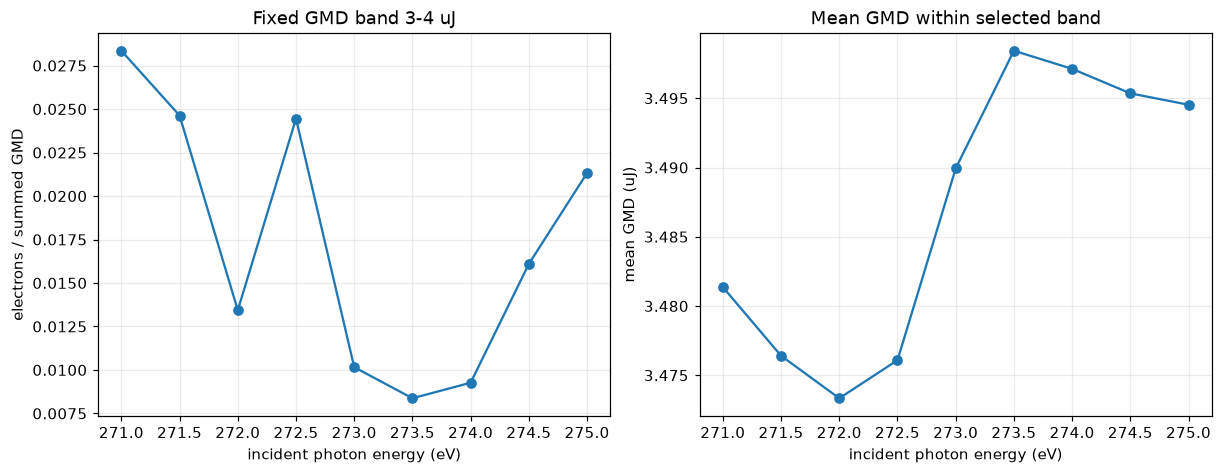

energy    shots       mean GMD    electrons/uJ
271.0     390,495     3.4814      0.028355
271.5     402,544     3.4764      0.024628
272.0     368,767     3.4733      0.013434
272.5     395,602     3.4761      0.024452
273.0     357,425     3.4899      0.010158
273.5     331,289     3.4984      0.008372
274.0     334,485     3.4971      0.009266
274.5     349,515     3.4954      0.016098
275.0     356,780     3.4945      0.021325


In [12]:
# --- Fixed-GMD-band test across incident photon energy -------------------

FIXED_MAP_GMD_RANGE = (3.0, 4.0)
fixed_band_results = []

for ds in prod2d_datasets:
    energy = ds["photon_energy_ev"]
    counts = np.zeros(len(tof_edges_prod2d) - 1, dtype=float)
    sum_gmd = 0.0
    shots = 0

    with h5py.File(ds["source_h5"], "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, PROD2D_CHUNK_TRAINS):
            stop = min(start + PROD2D_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            tofs = handle["tofs_e"][start:stop][row_keep]

            selected = (
                np.isfinite(gmd)
                & (gmd >= FIXED_MAP_GMD_RANGE[0])
                & (gmd < FIXED_MAP_GMD_RANGE[1])
            )
            events = tofs[selected].reshape(-1)
            valid_hits = (
                np.isfinite(events)
                & (events >= PROD2D_TOF_RANGE[0])
                & (events <= PROD2D_TOF_RANGE[1])
            )

            counts += np.histogram(events[valid_hits], bins=tof_edges_prod2d)[0]
            sum_gmd += np.sum(gmd[selected])
            shots += np.count_nonzero(selected)

    if reverse_ke_prod2d:
        counts = counts[::-1]

    counts = counts[ke_select_prod2d]
    spectrum = counts / sum_gmd / ke_width_plot_prod2d
    integrated_yield = np.sum(spectrum * ke_width_plot_prod2d)

    fixed_band_results.append({
        "energy": energy,
        "shots": shots,
        "sum_gmd": sum_gmd,
        "mean_gmd": sum_gmd / shots,
        "spectrum": spectrum,
        "integrated_yield": integrated_yield,
    })

fixed_band_results = sorted(fixed_band_results, key=lambda r: r["energy"])
fixed_energy = np.array([r["energy"] for r in fixed_band_results])
fixed_yield = np.array([r["integrated_yield"] for r in fixed_band_results])
fixed_mean_gmd = np.array([r["mean_gmd"] for r in fixed_band_results])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

axes[0].plot(fixed_energy, fixed_yield, "o-")
axes[0].set_xlabel("incident photon energy (eV)")
axes[0].set_ylabel("electrons / summed GMD")
axes[0].set_title(
    f"Fixed GMD band {FIXED_MAP_GMD_RANGE[0]:g}-{FIXED_MAP_GMD_RANGE[1]:g} uJ"
)
axes[0].grid(alpha=0.25)

axes[1].plot(fixed_energy, fixed_mean_gmd, "o-")
axes[1].set_xlabel("incident photon energy (eV)")
axes[1].set_ylabel("mean GMD (uJ)")
axes[1].set_title("Mean GMD within selected band")
axes[1].grid(alpha=0.25)

plt.show()

print("energy    shots       mean GMD    electrons/uJ")
for r in fixed_band_results:
    print(
        f"{r['energy']:5.1f}  "
        f"{r['shots']:10,d}  "
        f"{r['mean_gmd']:9.4f}  "
        f"{r['integrated_yield']:12.6f}"
    )

There is a large incident-energy/run-dependent variation in the absolute eTOF yield per measured GMD. This variation persists at fixed GMD and is therefore not explained by the different GMD distributions. The underlying spectral shapes are considerably more stable than the absolute amplitudes.

### Comparing with itof

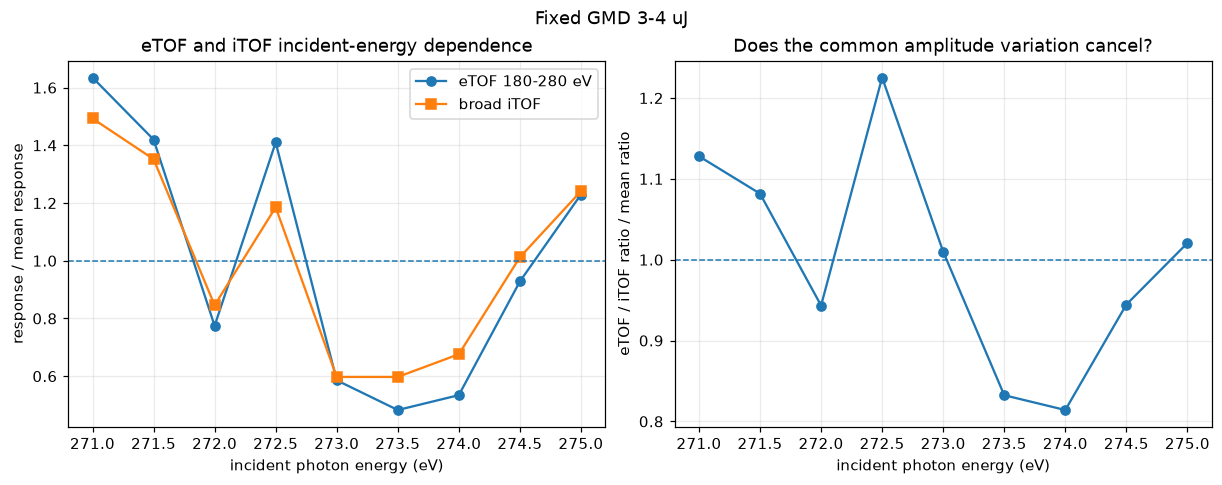

energy    shots       mean GMD    eTOF/uJ      iTOF/uJ      e/i
271.0     390,495     3.4814    0.028355    0.222494    0.127440
271.5     402,544     3.4764    0.024628    0.201512    0.122214
272.0     368,767     3.4733    0.013434    0.126045    0.106581
272.5     395,602     3.4761    0.024452    0.176625    0.138439
273.0     357,425     3.4899    0.010158    0.089024    0.114105
273.5     331,289     3.4984    0.008372    0.089020    0.094045
274.0     334,485     3.4971    0.009266    0.100744    0.091978
274.5     349,515     3.4954    0.016098    0.150854    0.106715
275.0     356,780     3.4945    0.021325    0.184929    0.115312


In [13]:
# --- Incident-energy dependence: eTOF versus iTOF at fixed GMD ----------

EI_ENERGY_GMD_RANGE = (3.0, 4.0)
EI_KE_RANGE = (180.0, 280.0)
EI_ION_TOF_RANGE = (0, 50000)
EI_CHUNK_TRAINS = 250

ei_energy_results = []

for ds in prod2d_datasets:
    energy = ds["photon_energy_ev"]
    sum_gmd = 0.0
    shots = 0
    electrons = 0
    ions = 0

    with h5py.File(ds["source_h5"], "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, EI_CHUNK_TRAINS):
            stop = min(start + EI_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            tofs_e = handle["tofs_e"][start:stop][row_keep]
            tofs_i = handle["tofs_i"][start:stop][row_keep]

            selected = (
                np.isfinite(gmd)
                & (gmd >= EI_ENERGY_GMD_RANGE[0])
                & (gmd < EI_ENERGY_GMD_RANGE[1])
            )

            if not selected.any():
                continue

            e_counts = electron_counts_from_tof(tofs_e, ke_range=EI_KE_RANGE)
            i_counts = np.sum(
                (tofs_i > EI_ION_TOF_RANGE[0]) & (tofs_i < EI_ION_TOF_RANGE[1]),
                axis=-1,
            )

            sum_gmd += float(np.sum(gmd[selected]))
            shots += int(np.count_nonzero(selected))
            electrons += int(np.sum(e_counts[selected]))
            ions += int(np.sum(i_counts[selected]))

    ei_energy_results.append({
        "energy": energy,
        "shots": shots,
        "mean_gmd": sum_gmd / shots,
        "electrons_per_gmd": electrons / sum_gmd,
        "ions_per_gmd": ions / sum_gmd,
        "electrons": electrons,
        "ions": ions,
    })

ei_energy_results = sorted(ei_energy_results, key=lambda r: r["energy"])
ei_energy = np.array([r["energy"] for r in ei_energy_results])
ei_e = np.array([r["electrons_per_gmd"] for r in ei_energy_results])
ei_i = np.array([r["ions_per_gmd"] for r in ei_energy_results])

# Normalise each detector independently so we compare the incident-energy shape.
ei_e_rel = ei_e / np.mean(ei_e)
ei_i_rel = ei_i / np.mean(ei_i)

# eTOF/iTOF ratio removes any multiplicative factor common to both channels.
ei_ratio = ei_e / ei_i
ei_ratio_rel = ei_ratio / np.mean(ei_ratio)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)

axes[0].plot(
    ei_energy,
    ei_e_rel,
    "o-",
    label=f"eTOF {EI_KE_RANGE[0]:g}-{EI_KE_RANGE[1]:g} eV",
)
axes[0].plot(ei_energy, ei_i_rel, "s-", label="broad iTOF")
axes[0].axhline(1.0, ls="--", lw=1)
axes[0].set_xlabel("incident photon energy (eV)")
axes[0].set_ylabel("response / mean response")
axes[0].set_title("eTOF and iTOF incident-energy dependence")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(ei_energy, ei_ratio_rel, "o-")
axes[1].axhline(1.0, ls="--", lw=1)
axes[1].set_xlabel("incident photon energy (eV)")
axes[1].set_ylabel("eTOF / iTOF ratio / mean ratio")
axes[1].set_title("Does the common amplitude variation cancel?")
axes[1].grid(alpha=0.25)

fig.suptitle(
    f"Fixed GMD {EI_ENERGY_GMD_RANGE[0]:g}-{EI_ENERGY_GMD_RANGE[1]:g} uJ"
)
plt.show()

print("energy    shots       mean GMD    eTOF/uJ      iTOF/uJ      e/i")
for r in ei_energy_results:
    print(
        f"{r['energy']:5.1f}  "
        f"{r['shots']:10,d}  "
        f"{r['mean_gmd']:9.4f}  "
        f"{r['electrons_per_gmd']:10.6f}  "
        f"{r['ions_per_gmd']:10.6f}  "
        f"{r['electrons_per_gmd'] / r['ions_per_gmd']:10.6f}"
    )

### Compare several KE windows to ensure it happens everywhere

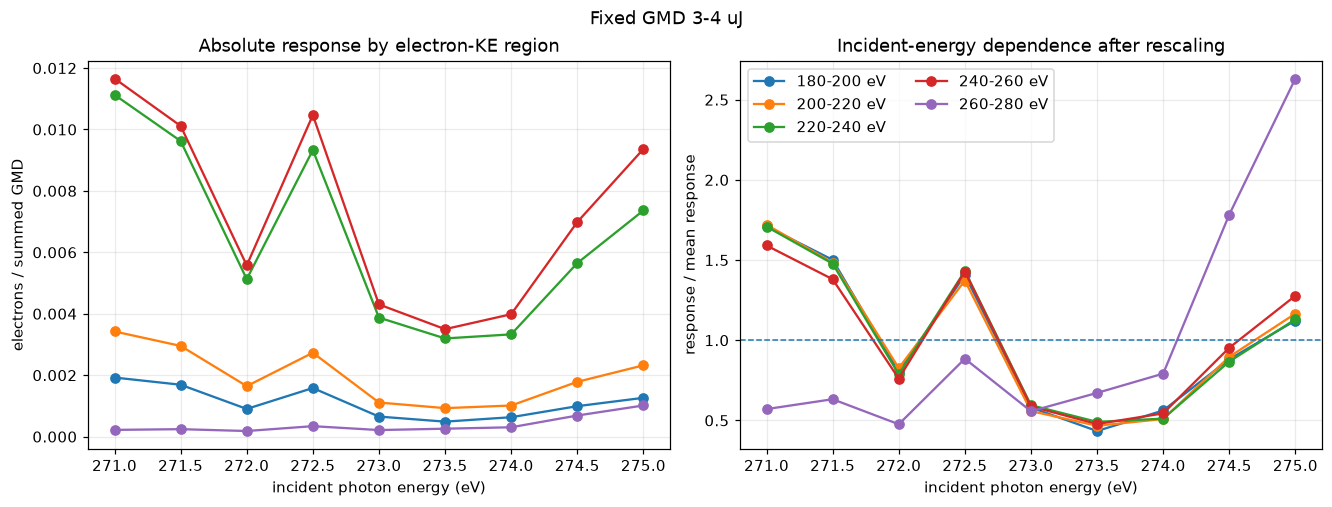

In [14]:
# --- Incident-energy dependence in separate electron-KE windows ----------

WINDOW_GMD_RANGE = (3.0, 4.0)

WINDOW_KE_RANGES = [
    (180.0, 200.0),
    (200.0, 220.0),
    (220.0, 240.0),
    (240.0, 260.0),
    (260.0, 280.0),
]

WINDOW_CHUNK_TRAINS = 250

window_results = {ke_range: [] for ke_range in WINDOW_KE_RANGES}

for ds in prod2d_datasets:
    energy = ds["photon_energy_ev"]

    sum_gmd = 0.0
    shots = 0

    counts_by_window = {ke_range: 0.0 for ke_range in WINDOW_KE_RANGES}

    with h5py.File(ds["source_h5"], "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )

        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, WINDOW_CHUNK_TRAINS):
            stop = min(start + WINDOW_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            tofs = handle["tofs_e"][start:stop][row_keep]

            selected = (
                np.isfinite(gmd)
                & (gmd >= WINDOW_GMD_RANGE[0])
                & (gmd < WINDOW_GMD_RANGE[1])
            )

            if not selected.any():
                continue

            sum_gmd += float(np.sum(gmd[selected]))
            shots += int(np.count_nonzero(selected))

            # Convert valid electron hits to KE only once per chunk.
            valid_hits = (tofs > 0) & selected[..., None]

            if not np.any(valid_hits):
                continue

            ke = tof_to_ke(tofs[valid_hits])

            for ke_range in WINDOW_KE_RANGES:
                counts_by_window[ke_range] += np.count_nonzero(
                    np.isfinite(ke) & (ke >= ke_range[0]) & (ke < ke_range[1])
                )

    for ke_range in WINDOW_KE_RANGES:
        window_results[ke_range].append({
            "energy": energy,
            "shots": shots,
            "sum_gmd": sum_gmd,
            "yield_per_gmd": counts_by_window[ke_range] / sum_gmd,
        })

# -------------------------------------------------------------------------
# Convert to arrays and normalise each KE trace by its own mean.
# -------------------------------------------------------------------------
window_energy = np.array([ds["photon_energy_ev"] for ds in prod2d_datasets])

order = np.argsort(window_energy)
window_energy = window_energy[order]

window_yields = {}
window_relative = {}

for ke_range in WINDOW_KE_RANGES:
    rows = sorted(window_results[ke_range], key=lambda r: r["energy"])

    y = np.array([r["yield_per_gmd"] for r in rows])

    window_yields[ke_range] = y
    window_relative[ke_range] = y / np.mean(y)

# -------------------------------------------------------------------------
# Plot.
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

for ke_range in WINDOW_KE_RANGES:
    label = f"{ke_range[0]:g}-{ke_range[1]:g} eV"

    axes[0].plot(
        window_energy, window_yields[ke_range], "o-", label=label
    )
    axes[1].plot(
        window_energy, window_relative[ke_range], "o-", label=label
    )

axes[0].set_xlabel("incident photon energy (eV)")
axes[0].set_ylabel("electrons / summed GMD")
axes[0].set_title("Absolute response by electron-KE region")
axes[0].grid(alpha=0.25)

axes[1].axhline(1.0, ls="--", lw=1)
axes[1].set_xlabel("incident photon energy (eV)")
axes[1].set_ylabel("response / mean response")
axes[1].set_title("Incident-energy dependence after rescaling")
axes[1].grid(alpha=0.25)
axes[1].legend(ncol=2)

fig.suptitle(
    f"Fixed GMD {WINDOW_GMD_RANGE[0]:g}-{WINDOW_GMD_RANGE[1]:g} uJ"
)

plt.show()

### Moving KE windows

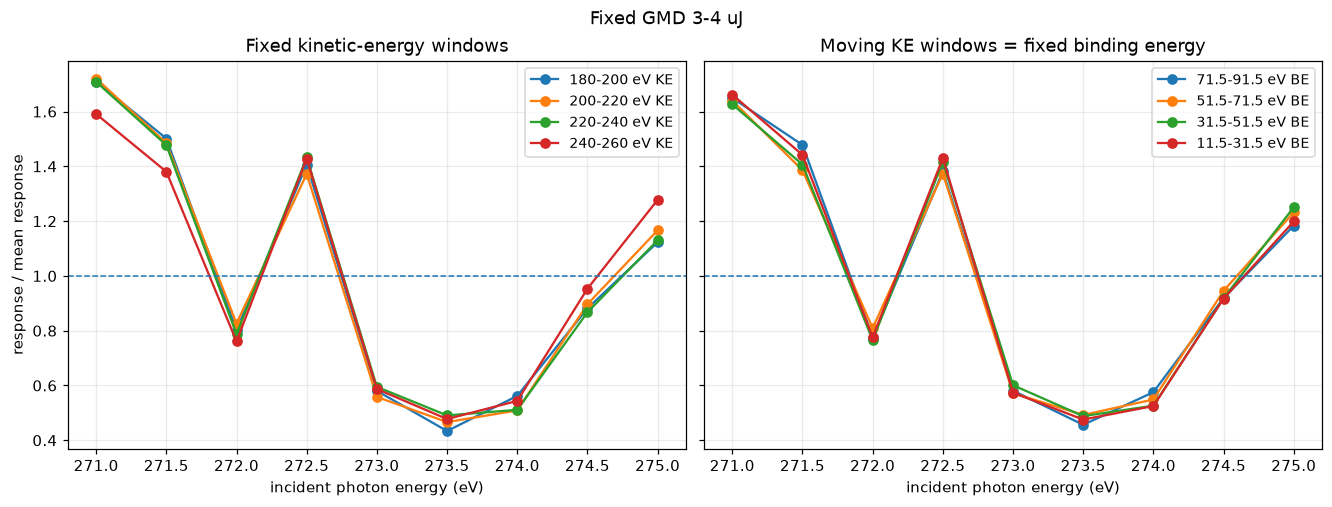

Reference photon energy: 271.5 eV
Reference KE window      Fixed binding-energy window
180.0-200.0 eV       71.5- 91.5 eV
200.0-220.0 eV       51.5- 71.5 eV
220.0-240.0 eV       31.5- 51.5 eV
240.0-260.0 eV       11.5- 31.5 eV


In [15]:
# --- Fixed-KE vs photoelectron-tracking windows across incident energy ---

TRACK_GMD_RANGE = (3.0, 4.0)
TRACK_REF_HV = 271.5

# Windows defined at the reference photon energy.
# The moving version shifts each window by hnu - TRACK_REF_HV.
TRACK_REF_KE_RANGES = [
    (180.0, 200.0),
    (200.0, 220.0),
    (220.0, 240.0),
    (240.0, 260.0),
]

TRACK_CHUNK_TRAINS = 250

track_results = []

for ds in prod2d_datasets:
    energy = float(ds["photon_energy_ev"])
    shift = energy - TRACK_REF_HV

    sum_gmd = 0.0
    shots = 0

    counts_fixed = np.zeros(len(TRACK_REF_KE_RANGES), dtype=float)
    counts_moving = np.zeros_like(counts_fixed)

    delay_window_stage = delay_window_to_stage_window(DELAY_WINDOW_FS)

    with h5py.File(ds["source_h5"], "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )

        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, TRACK_CHUNK_TRAINS):
            stop = min(start + TRACK_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            tofs = handle["tofs_e"][start:stop][row_keep]

            selected = (
                np.isfinite(gmd)
                & (gmd >= TRACK_GMD_RANGE[0])
                & (gmd < TRACK_GMD_RANGE[1])
            )

            if delay_window_stage is not None:
                z = handle["z"][start:stop][row_keep]
                z_lo, z_hi = delay_window_stage
                selected &= np.isfinite(z) & (z >= z_lo) & (z < z_hi)

            if not selected.any():
                continue

            sum_gmd += float(np.sum(gmd[selected]))
            shots += int(np.count_nonzero(selected))

            valid_hits = (tofs > 0) & selected[..., None]

            if not np.any(valid_hits):
                continue

            ke = tof_to_ke(tofs[valid_hits])
            ke = ke[np.isfinite(ke)]

            for j, (lo, hi) in enumerate(TRACK_REF_KE_RANGES):
                # Original fixed-KE diagnostic.
                counts_fixed[j] += np.count_nonzero((ke >= lo) & (ke < hi))

                # Same binding-energy region: shift KE with incident energy.
                moving_lo = lo + shift
                moving_hi = hi + shift

                counts_moving[j] += np.count_nonzero(
                    (ke >= moving_lo) & (ke < moving_hi)
                )

    track_results.append({
        "energy": energy,
        "shots": shots,
        "sum_gmd": sum_gmd,
        "fixed": counts_fixed / sum_gmd,
        "moving": counts_moving / sum_gmd,
    })

track_results = sorted(track_results, key=lambda r: r["energy"])
track_energy = np.array([r["energy"] for r in track_results])
track_fixed = np.vstack([r["fixed"] for r in track_results])
track_moving = np.vstack([r["moving"] for r in track_results])

# Normalise each spectral region independently so only the
# incident-energy dependence is compared.
track_fixed_rel = track_fixed / np.mean(track_fixed, axis=0, keepdims=True)
track_moving_rel = track_moving / np.mean(track_moving, axis=0, keepdims=True)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True
)

for j, (lo, hi) in enumerate(TRACK_REF_KE_RANGES):
    be_lo = TRACK_REF_HV - hi
    be_hi = TRACK_REF_HV - lo

    axes[0].plot(
        track_energy,
        track_fixed_rel[:, j],
        "o-",
        label=f"{lo:g}-{hi:g} eV KE",
    )
    axes[1].plot(
        track_energy,
        track_moving_rel[:, j],
        "o-",
        label=f"{be_lo:g}-{be_hi:g} eV BE",
    )

for ax in axes:
    ax.axhline(1.0, ls="--", lw=1)
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("response / mean response")
axes[0].set_title("Fixed kinetic-energy windows")
axes[1].set_title("Moving KE windows = fixed binding energy")

axes[0].legend(fontsize=9)
axes[1].legend(fontsize=9)

fig.suptitle(
    f"Fixed GMD {TRACK_GMD_RANGE[0]:g}-{TRACK_GMD_RANGE[1]:g} uJ"
)

plt.show()

print(
    f"Reference photon energy: {TRACK_REF_HV:g} eV\n"
    "Reference KE window      Fixed binding-energy window"
)

for lo, hi in TRACK_REF_KE_RANGES:
    print(
        f"{lo:5.1f}-{hi:5.1f} eV      "
        f"{TRACK_REF_HV-hi:5.1f}-{TRACK_REF_HV-lo:5.1f} eV"
    )

## 147 dataset


In [10]:
BUNCH_CORR_RANGE = (0, 101)

def electron_counts_from_tof(tofs_e, ke_range=LAG_KE_RANGE):
    valid = tofs_e > 0
    counts = np.zeros(tofs_e.shape[:2], dtype=np.int32)
    if np.any(valid):
        ke = tof_to_ke(tofs_e[valid])
        in_range = (ke >= ke_range[0]) & (ke < ke_range[1])
        flat_index = np.flatnonzero(valid)[in_range] // tofs_e.shape[-1]
        counts.flat[:] = np.bincount(flat_index, minlength=counts.size)
    return counts

def build_bunch_factor(sum_e, sum_gmd, sum_shots, bunch_range=BUNCH_CORR_RANGE):
    b0, b1 = bunch_range
    response = np.divide(sum_e, sum_gmd, out=np.full_like(sum_e, np.nan), where=sum_gmd > 0)
    band_mean = np.sum(sum_e[:, b0:b1], axis=1) / np.sum(sum_gmd[:, b0:b1], axis=1)
    relative = response / band_mean[:, None]
    valid = np.isfinite(relative)
    weights = np.where(valid, sum_shots, 0.0)
    factor = np.divide(np.sum(np.where(valid, relative * weights, 0.0), axis=0), np.sum(weights, axis=0), out=np.full(sum_e.shape[1], np.nan), where=np.sum(weights, axis=0) > 0)
    w = np.sum(sum_shots[:, b0:b1], axis=0)
    factor /= np.average(factor[b0:b1], weights=w)
    return factor



In [11]:
# --- 7 June / 147 C incident-energy scan: load datasets ------------------

J7_AGG_FILENAMES = [
    "glycine_delay_scan_7June_147C_274.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_7June_147C_274.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_7June_147C_275.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_7June_147C_275.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_7June_147C_276.0eV_aggregates_tr_etof1.h5",

]

J7_CB_REF_KE_RANGE = (220.0, 260.0)

J7_GMD_RANGE = (1.0, 12.0)
J7_CB_GMD_BANDS = [
    (1.0, 2.0),
    (3.0, 4.0),
    (5.0, 6.0),
    (6.0, 8.0),
    (8.0, 12.0),
]

J7_TOF_RANGE = (800, 1200)
J7_KE_RANGE = (180.0, 280.0)
J7_CHUNK_TRAINS = 250

j7_datasets = []

for filename in J7_AGG_FILENAMES:
    agg_path = aggregate_path(filename)

    if not agg_path.exists():
        raise FileNotFoundError(
            f"Aggregate file not found:\n{agg_path}"
        )

    agg_info = load_aggregate_info(agg_path)

    input_h5 = agg_info["metadata"].get("input_h5", "")
    if isinstance(input_h5, bytes):
        input_h5 = input_h5.decode()

    source_h5 = Path(input_h5)

    if not source_h5.exists():
        raise FileNotFoundError(
            f"Source H5 not found:\n{source_h5}"
        )

    j7_datasets.append({
        "photon_energy_ev": photon_energy_from_name(agg_path),
        "agg_path": agg_path,
        "source_h5": source_h5,
        "trim_start": int(
            agg_info["metadata"].get("trim_start", 0) or 0
        ),
        "trim_end": int(
            agg_info["metadata"].get("trim_end", 0) or 0
        ),
    })

j7_datasets = sorted(
    j7_datasets,
    key=lambda ds: ds["photon_energy_ev"],
)

print("7 June / 147 C datasets:")

for ds in j7_datasets:
    print(
        f"  {ds['photon_energy_ev']:5.1f} eV  "
        f"{ds['source_h5'].name}"
    )

7 June / 147 C datasets:
  274.0 eV  glycine_delay_scan_7June_147C_274.0eV.h5
  274.5 eV  glycine_delay_scan_7June_147C_274.5eV.h5
  275.0 eV  glycine_delay_scan_7June_147C_275.0eV.h5
  275.5 eV  glycine_delay_scan_7June_147C_275.5eV.h5
  276.0 eV  glycine_delay_scan_7June_147C_276.0eV.h5


In [12]:
# --- 7 June: production Cb and spectrum at every incident energy ---------

j7_tof_edges = np.arange(J7_TOF_RANGE[0] - 0.5, J7_TOF_RANGE[1] + 1.0, 1.0)
j7_ke_edges = tof_to_ke(j7_tof_edges)
j7_reverse_ke = j7_ke_edges[0] > j7_ke_edges[-1]

if j7_reverse_ke:
    j7_ke_edges = j7_ke_edges[::-1]

j7_ke_centres = 0.5 * (j7_ke_edges[:-1] + j7_ke_edges[1:])
j7_ke_widths = np.diff(j7_ke_edges)

j7_ke_select = (
    np.isfinite(j7_ke_centres) & np.isfinite(j7_ke_widths) & (j7_ke_widths > 0) &
    (j7_ke_centres >= J7_KE_RANGE[0]) & (j7_ke_centres < J7_KE_RANGE[1])
)

j7_ke_idx = np.where(j7_ke_select)[0]

if not np.all(np.diff(j7_ke_idx) == 1):
    raise ValueError("Selected J7 KE bins are unexpectedly non-contiguous.")

j7_ke_plot = j7_ke_centres[j7_ke_select]
j7_ke_width_plot = j7_ke_widths[j7_ke_select]
j7_ke_edges_plot = j7_ke_edges[j7_ke_idx[0]:j7_ke_idx[-1] + 2]


def j7_production_cb_and_spectrum(ds):
    source_h5 = Path(ds["source_h5"])

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )

        n_trains, n_bunch = handle["gmd"].shape
        n_bands = len(J7_CB_GMD_BANDS)
        n_tof = len(j7_tof_edges) - 1

        # Quantities used to determine production Cb.
        sum_e_ref = np.zeros((n_bands, n_bunch))
        sum_gmd_ref = np.zeros_like(sum_e_ref)
        sum_shots_ref = np.zeros_like(sum_e_ref)

        # Full spectrum and GMD exposure.
        spectral_counts = np.zeros(n_tof)
        sum_gmd_by_bunch = np.zeros(n_bunch)
        shots_by_bunch = np.zeros(n_bunch, dtype=np.int64)

        for start in range(0, n_trains, J7_CHUNK_TRAINS):
            stop = min(start + J7_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            tofs = handle["tofs_e"][start:stop][row_keep]

            # Reference region used to learn Cb.
            ref_counts = electron_counts_from_tof(tofs, ke_range=J7_CB_REF_KE_RANGE).astype(float)

            for j, (lo, hi) in enumerate(J7_CB_GMD_BANDS):
                band = np.isfinite(gmd) & (gmd >= lo) & (gmd < hi)
                sum_e_ref[j] += np.sum(np.where(band, ref_counts, 0.0), axis=0)
                sum_gmd_ref[j] += np.sum(np.where(band, gmd, 0.0), axis=0)
                sum_shots_ref[j] += np.sum(band, axis=0)

            # Full spectrum using the same raw-GMD shot selection.
            selected = np.isfinite(gmd) & (gmd >= J7_GMD_RANGE[0]) & (gmd < J7_GMD_RANGE[1])
            events = tofs[selected].reshape(-1)
            valid_hits = np.isfinite(events) & (events >= J7_TOF_RANGE[0]) & (events <= J7_TOF_RANGE[1])

            spectral_counts += np.histogram(events[valid_hits], bins=j7_tof_edges)[0]
            sum_gmd_by_bunch += np.sum(np.where(selected, gmd, 0.0), axis=0)
            shots_by_bunch += np.sum(selected, axis=0)

    # One full-data production Cb.
    cb = build_bunch_factor(sum_e_ref, sum_gmd_ref, sum_shots_ref, bunch_range=(0, n_bunch))

    if not np.all(np.isfinite(cb)):
        raise ValueError(f"Non-finite J7 production Cb at {ds['photon_energy_ev']:g} eV.")

    sum_gmd = np.sum(sum_gmd_by_bunch)
    sum_gmd_eff = np.sum(sum_gmd_by_bunch * cb)

    if j7_reverse_ke:
        spectral_counts = spectral_counts[::-1]

    counts_plot = spectral_counts[j7_ke_select]

    with np.errstate(invalid="ignore", divide="ignore"):
        spectrum_gmd = counts_plot / sum_gmd / j7_ke_width_plot
        spectrum_cb = counts_plot / sum_gmd_eff / j7_ke_width_plot

    return {
        "photon_energy_ev": ds["photon_energy_ev"],
        "cb": cb,
        "sum_gmd": sum_gmd,
        "sum_gmd_eff": sum_gmd_eff,
        "correction_scale": sum_gmd / sum_gmd_eff,
        "shots": int(np.sum(shots_by_bunch)),
        "spectrum_gmd": spectrum_gmd,
        "spectrum_cb": spectrum_cb,
    }


j7_results = []
for ds in j7_datasets:
    print(f"Processing {ds['photon_energy_ev']:g} eV ...")
    j7_results.append(j7_production_cb_and_spectrum(ds))

print("\nProduction corrections:")
print("energy    Cb range          sumG/sum(GCb)")

for result in j7_results:
    print(
        f"{result['photon_energy_ev']:5.1f}   "
        f"{np.min(result['cb']):.4f}-{np.max(result['cb']):.4f}       "
        f"{result['correction_scale']:.5f}"
    )

Processing 274 eV ...
Processing 274.5 eV ...
Processing 275 eV ...
Processing 275.5 eV ...
Processing 276 eV ...

Production corrections:
energy    Cb range          sumG/sum(GCb)
274.0   0.4951-1.2733       0.99358
274.5   0.5282-1.2878       0.99606
275.0   0.5632-1.2408       1.00061
275.5   0.5441-1.2841       0.99592
276.0   0.5455-1.2529       0.98580


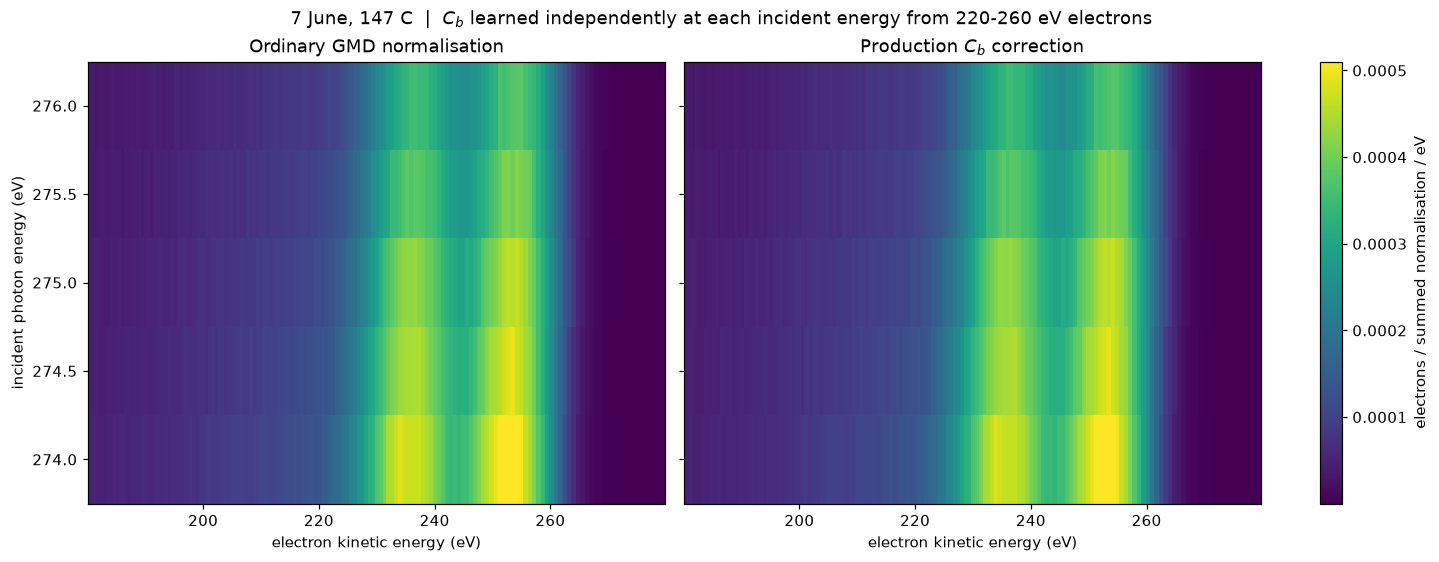

In [13]:
# --- 7 June: incident-energy vs electron-KE map before/after Cb ----------

j7_energy = np.array([result["photon_energy_ev"] for result in j7_results])
j7_map_gmd = np.vstack([result["spectrum_gmd"] for result in j7_results])
j7_map_cb = np.vstack([result["spectrum_cb"] for result in j7_results])


def j7_centres_to_edges(x):
    x = np.asarray(x, dtype=float)

    if x.size < 2:
        raise ValueError("At least two centres are required.")

    edges = np.empty(x.size + 1)
    edges[1:-1] = 0.5 * (x[:-1] + x[1:])
    edges[0] = x[0] - 0.5 * (x[1] - x[0])
    edges[-1] = x[-1] + 0.5 * (x[-1] - x[-2])

    return edges


j7_energy_edges = j7_centres_to_edges(j7_energy)

all_values = np.concatenate([
    j7_map_gmd[np.isfinite(j7_map_gmd)],
    j7_map_cb[np.isfinite(j7_map_cb)],
])

vmin = np.nanpercentile(all_values, 1)
vmax = np.nanpercentile(all_values, 99.5)

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharex=True, sharey=True, constrained_layout=True
)

for ax, values, title in zip(
    axes,
    [j7_map_gmd, j7_map_cb],
    ["Ordinary GMD normalisation", r"Production $C_b$ correction"],
):
    im = ax.pcolormesh(
        j7_ke_edges_plot, j7_energy_edges, values, shading="auto", vmin=vmin, vmax=vmax
    )
    ax.set_xlabel("electron kinetic energy (eV)")
    ax.set_title(title)

axes[0].set_ylabel("incident photon energy (eV)")

fig.colorbar(im, ax=axes, label="electrons / summed normalisation / eV")
fig.suptitle(
    "7 June, 147 C  |  "
    rf"$C_b$ learned independently at each incident energy "
    f"from {J7_CB_REF_KE_RANGE[0]:g}-{J7_CB_REF_KE_RANGE[1]:g} eV electrons"
)

plt.show()

In [14]:
from pathlib import Path
from matplotlib.lines import Line2D
import h5py, numpy as np, matplotlib.pyplot as plt

USE_ALL_ELECTRONS, ELECTRON_KE_RANGE = True, (180.0, 280.0)
COMPARE_GMD_BANDS = {"1-2": (1.0, 2.0), "3-4": (3.0, 4.0), "5-6": (5.0, 6.0), "6-8": (6.0, 8.0), "8-12": (8.0, 12.0), "12-24": (12.0, 24.0)}
FAMILY_ORDER, FAMILY_COLOURS, FAMILY_LINESTYLES = ["150C", "147C (7 June)"], {"150C": "tab:blue", "147C (7 June)": "tab:orange"}, {"150C": "-", "147C (7 June)": "--"}
BAND_COLOURS = {"1-2": "tab:blue", "3-4": "tab:orange", "5-6": "tab:green", "6-8": "tab:red", "8-12": "tab:purple", "12-24": "tab:brown"}
COMPARE_FAMILIES = {"150C": {"datasets": prod2d_datasets, "results": prod2d_results, "chunk_trains": PROD2D_CHUNK_TRAINS}, "147C (7 June)": {"datasets": j7_datasets, "results": j7_results, "chunk_trains": PROD2D_CHUNK_TRAINS}}



def _stream_dataset_metrics(ds, chunk_trains, gmd_bands):
    tot_shots, tot_gmd, tot_elec = 0, 0.0, 0.0
    band_acc = {l: {"shots": 0, "sum_gmd": 0.0, "electrons": 0.0} for l in gmd_bands}
    with h5py.File(Path(ds["source_h5"]), "r") as f:
        keep = keep_mask_like_compute_aggregates_from_h5(f, trim_start=ds["trim_start"], trim_end=ds["trim_end"])
        n_trains = f["gmd"].shape[0]
        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]
            if not np.any(row_keep): continue
            gmd, tofs, valid = f["gmd"][start:stop][row_keep].astype(float), f["tofs_e"][start:stop][row_keep], np.isfinite(f["gmd"][start:stop][row_keep])
            if np.any(valid):
                tot_shots += int(np.count_nonzero(valid)); tot_gmd += float(np.sum(gmd[valid])); tot_elec += _count_selected_electrons(tofs[valid])
            for l, (lo, hi) in gmd_bands.items():
                sel = valid & (gmd >= lo) & (gmd < hi)
                if np.any(sel):
                    band_acc[l]["shots"] += int(np.count_nonzero(sel))
                    band_acc[l]["sum_gmd"] += float(np.sum(gmd[sel]))
                    band_acc[l]["electrons"] += _count_selected_electrons(tofs[sel])
    return {"shots": tot_shots, "sum_gmd": tot_gmd, "electrons": tot_elec, "bands": band_acc}

def _build_family_diagnostics(cfg):
    datasets, res_by_e = sorted(cfg["datasets"], key=lambda d: d["photon_energy_ev"]), {r["photon_energy_ev"]: r for r in cfg["results"]}
    energy, e_gmd, e_shot, mean_gmd, cb_rms = [], [], [], [], []
    band_arrs = {l: {"e_per_gmd": [], "mean_gmd": []} for l in COMPARE_GMD_BANDS}
    for ds in datasets:
        e_ev, streamed = ds["photon_energy_ev"], _stream_dataset_metrics(ds, cfg["chunk_trains"], COMPARE_GMD_BANDS)
        energy.append(e_ev)
        if streamed["shots"] > 0 and streamed["sum_gmd"] > 0:
            e_gmd.append(streamed["electrons"] / streamed["sum_gmd"])
            e_shot.append(streamed["electrons"] / streamed["shots"])
            mean_gmd.append(streamed["sum_gmd"] / streamed["shots"])
        else:
            e_gmd.append(np.nan); e_shot.append(np.nan); mean_gmd.append(np.nan)
        cb = np.asarray(res_by_e[e_ev]["cb"], dtype=float)
        cb_rms.append(100.0 * np.sqrt(np.mean((cb - 1.0) ** 2)))
        for l in COMPARE_GMD_BANDS:
            b = streamed["bands"][l]
            if b["shots"] > 0 and b["sum_gmd"] > 0:
                band_arrs[l]["e_per_gmd"].append(b["electrons"] / b["sum_gmd"])
                band_arrs[l]["mean_gmd"].append(b["sum_gmd"] / b["shots"])
            else:
                band_arrs[l]["e_per_gmd"].append(np.nan); band_arrs[l]["mean_gmd"].append(np.nan)
    return {"energy": np.asarray(energy), "e_per_gmd": np.asarray(e_gmd), "e_per_shot": np.asarray(e_shot), "mean_gmd": np.asarray(mean_gmd), "cb_rms": np.asarray(cb_rms), "bands": {l: {"e_per_gmd": np.asarray(v["e_per_gmd"]), "mean_gmd": np.asarray(v["mean_gmd"])} for l, v in band_arrs.items()}}

count_label = "all eTOF hits" if USE_ALL_ELECTRONS else f"electrons in {ELECTRON_KE_RANGE[0]:.0f}-{ELECTRON_KE_RANGE[1]:.0f} eV"
family_diags = {
    name: _build_family_diagnostics(cfg)
    for name, cfg in COMPARE_FAMILIES.items()
}


150C
energy    all eTOF hits / summed GMD    all eTOF hits / shot    mean GMD    Cb RMS (%)
271.0        0.127090                  0.594259      4.6759       8.755
271.5        0.114214                  0.484962      4.2461       6.698
272.0        0.064238                  0.240187      3.7390       7.033
272.5        0.093999                  0.390740      4.1568      12.172
273.0        0.041397                  0.249500      6.0270      16.921
273.5        0.032446                  0.216483      6.6722      20.631
274.0        0.034833                  0.231241      6.6386      24.906
274.5        0.058158                  0.371788      6.3927      24.994
275.0        0.077437                  0.480234      6.2016      23.492

147C (7 June)
energy    all eTOF hits / summed GMD    all eTOF hits / shot    mean GMD    Cb RMS (%)
274.0        0.085515                  0.487688      5.7029      22.717
274.5        0.088466                  0.474903      5.3682      20.985
275.0        

/tmp/ipykernel_3865332/1324731453.py:10: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 0].plot(diag["energy"], diag["e_per_gmd"], "o-", color=c, ls=ls, label=name)
/tmp/ipykernel_3865332/1324731453.py:11: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 1].plot(diag["energy"], diag["e_per_shot"], "o-", color=c, ls=ls, label=name)
/tmp/ipykernel_3865332/1324731453.py:12: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[1, 0].plot(diag["energy"], diag["mean_gmd"], "o-", color=c, ls=ls, label=name)
/tmp/ipykernel_3865332/1324731453.py:13: UserWarning: linestyle is redundantly defined by the 'linestyle' key

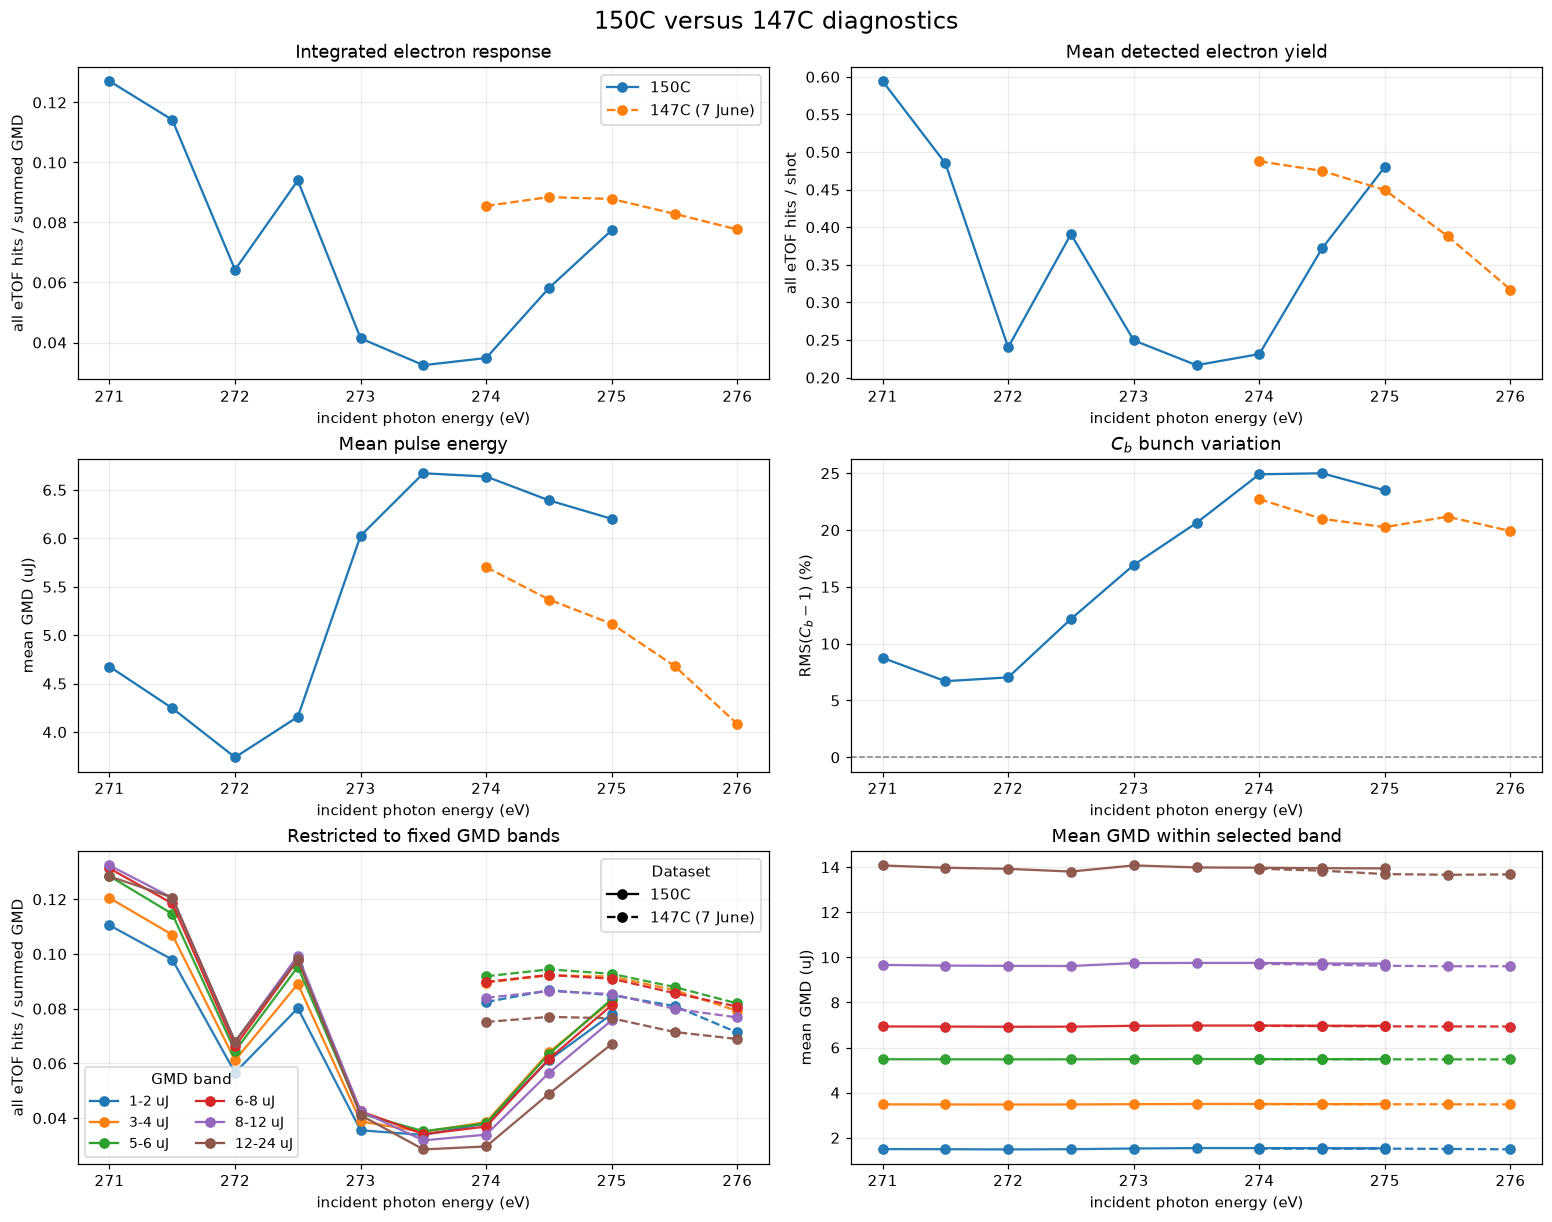

In [15]:
for name in FAMILY_ORDER:
    diag = family_diags[name]
    print(f"\n{name}\nenergy    {count_label} / summed GMD    {count_label} / shot    mean GMD    Cb RMS (%)")
    for e, a, b, c, d in zip(diag["energy"], diag["e_per_gmd"], diag["e_per_shot"], diag["mean_gmd"], diag["cb_rms"]):
        print(f"{e:5.1f}    {a:12.6f}                {b:10.6f}    {c:8.4f}    {d:8.3f}")

fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=False, constrained_layout=True)
for name in FAMILY_ORDER:
    diag, c, ls = family_diags[name], FAMILY_COLOURS[name], FAMILY_LINESTYLES[name]
    axes[0, 0].plot(diag["energy"], diag["e_per_gmd"], "o-", color=c, ls=ls, label=name)
    axes[0, 1].plot(diag["energy"], diag["e_per_shot"], "o-", color=c, ls=ls, label=name)
    axes[1, 0].plot(diag["energy"], diag["mean_gmd"], "o-", color=c, ls=ls, label=name)
    axes[1, 1].plot(diag["energy"], diag["cb_rms"], "o-", color=c, ls=ls, label=name)

axes[0, 0].set(ylabel=f"{count_label} / summed GMD", title="Integrated electron response")
axes[0, 1].set(ylabel=f"{count_label} / shot", title="Mean detected electron yield")
axes[1, 0].set(ylabel="mean GMD (uJ)", title="Mean pulse energy")
axes[1, 1].set(ylabel=r"RMS($C_b-1$) (%)", title=r"$C_b$ bunch variation")
axes[1, 1].axhline(0.0, ls="--", lw=1, color="0.5")

for name in FAMILY_ORDER:
    diag, ls = family_diags[name], FAMILY_LINESTYLES[name]
    for l, c in BAND_COLOURS.items():
        axes[2, 0].plot(diag["energy"], diag["bands"][l]["e_per_gmd"], "o-", color=c, ls=ls, alpha=0.95)
        axes[2, 1].plot(diag["energy"], diag["bands"][l]["mean_gmd"], "o-", color=c, ls=ls, alpha=0.95)

axes[2, 0].set(ylabel=f"{count_label} / summed GMD", title="Restricted to fixed GMD bands")
axes[2, 1].set(ylabel="mean GMD (uJ)", title="Mean GMD within selected band")

for ax in axes.flat:
    ax.set(xlabel="incident photon energy (eV)")
    ax.grid(alpha=0.25)

fam_handles = [Line2D([0], [0], color="black", ls=FAMILY_LINESTYLES[n], marker="o", label=n) for n in FAMILY_ORDER]
band_handles = [Line2D([0], [0], color=BAND_COLOURS[l], ls="-", marker="o", label=f"{l} uJ") for l in COMPARE_GMD_BANDS]

leg1 = axes[2, 0].legend(handles=fam_handles, title="Dataset", loc="upper right")
axes[2, 0].add_artist(leg1)
axes[2, 0].legend(handles=band_handles, title="GMD band", loc="lower left", ncol=2, fontsize=9)
axes[0, 0].legend(loc="best")
fig.suptitle("150C versus 147C diagnostics", fontsize=16)
plt.show()

## 160 C dataset

In [16]:

# --- 160 C wavelength scan: load and combine repeated energies ---------

import re
from collections import defaultdict

WL160_ENERGY_GRID = np.arange(270.0, 283.0 + 0.25, 0.5)
WL160_FLOAT_INDEX_ONLY = True  # Exclude names like 279eV; retain 279.0eV
COMPARE_GMD_BANDS = {"1-2": (1.0, 2.0), "3-4": (3.0, 4.0), "5-6": (5.0, 6.0), "6-8": (6.0, 8.0), "8-12": (8.0, 12.0), "12-24": (12.0, 24.0)}
USE_ALL_ELECTRONS, ELECTRON_KE_RANGE = True, (180.0, 280.0)

wl160_paths = sorted(
    AGG_DIR.glob("glycine_WL_scan_*eV_aggregates_etof1.h5"),
    key=lambda p: (photon_energy_from_name(p), p.name)
)

if WL160_FLOAT_INDEX_ONLY:
    wl160_paths = [
        p for p in wl160_paths
        if re.fullmatch(r"glycine_WL_scan_\d+\.\d+eV_aggregates_etof1\.h5", p.name)
    ]

wl160_paths = [
    p for p in wl160_paths
    if WL160_ENERGY_GRID[0] <= photon_energy_from_name(p) <= WL160_ENERGY_GRID[-1]
]

if not wl160_paths:
    raise FileNotFoundError(f"No WL scan aggregate files found in {AGG_DIR}")


wl160_datasets = []
wl160_seen_sources = {}

for agg_path in wl160_paths:
    energy = photon_energy_from_name(agg_path)
    info = load_aggregate_info(agg_path)
    metadata = info["metadata"]
    input_h5 = str(metadata.get("input_h5", "") or "")

    candidates = []
    if input_h5:
        candidates.extend([Path(input_h5), AGG_DIR / Path(input_h5).name])
    candidates.append(AGG_DIR / agg_path.name.replace("_aggregates_etof1.h5", ".h5"))

    source_h5 = next((p for p in candidates if p.is_file()), None)
    if source_h5 is None:
        raise FileNotFoundError(f"Cannot find source H5 for {agg_path.name}: {input_h5}")

    trim_start = int(metadata.get("trim_start", 0) or 0)
    trim_end = int(metadata.get("trim_end", 0) or 0)
    source_key = source_h5.resolve()

    if source_key in wl160_seen_sources:
        previous = wl160_seen_sources[source_key]
        if (trim_start, trim_end) != previous["trim"]:
            raise ValueError(f"Same raw file has conflicting trim settings: {source_h5.name}")
        print(f"Skipping repeated reference to raw file: {agg_path.name}")
        continue

    wl160_seen_sources[source_key] = {"trim": (trim_start, trim_end), "energy": energy}
    wl160_datasets.append({
        "photon_energy_ev": energy,
        "agg_path": agg_path,
        "source_h5": source_h5,
        "trim_start": trim_start,
        "trim_end": trim_end,
    })

wl160_groups = defaultdict(list)
for ds in wl160_datasets:
    wl160_groups[ds["photon_energy_ev"]].append(ds)

print(f"\n160 C: {len(wl160_datasets)} independent files, {len(wl160_groups)} photon energies")
# for energy, group in sorted(wl160_groups.items()):
#     print(f"\n{energy:g} eV ({len(group)} file(s))")
#     for ds in group:
#         print(" ", ds["source_h5"].name)

# --- Process each independent file -------------------------------------

wl160_run_results = []
wl160_run_metrics = []

for ds in wl160_datasets:
    print(f"Processing {ds['photon_energy_ev']:g} eV: {ds['source_h5'].name}")
    wl160_run_results.append(production_cb_and_spectrum_2d(ds))
    wl160_run_metrics.append(_stream_dataset_metrics(ds, PROD2D_CHUNK_TRAINS, COMPARE_GMD_BANDS))

# --- Combine runs at the same photon energy ----------------------------

wl160_by_energy = defaultdict(list)
for ds, result, metrics in zip(wl160_datasets, wl160_run_results, wl160_run_metrics):
    wl160_by_energy[ds["photon_energy_ev"]].append((result, metrics))

wl160_results = []
wl160_diag = {"energy": [], "e_per_gmd": [], "e_per_shot": [], "mean_gmd": [], "cb_rms": []}
wl160_diag["bands"] = {l: {"e_per_gmd": [], "mean_gmd": []} for l in COMPARE_GMD_BANDS}

def wl160_ratio(a, b):
    return a / b if b > 0 else np.nan

for energy, entries in sorted(wl160_by_energy.items()):
    results = [r for r, m in entries]
    metrics = [m for r, m in entries]

    sum_gmd = sum(r["sum_gmd"] for r in results)
    sum_gmd_eff = sum(r["sum_gmd_eff"] for r in results)
    if sum_gmd <= 0 or sum_gmd_eff <= 0:
        raise ValueError(f"No valid normalisation exposure at {energy:g} eV")

    # Exposure-weighted combination = summed counts / summed exposure.
    spectrum_gmd = sum(r["spectrum_gmd"] * r["sum_gmd"] for r in results) / sum_gmd
    spectrum_cb = sum(r["spectrum_cb"] * r["sum_gmd_eff"] for r in results) / sum_gmd_eff

    wl160_results.append({
        "photon_energy_ev": energy,
        "spectrum_gmd": spectrum_gmd,
        "spectrum_cb": spectrum_cb,
        "sum_gmd": sum_gmd,
        "sum_gmd_eff": sum_gmd_eff,
        "correction_scale": sum_gmd / sum_gmd_eff,
    })

    shots = sum(m["shots"] for m in metrics)
    total_gmd = sum(m["sum_gmd"] for m in metrics)
    electrons = sum(m["electrons"] for m in metrics)

    # RMS across the individual run corrections, weighted by GMD exposure.
    cb_rms = 100 * np.sqrt(sum(
        r["sum_gmd"] * np.mean((r["cb"] - 1.0)**2) for r in results
    ) / sum_gmd)

    wl160_diag["energy"].append(energy)
    wl160_diag["e_per_gmd"].append(wl160_ratio(electrons, total_gmd))
    wl160_diag["e_per_shot"].append(wl160_ratio(electrons, shots))
    wl160_diag["mean_gmd"].append(wl160_ratio(total_gmd, shots))
    wl160_diag["cb_rms"].append(cb_rms)

    for label in COMPARE_GMD_BANDS:
        b_shots = sum(m["bands"][label]["shots"] for m in metrics)
        b_gmd = sum(m["bands"][label]["sum_gmd"] for m in metrics)
        b_elec = sum(m["bands"][label]["electrons"] for m in metrics)
        wl160_diag["bands"][label]["e_per_gmd"].append(wl160_ratio(b_elec, b_gmd))
        wl160_diag["bands"][label]["mean_gmd"].append(wl160_ratio(b_gmd, b_shots))

for key in ("energy", "e_per_gmd", "e_per_shot", "mean_gmd", "cb_rms"):
    wl160_diag[key] = np.asarray(wl160_diag[key])
for label in COMPARE_GMD_BANDS:
    for key in ("e_per_gmd", "mean_gmd"):
        wl160_diag["bands"][label][key] = np.asarray(wl160_diag["bands"][label][key])

family_diags["160C"] = wl160_diag
FAMILY_ORDER = ["150C", "147C (7 June)", "160C"]
FAMILY_COLOURS["160C"] = "tab:green"
FAMILY_LINESTYLES["160C"] = ":"

print("\n160 C data processing complete.")



160 C: 27 independent files, 27 photon energies
Processing 270 eV: glycine_WL_scan_270.0eV.h5
Processing 270.5 eV: glycine_WL_scan_270.5eV.h5
Processing 271 eV: glycine_WL_scan_271.0eV.h5
Processing 271.5 eV: glycine_WL_scan_271.5eV.h5
Processing 272 eV: glycine_WL_scan_272.0eV.h5
Processing 272.5 eV: glycine_WL_scan_272.5eV.h5
Processing 273 eV: glycine_WL_scan_273.0eV.h5
Processing 273.5 eV: glycine_WL_scan_273.5eV.h5
Processing 274 eV: glycine_WL_scan_274.0eV.h5
Processing 274.5 eV: glycine_WL_scan_274.5eV.h5
Processing 275 eV: glycine_WL_scan_275.0eV.h5
Processing 275.5 eV: glycine_WL_scan_275.5eV.h5
Processing 276 eV: glycine_WL_scan_276.0eV.h5
Processing 276.5 eV: glycine_WL_scan_276.5eV.h5
Processing 277 eV: glycine_WL_scan_277.0eV.h5
Processing 277.5 eV: glycine_WL_scan_277.5eV.h5
Processing 278 eV: glycine_WL_scan_278.0eV.h5
Processing 278.5 eV: glycine_WL_scan_278.5eV.h5
Processing 279 eV: glycine_WL_scan_279.0eV.h5
Processing 279.5 eV: glycine_WL_scan_279.5eV.h5
Processing 

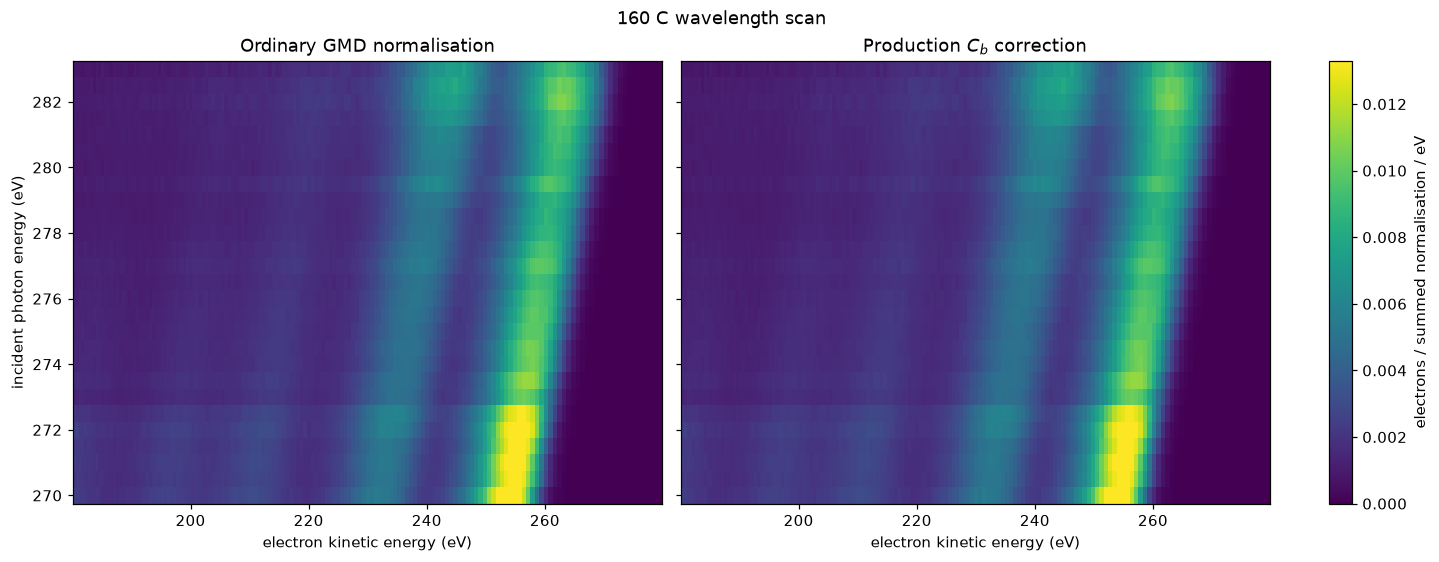

In [17]:

# --- 160 C: incident-energy vs electron-KE maps -------------------------

wl160_energy = np.array([r["photon_energy_ev"] for r in wl160_results])
wl160_map_gmd = np.full((len(WL160_ENERGY_GRID), len(ke_plot_prod2d)), np.nan)
wl160_map_cb = np.full_like(wl160_map_gmd, np.nan)

for result in wl160_results:
    energy = result["photon_energy_ev"]
    index = int(np.argmin(np.abs(WL160_ENERGY_GRID - energy)))
    if not np.isclose(WL160_ENERGY_GRID[index], energy, atol=1e-6):
        raise ValueError(f"Unexpected photon energy: {energy:g} eV")
    wl160_map_gmd[index] = result["spectrum_gmd"]
    wl160_map_cb[index] = result["spectrum_cb"]

all_values = np.concatenate([
    wl160_map_gmd[np.isfinite(wl160_map_gmd)],
    wl160_map_cb[np.isfinite(wl160_map_cb)]
])
vmin, vmax = np.nanpercentile(all_values, [1, 99.5])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True, constrained_layout=True)

for ax, values, title in zip(
    axes,
    [wl160_map_gmd, wl160_map_cb],
    ["Ordinary GMD normalisation", r"Production $C_b$ correction"],
):
    im = ax.pcolormesh(
        ke_edges_plot_prod2d,
        centres_to_edges(WL160_ENERGY_GRID),
        np.ma.masked_invalid(values),
        shading="flat",
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_xlabel("electron kinetic energy (eV)")
    ax.set_title(title)

axes[0].set_ylabel("incident photon energy (eV)")
fig.colorbar(im, ax=axes, label="electrons / summed normalisation / eV")
fig.suptitle("160 C wavelength scan")
plt.show()



150C
energy    all eTOF hits / summed GMD    all eTOF hits / shot    mean GMD    Cb RMS (%)
271.0        0.127090                  0.594259      4.6759       8.755
271.5        0.114214                  0.484962      4.2461       6.698
272.0        0.064238                  0.240187      3.7390       7.033
272.5        0.093999                  0.390740      4.1568      12.172
273.0        0.041397                  0.249500      6.0270      16.921
273.5        0.032446                  0.216483      6.6722      20.631
274.0        0.034833                  0.231241      6.6386      24.906
274.5        0.058158                  0.371788      6.3927      24.994
275.0        0.077437                  0.480234      6.2016      23.492

147C (7 June)
energy    all eTOF hits / summed GMD    all eTOF hits / shot    mean GMD    Cb RMS (%)
274.0        0.085515                  0.487688      5.7029      22.717
274.5        0.088466                  0.474903      5.3682      20.985
275.0        

/tmp/ipykernel_3865332/3214735646.py:36: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 0].plot(diag["energy"], e_per_gmd, "o-", color=c, ls=ls, label=label)
/tmp/ipykernel_3865332/3214735646.py:37: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 1].plot(diag["energy"], e_per_shot, "o-", color=c, ls=ls, label=label)
/tmp/ipykernel_3865332/3214735646.py:38: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[1, 0].plot(diag["energy"], diag["mean_gmd"], "o-", color=c, ls=ls, label=name)
/tmp/ipykernel_3865332/3214735646.py:39: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument 

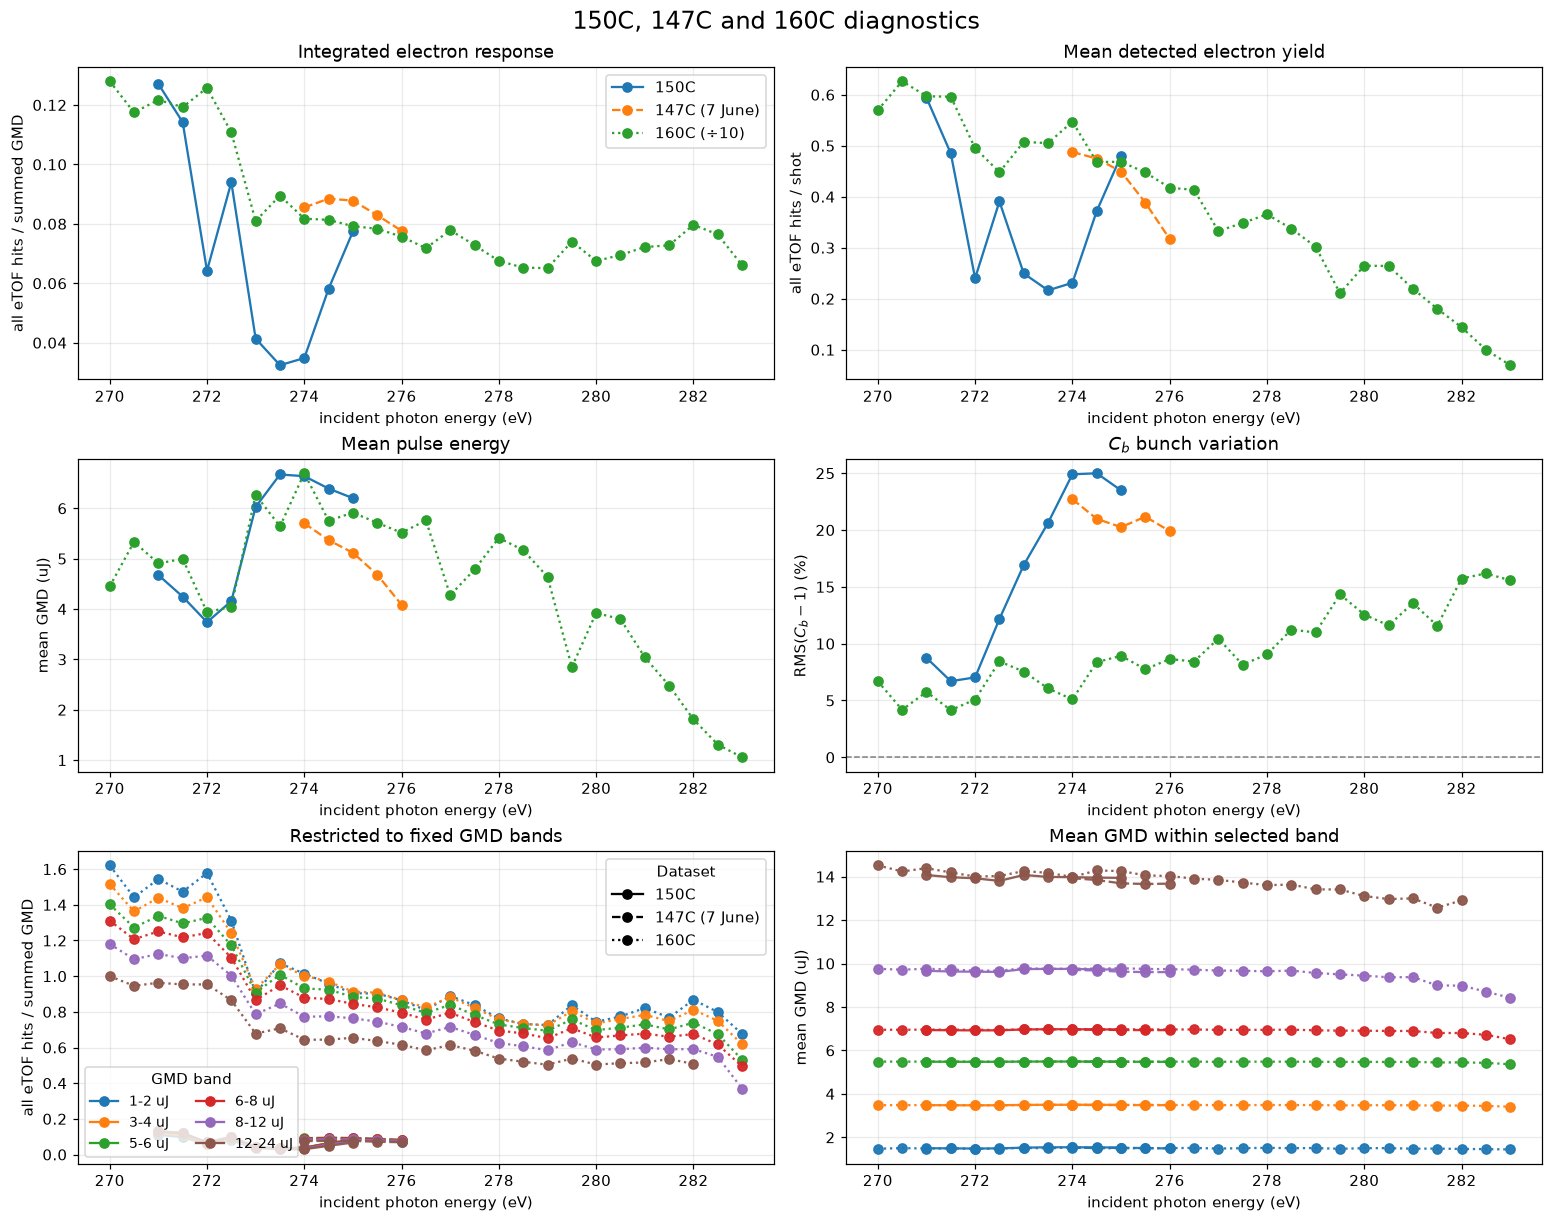

In [18]:

# --- 150 C, 147 C and 160 C diagnostics ---------------------------------

NORMALISE_TOP_ROW = True
NORMALISATION_RANGE_EV = (274.0, 275.5)

def normalise_to_reference(energy, values, reference_range):
    energy, values = np.asarray(energy, dtype=float), np.asarray(values, dtype=float)
    mask = (energy >= reference_range[0]) & (energy <= reference_range[1]) & np.isfinite(values)
    if not np.any(mask):
        raise ValueError(f"No valid points in reference range {reference_range}")
    reference = np.mean(values[mask])
    if not np.isfinite(reference) or reference <= 0:
        raise ValueError(f"Invalid normalisation reference: {reference}")
    return values / reference

for name in FAMILY_ORDER:
    diag = family_diags[name]
    print(f"\n{name}\nenergy    {count_label} / summed GMD    {count_label} / shot    mean GMD    Cb RMS (%)")
    for e, a, b, c, d in zip(diag["energy"], diag["e_per_gmd"], diag["e_per_shot"], diag["mean_gmd"], diag["cb_rms"]):
        print(f"{e:5.1f}    {a:12.6f}                {b:10.6f}    {c:8.4f}    {d:8.3f}")

fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=False, constrained_layout=True)

for name in FAMILY_ORDER:
    diag, c, ls = family_diags[name], FAMILY_COLOURS[name], FAMILY_LINESTYLES[name]

    e_per_gmd = diag["e_per_gmd"].copy()
    e_per_shot = diag["e_per_shot"].copy()

    if name == "160C":
        e_per_gmd = e_per_gmd / 10.0
        e_per_shot = e_per_shot / 10.0

    label = "160C (÷10)" if name == "160C" else name

    axes[0, 0].plot(diag["energy"], e_per_gmd, "o-", color=c, ls=ls, label=label)
    axes[0, 1].plot(diag["energy"], e_per_shot, "o-", color=c, ls=ls, label=label)
    axes[1, 0].plot(diag["energy"], diag["mean_gmd"], "o-", color=c, ls=ls, label=name)
    axes[1, 1].plot(diag["energy"], diag["cb_rms"], "o-", color=c, ls=ls, label=name)

if NORMALISE_TOP_ROW:
    axes[0, 0].set_ylabel("all eTOF hits / summed GMD")
    axes[0, 1].set_ylabel("all eTOF hits / shot")
else:
    axes[0, 0].set_ylabel(f"{count_label} / summed GMD")
    axes[0, 1].set_ylabel(f"{count_label} / shot")

axes[0, 0].set_title("Integrated electron response")
axes[0, 1].set_title("Mean detected electron yield")
axes[1, 0].set(ylabel="mean GMD (uJ)", title="Mean pulse energy")
axes[1, 1].set(ylabel=r"RMS($C_b-1$) (%)", title=r"$C_b$ bunch variation")
axes[1, 1].axhline(0.0, ls="--", lw=1, color="0.5")

for name in FAMILY_ORDER:
    diag, ls = family_diags[name], FAMILY_LINESTYLES[name]
    for l, c in BAND_COLOURS.items():
        axes[2, 0].plot(diag["energy"], diag["bands"][l]["e_per_gmd"], "o-", color=c, ls=ls, alpha=0.95)
        axes[2, 1].plot(diag["energy"], diag["bands"][l]["mean_gmd"], "o-", color=c, ls=ls, alpha=0.95)

axes[2, 0].set(ylabel=f"{count_label} / summed GMD", title="Restricted to fixed GMD bands")
axes[2, 1].set(ylabel="mean GMD (uJ)", title="Mean GMD within selected band")

for ax in axes.flat:
    ax.set(xlabel="incident photon energy (eV)")
    ax.grid(alpha=0.25)

fam_handles = [Line2D([0], [0], color="black", ls=FAMILY_LINESTYLES[n], marker="o", label=n) for n in FAMILY_ORDER]
band_handles = [Line2D([0], [0], color=BAND_COLOURS[l], ls="-", marker="o", label=f"{l} uJ") for l in COMPARE_GMD_BANDS]

leg1 = axes[2, 0].legend(handles=fam_handles, title="Dataset", loc="upper right")
axes[2, 0].add_artist(leg1)
axes[2, 0].legend(handles=band_handles, title="GMD band", loc="lower left", ncol=2, fontsize=9)
axes[0, 0].legend(loc="best")

fig.suptitle("150C, 147C and 160C diagnostics", fontsize=16)
plt.show()


## Beam pointing

In [25]:

# --- Inspect beam-pointing data in an original combined HDF5 file -------

POINTING_FAMILY = "160C"  # "150C", "147C", "160C"
POINTING_ENERGY_EV = 273.0
POINTING_RUN_INDEX = 0  # If multiple runs exist at this energy

pointing_families = {
    "150C": prod2d_datasets,
    "147C": j7_datasets,
    "160C": wl160_datasets,
}

pointing_matches = [
    ds for ds in pointing_families[POINTING_FAMILY]
    if np.isclose(ds["photon_energy_ev"], POINTING_ENERGY_EV)
]

if not pointing_matches:
    raise ValueError(f"No {POINTING_FAMILY} dataset at {POINTING_ENERGY_EV:g} eV")
if POINTING_RUN_INDEX >= len(pointing_matches):
    raise IndexError(f"Only {len(pointing_matches)} matching runs available")

pointing_ds = pointing_matches[POINTING_RUN_INDEX]
pointing_path = Path(pointing_ds["source_h5"])

print("Selected:", POINTING_FAMILY, POINTING_ENERGY_EV, "eV")
print("File:", pointing_path)
print("Number of matching runs:", len(pointing_matches))

with h5py.File(pointing_path, "r") as handle:
    print("\n--- Top-level HDF5 keys ---")
    for key in handle.keys():
        obj = handle[key]
        if isinstance(obj, h5py.Dataset):
            print(f"{key:30s} shape={str(obj.shape):22s} dtype={obj.dtype}")
        else:
            print(f"{key:30s} GROUP")

    gmd_shape = handle["gmd"].shape
    n_trains, n_bunches = gmd_shape
    print(f"\nGMD shape: {gmd_shape}")
    print(f"Number of trains: {n_trains}")
    print(f"Number of bunches per train: {n_bunches}")

    # Search all levels of the HDF5 file, without loading datasets.
    search_terms = ("hor", "ver", "pos", "point", "bpm", "tid", "train")
    pointing_keys = []

    def inspect_key(name, obj):
        if isinstance(obj, h5py.Dataset) and any(term in name.lower() for term in search_terms):
            pointing_keys.append(name)

    handle.visititems(inspect_key)

    print("\n--- Position and timing datasets ---")

    if not pointing_keys:
        print("No matching keys found.")

    for key in pointing_keys:
        data = handle[key]
        print(f"\n{key}")
        print("  Shape:", data.shape)
        print("  Dtype:", data.dtype)

        if data.shape == (n_trains, n_bunches):
            print("  Layout: one value per train AND bunch")
        elif data.shape == (n_trains,):
            print("  Layout: one value per train")
        elif data.shape == (n_trains, 1):
            print("  Layout: one value per train (singleton second axis)")
        else:
            print("  Layout: not directly identified from GMD dimensions")

        if data.attrs:
            print("  Attributes:")
            for attr in data.attrs:
                print(f"    {attr}: {str(data.attrs[attr])[:150]}")

        if data.ndim > 0 and data.shape[0] > 0:
            sample_slice = tuple(
                slice(0, min(size, 3 if axis == 0 else 5))
                for axis, size in enumerate(data.shape)
            )
            sample = data[sample_slice]
            print("  First values:")
            print(" ", np.array2string(np.asarray(sample), threshold=20))
        elif data.ndim == 0:
            print("  Scalar dataset; value not loaded")

    print("\n--- Timing and selection keys ---")
    for key in ("tID", "trainId", "train_id", "between_tdc_files", "gmd"):
        if key in handle and isinstance(handle[key], h5py.Dataset):
            print(f"{key:22s} shape={handle[key].shape}, dtype={handle[key].dtype}")

print("\nInspection complete. No HDF5 data modified.")


Selected: 160C 273.0 eV
File: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_WL_scan_273.0eV.h5
Number of matching runs: 1

--- Top-level HDF5 keys ---
between_tdc_files              shape=(3004,)                dtype=bool
gmd                            shape=(3004, 101)            dtype=float32
hor_pos                        shape=(3004,)                dtype=float32
local_DAQ_running              shape=(3004,)                dtype=bool
mpe                            shape=(3004,)                dtype=float32
tID                            shape=(3004,)                dtype=float64
tofs_e                         shape=(3004, 101, 50)        dtype=uint32
tofs_i                         shape=(3004, 101, 120)       dtype=uint32
ver_pos                        shape=(3004,)                dtype=float32
z                              shape=(3004, 101)            dtype=float32
z_std                          shape=(3004, 101)            dtype=float32

GMD shape: (3004, 1

/tmp/ipykernel_3137283/3562377999.py:80: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[2].plot(diag["energy"], diag["e_per_shot"] / scale,
/tmp/ipykernel_3137283/3562377999.py:82: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[3].plot(diag["energy"], diag["e_per_gmd"] / scale,


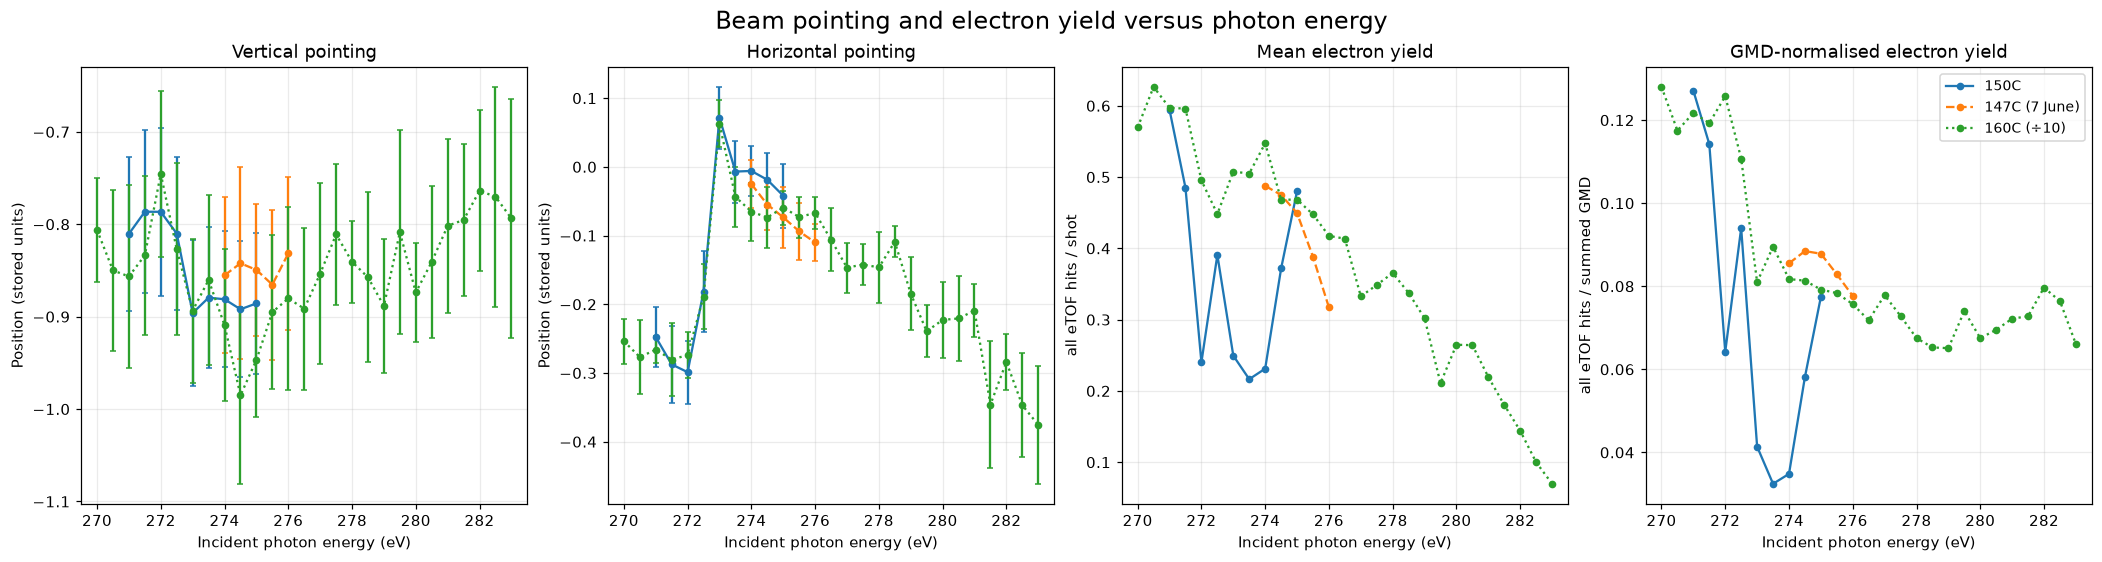

In [26]:

# --- Beam pointing and electron yield versus photon energy --------------

from collections import defaultdict
import numpy as np
import h5py
import matplotlib.pyplot as plt

POINTING_REQUIRE_VALID_GMD = True
POINTING_CHUNK_TRAINS = 1000
POINTING_160C_SCALE = 10.0  # Display scaling for yield panels only

pointing_families = {
    "150C": prod2d_datasets,
    "147C (7 June)": j7_datasets,
    "160C": wl160_datasets,
}

pointing_by_family = {}

for name in FAMILY_ORDER:
    grouped = defaultdict(lambda: {"hor": [], "ver": []})

    for ds in pointing_families[name]:
        with h5py.File(ds["source_h5"], "r") as f:
            n_trains = f["gmd"].shape[0]
            keep = keep_mask_like_compute_aggregates_from_h5(
                f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
            )
            hor = np.asarray(f["hor_pos"][:], dtype=float)
            ver = np.asarray(f["ver_pos"][:], dtype=float)

            if hor.shape != (n_trains,) or ver.shape != (n_trains,):
                raise ValueError(f"Unexpected pointing shape in {ds['source_h5']}")

            if POINTING_REQUIRE_VALID_GMD:
                valid_gmd = np.zeros(n_trains, dtype=bool)
                for start in range(0, n_trains, POINTING_CHUNK_TRAINS):
                    stop = min(start + POINTING_CHUNK_TRAINS, n_trains)
                    valid_gmd[start:stop] = np.any(np.isfinite(f["gmd"][start:stop]), axis=1)
                keep &= valid_gmd

            energy = float(ds["photon_energy_ev"])
            grouped[energy]["hor"].append(hor[keep & np.isfinite(hor)])
            grouped[energy]["ver"].append(ver[keep & np.isfinite(ver)])

    rows = []
    for energy, data in sorted(grouped.items()):
        row = {"energy": energy}
        for key in ("hor", "ver"):
            values = np.concatenate(data[key])
            row[f"{key}_mean"] = np.mean(values) if values.size else np.nan
            row[f"{key}_std"] = np.std(values) if values.size else np.nan
            row[f"{key}_n"] = len(values)
        rows.append(row)

    pointing_by_family[name] = {
        key: np.array([row[key] for row in rows])
        for key in ("energy", "hor_mean", "hor_std", "hor_n", "ver_mean", "ver_std", "ver_n")
    }

# --- Four-panel comparison ----------------------------------------------

fig, axes = plt.subplots(1, 4, figsize=(19, 5), sharex=True, constrained_layout=True)

for name in FAMILY_ORDER:
    p = pointing_by_family[name]
    diag = family_diags[name]
    c, ls = FAMILY_COLOURS[name], FAMILY_LINESTYLES[name]

    # Pointing: mean ± within-run standard deviation.
    axes[0].errorbar(p["energy"], p["ver_mean"], yerr=p["ver_std"],
                     fmt="o", ls=ls, color=c, lw=1.5, markersize=4, capsize=2)
    axes[1].errorbar(p["energy"], p["hor_mean"], yerr=p["hor_std"],
                     fmt="o", ls=ls, color=c, lw=1.5, markersize=4, capsize=2)

    # Electron yields: same quantities as the original six-panel figure.
    scale = POINTING_160C_SCALE if name == "160C" else 1.0
    label = f"160C (÷{scale:g})" if name == "160C" else name

    axes[2].plot(diag["energy"], diag["e_per_shot"] / scale,
                 "o-", color=c, ls=ls, lw=1.5, markersize=4, label=label)
    axes[3].plot(diag["energy"], diag["e_per_gmd"] / scale,
                 "o-", color=c, ls=ls, lw=1.5, markersize=4, label=label)

axes[0].set(title="Vertical pointing", ylabel="Position (stored units)")
axes[1].set(title="Horizontal pointing", ylabel="Position (stored units)")
axes[2].set(title="Mean electron yield", ylabel=f"{count_label} / shot")
axes[3].set(title="GMD-normalised electron yield", ylabel=f"{count_label} / summed GMD")

for ax in axes:
    ax.set_xlabel("Incident photon energy (eV)")
    ax.set_xlim(269.5, 283.5)
    ax.set_xticks(np.arange(270, 284, 2))
    ax.grid(alpha=0.25)

axes[3].legend(loc="best", fontsize=9)
fig.suptitle("Beam pointing and electron yield versus photon energy", fontsize=16)
plt.show()



150C, 272.5 eV: glycine_delay_scan_150C_272.5eV.h5
  Selected trains: 32791, valid pointing: 3424
  Trains with selected GMD: 3424
  Selected shots: 41,206
  Electron yield / GMD: 0.090440

150C, 273 eV: glycine_delay_scan_150C_273.0eV.h5
  Selected trains: 32704, valid pointing: 3339
  Trains with selected GMD: 3330
  Selected shots: 36,743
  Electron yield / GMD: 0.039659

272.5 eV, hor:
  Position -0.2837: yield 0.083692 ± 0.002205 (571 trains)
  Position -0.2171: yield 0.084975 ± 0.002220 (570 trains)
  Position -0.1838: yield 0.087108 ± 0.002217 (571 trains)
  Position -0.1595: yield 0.097962 ± 0.002529 (570 trains)
  Position -0.1366: yield 0.093281 ± 0.002468 (571 trains)
  Position -0.1077: yield 0.098048 ± 0.002631 (571 trains)

272.5 eV, ver:
  Position -0.9239: yield 0.088532 ± 0.002304 (571 trains)
  Position -0.8733: yield 0.088578 ± 0.002320 (570 trains)
  Position -0.8332: yield 0.086716 ± 0.002302 (571 trains)
  Position -0.7941: yield 0.091097 ± 0.002332 (570 trains)


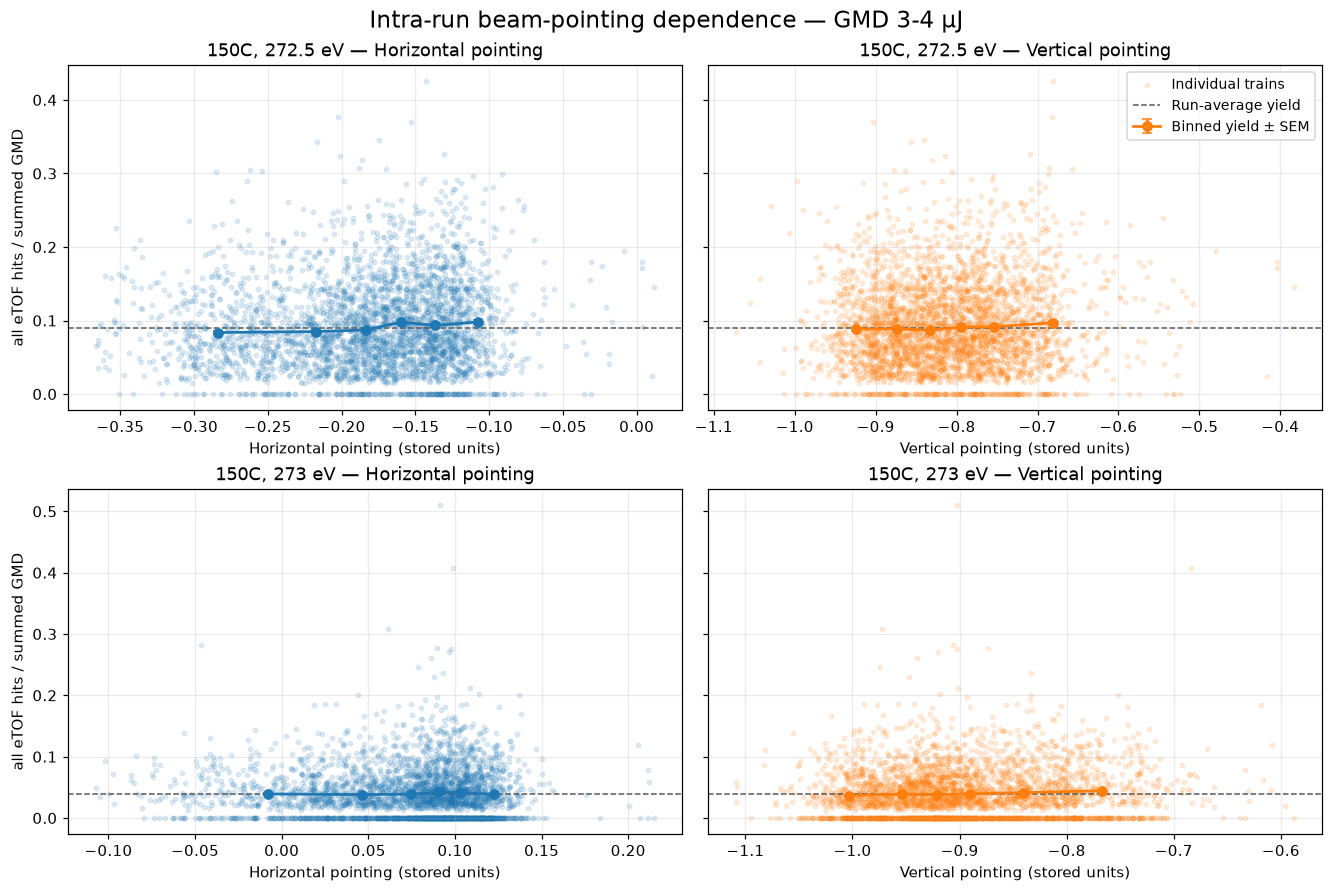

In [27]:

# --- Intra-run pointing dependence of GMD-normalised electron yield -----

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

INTRA_FAMILY = "150C"  # "150C", "147C (7 June)", "160C"
INTRA_ENERGIES_EV = [272.5, 273.0]
INTRA_RUN_INDEX = 0
INTRA_GMD_RANGE = (3.0, 4.0)  # Set to None for all positive GMD values
INTRA_N_BINS = 6
INTRA_CHUNK_TRAINS = 200

intra_families = {
    "150C": prod2d_datasets,
    "147C (7 June)": j7_datasets,
    "160C": wl160_datasets,
}

def load_intra_run_pointing(ds):
    """Collect per-train electron counts and GMD for trains with valid pointing."""
    parts = {"hor": [], "ver": [], "electrons": [], "sum_gmd": [], "shots": [], "train": []}

    with h5py.File(ds["source_h5"], "r") as f:
        keep = keep_mask_like_compute_aggregates_from_h5(
            f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        n_trains, n_bunches = f["gmd"].shape
        if f["tofs_e"].shape[:2] != (n_trains, n_bunches):
            raise ValueError("eTOF and GMD dimensions do not match.")

        hor = np.asarray(f["hor_pos"][:], dtype=float)
        ver = np.asarray(f["ver_pos"][:], dtype=float)

        if hor.shape != (n_trains,) or ver.shape != (n_trains,):
            raise ValueError("Unexpected pointing dimensions.")

        pointing_valid = keep & np.isfinite(hor) & np.isfinite(ver)
        print(f"  Selected trains: {np.count_nonzero(keep)}, valid pointing: {np.count_nonzero(pointing_valid)}")

        for start in range(0, n_trains, INTRA_CHUNK_TRAINS):
            stop = min(start + INTRA_CHUNK_TRAINS, n_trains)
            local = np.flatnonzero(pointing_valid[start:stop])
            if not local.size:
                continue

            gmd = f["gmd"][start:stop][local].astype(float)
            tofs = f["tofs_e"][start:stop][local]

            valid = np.isfinite(gmd) & (gmd > 0)
            if INTRA_GMD_RANGE is not None:
                valid &= (gmd >= INTRA_GMD_RANGE[0]) & (gmd < INTRA_GMD_RANGE[1])

            if USE_ALL_ELECTRONS:
                counts = np.count_nonzero(tofs > 0, axis=2)
            else:
                counts = electron_counts_from_tof(tofs, ke_range=ELECTRON_KE_RANGE)

            shots = np.sum(valid, axis=1)
            sum_gmd = np.sum(np.where(valid, gmd, 0.0), axis=1)
            electrons = np.sum(np.where(valid, counts, 0), axis=1)

            good = (shots > 0) & (sum_gmd > 0)
            if not np.any(good):
                continue

            parts["hor"].append(hor[start:stop][local][good])
            parts["ver"].append(ver[start:stop][local][good])
            parts["electrons"].append(electrons[good].astype(float))
            parts["sum_gmd"].append(sum_gmd[good])
            parts["shots"].append(shots[good])
            parts["train"].append((start + local)[good])

    if not parts["hor"]:
        raise ValueError(f"No valid pointing/GMD data for {ds['source_h5']}")

    return {key: np.concatenate(values) for key, values in parts.items()}


def pointing_binned_response(position, electrons, gmd, n_bins):
    """Quantile-bin pointing; calculate summed electrons / summed GMD."""
    edges = np.unique(np.quantile(position, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 3:
        raise ValueError("Too few distinct pointing values to form bins.")

    bin_index = np.digitize(position, edges[1:-1])
    centres, yields, errors, counts = [], [], [], []

    for i in range(len(edges) - 1):
        selected = bin_index == i
        n = np.count_nonzero(selected)
        if n < 3:
            continue

        e, g = electrons[selected], gmd[selected]
        response = np.sum(e) / np.sum(g)

        # Approximate standard error, treating trains as independent units.
        residual = e - response * g
        sem = np.sqrt(n / (n - 1) * np.sum(residual**2)) / np.sum(g)

        centres.append(np.mean(position[selected]))
        yields.append(response)
        errors.append(sem)
        counts.append(n)

    return np.array(centres), np.array(yields), np.array(errors), np.array(counts)


# --- Load selected runs --------------------------------------------------

intra_results = {}

for energy in INTRA_ENERGIES_EV:
    matches = [
        ds for ds in intra_families[INTRA_FAMILY]
        if np.isclose(ds["photon_energy_ev"], energy)
    ]
    if not matches:
        raise ValueError(f"No {INTRA_FAMILY} run at {energy:g} eV")
    if INTRA_RUN_INDEX >= len(matches):
        raise IndexError(f"Only {len(matches)} matching runs at {energy:g} eV")

    ds = matches[INTRA_RUN_INDEX]
    print(f"\n{INTRA_FAMILY}, {energy:g} eV: {Path(ds['source_h5']).name}")
    intra_results[energy] = load_intra_run_pointing(ds)

    r = intra_results[energy]
    print(f"  Trains with selected GMD: {len(r['hor'])}")
    print(f"  Selected shots: {int(np.sum(r['shots'])):,}")
    print(f"  Electron yield / GMD: {np.sum(r['electrons']) / np.sum(r['sum_gmd']):.6f}")


# --- Plot horizontal and vertical dependence for each energy ------------

fig, axes = plt.subplots(
    len(INTRA_ENERGIES_EV), 2,
    figsize=(12, 4 * len(INTRA_ENERGIES_EV)),
    sharey="row", squeeze=False, constrained_layout=True
)

for row, energy in enumerate(INTRA_ENERGIES_EV):
    result = intra_results[energy]
    electrons, gmd = result["electrons"], result["sum_gmd"]
    train_yield = electrons / gmd
    overall_yield = np.sum(electrons) / np.sum(gmd)

    for col, (key, title, color) in enumerate([
        ("hor", "Horizontal pointing", "tab:blue"),
        ("ver", "Vertical pointing", "tab:orange"),
    ]):
        ax = axes[row, col]
        position = result[key]

        centres, response, errors, n = pointing_binned_response(
            position, electrons, gmd, INTRA_N_BINS
        )

        ax.scatter(position, train_yield, s=8, alpha=0.13, color=color, label="Individual trains")
        ax.errorbar(centres, response, yerr=errors, fmt="o-", color=color,
                    lw=1.8, markersize=6, capsize=3, label="Binned yield ± SEM")
        ax.axhline(overall_yield, color="0.35", ls="--", lw=1,
                   label="Run-average yield")

        ax.set_title(f"{INTRA_FAMILY}, {energy:g} eV — {title}")
        ax.set_xlabel(f"{title} (stored units)")
        ax.grid(alpha=0.25)

        if col == 0:
            ax.set_ylabel(f"{count_label} / summed GMD")
        if row == 0 and col == 1:
            ax.legend(fontsize=9)

        print(f"\n{energy:g} eV, {key}:")
        for x, y, err, count in zip(centres, response, errors, n):
            print(f"  Position {x:+.4f}: yield {y:.6f} ± {err:.6f} ({count} trains)")

gmd_label = "all positive GMD" if INTRA_GMD_RANGE is None else f"GMD {INTRA_GMD_RANGE[0]:g}-{INTRA_GMD_RANGE[1]:g} µJ"
fig.suptitle(f"Intra-run beam-pointing dependence — {gmd_label}", fontsize=15)
plt.show()


## Mean photon energy (measured)

Dataset: 150C, nominal 273 eV
File: glycine_delay_scan_150C_273.0eV.h5
Selected trains: 32,704
Trains with valid MPE: 3,304 (10.1%)
Measured MPE min/max: 270.8519 / 274.6009 eV
Measured MPE median: 272.8084 eV
Map energy range: 270.900–274.700 eV
Photon-energy bins: 38, width 0.1 eV
Valid photon-energy bins: 37/38
Selected shots in map: 289,517


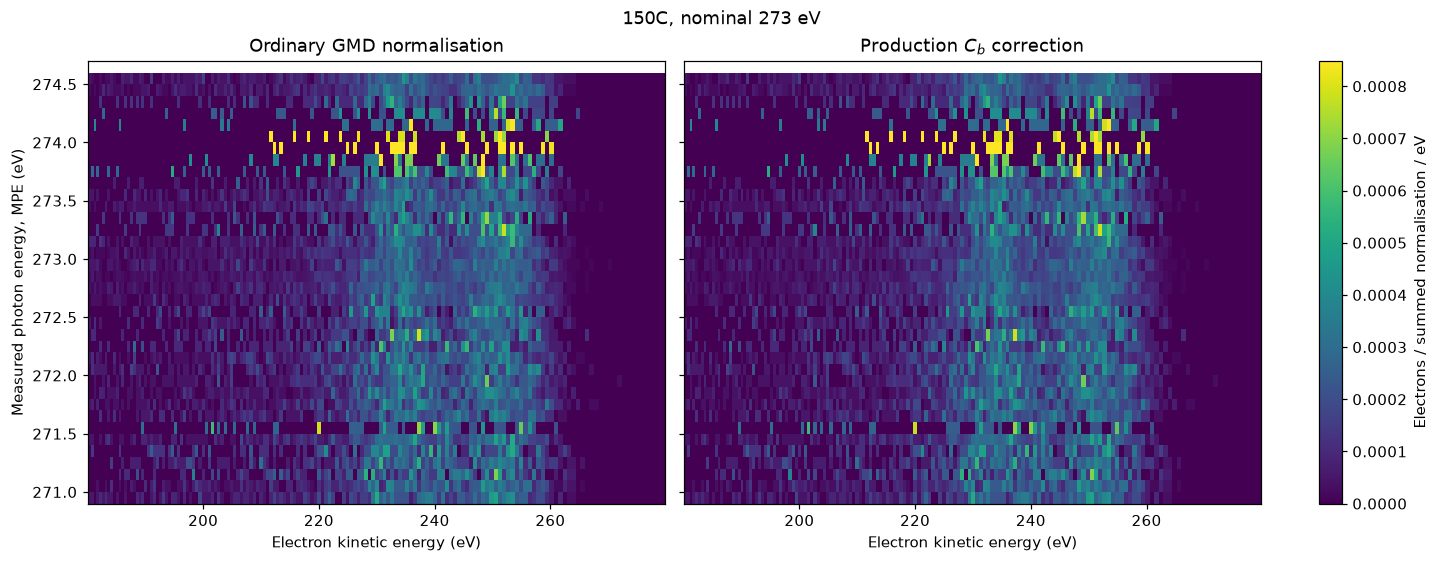

In [28]:

# --- Single-run measured photon-energy vs electron-KE maps ---------------

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

MPE_FAMILY = "150C"              # "150C", "147C (7 June)", "160C"
MPE_NOMINAL_ENERGY_EV = 273.0
MPE_RUN_INDEX = 0
MPE_BIN_WIDTH_EV = 0.1
MPE_PERCENTILES = (1.0, 99.0)  # Exclude extreme measured-energy tails
MPE_VALID_RANGE_EV = (250.0, 310.0)  # Reject invalid monitor values, e.g. zero
MPE_GMD_RANGE = PROD2D_GMD_RANGE    # Same 1-12 uJ selection as original maps
MPE_MIN_SHOTS_PER_BIN = 100
MPE_CHUNK_TRAINS = 100

# Match each source file to its independently learned production Cb.
mpe_families = {
    "150C": (prod2d_datasets, prod2d_results),
    "147C (7 June)": (j7_datasets, j7_results),
    "160C": (wl160_datasets, wl160_run_results),
}

datasets, results = mpe_families[MPE_FAMILY]
if len(datasets) != len(results):
    raise ValueError("Dataset/result lengths differ; check the processing cells.")

mpe_matches = [
    (ds, result) for ds, result in zip(datasets, results)
    if np.isclose(ds["photon_energy_ev"], MPE_NOMINAL_ENERGY_EV)
]

if not mpe_matches:
    raise ValueError(f"No {MPE_FAMILY} run at {MPE_NOMINAL_ENERGY_EV:g} eV")
if not 0 <= MPE_RUN_INDEX < len(mpe_matches):
    raise IndexError(f"Run index invalid; {len(mpe_matches)} runs available.")

mpe_ds, mpe_result = mpe_matches[MPE_RUN_INDEX]
mpe_cb = np.asarray(mpe_result["cb"], dtype=float)

print(f"Dataset: {MPE_FAMILY}, nominal {MPE_NOMINAL_ENERGY_EV:g} eV")
print(f"File: {Path(mpe_ds['source_h5']).name}")

with h5py.File(mpe_ds["source_h5"], "r") as f:
    if "mpe" not in f:
        raise KeyError("No 'mpe' dataset in source HDF5.")

    n_trains, n_bunches = f["gmd"].shape
    n_slots = f["tofs_e"].shape[2]
    if f["tofs_e"].shape[:2] != (n_trains, n_bunches):
        raise ValueError("eTOF and GMD dimensions do not match.")
    if mpe_cb.shape != (n_bunches,) or not np.all(np.isfinite(mpe_cb)):
        raise ValueError("Missing or invalid production Cb for this run.")

    keep = keep_mask_like_compute_aggregates_from_h5(
        f, trim_start=mpe_ds["trim_start"], trim_end=mpe_ds["trim_end"]
    )
    mpe = np.asarray(f["mpe"][:], dtype=float)
    if mpe.shape != (n_trains,):
        raise ValueError(f"Expected one MPE value per train, got {mpe.shape}")

    valid_mpe = (
        keep & np.isfinite(mpe)
        & (mpe >= MPE_VALID_RANGE_EV[0])
        & (mpe <= MPE_VALID_RANGE_EV[1])
    )
    measured = mpe[valid_mpe]

    print(f"Selected trains: {np.count_nonzero(keep):,}")
    print(f"Trains with valid MPE: {measured.size:,} "
          f"({100 * measured.size / max(np.count_nonzero(keep), 1):.1f}%)")

    if measured.size < 10:
        raise ValueError(
            "Insufficient valid measured photon energies. "
            "Inspect the MPE monitor; do not substitute nominal energies."
        )

    print(f"Measured MPE min/max: {measured.min():.4f} / {measured.max():.4f} eV")
    print(f"Measured MPE median: {np.median(measured):.4f} eV")

    lo, hi = np.percentile(measured, MPE_PERCENTILES)
    mpe_edges = np.arange(
        np.floor(lo / MPE_BIN_WIDTH_EV) * MPE_BIN_WIDTH_EV,
        np.ceil(hi / MPE_BIN_WIDTH_EV) * MPE_BIN_WIDTH_EV + 1.5 * MPE_BIN_WIDTH_EV,
        MPE_BIN_WIDTH_EV
    )
    n_energy_bins = len(mpe_edges) - 1
    n_tof_bins = len(tof_edges_prod2d) - 1

    print(f"Map energy range: {mpe_edges[0]:.3f}–{mpe_edges[-1]:.3f} eV")
    print(f"Photon-energy bins: {n_energy_bins}, width {MPE_BIN_WIDTH_EV:g} eV")

    # Arrays grow only with histogram dimensions, not the number of shots.
    mpe_tof_counts = np.zeros((n_energy_bins, n_tof_bins), dtype=np.float64)
    mpe_gmd_by_bunch = np.zeros((n_energy_bins, n_bunches), dtype=np.float64)
    mpe_shots_per_bin = np.zeros(n_energy_bins, dtype=np.int64)

    for start in range(0, n_trains, MPE_CHUNK_TRAINS):
        stop = min(start + MPE_CHUNK_TRAINS, n_trains)
        row_keep = valid_mpe[start:stop]
        if not np.any(row_keep):
            continue

        energy_rows = mpe[start:stop][row_keep]
        energy_bins = np.searchsorted(mpe_edges, energy_rows, side="right") - 1
        in_map = (energy_bins >= 0) & (energy_bins < n_energy_bins)
        if not np.any(in_map):
            continue

        gmd = f["gmd"][start:stop][row_keep][in_map].astype(float)
        tofs = f["tofs_e"][start:stop][row_keep][in_map]
        energy_bins = energy_bins[in_map]

        # Same raw-GMD shot selection as the original production maps.
        selected = (
            np.isfinite(gmd)
            & (gmd >= MPE_GMD_RANGE[0])
            & (gmd < MPE_GMD_RANGE[1])
        )
        if not np.any(selected):
            continue

        train_idx, bunch_idx = np.nonzero(selected)
        shot_energy_bins = energy_bins[train_idx]
        shot_gmd = gmd[selected]

        # Sum GMD by measured-energy bin and bunch position.
        np.add.at(
            mpe_gmd_by_bunch,
            (shot_energy_bins, bunch_idx),
            shot_gmd
        )
        mpe_shots_per_bin += np.bincount(
            shot_energy_bins, minlength=n_energy_bins
        )

        # Histogram the original eTOF hits, without smoothing.
        events = tofs[selected].reshape(-1)
        valid_hits = (
            (events >= PROD2D_TOF_RANGE[0])
            & (events <= PROD2D_TOF_RANGE[1])
        )

        if np.any(valid_hits):
            event_energy_bins = np.repeat(shot_energy_bins, n_slots)[valid_hits]
            event_tof_bins = (
                events[valid_hits].astype(np.int64) - PROD2D_TOF_RANGE[0]
            )
            flat_bins = event_energy_bins * n_tof_bins + event_tof_bins
            mpe_tof_counts += np.bincount(
                flat_bins, minlength=n_energy_bins * n_tof_bins
            ).reshape(n_energy_bins, n_tof_bins)

# --- Convert TOF to KE using the original calibration -------------------

if reverse_ke_prod2d:
    mpe_tof_counts = mpe_tof_counts[:, ::-1]

mpe_counts_ke = mpe_tof_counts[:, ke_select_prod2d]

# Same Cb convention as production_cb_and_spectrum_2d:
# counts / sum(GMD), or counts / sum(GMD * Cb).
mpe_sum_gmd = np.sum(mpe_gmd_by_bunch, axis=1)
mpe_sum_gmd_eff = np.sum(mpe_gmd_by_bunch * mpe_cb[None, :], axis=1)

valid_bins = (
    (mpe_shots_per_bin >= MPE_MIN_SHOTS_PER_BIN)
    & (mpe_sum_gmd > 0)
    & (mpe_sum_gmd_eff > 0)
)

mpe_map_gmd = np.full_like(mpe_counts_ke, np.nan, dtype=float)
mpe_map_cb = np.full_like(mpe_counts_ke, np.nan, dtype=float)

mpe_map_gmd[valid_bins] = (
    mpe_counts_ke[valid_bins]
    / mpe_sum_gmd[valid_bins, None]
    / ke_width_plot_prod2d[None, :]
)
mpe_map_cb[valid_bins] = (
    mpe_counts_ke[valid_bins]
    / mpe_sum_gmd_eff[valid_bins, None]
    / ke_width_plot_prod2d[None, :]
)

print(f"Valid photon-energy bins: {np.count_nonzero(valid_bins)}/{n_energy_bins}")
print(f"Selected shots in map: {np.sum(mpe_shots_per_bin):,}")

if not np.any(valid_bins):
    raise ValueError("No populated MPE bins. Check MPE resolution or minimum shots per bin.")

# --- Plot: ordinary GMD versus production Cb ----------------------------

all_values = np.concatenate([
    mpe_map_gmd[np.isfinite(mpe_map_gmd)],
    mpe_map_cb[np.isfinite(mpe_map_cb)]
])
vmin, vmax = np.percentile(all_values, [1, 99.5])

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5),
    sharex=True, sharey=True, constrained_layout=True
)

for ax, values, title in zip(
    axes,
    [mpe_map_gmd, mpe_map_cb],
    ["Ordinary GMD normalisation", r"Production $C_b$ correction"]
):
    im = ax.pcolormesh(
        ke_edges_plot_prod2d,
        mpe_edges,
        np.ma.masked_invalid(values),
        shading="flat", vmin=vmin, vmax=vmax
    )
    ax.set_xlabel("Electron kinetic energy (eV)")
    ax.set_title(title)

axes[0].set_ylabel("Measured photon energy, MPE (eV)")
fig.colorbar(im, ax=axes, label="Electrons / summed normalisation / eV")
fig.suptitle(f"{MPE_FAMILY}, nominal {MPE_NOMINAL_ENERGY_EV:g} eV")
plt.show()


Run: glycine_delay_scan_150C_273.0eV.h5
Valid MPE readings: 3,304 / 32,704
Median trains between readings: 10
Maximum gap: 2899 trains
Median |energy change|: 0.0107 eV
90th percentile |energy change|: 0.9893 eV
Fraction of changes above 0.1 eV: 28.4%

Most common measurement intervals:
  Every 10 trains: 1,562 occurrences
  Every 11 trains: 872 occurrences
  Every 8 trains: 415 occurrences
  Every 9 trains: 100 occurrences
  Every 7 trains: 83 occurrences
  Every 1 trains: 52 occurrences
  Every 2 trains: 48 occurrences
  Every 6 trains: 39 occurrences
  Every 3 trains: 35 occurrences
  Every 4 trains: 32 occurrences


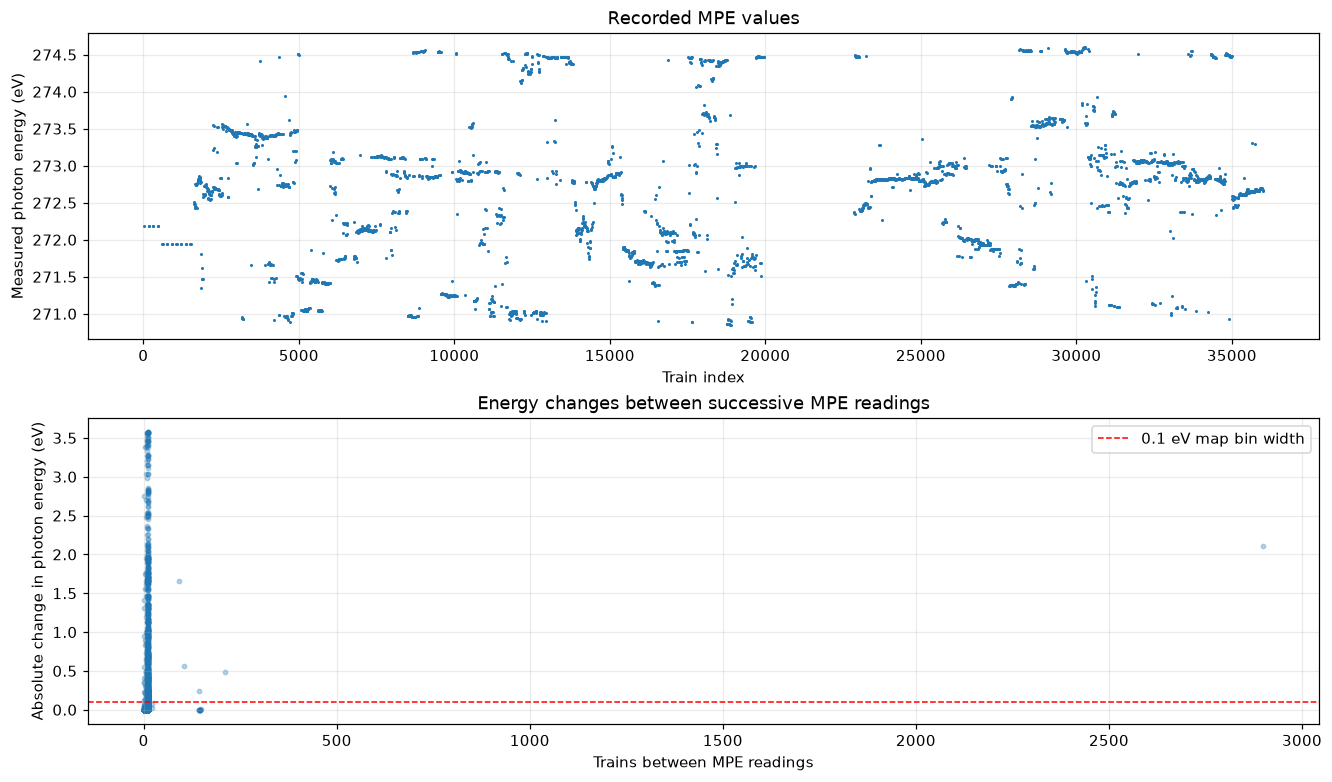

In [29]:

# --- Check MPE sampling intervals and energy fluctuations ---------------

MPE_CHECK_FAMILY = "150C"
MPE_CHECK_ENERGY_EV = 273.0
MPE_CHECK_RUN_INDEX = 0

mpe_check_families = {
    "150C": prod2d_datasets,
    "147C (7 June)": j7_datasets,
    "160C": wl160_datasets,
}

matches = [
    ds for ds in mpe_check_families[MPE_CHECK_FAMILY]
    if np.isclose(ds["photon_energy_ev"], MPE_CHECK_ENERGY_EV)
]
if not matches or MPE_CHECK_RUN_INDEX >= len(matches):
    raise ValueError("Requested MPE run not found.")

ds = matches[MPE_CHECK_RUN_INDEX]

with h5py.File(ds["source_h5"], "r") as f:
    keep = keep_mask_like_compute_aggregates_from_h5(
        f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
    )
    mpe = np.asarray(f["mpe"][:], dtype=float)

valid = keep & np.isfinite(mpe) & (mpe >= 250) & (mpe <= 310)
indices = np.flatnonzero(valid)
energies = mpe[indices]

if len(indices) < 3:
    raise ValueError("Too few valid MPE measurements.")

gaps = np.diff(indices)
energy_changes = np.diff(energies)

print(f"Run: {ds['source_h5'].name}")
print(f"Valid MPE readings: {len(indices):,} / {np.count_nonzero(keep):,}")
print(f"Median trains between readings: {np.median(gaps):g}")
print(f"Maximum gap: {np.max(gaps)} trains")
print(f"Median |energy change|: {np.median(np.abs(energy_changes)):.4f} eV")
print(f"90th percentile |energy change|: {np.percentile(np.abs(energy_changes), 90):.4f} eV")
print(f"Fraction of changes above 0.1 eV: {np.mean(np.abs(energy_changes) > 0.1):.1%}")

unique_gaps, gap_counts = np.unique(gaps, return_counts=True)
print("\nMost common measurement intervals:")
for i in np.argsort(gap_counts)[::-1][:10]:
    print(f"  Every {unique_gaps[i]:g} trains: {gap_counts[i]:,} occurrences")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)

axes[0].plot(indices, energies, ".", ms=2)
axes[0].set(xlabel="Train index", ylabel="Measured photon energy (eV)",
            title="Recorded MPE values")
axes[0].grid(alpha=0.25)

axes[1].scatter(gaps, np.abs(energy_changes), s=8, alpha=0.3)
axes[1].axhline(0.1, ls="--", color="red", lw=1, label="0.1 eV map bin width")
axes[1].set(xlabel="Trains between MPE readings",
            ylabel="Absolute change in photon energy (eV)",
            title="Energy changes between successive MPE readings")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.show()


Run: glycine_delay_scan_150C_273.0eV.h5
Selected trains: 32,704
Valid MPE readings: 3,304 (10.1%)

--- Measurement intervals ---
Median gap: 10 trains
Mean gap: 10.89 trains
Maximum gap: 2,899 trains
Gaps <= 12: 99.5%
Gaps > 12: 17

--- Energy changes between regularly spaced readings ---
Number of intervals: 3,286
 50th percentile: 0.0107 eV
 75th percentile: 0.1456 eV
 90th percentile: 0.9888 eV
 95th percentile: 1.7084 eV
 99th percentile: 3.2731 eV
100th percentile: 3.5736 eV
|Delta E| > 0.05 eV: 32.8%
|Delta E| > 0.10 eV: 28.4%
|Delta E| > 0.20 eV: 22.6%
|Delta E| > 0.50 eV: 15.3%
|Delta E| > 1.00 eV: 9.9%
|Delta E| > 2.00 eV: 3.1%

Detected changes > 0.1 eV: 933
Median trains between detected large changes: 11

--- Potential stable-interval assignment ---
Stable intervals: 2,353
Additional trains potentially assignable: 19,640
Potential coverage: 70.2%


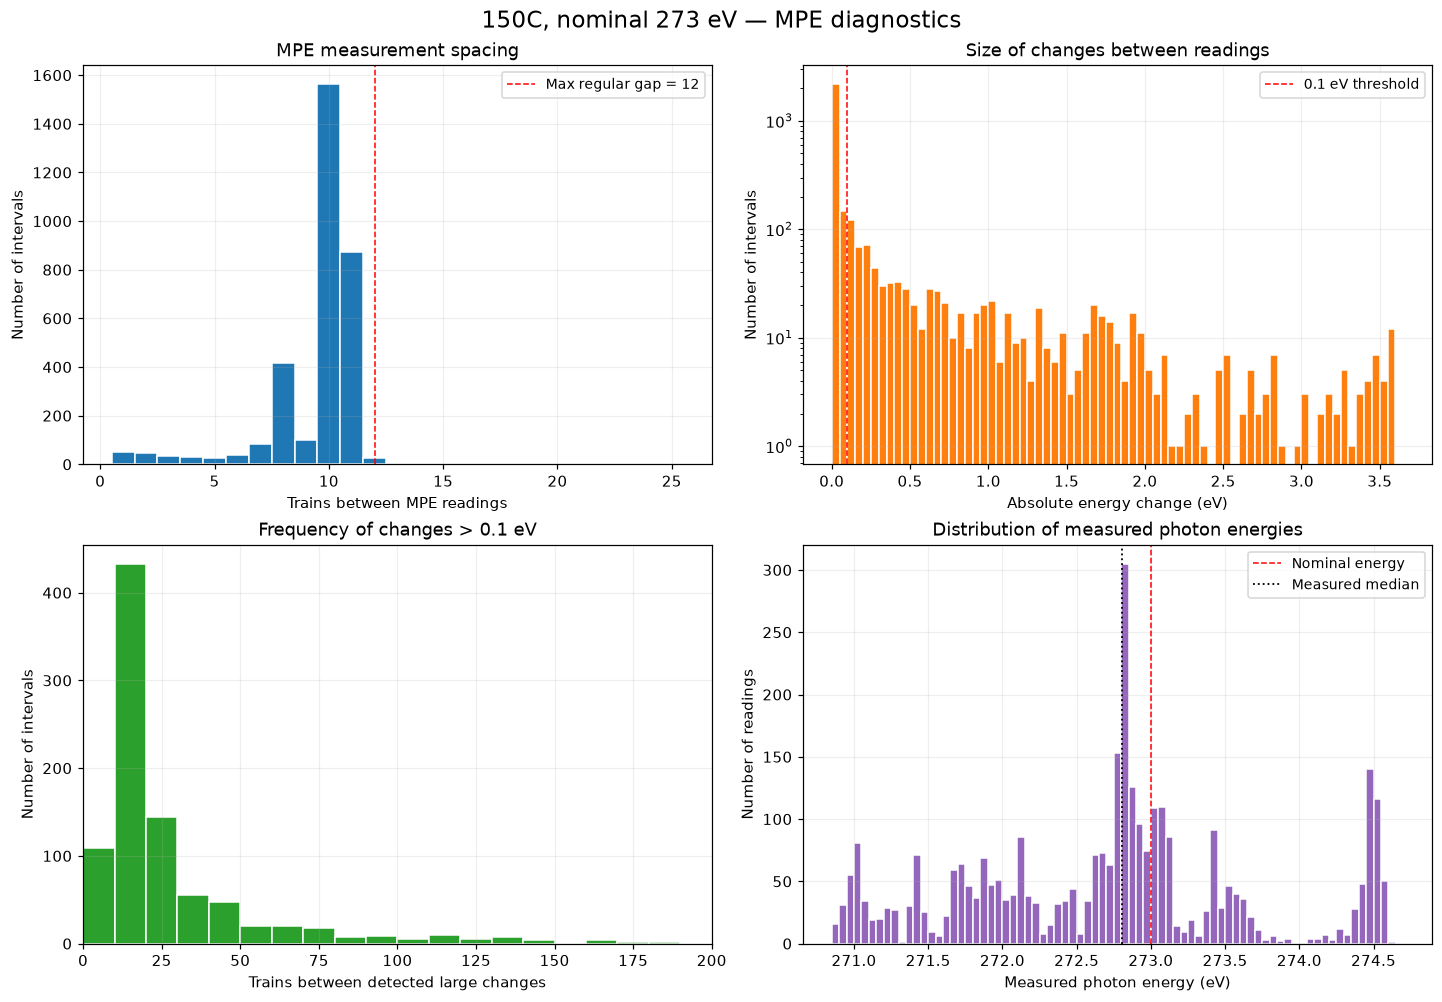

In [30]:

# --- MPE monitor diagnostics: sampling frequency and energy changes -----

import numpy as np
import h5py
import matplotlib.pyplot as plt

MPE_DIAG_FAMILY = "150C"  # "150C", "147C (7 June)", "160C"
MPE_DIAG_ENERGY_EV = 273.0
MPE_DIAG_RUN_INDEX = 0

MPE_DIAG_VALID_RANGE = (250.0, 310.0)
MPE_DIAG_MAX_GAP = 12          # Largest gap considered regular sampling
MPE_DIAG_JUMP_EV = 0.1         # Threshold defining a large energy change
MPE_DIAG_ENERGY_BIN_EV = 0.05

mpe_diag_families = {
    "150C": prod2d_datasets,
    "147C (7 June)": j7_datasets,
    "160C": wl160_datasets,
}

matches = [
    ds for ds in mpe_diag_families[MPE_DIAG_FAMILY]
    if np.isclose(ds["photon_energy_ev"], MPE_DIAG_ENERGY_EV)
]
if not 0 <= MPE_DIAG_RUN_INDEX < len(matches):
    raise ValueError(f"No matching run at {MPE_DIAG_ENERGY_EV:g} eV")

ds = matches[MPE_DIAG_RUN_INDEX]

with h5py.File(ds["source_h5"], "r") as f:
    keep = keep_mask_like_compute_aggregates_from_h5(
        f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
    )
    mpe = np.asarray(f["mpe"][:], dtype=float)

if mpe.shape != keep.shape:
    raise ValueError(f"MPE and train-selection shapes differ: {mpe.shape}, {keep.shape}")

valid = keep & np.isfinite(mpe) & (mpe >= MPE_DIAG_VALID_RANGE[0]) & (mpe <= MPE_DIAG_VALID_RANGE[1])
idx = np.flatnonzero(valid)
energy = mpe[idx]

if len(idx) < 3:
    raise ValueError("Too few valid MPE measurements.")

gaps = np.diff(idx)
steps = np.abs(np.diff(energy))

# Only treat neighbouring readings as comparable when their gap is short.
regular = gaps <= MPE_DIAG_MAX_GAP
regular_steps = steps[regular]
large_changes = regular & (steps > MPE_DIAG_JUMP_EV)
jump_indices = idx[1:][large_changes]
jump_intervals = np.diff(jump_indices)

# Estimate the number of missing trains potentially recoverable by
# forward filling between stable neighbouring readings.
bad_keep_cumsum = np.r_[0, np.cumsum(~keep)]
uninterrupted = (bad_keep_cumsum[idx[1:] + 1] - bad_keep_cumsum[idx[:-1]] == 0)
stable = regular & uninterrupted & (steps <= MPE_DIAG_JUMP_EV)
additional_trains = int(np.sum(gaps[stable] - 1))

print(f"Run: {ds['source_h5'].name}")
print(f"Selected trains: {np.count_nonzero(keep):,}")
print(f"Valid MPE readings: {len(idx):,} ({100 * len(idx) / np.count_nonzero(keep):.1f}%)")

print("\n--- Measurement intervals ---")
print(f"Median gap: {np.median(gaps):g} trains")
print(f"Mean gap: {np.mean(gaps):.2f} trains")
print(f"Maximum gap: {np.max(gaps):,} trains")
print(f"Gaps <= {MPE_DIAG_MAX_GAP}: {np.mean(regular):.1%}")
print(f"Gaps > {MPE_DIAG_MAX_GAP}: {np.count_nonzero(~regular):,}")

print("\n--- Energy changes between regularly spaced readings ---")
print(f"Number of intervals: {len(regular_steps):,}")
for p in (50, 75, 90, 95, 99, 100):
    print(f"{p:3d}th percentile: {np.percentile(regular_steps, p):.4f} eV")

for threshold in (0.05, 0.1, 0.2, 0.5, 1.0, 2.0):
    print(f"|Delta E| > {threshold:.2f} eV: {np.mean(regular_steps > threshold):.1%}")

print(f"\nDetected changes > {MPE_DIAG_JUMP_EV:g} eV: {len(jump_indices):,}")
if len(jump_intervals):
    print(f"Median trains between detected large changes: {np.median(jump_intervals):g}")

print("\n--- Potential stable-interval assignment ---")
print(f"Stable intervals: {np.count_nonzero(stable):,}")
print(f"Additional trains potentially assignable: {additional_trains:,}")
print(f"Potential coverage: {100 * (len(idx) + additional_trains) / np.count_nonzero(keep):.1f}%")


# --- Four-panel figure ---------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

# 1. Gap between consecutive recorded MPE measurements.
ax = axes[0, 0]
ax.hist(gaps[gaps <= 25], bins=np.arange(0.5, 26.5, 1), color="tab:blue", edgecolor="white")
ax.axvline(MPE_DIAG_MAX_GAP, color="red", ls="--", lw=1, label=f"Max regular gap = {MPE_DIAG_MAX_GAP}")
ax.set(xlabel="Trains between MPE readings", ylabel="Number of intervals", title="MPE measurement spacing")
ax.legend(fontsize=9)
ax.grid(alpha=0.2)

# 2. Absolute energy changes between consecutive regularly spaced readings.
ax = axes[0, 1]
step_edges = np.arange(0, max(0.2, np.ceil(regular_steps.max() / 0.05) * 0.05) + 0.051, 0.05)
ax.hist(regular_steps, bins=step_edges, color="tab:orange", edgecolor="white")
ax.axvline(MPE_DIAG_JUMP_EV, color="red", ls="--", lw=1, label=f"{MPE_DIAG_JUMP_EV:g} eV threshold")
ax.set(xlabel="Absolute energy change (eV)", ylabel="Number of intervals", title="Size of changes between readings")
ax.set_yscale("log")
ax.legend(fontsize=9)
ax.grid(alpha=0.2)

# 3. Intervals between successive detected large energy changes.
ax = axes[1, 0]
if len(jump_intervals):
    ax.hist(jump_intervals[jump_intervals <= 200], bins=np.arange(0, 211, 10),
            color="tab:green", edgecolor="white")
    ax.set_xlim(0, 200)
else:
    ax.text(0.5, 0.5, "Too few large changes", transform=ax.transAxes, ha="center", va="center")
ax.set(xlabel="Trains between detected large changes", ylabel="Number of intervals",
       title=f"Frequency of changes > {MPE_DIAG_JUMP_EV:g} eV")
ax.grid(alpha=0.2)

# 4. Distribution of measured photon energies.
ax = axes[1, 1]
energy_edges = np.arange(
    np.floor(energy.min() / MPE_DIAG_ENERGY_BIN_EV) * MPE_DIAG_ENERGY_BIN_EV,
    np.ceil(energy.max() / MPE_DIAG_ENERGY_BIN_EV) * MPE_DIAG_ENERGY_BIN_EV + 1.5 * MPE_DIAG_ENERGY_BIN_EV,
    MPE_DIAG_ENERGY_BIN_EV
)
ax.hist(energy, bins=energy_edges, color="tab:purple", edgecolor="white")
ax.axvline(MPE_DIAG_ENERGY_EV, color="red", ls="--", lw=1, label="Nominal energy")
ax.axvline(np.median(energy), color="black", ls=":", lw=1.2, label="Measured median")
ax.set(xlabel="Measured photon energy (eV)", ylabel="Number of readings",
       title="Distribution of measured photon energies")
ax.legend(fontsize=9)
ax.grid(alpha=0.2)

fig.suptitle(f"{MPE_DIAG_FAMILY}, nominal {MPE_DIAG_ENERGY_EV:g} eV — MPE diagnostics", fontsize=15)
plt.show()


## MPE map

150C: MPE measured 29,886, assigned 204,935 of 298,523 kept trains (78.7%); selected shots 19,016,554; valid bins 8/15
160C: MPE measured 4,794, assigned 33,483 of 80,951 kept trains (47.3%); selected shots 2,714,423; valid bins 14/15


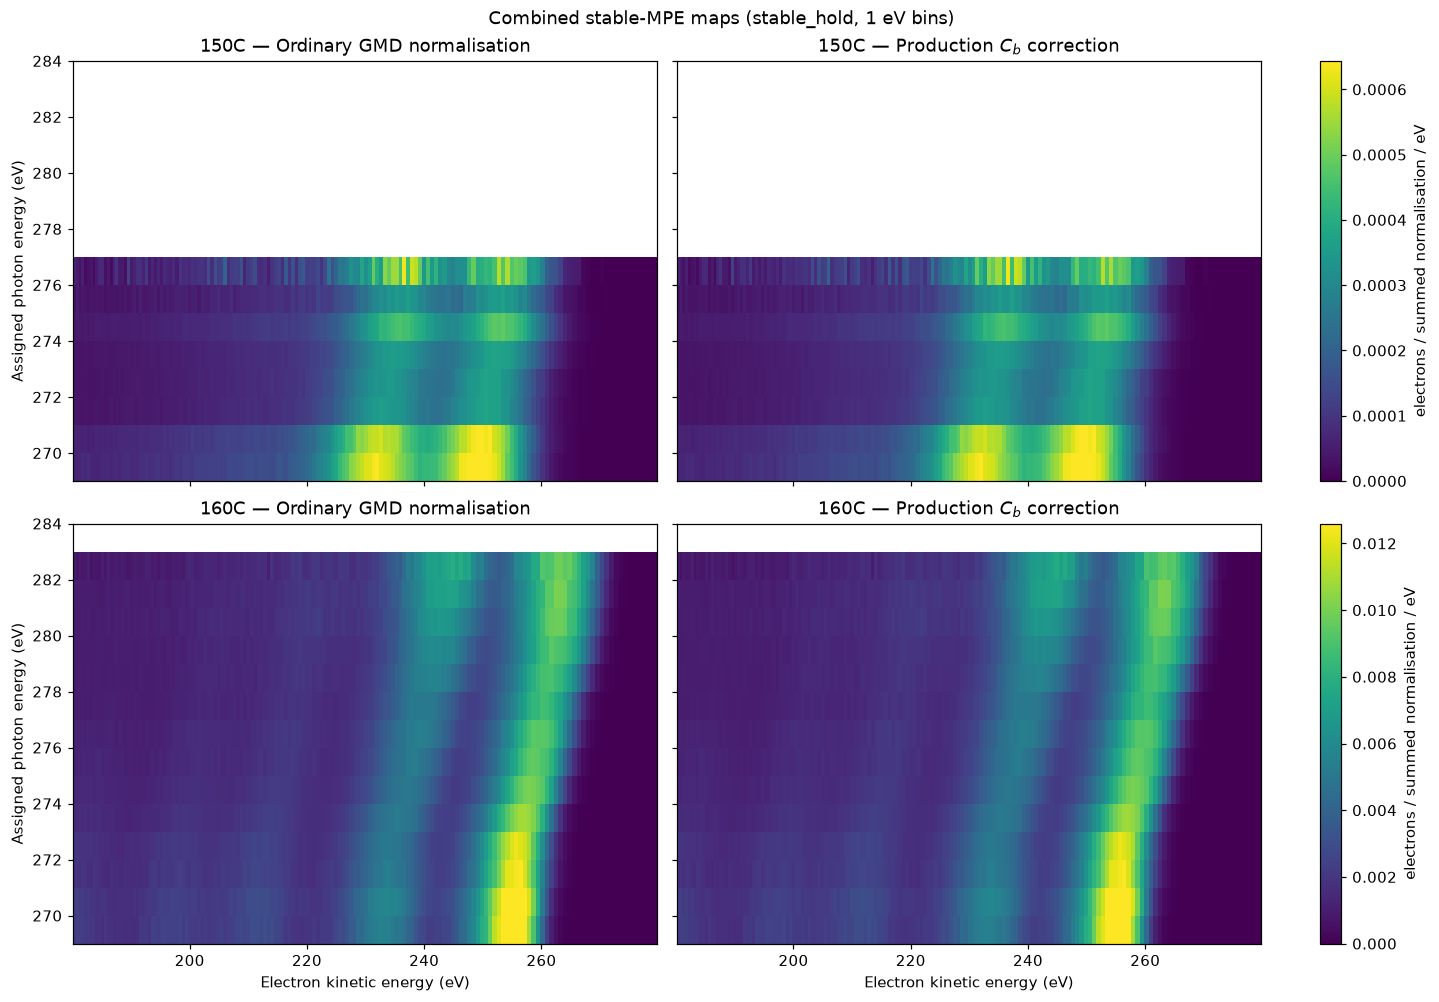

In [43]:

# --- Combined MPE-energy maps: all runs within each temperature ----------

from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt

MPE_STABLE_MODE = "stable_hold"   # "stable_hold" or "measured_only"
MPE_STABLE_GAP_TRAINS = 12
MPE_STABLE_MAX_STEP_EV = 0.30
MPE_STABLE_BIN_WIDTH_EV = 1
MPE_STABLE_ENERGY_RANGE_EV = (269.0, 284.0)
MPE_STABLE_VALID_RANGE_EV = (250.0, 310.0)
MPE_STABLE_GMD_RANGE = PROD2D_GMD_RANGE
MPE_STABLE_MIN_SHOTS_BIN = 200
MPE_STABLE_CHUNK_TRAINS = 100

mpe_stable_families = {
    "150C": (prod2d_datasets, prod2d_results),
    # "147C (7 June)": (j7_datasets, j7_results),
    "160C": (wl160_datasets, wl160_run_results),
}

# Both historic pipelines use the same TOF/KE bins and raw-GMD cut.
if (tuple(J7_TOF_RANGE) != tuple(PROD2D_TOF_RANGE)
        or tuple(J7_KE_RANGE) != tuple(PROD2D_KE_RANGE)
        or tuple(J7_GMD_RANGE) != tuple(MPE_STABLE_GMD_RANGE)
        or not np.allclose(j7_ke_edges_plot, ke_edges_plot_prod2d)):
    raise ValueError("150C and 147C binning/GMD settings differ; use separate calibrations.")

start_ev, stop_ev = MPE_STABLE_ENERGY_RANGE_EV
mpe_stable_edges = np.arange(start_ev, stop_ev + MPE_STABLE_BIN_WIDTH_EV / 2, MPE_STABLE_BIN_WIDTH_EV)
if not np.isclose(mpe_stable_edges[-1], stop_ev):
    raise ValueError("The energy range must be divisible by the bin width.")

n_energy_bins = len(mpe_stable_edges) - 1
n_tof_bins = len(tof_edges_prod2d) - 1
mpe_stable_maps = {}

for family, (datasets, results) in mpe_stable_families.items():
    if len(datasets) != len(results):
        raise ValueError(f"{family}: datasets/results are not aligned.")

    tof_counts = np.zeros((n_energy_bins, n_tof_bins), dtype=np.float64)
    sum_gmd = np.zeros(n_energy_bins, dtype=np.float64)
    sum_gmd_cb = np.zeros(n_energy_bins, dtype=np.float64)
    shots_per_bin = np.zeros(n_energy_bins, dtype=np.int64)
    total_kept = total_measured = total_estimated = total_selected_shots = 0

    for ds, result in zip(datasets, results):
        if not np.isclose(ds["photon_energy_ev"], result["photon_energy_ev"]):
            raise ValueError(f"{family}: dataset/result energy mismatch: {ds['source_h5']}")
        cb = np.asarray(result["cb"], dtype=np.float64)

        with h5py.File(ds["source_h5"], "r") as f:
            if "mpe" not in f:
                print(f"{family}: no MPE key in {Path(ds['source_h5']).name}; skipping")
                continue
            n_trains, n_bunches = f["gmd"].shape
            if (f["tofs_e"].shape[:2] != (n_trains, n_bunches)
                    or f["mpe"].shape != (n_trains,)
                    or cb.shape != (n_bunches,)
                    or not np.all(np.isfinite(cb))):
                raise ValueError(f"Unexpected array shapes or Cb in {ds['source_h5']}")

            keep = keep_mask_like_compute_aggregates_from_h5(
                f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
            )
            mpe = np.asarray(f["mpe"][:], dtype=float)
            measured_valid = (keep & np.isfinite(mpe)
                              & (mpe >= MPE_STABLE_VALID_RANGE_EV[0])
                              & (mpe <= MPE_STABLE_VALID_RANGE_EV[1]))
            measured_idx = np.flatnonzero(measured_valid)
            assigned = np.full(n_trains, np.nan)
            assigned[measured_valid] = mpe[measured_valid]

            if MPE_STABLE_MODE == "stable_hold":
                for left, right in zip(measured_idx[:-1], measured_idx[1:]):
                    if (right - left <= MPE_STABLE_GAP_TRAINS
                            and abs(mpe[right] - mpe[left]) <= MPE_STABLE_MAX_STEP_EV
                            and np.all(keep[left:right + 1])):
                        assigned[left + 1:right] = mpe[left]
            elif MPE_STABLE_MODE != "measured_only":
                raise ValueError("MPE_STABLE_MODE must be 'stable_hold' or 'measured_only'.")

            in_range = (np.isfinite(assigned)
                        & (assigned >= mpe_stable_edges[0])
                        & (assigned < mpe_stable_edges[-1]))
            total_kept += int(keep.sum())
            total_measured += int(measured_valid.sum())
            total_estimated += int((np.isfinite(assigned) & ~measured_valid).sum())

            for start in range(0, n_trains, MPE_STABLE_CHUNK_TRAINS):
                stop = min(start + MPE_STABLE_CHUNK_TRAINS, n_trains)
                selected_rows = np.flatnonzero(in_range[start:stop])
                if not selected_rows.size:
                    continue

                e_bins = np.searchsorted(mpe_stable_edges, assigned[start:stop][selected_rows], side="right") - 1
                gmd = np.asarray(f["gmd"][start:stop][selected_rows], dtype=np.float64)
                selected = (np.isfinite(gmd) & (gmd >= MPE_STABLE_GMD_RANGE[0])
                            & (gmd < MPE_STABLE_GMD_RANGE[1]))
                if not selected.any():
                    continue

                tofs = f["tofs_e"][start:stop][selected_rows]
                train_idx, bunch_idx = np.nonzero(selected)
                shot_e_bins = e_bins[train_idx]
                shot_gmd = gmd[selected]
                np.add.at(shots_per_bin, shot_e_bins, 1)
                np.add.at(sum_gmd, shot_e_bins, shot_gmd)
                np.add.at(sum_gmd_cb, shot_e_bins, shot_gmd * cb[bunch_idx])
                total_selected_shots += len(shot_e_bins)

                events = tofs[selected]  # (selected shots, electron slots)
                valid_hits = ((events >= PROD2D_TOF_RANGE[0])
                              & (events <= PROD2D_TOF_RANGE[1]))
                if np.any(valid_hits):
                    hit_tof = events[valid_hits].astype(np.int64) - PROD2D_TOF_RANGE[0]
                    hit_energy = np.broadcast_to(shot_e_bins[:, None], events.shape)[valid_hits]
                    flat = hit_energy * n_tof_bins + hit_tof
                    tof_counts += np.bincount(flat, minlength=n_energy_bins * n_tof_bins).reshape(tof_counts.shape)

    counts_ke = tof_counts[:, ::-1] if reverse_ke_prod2d else tof_counts
    counts_ke = counts_ke[:, ke_select_prod2d]
    valid_bins = ((shots_per_bin >= MPE_STABLE_MIN_SHOTS_BIN)
                  & (sum_gmd > 0) & (sum_gmd_cb > 0))
    ordinary = np.full(counts_ke.shape, np.nan)
    corrected = np.full(counts_ke.shape, np.nan)
    ordinary[valid_bins] = counts_ke[valid_bins] / sum_gmd[valid_bins, None] / ke_width_plot_prod2d[None, :]
    corrected[valid_bins] = counts_ke[valid_bins] / sum_gmd_cb[valid_bins, None] / ke_width_plot_prod2d[None, :]

    mpe_stable_maps[family] = {
        "ordinary": ordinary, "cb": corrected, "shots_per_bin": shots_per_bin,
        "sum_gmd": sum_gmd, "sum_gmd_cb": sum_gmd_cb, "valid_bins": valid_bins,
        "kept_trains": total_kept, "measured_trains": total_measured,
        "estimated_trains": total_estimated, "selected_shots": total_selected_shots,
    }
    coverage = 100 * (total_measured + total_estimated) / max(total_kept, 1)
    print(f"{family}: MPE measured {total_measured:,}, assigned {total_estimated:,} "
          f"of {total_kept:,} kept trains ({coverage:.1f}%); "
          f"selected shots {total_selected_shots:,}; valid bins {valid_bins.sum()}/{n_energy_bins}")
    if not valid_bins.any():
        print(f"  No usable MPE map for {family}. Check whether mpe contains valid readings.")

# --- Plot GMD and Cb maps; shared colour limits WITHIN each temperature -

n_families = len(mpe_stable_families)
fig, axes = plt.subplots(n_families, 2, figsize=(13, 4.5 * n_families), sharex=True, sharey=True, squeeze=False, constrained_layout=True)

for row, family in enumerate(mpe_stable_families):
    maps = mpe_stable_maps[family]
    values = np.concatenate([maps[key][np.isfinite(maps[key])] for key in ("ordinary", "cb")])

    if values.size:
        vmin, vmax = np.percentile(values, [1, 99.5])
        if vmin == vmax:
            vmin, vmax = None, None

        for col, (key, title) in enumerate([
            ("ordinary", "Ordinary GMD normalisation"),
            ("cb", r"Production $C_b$ correction")
        ]):
            im = axes[row, col].pcolormesh(
                ke_edges_plot_prod2d, mpe_stable_edges, np.ma.masked_invalid(maps[key]),
                shading="flat", vmin=vmin, vmax=vmax
            )
            axes[row, col].set_title(f"{family} — {title}")
        fig.colorbar(im, ax=list(axes[row]), label="electrons / summed normalisation / eV")
    else:
        for col in (0, 1):
            axes[row, col].text(0.5, 0.5, "No valid MPE data", transform=axes[row, col].transAxes,
                                ha="center", va="center")
            axes[row, col].set_title(f"{family}")

    axes[row, 0].set_ylabel("Assigned photon energy (eV)")

for ax in axes[-1]:
    ax.set_xlabel("Electron kinetic energy (eV)")

fig.suptitle(f"Combined stable-MPE maps ({MPE_STABLE_MODE}, {MPE_STABLE_BIN_WIDTH_EV:g} eV bins)")
plt.show()



150C
 Nominal     Kept      NaN     Zero  Outside  Valid all  Valid kept   Valid %       Nonzero range (eV)
   271.0   33,745   30,571        0        0      3,257       3,174      9.4%       266.978 to 274.297
   271.5   34,364   30,834        0        0      3,575       3,530     10.3%       267.478 to 274.537
   272.0   33,739   30,295       14        0      3,490       3,430     10.2%       268.128 to 273.893
   272.5   32,791   29,569       14        0      3,357       3,208      9.8%       269.801 to 274.231
   273.0   32,704   29,400        0        0      3,649       3,304     10.1%       270.852 to 274.601
   273.5   32,890   29,598       15        0      3,351       3,277     10.0%       271.251 to 275.089
   274.0   32,788   29,448        0        0      3,434       3,340     10.2%       271.708 to 275.525
   274.5   32,707   29,352       14        0      3,553       3,341     10.2%       272.311 to 276.061
   275.0   32,795   29,497       15        1      3,561       3,282

/tmp/ipykernel_1494169/363894619.py:66: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0].plot(energy, coverage, "o-", color=FAMILY_COLOURS[family],
/tmp/ipykernel_1494169/363894619.py:78: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[1].plot(mpe_centres, np.where(shots > 0, shots, np.nan), "o-",


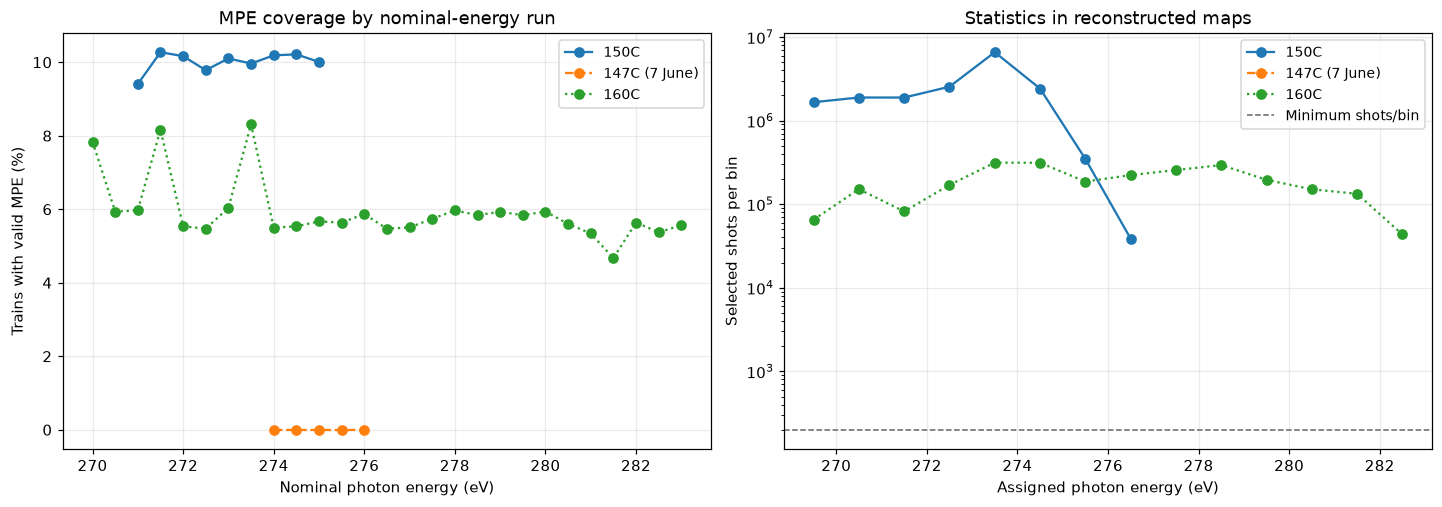

In [20]:

# --- MPE availability by nominal run and reconstructed-map coverage -----

MPE_AUDIT_VALID_RANGE_EV = (250.0, 310.0)

mpe_audit_families = {
    "150C": prod2d_datasets,
    "147C (7 June)": j7_datasets,
    "160C": wl160_datasets,
}

mpe_audit = {}

for family, datasets in mpe_audit_families.items():
    rows = []
    print(f"\n{family}")
    print(f"{'Nominal':>8} {'Kept':>8} {'NaN':>8} {'Zero':>8} {'Outside':>8} {'Valid all':>10} {'Valid kept':>11} {'Valid %':>9} {'Nonzero range (eV)':>24}")

    for ds in sorted(datasets, key=lambda d: d["photon_energy_ev"]):
        with h5py.File(ds["source_h5"], "r") as f:
            keep = keep_mask_like_compute_aggregates_from_h5(
                f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
            )
            n_kept = int(keep.sum())

            if "mpe" not in f:
                print(f"{ds['photon_energy_ev']:8.1f}  MPE KEY MISSING: {Path(ds['source_h5']).name}")
                rows.append({"energy": ds["photon_energy_ev"], "coverage": 0.0})
                continue

            mpe = np.asarray(f["mpe"][:], dtype=float)
            if mpe.shape != keep.shape:
                raise ValueError(f"MPE/keep shape mismatch in {ds['source_h5']}")

            finite = np.isfinite(mpe)
            zero = finite & (mpe == 0)
            valid = finite & (mpe >= MPE_AUDIT_VALID_RANGE_EV[0]) & (mpe <= MPE_AUDIT_VALID_RANGE_EV[1])
            outside = finite & ~zero & ~valid
            nonzero_values = mpe[finite & ~zero]

            n_nan = int(np.count_nonzero(keep & ~finite))
            n_zero = int(np.count_nonzero(keep & zero))
            n_outside = int(np.count_nonzero(keep & outside))
            n_valid_all = int(valid.sum())
            n_valid_kept = int(np.count_nonzero(keep & valid))
            coverage = 100 * n_valid_kept / max(n_kept, 1)

            value_range = (f"{nonzero_values.min():.3f} to {nonzero_values.max():.3f}"
                           if nonzero_values.size else "none")

            print(f"{ds['photon_energy_ev']:8.1f} {n_kept:8,d} {n_nan:8,d} {n_zero:8,d} "
                  f"{n_outside:8,d} {n_valid_all:10,d} {n_valid_kept:11,d} "
                  f"{coverage:8.1f}% {value_range:>24}")

            rows.append({"energy": ds["photon_energy_ev"], "coverage": coverage})

    mpe_audit[family] = rows

# --- Plot monitor coverage and shot statistics --------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

for family, rows in mpe_audit.items():
    energy = np.array([r["energy"] for r in rows])
    coverage = np.array([r["coverage"] for r in rows])

    axes[0].plot(energy, coverage, "o-", color=FAMILY_COLOURS[family],
                 ls=FAMILY_LINESTYLES[family], label=family)

axes[0].set(xlabel="Nominal photon energy (eV)",
            ylabel="Trains with valid MPE (%)",
            title="MPE coverage by nominal-energy run")

if "mpe_stable_maps" in globals() and "mpe_stable_edges" in globals():
    mpe_centres = 0.5 * (mpe_stable_edges[1:] + mpe_stable_edges[:-1])

    for family in mpe_audit_families:
        shots = mpe_stable_maps[family]["shots_per_bin"]
        axes[1].plot(mpe_centres, np.where(shots > 0, shots, np.nan), "o-",
                     color=FAMILY_COLOURS[family], ls=FAMILY_LINESTYLES[family], label=family)

    axes[1].axhline(MPE_STABLE_MIN_SHOTS_BIN, color="0.4", ls="--", lw=1,
                    label="Minimum shots/bin")
    axes[1].set_yscale("log")

axes[1].set(xlabel="Assigned photon energy (eV)",
            ylabel="Selected shots per bin",
            title="Statistics in reconstructed maps")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

plt.show()


/tmp/ipykernel_1494169/2105912681.py:45: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 0].plot(mpe_compare_centres, r["e_per_gmd"] / scale,
/tmp/ipykernel_1494169/2105912681.py:47: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 1].plot(mpe_compare_centres, r["e_per_shot"] / scale,
/tmp/ipykernel_1494169/2105912681.py:49: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[1, 0].plot(mpe_compare_centres, r["mean_gmd"],
/tmp/ipykernel_1494169/2105912681.py:51: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument w

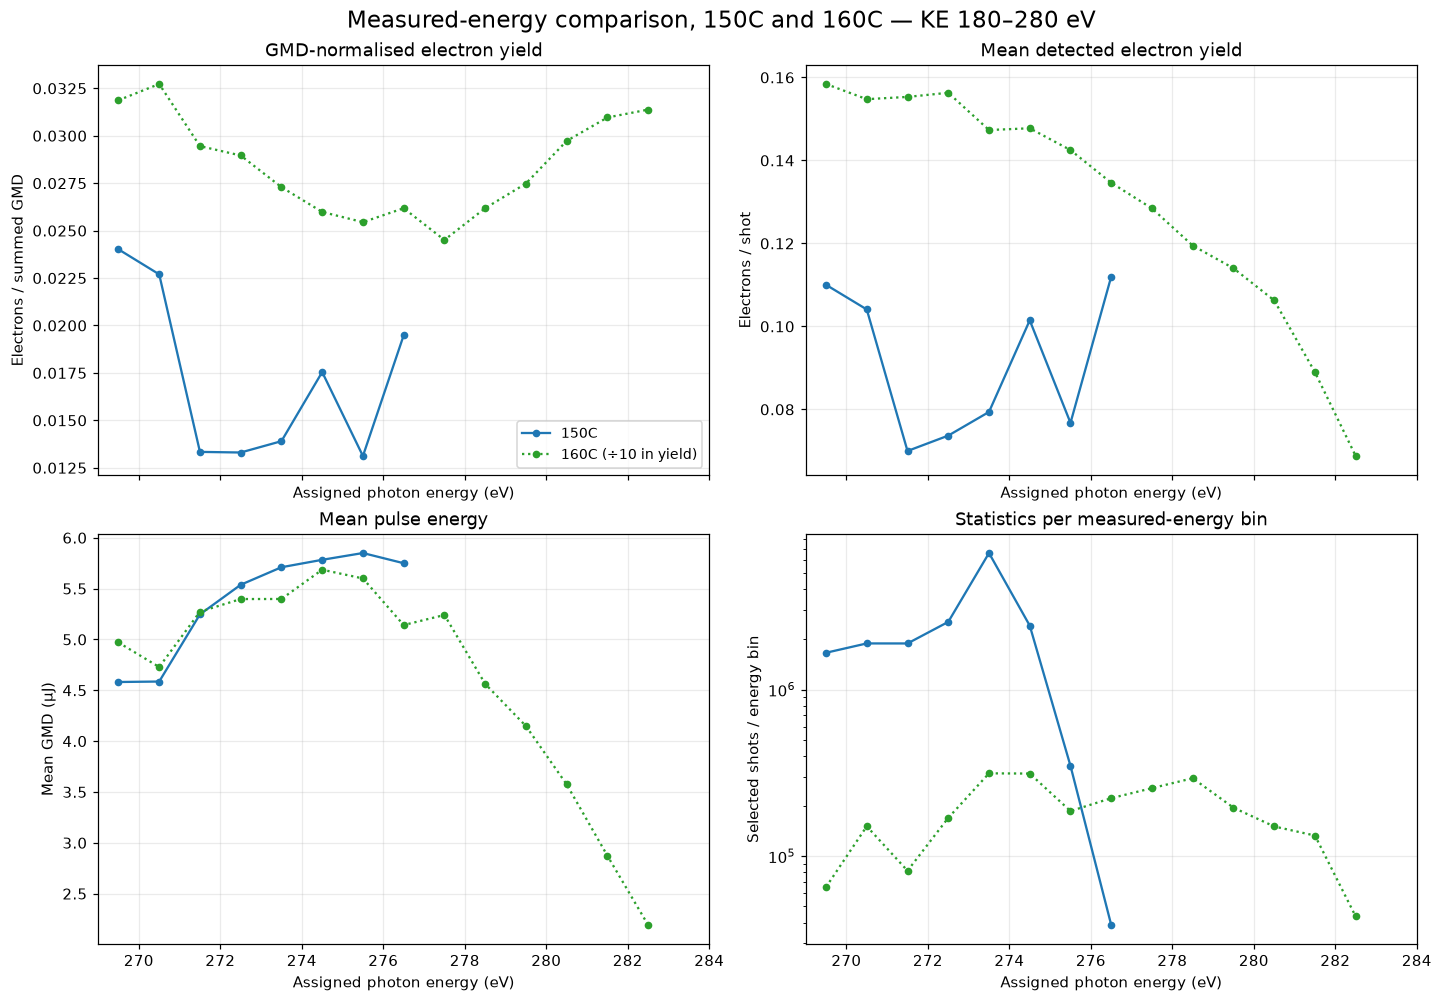

In [21]:

# --- Measured-energy diagnostics: 150 C versus 160 C --------------------

MPE_COMPARE_FAMILIES = ["150C", "160C"]
MPE_COMPARE_SCALE_160C = 10.0  # Display scaling for yield panels only

mpe_compare_centres = 0.5 * (mpe_stable_edges[:-1] + mpe_stable_edges[1:])
mpe_compare_results = {}

for family in MPE_COMPARE_FAMILIES:
    m = mpe_stable_maps[family]
    valid = np.asarray(m["valid_bins"], dtype=bool)
    shots = np.asarray(m["shots_per_bin"], dtype=float)
    sum_gmd = np.asarray(m["sum_gmd"], dtype=float)

    if m["ordinary"].shape != (len(mpe_compare_centres), len(ke_width_plot_prod2d)):
        raise ValueError(f"Unexpected map dimensions for {family}")

    # Integrate the existing KE-resolved spectrum over the selected KE range.
    e_per_gmd = np.sum(
        np.where(np.isfinite(m["ordinary"]), m["ordinary"], 0.0)
        * ke_width_plot_prod2d[None, :], axis=1
    )

    with np.errstate(invalid="ignore", divide="ignore"):
        e_per_shot = np.divide(e_per_gmd * sum_gmd, shots,
                               out=np.full_like(shots, np.nan), where=shots > 0)
        mean_gmd = np.divide(sum_gmd, shots,
                             out=np.full_like(shots, np.nan), where=shots > 0)

    mpe_compare_results[family] = {
        "e_per_gmd": np.where(valid, e_per_gmd, np.nan),
        "e_per_shot": np.where(valid, e_per_shot, np.nan),
        "mean_gmd": np.where(valid, mean_gmd, np.nan),
        "shots": np.where(valid, shots, np.nan),
    }

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, constrained_layout=True)

for family in MPE_COMPARE_FAMILIES:
    r = mpe_compare_results[family]
    color, ls = FAMILY_COLOURS[family], FAMILY_LINESTYLES[family]
    scale = MPE_COMPARE_SCALE_160C if family == "160C" else 1.0
    label = f"{family} (÷{scale:g} in yield)" if scale != 1 else family

    axes[0, 0].plot(mpe_compare_centres, r["e_per_gmd"] / scale,
                    "o-", color=color, ls=ls, ms=4, label=label)
    axes[0, 1].plot(mpe_compare_centres, r["e_per_shot"] / scale,
                    "o-", color=color, ls=ls, ms=4, label=label)
    axes[1, 0].plot(mpe_compare_centres, r["mean_gmd"],
                    "o-", color=color, ls=ls, ms=4, label=family)
    axes[1, 1].plot(mpe_compare_centres, r["shots"],
                    "o-", color=color, ls=ls, ms=4, label=family)

axes[0, 0].set(ylabel="Electrons / summed GMD", title="GMD-normalised electron yield")
axes[0, 1].set(ylabel="Electrons / shot", title="Mean detected electron yield")
axes[1, 0].set(ylabel="Mean GMD (µJ)", title="Mean pulse energy")
axes[1, 1].set(ylabel="Selected shots / energy bin", title="Statistics per measured-energy bin")
axes[1, 1].set_yscale("log")

for ax in axes.flat:
    ax.set_xlabel("Assigned photon energy (eV)")
    ax.set_xlim(mpe_stable_edges[0], mpe_stable_edges[-1])
    ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=9)
fig.suptitle(
    f"Measured-energy comparison, 150C and 160C — "
    f"KE {PROD2D_KE_RANGE[0]:g}–{PROD2D_KE_RANGE[1]:g} eV",
    fontsize=15
)
plt.show()


### MPE diagnostics


--- 147C HDF5 MPE metadata ---
Dataset attributes: {}
File attributes: {}
MPE shape / dtype: (27291,) float32

--- Monitor sampling by run ---
Family             Energy   Finite   Zeros   Valid  Pointing  Overlap  Median gap
150C                273.0    3,304       0   3,304     3,339    3,207        10.0
147C (7 June)       274.0      352     352       0     2,712      352         9.0
147C (7 June)       274.5      429     429       0     3,413      429       140.0
147C (7 June)       275.0      430     430       0     3,356      430       140.0
147C (7 June)       275.5      420     420       0     3,398      420       140.0
147C (7 June)       276.0      429     429       0     3,358      429       140.0
160C                273.0      181       0     181       285      171        10.0
160C                274.5      166       0     166       318      166        10.0


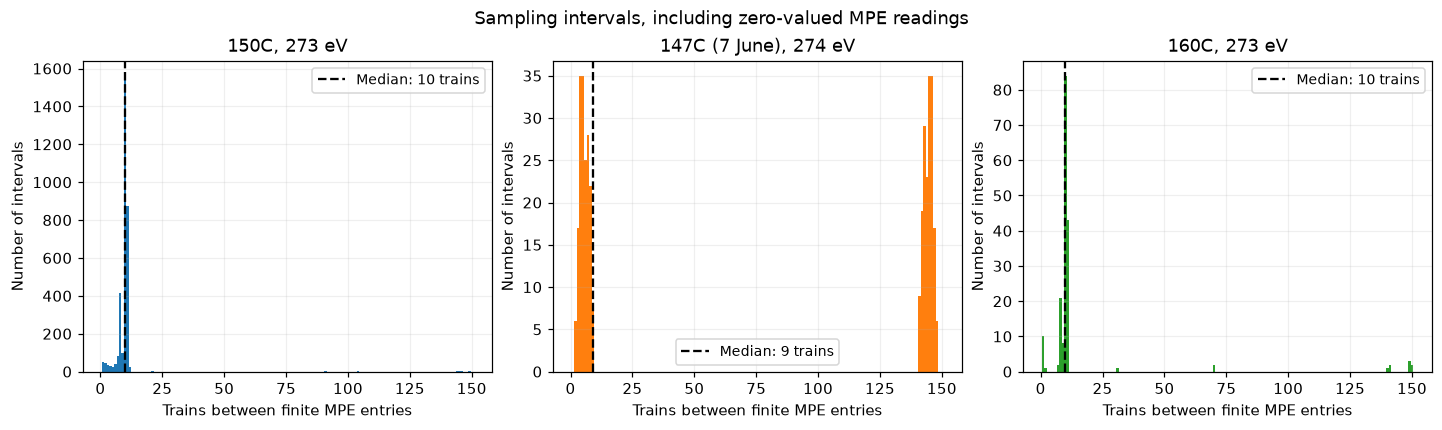

In [57]:


# --- MPE recording diagnostics: missing values, zeros and sampling ------

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

MPE_INSPECT_RUNS = {
    "150C": [273.0],
    "147C (7 June)": [274.0, 274.5, 275.0, 275.5, 276.0],
    "160C": [273.0, 274.5],
}

mpe_inspect_families = {
    "150C": prod2d_datasets,
    "147C (7 June)": j7_datasets,
    "160C": wl160_datasets,
}

mpe_inspect_results = {}

for family, energies in MPE_INSPECT_RUNS.items():
    for energy in energies:
        matches = [ds for ds in mpe_inspect_families[family] if np.isclose(ds["photon_energy_ev"], energy)]
        if len(matches) != 1:
            raise ValueError(f"Expected one {family} run at {energy:g} eV, found {len(matches)}")

        ds = matches[0]
        with h5py.File(ds["source_h5"], "r") as f:
            keep = keep_mask_like_compute_aggregates_from_h5(
                f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
            )
            mpe = np.asarray(f["mpe"][:], dtype=float)
            hor = np.asarray(f["hor_pos"][:], dtype=float)
            ver = np.asarray(f["ver_pos"][:], dtype=float)

            finite = keep & np.isfinite(mpe)
            zeros = finite & (mpe == 0)
            valid = finite & (mpe >= 250) & (mpe <= 310)
            pointing = keep & np.isfinite(hor) & np.isfinite(ver)

            indices = np.flatnonzero(finite)
            gaps = np.diff(indices)

            result = {
                "family": family, "energy": energy,
                "file": Path(ds["source_h5"]).name,
                "kept": int(keep.sum()),
                "finite": int(finite.sum()),
                "zeros": int(zeros.sum()),
                "valid": int(valid.sum()),
                "pointing": int(pointing.sum()),
                "overlap": int(np.count_nonzero(finite & pointing)),
                "indices": indices,
                "gaps": gaps,
            }
            mpe_inspect_results[(family, energy)] = result

            if family == "147C (7 June)" and energy == 274.0:
                print("\n--- 147C HDF5 MPE metadata ---")
                print("Dataset attributes:", dict(f["mpe"].attrs))
                print("File attributes:", {k: str(v)[:150] for k, v in f.attrs.items()})
                print("MPE shape / dtype:", f["mpe"].shape, f["mpe"].dtype)

print("\n--- Monitor sampling by run ---")
print(f"{'Family':17s} {'Energy':>7s} {'Finite':>8s} {'Zeros':>7s} {'Valid':>7s} {'Pointing':>9s} {'Overlap':>8s} {'Median gap':>11s}")

for r in mpe_inspect_results.values():
    median_gap = np.median(r["gaps"]) if r["gaps"].size else np.nan
    print(f"{r['family']:17s} {r['energy']:7.1f} {r['finite']:8,d} "
          f"{r['zeros']:7,d} {r['valid']:7,d} {r['pointing']:9,d} "
          f"{r['overlap']:8,d} {median_gap:11.1f}")

# --- Compare sampling intervals for one representative run per family ---

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)

for ax, family, energy in zip(
    axes, ("150C", "147C (7 June)", "160C"), (273.0, 274.0, 273.0)
):
    r = mpe_inspect_results[(family, energy)]
    gaps = r["gaps"]

    if gaps.size:
        ax.hist(gaps[gaps <= 150], bins=np.arange(0.5, 151.5, 1),
                color=FAMILY_COLOURS[family], edgecolor="none")
        ax.axvline(np.median(gaps), color="black", ls="--",
                   label=f"Median: {np.median(gaps):g} trains")
        ax.legend(fontsize=9)

    ax.set(title=f"{family}, {energy:g} eV",
           xlabel="Trains between finite MPE entries",
           ylabel="Number of intervals")
    ax.grid(alpha=0.2)

fig.suptitle("Sampling intervals, including zero-valued MPE readings")
plt.show()


### Disentangling particular run contributions

271 eV (long)    glycine_delay_scan_150C_long_271.0eV.h5
271.5 eV (long)  glycine_delay_scan_150C_long_271.5eV.h5
272 eV (long)    glycine_delay_scan_150C_long_272.0eV.h5
272.5 eV         glycine_delay_scan_150C_272.5eV.h5
273 eV           glycine_delay_scan_150C_273.0eV.h5
273.5 eV         glycine_delay_scan_150C_273.5eV.h5
274 eV           glycine_delay_scan_150C_274.0eV.h5
274.5 eV         glycine_delay_scan_150C_274.5eV.h5
275 eV           glycine_delay_scan_150C_275.0eV.h5

Assigned MPE interval: 274.00–275.00 eV
Selected shots: 2,418,587
Pooled electrons/GMD: 0.0175452

Nominal run            Shots   GMD share   Electrons/GMD
271 eV (long)            247       0.01%       0.0281385
271.5 eV (long)        2,867       0.09%        0.026189
272 eV (long)              0       0.00%             nan
272.5 eV              44,658       1.43%       0.0250718
273 eV               280,229      11.11%       0.0107714
273.5 eV             230,880       9.88%      0.00806817
274 eV            

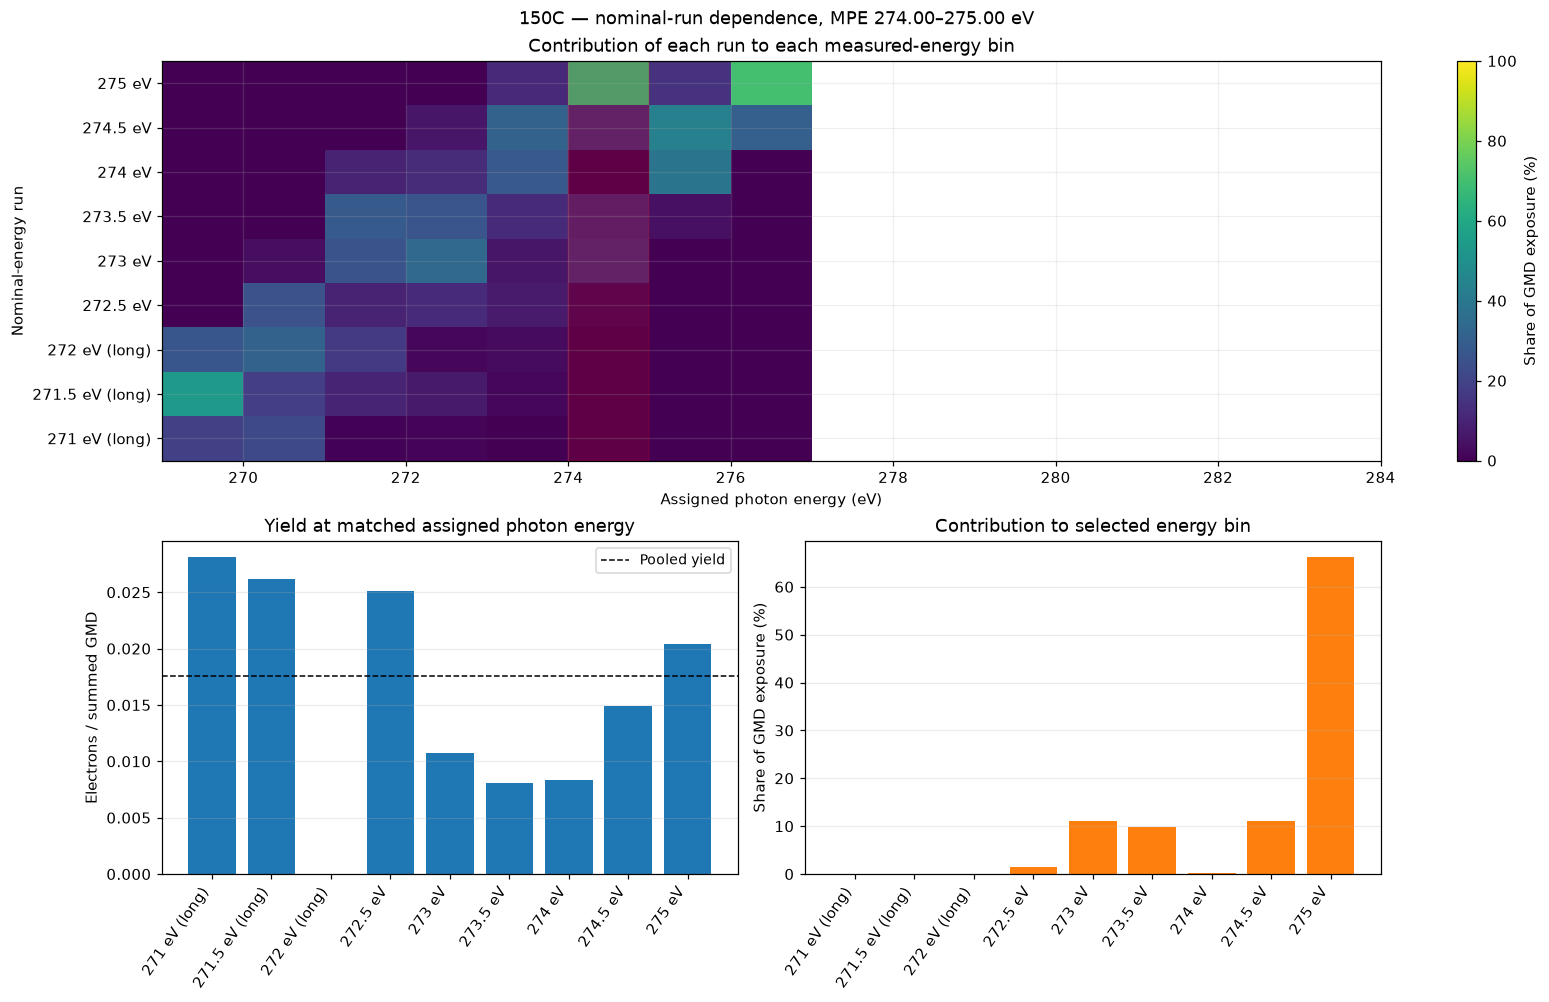

In [22]:

# --- Compare original runs within the same assigned MPE-energy bin ------

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

MPE_CONTRIB_FAMILY = "150C"        # "150C" or "160C"
MPE_CONTRIB_FOCUS_EV = 274.0       # Use the MPE bin containing this energy
MPE_CONTRIB_MIN_SHOTS = 200
MPE_CONTRIB_CHUNK_TRAINS = 100

contrib_families = {"150C": prod2d_datasets, "160C": wl160_datasets}
if MPE_CONTRIB_FAMILY not in contrib_families:
    raise ValueError("Choose '150C' or '160C'.")

contrib_datasets = contrib_families[MPE_CONTRIB_FAMILY]
contrib_edges = np.asarray(mpe_stable_edges, dtype=float)
n_bins = len(contrib_edges) - 1
focus_bin = int(np.searchsorted(contrib_edges, MPE_CONTRIB_FOCUS_EV, side="right") - 1)

if not 0 <= focus_bin < n_bins:
    raise ValueError("Selected energy is outside the MPE map.")
if MPE_STABLE_MODE not in ("stable_hold", "measured_only"):
    raise ValueError("Unknown MPE_STABLE_MODE.")

# Exact TOF/KE selection used in the existing production maps.
tof_low, tof_high = PROD2D_TOF_RANGE
valid_ke_tof = np.asarray(
    ke_select_prod2d[::-1] if reverse_ke_prod2d else ke_select_prod2d,
    dtype=bool
)
if len(valid_ke_tof) != tof_high - tof_low + 1:
    raise ValueError("TOF/KE mask dimensions do not match.")

n_runs = len(contrib_datasets)
contrib_counts = np.zeros((n_runs, n_bins), dtype=np.int64)
contrib_gmd = np.zeros((n_runs, n_bins), dtype=float)
contrib_shots = np.zeros((n_runs, n_bins), dtype=np.int64)
contrib_labels = []

for run_i, ds in enumerate(contrib_datasets):
    source = Path(ds["source_h5"])
    run_label = f"{ds['photon_energy_ev']:g} eV" + (" (long)" if "_long_" in source.name else "")
    contrib_labels.append(run_label)

    with h5py.File(source, "r") as f:
        n_trains, n_bunches = f["gmd"].shape
        if f["mpe"].shape != (n_trains,) or f["tofs_e"].shape[:2] != (n_trains, n_bunches):
            raise ValueError(f"Unexpected MPE/GMD/eTOF dimensions: {source.name}")

        keep = keep_mask_like_compute_aggregates_from_h5(
            f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        mpe = np.asarray(f["mpe"][:], dtype=float)
        valid_measured = (
            keep & np.isfinite(mpe)
            & (mpe >= MPE_STABLE_VALID_RANGE_EV[0])
            & (mpe <= MPE_STABLE_VALID_RANGE_EV[1])
        )

        assigned = np.full(n_trains, np.nan)
        assigned[valid_measured] = mpe[valid_measured]

        # Same stable-interval assignment as the combined MPE map.
        if MPE_STABLE_MODE == "stable_hold":
            valid_idx = np.flatnonzero(valid_measured)
            for left, right in zip(valid_idx[:-1], valid_idx[1:]):
                if (right - left <= MPE_STABLE_GAP_TRAINS
                        and abs(mpe[right] - mpe[left]) <= MPE_STABLE_MAX_STEP_EV
                        and np.all(keep[left:right + 1])):
                    assigned[left + 1:right] = mpe[left]

        assigned_ok = (
            np.isfinite(assigned)
            & (assigned >= contrib_edges[0])
            & (assigned < contrib_edges[-1])
        )

        for start in range(0, n_trains, MPE_CONTRIB_CHUNK_TRAINS):
            stop = min(start + MPE_CONTRIB_CHUNK_TRAINS, n_trains)
            rows = np.flatnonzero(assigned_ok[start:stop])
            if not rows.size:
                continue

            e_bins = np.searchsorted(contrib_edges, assigned[start:stop][rows], side="right") - 1
            gmd = np.asarray(f["gmd"][start:stop][rows], dtype=float)
            good = (
                np.isfinite(gmd)
                & (gmd >= MPE_STABLE_GMD_RANGE[0])
                & (gmd < MPE_STABLE_GMD_RANGE[1])
            )
            if not np.any(good):
                continue

            tofs = f["tofs_e"][start:stop][rows]
            train_idx, _ = np.nonzero(good)
            shot_bins = e_bins[train_idx]
            shot_gmd = gmd[good]
            shots_tof = tofs[good]

            # Count electrons in exactly the KE bins of the production map.
            hits_valid = (shots_tof >= tof_low) & (shots_tof <= tof_high)
            hits_selected = np.zeros(hits_valid.shape, dtype=bool)
            hits_selected[hits_valid] = valid_ke_tof[
                shots_tof[hits_valid].astype(np.int64) - tof_low
            ]
            shot_counts = np.count_nonzero(hits_selected, axis=1)

            np.add.at(contrib_counts[run_i], shot_bins, shot_counts)
            np.add.at(contrib_gmd[run_i], shot_bins, shot_gmd)
            np.add.at(contrib_shots[run_i], shot_bins, 1)

    print(f"{run_label:16s} {source.name}")

# --- Contributions and yields -------------------------------------------

bin_gmd_total = contrib_gmd.sum(axis=0)
bin_shots_total = contrib_shots.sum(axis=0)
share = np.divide(
    contrib_gmd, bin_gmd_total[None, :],
    out=np.zeros_like(contrib_gmd),
    where=bin_gmd_total[None, :] > 0
)

focus_counts = contrib_counts[:, focus_bin]
focus_gmd = contrib_gmd[:, focus_bin]
focus_shots = contrib_shots[:, focus_bin]

valid_run = (focus_shots >= MPE_CONTRIB_MIN_SHOTS) & (focus_gmd > 0)
run_yield = np.divide(
    focus_counts, focus_gmd,
    out=np.full(n_runs, np.nan),
    where=valid_run
)

if focus_gmd.sum() <= 0:
    raise ValueError("No selected shots in the chosen measured-energy bin.")

pooled_yield = focus_counts.sum() / focus_gmd.sum()

print(f"\nAssigned MPE interval: {contrib_edges[focus_bin]:.2f}–{contrib_edges[focus_bin+1]:.2f} eV")
print(f"Selected shots: {focus_shots.sum():,}")
print(f"Pooled electrons/GMD: {pooled_yield:.6g}")
print(f"\n{'Nominal run':18s} {'Shots':>9s} {'GMD share':>11s} {'Electrons/GMD':>15s}")

for name, shots, fraction, value in zip(contrib_labels, focus_shots, share[:, focus_bin], run_yield):
    print(f"{name:18s} {shots:9,d} {100*fraction:10.2f}% {value:15.6g}")

# Check consistency with the previously reconstructed map.
previous = mpe_stable_maps[MPE_CONTRIB_FAMILY]
if previous["valid_bins"][focus_bin]:
    previous_yield = np.sum(previous["ordinary"][focus_bin] * ke_width_plot_prod2d)
    print(f"\nPrevious map yield: {previous_yield:.6g}")
    print(f"Difference: {pooled_yield - previous_yield:+.3g}")
    if not np.isclose(pooled_yield, previous_yield, rtol=1e-5, atol=1e-10):
        print("WARNING: reconstructed yield differs. Check dataset selection and MPE settings.")

# --- Figures ------------------------------------------------------------

fig = plt.figure(figsize=(14, 9), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=(1.2, 1))
ax_map = fig.add_subplot(gs[0, :])
ax_yield = fig.add_subplot(gs[1, 0])
ax_share = fig.add_subplot(gs[1, 1])
x = np.arange(n_runs)

empty_bins = np.broadcast_to(bin_shots_total[None, :] < MPE_STABLE_MIN_SHOTS_BIN, share.shape)
heatmap = np.ma.masked_where(empty_bins, 100 * share)

im = ax_map.pcolormesh(
    contrib_edges, np.arange(n_runs + 1), heatmap,
    shading="flat", vmin=0, vmax=100
)
ax_map.set_yticks(x + 0.5, contrib_labels)
ax_map.set(xlabel="Assigned photon energy (eV)", ylabel="Nominal-energy run",
           title="Contribution of each run to each measured-energy bin")
ax_map.axvspan(contrib_edges[focus_bin], contrib_edges[focus_bin + 1],
               color="red", alpha=0.15)
fig.colorbar(im, ax=ax_map, label="Share of GMD exposure (%)")

ax_yield.bar(x[valid_run], run_yield[valid_run], color="tab:blue")
ax_yield.axhline(pooled_yield, ls="--", color="black", lw=1, label="Pooled yield")
ax_yield.set(ylabel="Electrons / summed GMD", title="Yield at matched assigned photon energy")
ax_yield.legend(fontsize=9)

ax_share.bar(x, 100 * share[:, focus_bin], color="tab:orange")
ax_share.set(ylabel="Share of GMD exposure (%)", title="Contribution to selected energy bin")

for ax in (ax_yield, ax_share):
    ax.set_xticks(x, contrib_labels, rotation=55, ha="right")
    ax.grid(axis="y", alpha=0.25)

ax_map.grid(alpha=0.2)
fig.suptitle(
    f"{MPE_CONTRIB_FAMILY} — nominal-run dependence, "
    f"MPE {contrib_edges[focus_bin]:.2f}–{contrib_edges[focus_bin+1]:.2f} eV"
)
plt.show()



150C: MPE 272.5-272.8 eV
Assignment: stable_hold

--- GMD 3-4 uJ ---
Nominal run            Shots  Electrons       E/GMD   Mean GMD   Mean MPE  Direct %
271 eV (long)          3,560        366    0.029554      3.479   272.5766      13.5
271.5 eV (long)        3,781        314    0.023868      3.479   272.6447      26.9
272 eV (long)          1,936         82    0.012213      3.468   272.6578      16.2
272.5 eV              24,564      2,138    0.025022      3.478   272.6494      16.3
273 eV                30,714      1,067    0.009947      3.492   272.7059      13.7
273.5 eV              33,740        995    0.008426      3.500   272.6580      14.2
274 eV                 4,805        150    0.008916      3.501   272.6859      20.7
274.5 eV               4,785        292    0.017480      3.491   272.5656      13.0
275 eV                   884         57    0.018367      3.511   272.6704      15.5
Maximum / minimum yield (shown runs): 3.507

--- GMD 5-6 uJ ---
Nominal run            Sho

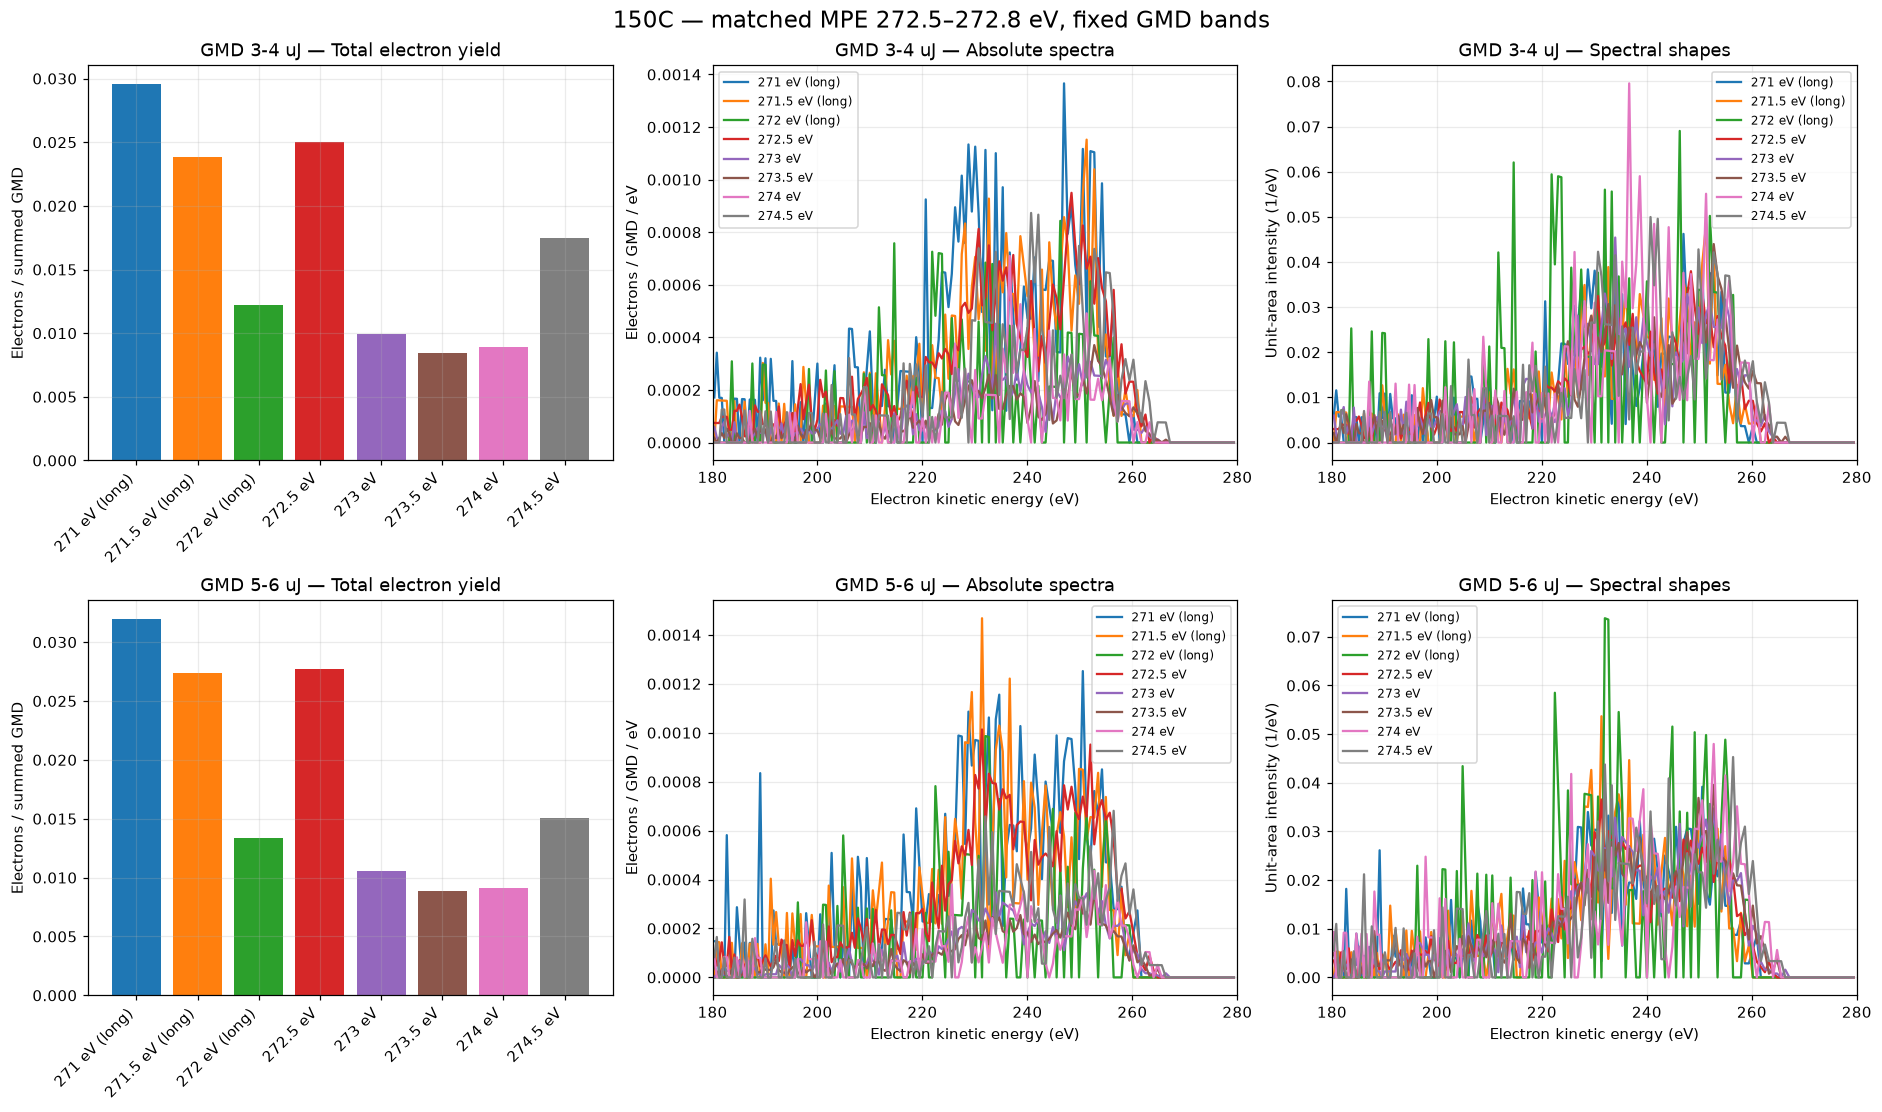

In [22]:

# --- Matched MPE and fixed GMD bands: run yields and spectral shapes -----

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

MATCH_BAND_FAMILY = "150C"                  # "150C" or "160C"
MATCH_BAND_MPE_RANGE_EV = (272.5, 272.8)
MATCH_BAND_GMD_BANDS = {"3-4 uJ": (3.0, 4.0), "5-6 uJ": (5.0, 6.0)}
MATCH_BAND_ASSIGNMENT = "stable_hold"      # "measured_only" or "stable_hold"
MATCH_BAND_MIN_SHOTS = 1000
MATCH_BAND_MAX_GAP_TRAINS = 12
MATCH_BAND_MAX_STEP_EV = 0.10
MATCH_BAND_VALID_MPE_RANGE = (250.0, 310.0)
MATCH_BAND_CHUNK_TRAINS = 100

match_band_families = {"150C": prod2d_datasets, "160C": wl160_datasets}

if MATCH_BAND_ASSIGNMENT not in ("measured_only", "stable_hold"):
    raise ValueError("Invalid MPE assignment mode.")
if MATCH_BAND_MPE_RANGE_EV[0] >= MATCH_BAND_MPE_RANGE_EV[1]:
    raise ValueError("Invalid MPE range.")

match_band_results = {band: [] for band in MATCH_BAND_GMD_BANDS}
n_tof_bins = len(tof_edges_prod2d) - 1

for ds in match_band_families[MATCH_BAND_FAMILY]:
    source = Path(ds["source_h5"])
    run_label = f"{ds['photon_energy_ev']:g} eV"
    if "_long_" in source.name:
        run_label += " (long)"

    accum = {
        band: {"shots": 0, "gmd": 0.0, "energy_gmd": 0.0,
               "measured_shots": 0, "tof_counts": np.zeros(n_tof_bins, dtype=np.int64)}
        for band in MATCH_BAND_GMD_BANDS
    }

    with h5py.File(source, "r") as f:
        n_trains, n_bunches = f["gmd"].shape
        if f["mpe"].shape != (n_trains,) or f["tofs_e"].shape[:2] != (n_trains, n_bunches):
            raise ValueError(f"Unexpected HDF5 dimensions: {source.name}")

        keep = keep_mask_like_compute_aggregates_from_h5(
            f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        mpe = np.asarray(f["mpe"][:], dtype=float)
        valid_mpe = (
            keep & np.isfinite(mpe)
            & (mpe >= MATCH_BAND_VALID_MPE_RANGE[0])
            & (mpe <= MATCH_BAND_VALID_MPE_RANGE[1])
        )

        assigned = np.full(n_trains, np.nan)
        assigned[valid_mpe] = mpe[valid_mpe]

        if MATCH_BAND_ASSIGNMENT == "stable_hold":
            idx = np.flatnonzero(valid_mpe)
            for left, right in zip(idx[:-1], idx[1:]):
                if (right - left <= MATCH_BAND_MAX_GAP_TRAINS
                        and abs(mpe[right] - mpe[left]) <= MATCH_BAND_MAX_STEP_EV
                        and np.all(keep[left:right + 1])):
                    assigned[left + 1:right] = mpe[left]

        selected_energy = (
            keep & np.isfinite(assigned)
            & (assigned >= MATCH_BAND_MPE_RANGE_EV[0])
            & (assigned < MATCH_BAND_MPE_RANGE_EV[1])
        )

        for start in range(0, n_trains, MATCH_BAND_CHUNK_TRAINS):
            stop = min(start + MATCH_BAND_CHUNK_TRAINS, n_trains)
            rows = np.flatnonzero(selected_energy[start:stop])
            if not rows.size:
                continue

            gmd = np.asarray(f["gmd"][start:stop][rows], dtype=float)
            energy = assigned[start:stop][rows]
            directly_measured = valid_mpe[start:stop][rows]

            band_masks = {
                band: np.isfinite(gmd) & (gmd >= lo) & (gmd < hi)
                for band, (lo, hi) in MATCH_BAND_GMD_BANDS.items()
            }
            if not any(np.any(mask) for mask in band_masks.values()):
                continue

            tofs = f["tofs_e"][start:stop][rows]

            for band, selected in band_masks.items():
                if not np.any(selected):
                    continue

                train_idx, _ = np.nonzero(selected)
                shot_gmd = gmd[selected]
                shot_energy = energy[train_idx]
                a = accum[band]

                a["shots"] += len(shot_gmd)
                a["gmd"] += float(np.sum(shot_gmd))
                a["energy_gmd"] += float(np.sum(shot_gmd * shot_energy))
                a["measured_shots"] += int(np.count_nonzero(directly_measured[train_idx]))

                events = tofs[selected].reshape(-1)
                valid_hits = (
                    (events >= PROD2D_TOF_RANGE[0])
                    & (events <= PROD2D_TOF_RANGE[1])
                )
                a["tof_counts"] += np.histogram(
                    events[valid_hits], bins=tof_edges_prod2d
                )[0]

    for band, a in accum.items():
        counts = a["tof_counts"][::-1] if reverse_ke_prod2d else a["tof_counts"]
        counts_ke = counts[ke_select_prod2d]
        electrons = int(np.sum(counts_ke))
        gmd_total = a["gmd"]
        yield_gmd = electrons / gmd_total if gmd_total > 0 else np.nan

        if gmd_total > 0:
            spectrum = counts_ke / gmd_total / ke_width_plot_prod2d
            shape = spectrum / yield_gmd if yield_gmd > 0 else np.full_like(spectrum, np.nan)
        else:
            spectrum = np.full(len(ke_plot_prod2d), np.nan)
            shape = np.full_like(spectrum, np.nan)

        match_band_results[band].append({
            "name": run_label,
            "file": source.name,
            "shots": a["shots"],
            "electrons": electrons,
            "sum_gmd": gmd_total,
            "mean_gmd": gmd_total / a["shots"] if a["shots"] else np.nan,
            "mean_mpe": a["energy_gmd"] / gmd_total if gmd_total > 0 else np.nan,
            "direct_fraction": a["measured_shots"] / a["shots"] if a["shots"] else np.nan,
            "yield_gmd": yield_gmd,
            "spectrum": spectrum,
            "shape": shape,
        })

# --- Print statistics for both GMD bands --------------------------------

print(f"\n{MATCH_BAND_FAMILY}: MPE {MATCH_BAND_MPE_RANGE_EV[0]:g}-{MATCH_BAND_MPE_RANGE_EV[1]:g} eV")
print(f"Assignment: {MATCH_BAND_ASSIGNMENT}")

for band, results in match_band_results.items():
    print(f"\n--- GMD {band} ---")
    print(f"{'Nominal run':17s} {'Shots':>10s} {'Electrons':>10s} {'E/GMD':>11s} {'Mean GMD':>10s} {'Mean MPE':>10s} {'Direct %':>9s}")

    for r in results:
        print(f"{r['name']:17s} {r['shots']:10,d} {r['electrons']:10,d} "
              f"{r['yield_gmd']:11.6f} {r['mean_gmd']:10.3f} "
              f"{r['mean_mpe']:10.4f} {100*r['direct_fraction']:9.1f}")

    shown = [r for r in results if r["shots"] >= MATCH_BAND_MIN_SHOTS and r["electrons"] > 0]
    if len(shown) >= 2:
        yields = np.array([r["yield_gmd"] for r in shown])
        print(f"Maximum / minimum yield (shown runs): {yields.max() / yields.min():.3f}")
    else:
        print("Fewer than two runs meet the minimum-shot requirement.")

# --- Plot: one row per GMD band -----------------------------------------

fig, axes = plt.subplots(
    len(MATCH_BAND_GMD_BANDS), 3,
    figsize=(17, 5 * len(MATCH_BAND_GMD_BANDS)),
    squeeze=False, constrained_layout=True
)

run_names = [r["name"] for r in next(iter(match_band_results.values()))]
run_colors = {name: plt.get_cmap("tab10")(i % 10) for i, name in enumerate(run_names)}

for row, (band, results) in enumerate(match_band_results.items()):
    shown = [r for r in results if r["shots"] >= MATCH_BAND_MIN_SHOTS and r["electrons"] > 0]

    if not shown:
        for ax in axes[row]:
            ax.text(0.5, 0.5, "No runs meet minimum shots",
                    transform=ax.transAxes, ha="center", va="center")
            ax.grid(alpha=0.25)
        continue

    x = np.arange(len(shown))
    colors = [run_colors[r["name"]] for r in shown]

    axes[row, 0].bar(x, [r["yield_gmd"] for r in shown], color=colors)
    axes[row, 0].set_xticks(x, [r["name"] for r in shown], rotation=45, ha="right")
    axes[row, 0].set_ylabel("Electrons / summed GMD")
    axes[row, 0].set_title(f"GMD {band} — Total electron yield")

    for r in shown:
        c = run_colors[r["name"]]
        axes[row, 1].plot(ke_plot_prod2d, r["spectrum"], color=c, lw=1.5, label=r["name"])
        axes[row, 2].plot(ke_plot_prod2d, r["shape"], color=c, lw=1.5, label=r["name"])

    axes[row, 1].set(
        xlabel="Electron kinetic energy (eV)",
        ylabel="Electrons / GMD / eV",
        title=f"GMD {band} — Absolute spectra"
    )
    axes[row, 2].set(
        xlabel="Electron kinetic energy (eV)",
        ylabel="Unit-area intensity (1/eV)",
        title=f"GMD {band} — Spectral shapes"
    )

    for ax in axes[row, 1:]:
        ax.set_xlim(PROD2D_KE_RANGE)
        ax.legend(fontsize=8)

    for ax in axes[row]:
        ax.grid(alpha=0.25)

fig.suptitle(
    f"{MATCH_BAND_FAMILY} — matched MPE {MATCH_BAND_MPE_RANGE_EV[0]:g}–"
    f"{MATCH_BAND_MPE_RANGE_EV[1]:g} eV, fixed GMD bands",
    fontsize=15
)
plt.show()



### Presentation figure

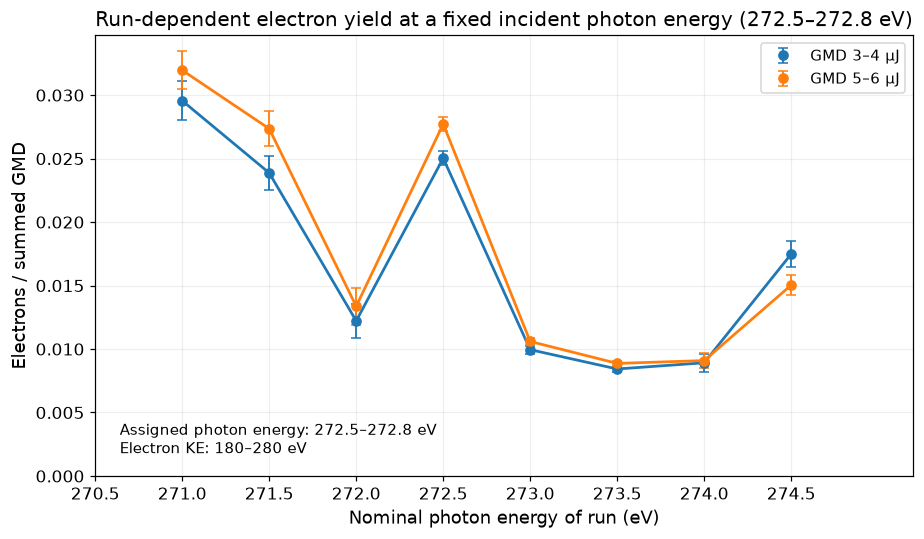

In [56]:

# --- Run-dependent electron yield: presentation figure ------------------

PLOT_MIN_SHOTS = 1000
PLOT_NOMINAL_RANGE_EV = (270.5, 275.0)

fig, ax = plt.subplots(figsize=(8.5, 5))

band_colors = {"3-4 uJ": "tab:blue", "5-6 uJ": "tab:orange"}

for band, results in match_band_results.items():
    selected = sorted(
        [r for r in results if PLOT_NOMINAL_RANGE_EV[0] <= float(r["name"].split()[0]) <= PLOT_NOMINAL_RANGE_EV[1]],
        key=lambda r: float(r["name"].split()[0])
    )

    x = np.array([float(r["name"].split()[0]) for r in selected])
    valid = np.array([r["shots"] >= PLOT_MIN_SHOTS and r["electrons"] > 0 and r["sum_gmd"] > 0 for r in selected])
    y = np.array([r["yield_gmd"] if ok else np.nan for r, ok in zip(selected, valid)])
    yerr = np.array([np.sqrt(r["electrons"]) / r["sum_gmd"] if ok else np.nan for r, ok in zip(selected, valid)])

    color = band_colors[band]
    label = band.replace("-", "–").replace("uJ", "µJ")

    ax.plot(x, y, "-", color=color, lw=1.8)
    ax.errorbar(x[valid], y[valid], yerr=yerr[valid], fmt="o", color=color,
                markersize=6, capsize=3, elinewidth=1.2, label=f"GMD {label}")

ax.set_xlabel("Nominal photon energy of run (eV)", fontsize=12)
ax.set_ylabel("Electrons / summed GMD", fontsize=12)
ax.set_title(f"Run-dependent electron yield at a fixed incident photon energy ({MATCH_BAND_MPE_RANGE_EV[0]:.1f}–{MATCH_BAND_MPE_RANGE_EV[1]:.1f} eV)", fontsize=13)
ax.set_xlim(272.3, 275.2)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(*PLOT_NOMINAL_RANGE_EV, 0.5))
ax.tick_params(axis="both", labelsize=11)
ax.grid(alpha=0.2)
ax.legend(fontsize=10)

ax.text(
    0.03, 0.04,
    f"Assigned photon energy: {MATCH_BAND_MPE_RANGE_EV[0]:.1f}–{MATCH_BAND_MPE_RANGE_EV[1]:.1f} eV\n"
    "Electron KE: 180–280 eV",
    transform=ax.transAxes, fontsize=10, va="bottom"
)

plt.tight_layout()
plt.show()



150C matched selection
MPE range: 272.5–272.8 eV
GMD band : 3.0–4.0 µJ
Assignment: stable_hold
Minimum shots for plotting: 1000

 Nominal     Shots  Electrons      E/GMD   Hor mean   Ver mean
   271.0     3,560        366   0.029554   -0.23572   -0.78943
   271.5     3,781        314   0.023868   -0.28281   -0.77716
   272.0     1,936         82   0.012213   -0.30442   -0.74793
   272.5    24,564      2,138   0.025022   -0.16960   -0.80198
   273.0    30,714      1,067   0.009947    0.08774   -0.87994
   273.5    33,740        995   0.008426    0.00702   -0.89193
   274.0     4,805        150   0.008916   -0.00621   -0.88238
   274.5     4,785        292   0.017480   -0.01584   -0.87508
   275.0       884         57   0.018367   -0.02690   -0.80371


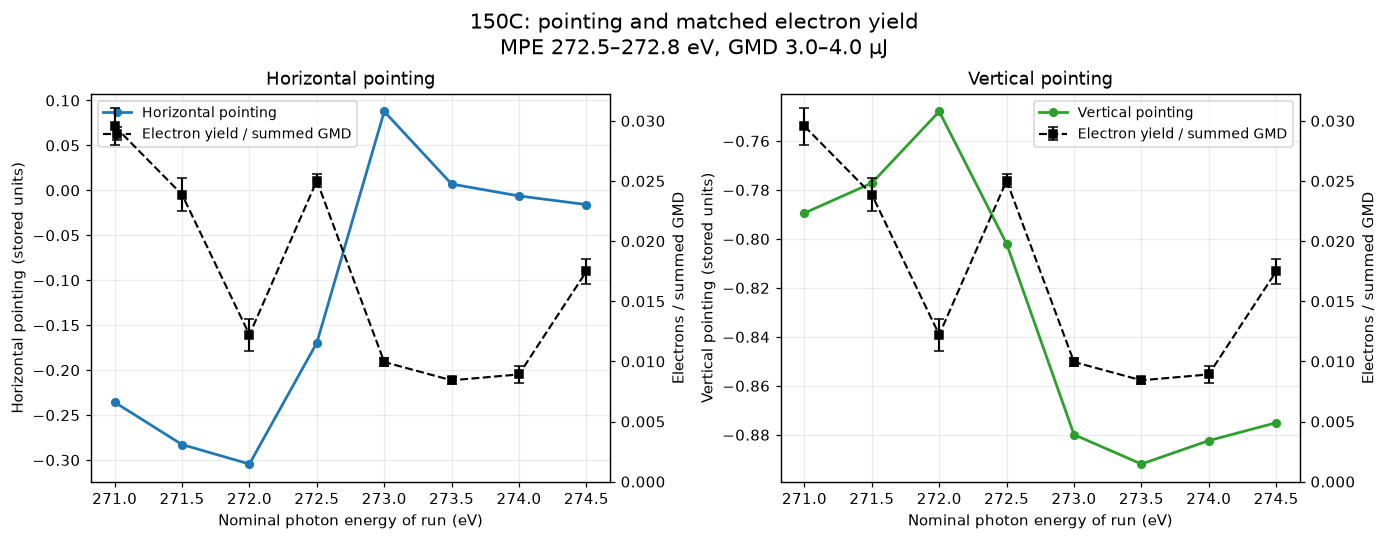

In [35]:
# --- 150 C: pointing versus matched-yield overlay ------------------------

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

POINT_YIELD_MPE_RANGE_EV = (272.5, 272.8)
POINT_YIELD_GMD_BAND = (3.0, 4.0)          # e.g. (3.0, 4.0) or (5.0, 6.0)
POINT_YIELD_ASSIGNMENT = "stable_hold"     # "stable_hold" or "measured_only"
POINT_YIELD_MIN_SHOTS = 1000
POINT_YIELD_VALID_MPE_RANGE = (250.0, 310.0)
POINT_YIELD_MAX_GAP_TRAINS = 12
POINT_YIELD_MAX_STEP_EV = 0.10
POINT_YIELD_CHUNK_TRAINS = 100

point_yield_datasets = prod2d_datasets

tof_low, tof_high = PROD2D_TOF_RANGE
valid_ke_tof = np.asarray(
    ke_select_prod2d[::-1] if reverse_ke_prod2d else ke_select_prod2d,
    dtype=bool
)
if len(valid_ke_tof) != tof_high - tof_low + 1:
    raise ValueError("TOF/KE mask dimensions do not match PROD2D_TOF_RANGE.")

point_yield_rows = []

for ds in point_yield_datasets:
    source = Path(ds["source_h5"])

    with h5py.File(source, "r") as f:
        n_trains, n_bunches = f["gmd"].shape
        if f["mpe"].shape != (n_trains,) or f["tofs_e"].shape[:2] != (n_trains, n_bunches):
            raise ValueError(f"Unexpected HDF5 shapes: {source.name}")

        keep = keep_mask_like_compute_aggregates_from_h5(
            f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )

        mpe = np.asarray(f["mpe"][:], dtype=float)
        hor_pos = np.asarray(f["hor_pos"][:], dtype=float)
        ver_pos = np.asarray(f["ver_pos"][:], dtype=float)

        valid_mpe = (
            keep & np.isfinite(mpe)
            & (mpe >= POINT_YIELD_VALID_MPE_RANGE[0])
            & (mpe <= POINT_YIELD_VALID_MPE_RANGE[1])
        )

        assigned = np.full(n_trains, np.nan)
        assigned[valid_mpe] = mpe[valid_mpe]

        if POINT_YIELD_ASSIGNMENT == "stable_hold":
            idx = np.flatnonzero(valid_mpe)
            for left, right in zip(idx[:-1], idx[1:]):
                if (right - left <= POINT_YIELD_MAX_GAP_TRAINS
                        and abs(mpe[right] - mpe[left]) <= POINT_YIELD_MAX_STEP_EV
                        and np.all(keep[left:right + 1])):
                    assigned[left + 1:right] = mpe[left]
        elif POINT_YIELD_ASSIGNMENT != "measured_only":
            raise ValueError("POINT_YIELD_ASSIGNMENT must be 'stable_hold' or 'measured_only'.")

        selected_energy = (
            keep & np.isfinite(assigned)
            & (assigned >= POINT_YIELD_MPE_RANGE_EV[0])
            & (assigned < POINT_YIELD_MPE_RANGE_EV[1])
        )

        total_shots = 0
        total_gmd = 0.0
        total_electrons = 0

        hor_wsum = 0.0
        hor_wx = 0.0
        ver_wsum = 0.0
        ver_wx = 0.0

        for start in range(0, n_trains, POINT_YIELD_CHUNK_TRAINS):
            stop = min(start + POINT_YIELD_CHUNK_TRAINS, n_trains)
            rows = np.flatnonzero(selected_energy[start:stop])
            if not rows.size:
                continue

            gmd_block = np.asarray(f["gmd"][start:stop][rows], dtype=float)
            shot_selected = (
                np.isfinite(gmd_block)
                & (gmd_block >= POINT_YIELD_GMD_BAND[0])
                & (gmd_block < POINT_YIELD_GMD_BAND[1])
            )
            if not np.any(shot_selected):
                continue

            # Per-train number of selected shots in this chunk
            shots_per_train = np.count_nonzero(shot_selected, axis=1)
            total_shots += int(np.sum(shots_per_train))
            total_gmd += float(np.sum(gmd_block[shot_selected]))

            # Pointing means, weighted by number of selected shots per train
            hor_chunk = hor_pos[start:stop][rows]
            ver_chunk = ver_pos[start:stop][rows]

            hor_mask = (shots_per_train > 0) & np.isfinite(hor_chunk)
            ver_mask = (shots_per_train > 0) & np.isfinite(ver_chunk)

            if np.any(hor_mask):
                w = shots_per_train[hor_mask].astype(float)
                hor_wsum += float(np.sum(w))
                hor_wx += float(np.sum(w * hor_chunk[hor_mask]))

            if np.any(ver_mask):
                w = shots_per_train[ver_mask].astype(float)
                ver_wsum += float(np.sum(w))
                ver_wx += float(np.sum(w * ver_chunk[ver_mask]))

            # Electron counting in the same KE range used previously
            tofs_block = f["tofs_e"][start:stop][rows]
            shot_tofs = tofs_block[shot_selected]          # shape: (n_selected_shots, 50)
            hits = shot_tofs.reshape(-1)

            valid_hits = (hits >= tof_low) & (hits <= tof_high)
            hit_idx = hits[valid_hits].astype(np.int64) - tof_low
            total_electrons += int(np.count_nonzero(valid_ke_tof[hit_idx]))

    nominal_energy = float(ds["photon_energy_ev"])
    mean_hor = hor_wx / hor_wsum if hor_wsum > 0 else np.nan
    mean_ver = ver_wx / ver_wsum if ver_wsum > 0 else np.nan
    yield_gmd = total_electrons / total_gmd if total_gmd > 0 else np.nan
    yield_err = np.sqrt(total_electrons) / total_gmd if total_electrons > 0 and total_gmd > 0 else np.nan

    point_yield_rows.append({
        "nominal_energy": nominal_energy,
        "file": source.name,
        "shots": total_shots,
        "electrons": total_electrons,
        "sum_gmd": total_gmd,
        "mean_hor": mean_hor,
        "mean_ver": mean_ver,
        "yield_gmd": yield_gmd,
        "yield_err": yield_err,
    })

point_yield_rows = sorted(point_yield_rows, key=lambda r: r["nominal_energy"])

print(f"\n150C matched selection")
print(f"MPE range: {POINT_YIELD_MPE_RANGE_EV[0]:.1f}–{POINT_YIELD_MPE_RANGE_EV[1]:.1f} eV")
print(f"GMD band : {POINT_YIELD_GMD_BAND[0]:.1f}–{POINT_YIELD_GMD_BAND[1]:.1f} µJ")
print(f"Assignment: {POINT_YIELD_ASSIGNMENT}")
print(f"Minimum shots for plotting: {POINT_YIELD_MIN_SHOTS}\n")
print(f"{'Nominal':>8} {'Shots':>9} {'Electrons':>10} {'E/GMD':>10} {'Hor mean':>10} {'Ver mean':>10}")
for r in point_yield_rows:
    print(f"{r['nominal_energy']:8.1f} {r['shots']:9,d} {r['electrons']:10,d} "
          f"{r['yield_gmd']:10.6f} {r['mean_hor']:10.5f} {r['mean_ver']:10.5f}")

x = np.array([r["nominal_energy"] for r in point_yield_rows], dtype=float)
shots = np.array([r["shots"] for r in point_yield_rows], dtype=float)
mean_hor = np.array([r["mean_hor"] if r["shots"] >= POINT_YIELD_MIN_SHOTS else np.nan for r in point_yield_rows], dtype=float)
mean_ver = np.array([r["mean_ver"] if r["shots"] >= POINT_YIELD_MIN_SHOTS else np.nan for r in point_yield_rows], dtype=float)
yield_gmd = np.array([r["yield_gmd"] if r["shots"] >= POINT_YIELD_MIN_SHOTS else np.nan for r in point_yield_rows], dtype=float)
yield_err = np.array([r["yield_err"] if r["shots"] >= POINT_YIELD_MIN_SHOTS else np.nan for r in point_yield_rows], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True, constrained_layout=True)

panel_specs = [
    (axes[0], mean_hor, "Horizontal pointing (stored units)", "tab:blue", "Horizontal pointing"),
    (axes[1], mean_ver, "Vertical pointing (stored units)", "tab:green", "Vertical pointing"),
]

for ax, pointing, ylabel, color, title in panel_specs:
    ax.plot(x, pointing, "o-", color=color, lw=1.8, ms=5, label=title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Nominal photon energy of run (eV)")
    ax.set_title(title)
    ax.grid(alpha=0.25)

    ax2 = ax.twinx()
    ax2.errorbar(
        x, yield_gmd, yerr=yield_err, fmt="s--",
        color="black", lw=1.4, ms=5, capsize=3,
        label="Electron yield / summed GMD"
    )
    ax2.set_ylabel("Electrons / summed GMD", color="black")
    ax2.tick_params(axis="y", colors="black")
    ax2.set_ylim(bottom=0)

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="best", fontsize=9)

fig.suptitle(
    f"150C: pointing and matched electron yield\n"
    f"MPE {POINT_YIELD_MPE_RANGE_EV[0]:.1f}–{POINT_YIELD_MPE_RANGE_EV[1]:.1f} eV, "
    f"GMD {POINT_YIELD_GMD_BAND[0]:.1f}–{POINT_YIELD_GMD_BAND[1]:.1f} µJ",
    fontsize=14
)
plt.show()

Matched selection: MPE (274.0, 274.3) eV, GMD (3.0, 4.0) µJ (stable_hold)
150C: full-run means versus matched-subset means (matched means weighted by selected shots)
   Run   Hor full  Hor match   Ver full  Ver match   Full n  Match n  Coverage
 271.0    -0.2475    -0.2165    -0.8104    -0.8380     3497        3    100.0%
 271.5    -0.2875        nan    -0.7864        nan     3491        0      nan%
 272.0    -0.2988        nan    -0.7865        nan     3433        0      nan%
 272.5    -0.1814    -0.1694    -0.8100    -0.8285     3427       84     15.3%
 273.0     0.0714     0.0899    -0.8961    -0.8942     3339       30     17.6%
 273.5    -0.0068    -0.0527    -0.8794    -0.9416     3402       88     11.5%
 274.0    -0.0060     0.0061    -0.8812    -0.8473     3322       26     47.4%
 274.5    -0.0188    -0.0038    -0.8920    -0.8961     3308      295     12.6%
 275.0    -0.0420    -0.0407    -0.8857    -0.8902     3422     1286     11.0%


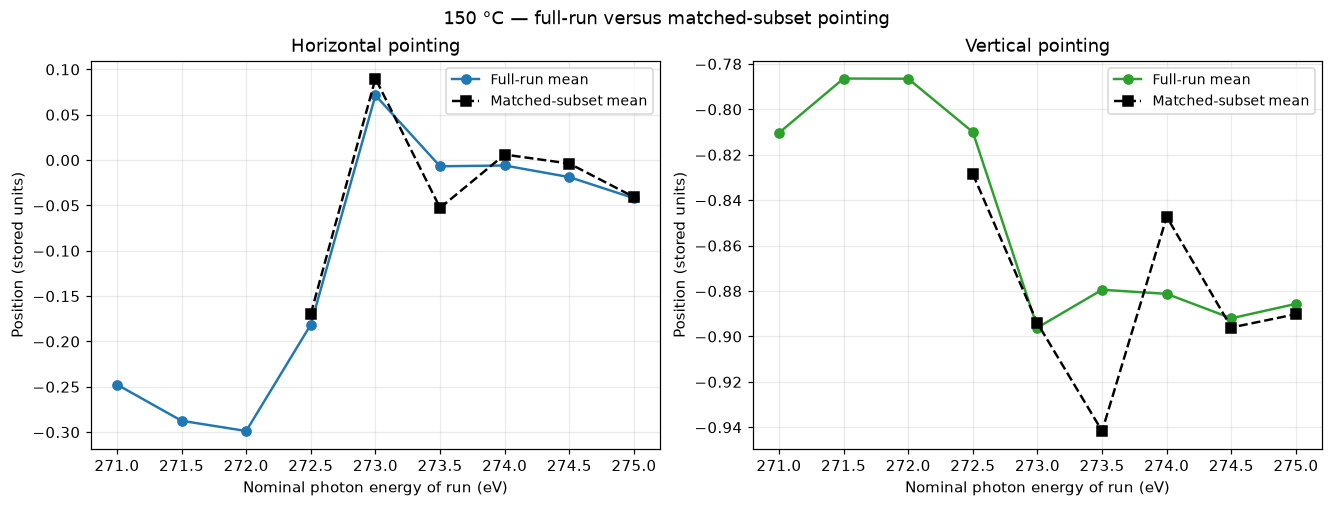

In [38]:

# --- Full-run versus matched-selection pointing -------------------------

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

PYC_MPE_RANGE_EV = (274.0, 274.3)
PYC_GMD_BAND = (3.0, 4.0)
PYC_ASSIGNMENT = "stable_hold"           # "stable_hold" or "measured_only"
PYC_MAX_GAP_TRAINS = 12
PYC_MAX_STEP_EV = 0.10
PYC_VALID_MPE_RANGE = (250.0, 310.0)
PYC_CHUNK_TRAINS = 250
PYC_MIN_POINTING_TRAINS = 10             # Plot filter only

pyc_families = {"150C": prod2d_datasets, "160C": wl160_datasets}
pyc_pointing = {}

for family, datasets in pyc_families.items():
    records = []
    for ds in datasets:
        source = Path(ds["source_h5"])
        with h5py.File(source, "r") as f:
            n_trains, n_bunches = f["gmd"].shape
            if any(f[k].shape != (n_trains,) for k in ("mpe", "hor_pos", "ver_pos")):
                raise ValueError(f"Monitor dimensions differ in {source.name}")
            keep = keep_mask_like_compute_aggregates_from_h5(
                f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
            )
            mpe = np.asarray(f["mpe"][:], dtype=float)
            hor = np.asarray(f["hor_pos"][:], dtype=float)
            ver = np.asarray(f["ver_pos"][:], dtype=float)

            valid_mpe = keep & np.isfinite(mpe) & (mpe >= PYC_VALID_MPE_RANGE[0]) & (mpe <= PYC_VALID_MPE_RANGE[1])
            assigned = np.full(n_trains, np.nan)
            assigned[valid_mpe] = mpe[valid_mpe]

            if PYC_ASSIGNMENT == "stable_hold":
                idx = np.flatnonzero(valid_mpe)
                for left, right in zip(idx[:-1], idx[1:]):
                    if (right - left <= PYC_MAX_GAP_TRAINS
                            and abs(mpe[right] - mpe[left]) <= PYC_MAX_STEP_EV
                            and np.all(keep[left:right + 1])):
                        assigned[left + 1:right] = mpe[left]
            elif PYC_ASSIGNMENT != "measured_only":
                raise ValueError(f"Invalid assignment mode: {PYC_ASSIGNMENT}")

            selected_energy = (keep & np.isfinite(assigned)
                               & (assigned >= PYC_MPE_RANGE_EV[0])
                               & (assigned < PYC_MPE_RANGE_EV[1]))

            stats = {}
            for key, pos in (("hor", hor), ("ver", ver)):
                full = pos[keep & np.isfinite(pos)]
                stats[f"{key}_full"] = float(np.mean(full)) if full.size else np.nan
                stats[f"{key}_std"] = float(np.std(full)) if full.size else np.nan
                stats[f"{key}_n_full"] = int(full.size)

            selected_shots = 0
            sums = {key: 0.0 for key in ("hor", "ver")}
            weights = {key: 0 for key in ("hor", "ver")}
            n_matched = {key: 0 for key in ("hor", "ver")}

            for start in range(0, n_trains, PYC_CHUNK_TRAINS):
                stop = min(start + PYC_CHUNK_TRAINS, n_trains)
                rows = np.flatnonzero(selected_energy[start:stop])
                if not rows.size:
                    continue

                gmd = np.asarray(f["gmd"][start:stop][rows], dtype=float)
                good_gmd = np.isfinite(gmd) & (gmd >= PYC_GMD_BAND[0]) & (gmd < PYC_GMD_BAND[1])
                shots_per_train = np.count_nonzero(good_gmd, axis=1)
                selected_shots += int(shots_per_train.sum())

                for key, pos in (("hor", hor), ("ver", ver)):
                    values = pos[start:stop][rows]
                    valid = (shots_per_train > 0) & np.isfinite(values)
                    n_matched[key] += int(valid.sum())
                    weights[key] += int(shots_per_train[valid].sum())
                    sums[key] += float(np.sum(values[valid] * shots_per_train[valid]))

            for key in ("hor", "ver"):
                stats[f"{key}_matched"] = sums[key] / weights[key] if weights[key] else np.nan
                stats[f"{key}_n_matched"] = n_matched[key]
                stats[f"{key}_coverage"] = weights[key] / selected_shots if selected_shots else np.nan

            records.append({"energy": float(ds["photon_energy_ev"]), "shots": selected_shots,
                            "file": source.name, **stats})

    pyc_pointing[family] = sorted(records, key=lambda r: r["energy"])

print(f"Matched selection: MPE {PYC_MPE_RANGE_EV} eV, GMD {PYC_GMD_BAND} µJ ({PYC_ASSIGNMENT})")
print("150C: full-run means versus matched-subset means (matched means weighted by selected shots)")
print(f"{'Run':>6} {'Hor full':>10} {'Hor match':>10} {'Ver full':>10} {'Ver match':>10} {'Full n':>8} {'Match n':>8} {'Coverage':>9}")

for r in pyc_pointing["150C"]:
    print(f"{r['energy']:6.1f} {r['hor_full']:10.4f} {r['hor_matched']:10.4f} "
          f"{r['ver_full']:10.4f} {r['ver_matched']:10.4f} {r['hor_n_full']:8d} "
          f"{r['hor_n_matched']:8d} {r['hor_coverage']:9.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, constrained_layout=True)

records = pyc_pointing["150C"]
x = np.array([r["energy"] for r in records])

for ax, key, title, color in zip(
    axes, ("hor", "ver"), ("Horizontal pointing", "Vertical pointing"), ("tab:blue", "tab:green")
):
    full = np.array([r[f"{key}_full"] for r in records])
    matched = np.array([
        r[f"{key}_matched"] if r[f"{key}_n_matched"] >= PYC_MIN_POINTING_TRAINS else np.nan
        for r in records
    ])
    ax.plot(x, full, "o-", lw=1.6, color=color, label="Full-run mean")
    ax.plot(x, matched, "s--", lw=1.6, color="black", label="Matched-subset mean")
    ax.set(title=title, xlabel="Nominal photon energy of run (eV)", ylabel="Position (stored units)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle("150 °C — full-run versus matched-subset pointing")
plt.show()


In [20]:
MATCH_BAND_FAMILY = "150C"
MATCH_BAND_MPE_RANGE_EV = (274.0, 274.3)
MATCH_BAND_ASSIGNMENT = "stable_hold"

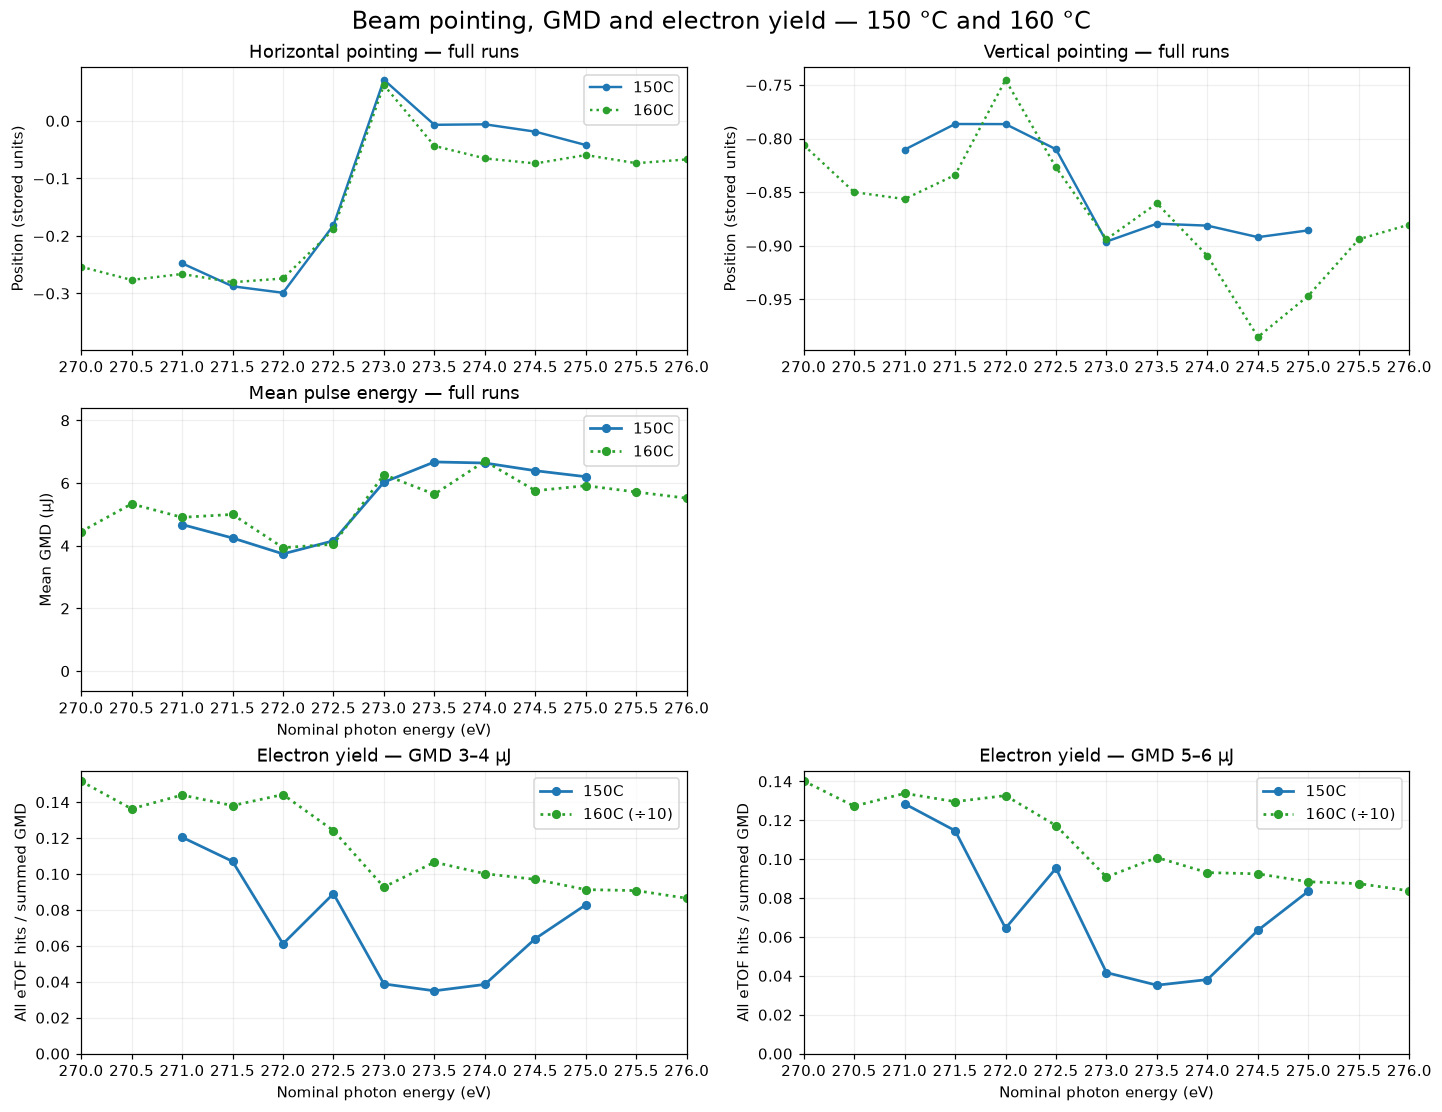

In [45]:
# --- Presentation: pointing, GMD and electron yield, 150C and 160C -----

import matplotlib.pyplot as plt
import numpy as np

FIG_FAMILIES = ["150C", "160C"]
FIG_GMD_BANDS = ["3-4", "5-6"]
FIG_160_SCALE = 10.0       # display scaling only for 160C yield
FIG_XLIM = (270.0, 276.0)  # change to (270.0, 283.0) if you want the full 160C range

fig, axes = plt.subplot_mosaic(
    [["hor", "ver"],
     ["gmd", "."],
     ["yield34", "yield56"]],
    figsize=(13, 10),
    constrained_layout=True
)

# --- Top row: full-run pointing -----------------------------------------

for family in FIG_FAMILIES:
    records = pyc_pointing[family]
    energy = np.array([r["energy"] for r in records], dtype=float)
    color = FAMILY_COLOURS[family]
    ls = FAMILY_LINESTYLES[family]

    hor = np.array([r["hor_full"] for r in records], dtype=float)
    ver = np.array([r["ver_full"] for r in records], dtype=float)

    axes["hor"].plot(energy, hor, "o", ls=ls, color=color, lw=1.6, ms=4, label=family)
    axes["ver"].plot(energy, ver, "o", ls=ls, color=color, lw=1.6, ms=4, label=family)

axes["hor"].set(title="Horizontal pointing — full runs", ylabel="Position (stored units)")
axes["ver"].set(title="Vertical pointing — full runs", ylabel="Position (stored units)")
axes["hor"].legend(fontsize=10)

# --- Middle row: mean GMD -----------------------------------------------

for family in FIG_FAMILIES:
    diag = family_diags[family]
    energy = np.asarray(diag["energy"], dtype=float)
    mean_gmd = np.asarray(diag["mean_gmd"], dtype=float)

    order = np.argsort(energy)
    axes["gmd"].plot(
        energy[order], mean_gmd[order], "o",
        ls=FAMILY_LINESTYLES[family],
        color=FAMILY_COLOURS[family],
        lw=1.8, ms=5, label=family
    )

axes["gmd"].set(
    title="Mean pulse energy — full runs",
    ylabel="Mean GMD (µJ)"
)
# Add vertical margins/padding so the trace is nicely centered and doesn't hug the edges
axes["gmd"].margins(y=0.3)
axes["gmd"].legend(fontsize=10)

# --- Bottom row: GMD-normalised electron yield --------------------------

band_to_ax = {"3-4": "yield34", "5-6": "yield56"}

for band in FIG_GMD_BANDS:
    ax = axes[band_to_ax[band]]

    for family in FIG_FAMILIES:
        diag = family_diags[family]
        energy = np.asarray(diag["energy"], dtype=float)
        values = np.asarray(diag["bands"][band]["e_per_gmd"], dtype=float)

        if energy.shape != values.shape:
            raise ValueError(f"Energy/yield dimensions differ for {family}, GMD {band}")

        order = np.argsort(energy)
        scale = FIG_160_SCALE if family == "160C" else 1.0
        label = f"{family} (÷{scale:g})" if scale != 1 else family

        ax.plot(
            energy[order], values[order] / scale, "o",
            ls=FAMILY_LINESTYLES[family],
            color=FAMILY_COLOURS[family],
            lw=1.8, ms=5, label=label
        )

    ax.set(
        title=f"Electron yield — GMD {band.replace('-', '–')} µJ",
        ylabel="All eTOF hits / summed GMD"
    )
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=10)

# --- Formatting ----------------------------------------------------------

for key, ax in axes.items():
    ax.set_xlim(*FIG_XLIM)
    if FIG_XLIM[1] <= 276.0:
        ax.set_xticks(np.arange(270.0, FIG_XLIM[1] + 0.1, 0.5))
    else:
        ax.set_xticks(np.arange(270.0, FIG_XLIM[1] + 0.1, 2.0))
    ax.grid(alpha=0.2)

axes["yield34"].set_xlabel("Nominal photon energy (eV)")
axes["yield56"].set_xlabel("Nominal photon energy (eV)")
axes["gmd"].set_xlabel("Nominal photon energy (eV)")

fig.suptitle("Beam pointing, GMD and electron yield — 150 °C and 160 °C", fontsize=16)
plt.show()

In [23]:

# --- Summary: matched photon energy, GMD and electron yield -------------

TABLE_MPE_RANGE_EV = (272.5, 272.8)
TABLE_ASSIGNMENT = "stable_hold"

if MATCH_BAND_FAMILY != "150C" or tuple(MATCH_BAND_MPE_RANGE_EV) != TABLE_MPE_RANGE_EV or MATCH_BAND_ASSIGNMENT != TABLE_ASSIGNMENT:
    raise ValueError("Rerun the fixed-GMD analysis for 150C, MPE 272.5–272.8 eV, stable_hold.")

for band, results in match_band_results.items():
    print(f"\n150C — MPE {TABLE_MPE_RANGE_EV[0]:g}–{TABLE_MPE_RANGE_EV[1]:g} eV, GMD {band}")
    print(f"{'Nominal run':18s} {'Shots':>9s} {'Electrons':>10s} {'Mean MPE':>11s} {'Mean GMD':>11s} {'E/GMD':>11s} {'Direct %':>9s}")

    for r in results:
        if r["shots"] == 0:
            continue
        print(f"{r['name']:18s} {r['shots']:9,d} {r['electrons']:10,d} "
              f"{r['mean_mpe']:11.4f} {r['mean_gmd']:11.4f} "
              f"{r['yield_gmd']:11.6f} {100*r['direct_fraction']:9.1f}")



150C — MPE 272.5–272.8 eV, GMD 3-4 uJ
Nominal run            Shots  Electrons    Mean MPE    Mean GMD       E/GMD  Direct %
271 eV (long)          3,560        366    272.5766      3.4787    0.029554      13.5
271.5 eV (long)        3,781        314    272.6447      3.4794    0.023868      26.9
272 eV (long)          1,936         82    272.6578      3.4679    0.012213      16.2
272.5 eV              24,564      2,138    272.6494      3.4784    0.025022      16.3
273 eV                30,714      1,067    272.7059      3.4925    0.009947      13.7
273.5 eV              33,740        995    272.6580      3.4999    0.008426      14.2
274 eV                 4,805        150    272.6859      3.5013    0.008916      20.7
274.5 eV               4,785        292    272.5656      3.4911    0.017480      13.0
275 eV                   884         57    272.6704      3.5107    0.018367      15.5

150C — MPE 272.5–272.8 eV, GMD 5-6 uJ
Nominal run            Shots  Electrons    Mean MPE    Mean GM

272.5 eV: 3,208 direct MPE readings
  Matched: 363 trains, 4,007 GMD-selected shots
  Matched MPE: 272.6550 ± 0.0834 eV (weighted mean ± SD)
273.5 eV: 3,277 direct MPE readings
  Matched: 500 trains, 4,803 GMD-selected shots
  Matched MPE: 272.6522 ± 0.0828 eV (weighted mean ± SD)


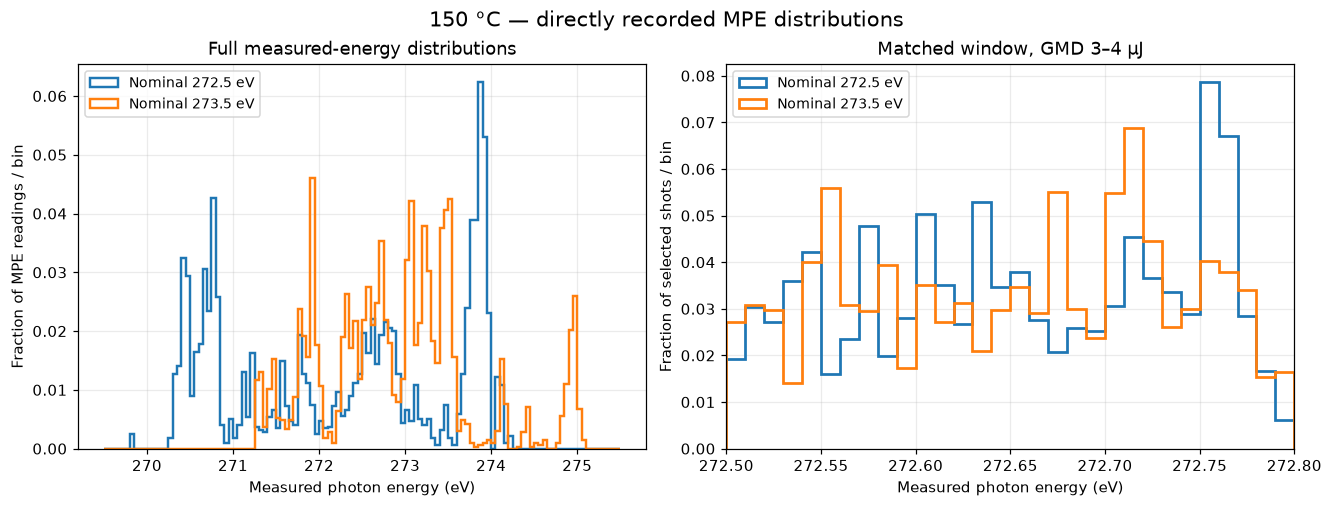


Nominal 272.5 eV — stable_hold
Direct MPE trains: 3,208
Additional assigned trains: 17,484
Matched trains: 2,204
Selected shots: 24,564
GMD-weighted MPE: 272.6494 ± 0.0860 eV (mean ± SD)
Shot-weighted MPE percentiles (10/50/90): 272.5342, 272.6380, 272.7643 eV

Nominal 273.5 eV — stable_hold
Direct MPE trains: 3,277
Additional assigned trains: 19,723
Matched trains: 3,490
Selected shots: 33,740
GMD-weighted MPE: 272.6580 ± 0.0809 eV (mean ± SD)
Shot-weighted MPE percentiles (10/50/90): 272.5488, 272.6741, 272.7624 eV


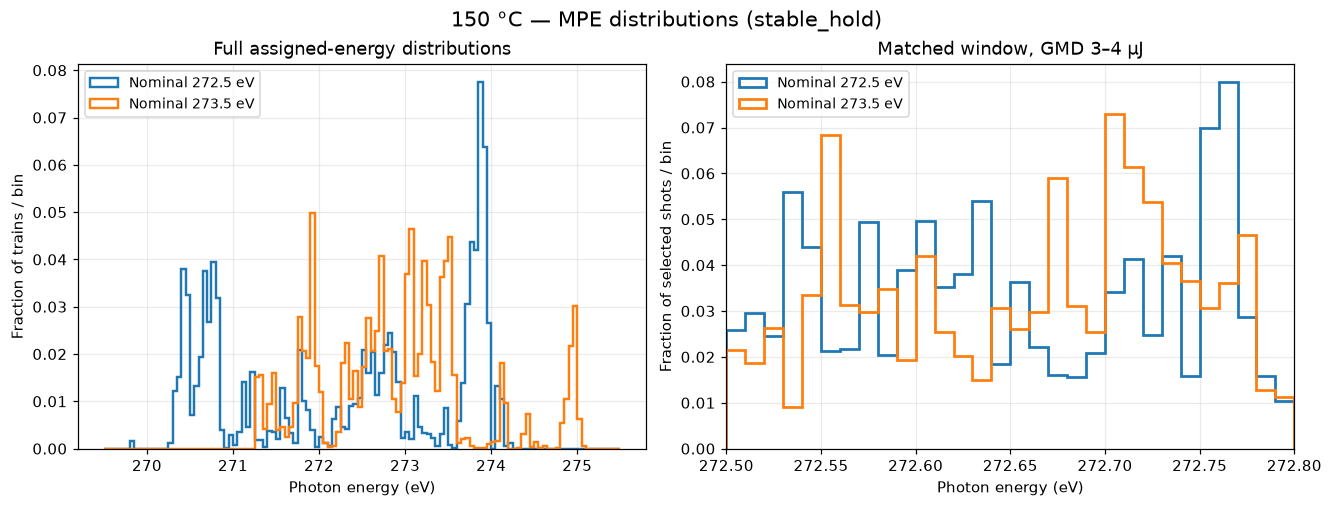

In [41]:

# --- Direct-MPE distributions: nominal 272.5 and 273.5 eV ---------------

import numpy as np
import h5py
import matplotlib.pyplot as plt

HIST_NOMINAL_ENERGIES = [272.5, 273.5]
HIST_MPE_WINDOW_EV = (272.5, 272.8)
HIST_GMD_BAND = (3.0, 4.0)
HIST_FULL_RANGE_EV = (269.5, 275.5)
HIST_FULL_BIN_EV = 0.05
HIST_ZOOM_BIN_EV = 0.01
HIST_CHUNK_TRAINS = 250

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

full_edges = np.arange(HIST_FULL_RANGE_EV[0], HIST_FULL_RANGE_EV[1] + HIST_FULL_BIN_EV / 2, HIST_FULL_BIN_EV)
zoom_edges = np.arange(HIST_MPE_WINDOW_EV[0], HIST_MPE_WINDOW_EV[1] + HIST_ZOOM_BIN_EV / 2, HIST_ZOOM_BIN_EV)

for nominal, color in zip(HIST_NOMINAL_ENERGIES, ("tab:blue", "tab:orange")):
    matches = [ds for ds in prod2d_datasets if np.isclose(ds["photon_energy_ev"], nominal)]
    if len(matches) != 1:
        raise ValueError(f"Expected one run at {nominal:g} eV; found {len(matches)}.")

    ds = matches[0]

    with h5py.File(ds["source_h5"], "r") as f:
        keep = keep_mask_like_compute_aggregates_from_h5(
            f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        mpe = np.asarray(f["mpe"][:], dtype=float)
        valid = keep & np.isfinite(mpe) & (mpe >= 250) & (mpe <= 310)

        # Count GMD-selected bunches per train without loading electron data.
        n_selected_shots = np.zeros(len(mpe), dtype=int)
        for start in range(0, len(mpe), HIST_CHUNK_TRAINS):
            stop = min(start + HIST_CHUNK_TRAINS, len(mpe))
            rows = np.flatnonzero(valid[start:stop])
            if not rows.size:
                continue
            gmd = np.asarray(f["gmd"][start:stop][rows], dtype=float)
            n_selected_shots[start + rows] = np.count_nonzero(
                np.isfinite(gmd) & (gmd >= HIST_GMD_BAND[0]) & (gmd < HIST_GMD_BAND[1]), axis=1
            )

    full = mpe[valid]
    matched = valid & (mpe >= HIST_MPE_WINDOW_EV[0]) & (mpe < HIST_MPE_WINDOW_EV[1]) & (n_selected_shots > 0)
    matched_values = mpe[matched]
    matched_weights = n_selected_shots[matched].astype(float)

    if not full.size or not matched_values.size:
        print(f"{nominal:g} eV: insufficient MPE data.")
        continue

    axes[0].hist(full, bins=full_edges, weights=np.full(full.size, 1 / full.size),
                 histtype="step", lw=1.6, color=color, label=f"Nominal {nominal:g} eV")
    axes[1].hist(matched_values, bins=zoom_edges, weights=matched_weights / matched_weights.sum(),
                 histtype="step", lw=1.8, color=color, label=f"Nominal {nominal:g} eV")

    mean_mpe = np.average(matched_values, weights=matched_weights)
    std_mpe = np.sqrt(np.average((matched_values - mean_mpe)**2, weights=matched_weights))

    print(f"{nominal:g} eV: {full.size:,} direct MPE readings")
    print(f"  Matched: {matched_values.size:,} trains, {int(matched_weights.sum()):,} GMD-selected shots")
    print(f"  Matched MPE: {mean_mpe:.4f} ± {std_mpe:.4f} eV (weighted mean ± SD)")

axes[0].set(title="Full measured-energy distributions",
            xlabel="Measured photon energy (eV)", ylabel="Fraction of MPE readings / bin")
axes[1].set(title=f"Matched window, GMD {HIST_GMD_BAND[0]:g}–{HIST_GMD_BAND[1]:g} µJ",
            xlabel="Measured photon energy (eV)", ylabel="Fraction of selected shots / bin")

axes[1].set_xlim(HIST_MPE_WINDOW_EV)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle("150 °C — directly recorded MPE distributions", fontsize=14)
plt.show()

# --- MPE distributions: nominal 272.5 and 273.5 eV ----------------------

import numpy as np
import h5py
import matplotlib.pyplot as plt

HIST_NOMINAL_ENERGIES = [272.5, 273.5]
HIST_ASSIGNMENT = "stable_hold"       # "stable_hold" or "measured_only"
HIST_MPE_WINDOW_EV = (272.5, 272.8)
HIST_GMD_BAND = (3.0, 4.0)
HIST_FULL_RANGE_EV = (269.5, 275.5)
HIST_FULL_BIN_EV = 0.05
HIST_ZOOM_BIN_EV = 0.01
HIST_VALID_MPE_RANGE_EV = (250.0, 310.0)
HIST_MAX_GAP_TRAINS = 12
HIST_MAX_STEP_EV = 0.10
HIST_CHUNK_TRAINS = 250

if HIST_ASSIGNMENT not in ("stable_hold", "measured_only"):
    raise ValueError("Invalid HIST_ASSIGNMENT.")

full_edges = np.arange(HIST_FULL_RANGE_EV[0], HIST_FULL_RANGE_EV[1] + HIST_FULL_BIN_EV / 2, HIST_FULL_BIN_EV)
zoom_edges = np.arange(HIST_MPE_WINDOW_EV[0], HIST_MPE_WINDOW_EV[1] + HIST_ZOOM_BIN_EV / 2, HIST_ZOOM_BIN_EV)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

for nominal, color in zip(HIST_NOMINAL_ENERGIES, ("tab:blue", "tab:orange")):
    matches = [ds for ds in prod2d_datasets if np.isclose(ds["photon_energy_ev"], nominal)]
    if len(matches) != 1:
        raise ValueError(f"Expected one run at {nominal:g} eV; found {len(matches)}.")

    ds = matches[0]

    with h5py.File(ds["source_h5"], "r") as f:
        keep = keep_mask_like_compute_aggregates_from_h5(
            f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        mpe = np.asarray(f["mpe"][:], dtype=float)
        n_trains, n_bunches = f["gmd"].shape

        if mpe.shape != (n_trains,) or keep.shape != (n_trains,):
            raise ValueError(f"Inconsistent MPE/GMD/train shapes in {ds['source_h5']}")

        valid_mpe = (
            keep & np.isfinite(mpe)
            & (mpe >= HIST_VALID_MPE_RANGE_EV[0])
            & (mpe <= HIST_VALID_MPE_RANGE_EV[1])
        )

        assigned = np.full(n_trains, np.nan)
        assigned[valid_mpe] = mpe[valid_mpe]

        if HIST_ASSIGNMENT == "stable_hold":
            idx = np.flatnonzero(valid_mpe)
            for left, right in zip(idx[:-1], idx[1:]):
                if (right - left <= HIST_MAX_GAP_TRAINS
                        and abs(mpe[right] - mpe[left]) <= HIST_MAX_STEP_EV
                        and np.all(keep[left:right + 1])):
                    assigned[left + 1:right] = mpe[left]

        assigned_valid = keep & np.isfinite(assigned)
        selected_energy = (
            assigned_valid
            & (assigned >= HIST_MPE_WINDOW_EV[0])
            & (assigned < HIST_MPE_WINDOW_EV[1])
        )

        shots_per_train = np.zeros(n_trains, dtype=np.int64)
        sum_gmd_per_train = np.zeros(n_trains, dtype=float)

        for start in range(0, n_trains, HIST_CHUNK_TRAINS):
            stop = min(start + HIST_CHUNK_TRAINS, n_trains)
            rows = np.flatnonzero(selected_energy[start:stop])
            if not rows.size:
                continue

            gmd = np.asarray(f["gmd"][start:stop][rows], dtype=float)
            selected = (
                np.isfinite(gmd)
                & (gmd >= HIST_GMD_BAND[0])
                & (gmd < HIST_GMD_BAND[1])
            )
            shots_per_train[start + rows] = np.count_nonzero(selected, axis=1)
            sum_gmd_per_train[start + rows] = np.sum(np.where(selected, gmd, 0.0), axis=1)

    full_values = assigned[assigned_valid]
    matched = selected_energy & (shots_per_train > 0)
    matched_values = assigned[matched]
    shot_weights = shots_per_train[matched].astype(float)
    gmd_weights = sum_gmd_per_train[matched]

    print(f"\nNominal {nominal:g} eV — {HIST_ASSIGNMENT}")
    print(f"Direct MPE trains: {valid_mpe.sum():,}")
    print(f"Additional assigned trains: {np.count_nonzero(assigned_valid & ~valid_mpe):,}")
    print(f"Matched trains: {matched.sum():,}")
    print(f"Selected shots: {int(shot_weights.sum()):,}")

    if not full_values.size or not matched_values.size:
        print("Insufficient MPE data for histograms.")
        continue

    mean_mpe = np.average(matched_values, weights=gmd_weights)
    std_mpe = np.sqrt(np.average((matched_values - mean_mpe)**2, weights=gmd_weights))
    p10, p50, p90 = np.percentile(
        np.repeat(matched_values, shots_per_train[matched]), [10, 50, 90]
    )

    print(f"GMD-weighted MPE: {mean_mpe:.4f} ± {std_mpe:.4f} eV (mean ± SD)")
    print(f"Shot-weighted MPE percentiles (10/50/90): {p10:.4f}, {p50:.4f}, {p90:.4f} eV")

    axes[0].hist(
        full_values, bins=full_edges,
        weights=np.full(full_values.size, 1.0 / full_values.size),
        histtype="step", lw=1.6, color=color, label=f"Nominal {nominal:g} eV"
    )
    axes[1].hist(
        matched_values, bins=zoom_edges,
        weights=shot_weights / shot_weights.sum(),
        histtype="step", lw=1.8, color=color, label=f"Nominal {nominal:g} eV"
    )

axes[0].set(
    title="Full assigned-energy distributions",
    xlabel="Photon energy (eV)",
    ylabel="Fraction of trains / bin"
)
axes[1].set(
    title=f"Matched window, GMD {HIST_GMD_BAND[0]:g}–{HIST_GMD_BAND[1]:g} µJ",
    xlabel="Photon energy (eV)",
    ylabel="Fraction of selected shots / bin"
)
axes[1].set_xlim(HIST_MPE_WINDOW_EV)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(f"150 °C — MPE distributions ({HIST_ASSIGNMENT})", fontsize=14)
plt.show()



GMD 3–4 µJ
Run                  Shots     N low    N high   Low / high
271 eV (long)        3,560        70       295       0.2373
271.5 eV (long)      3,781        58       253       0.2292
272 eV (long)        1,936        17        65       0.2615
272.5 eV            24,564       403     1,700       0.2371
273 eV              30,714       202       845       0.2391
273.5 eV            33,740       176       777       0.2265
274 eV               4,805        17       131       0.1298
274.5 eV             4,785        42       235       0.1787
275 eV                 884         8        46          nan

GMD 5–6 µJ
Run                  Shots     N low    N high   Low / high
271 eV (long)        2,618        97       357       0.2717
271.5 eV (long)      2,675        84       317       0.2650
272 eV (long)        1,137        12        71       0.1690
272.5 eV            16,068       432     1,975       0.2187
273 eV              27,764       283     1,295       0.2185
273.5 eV        

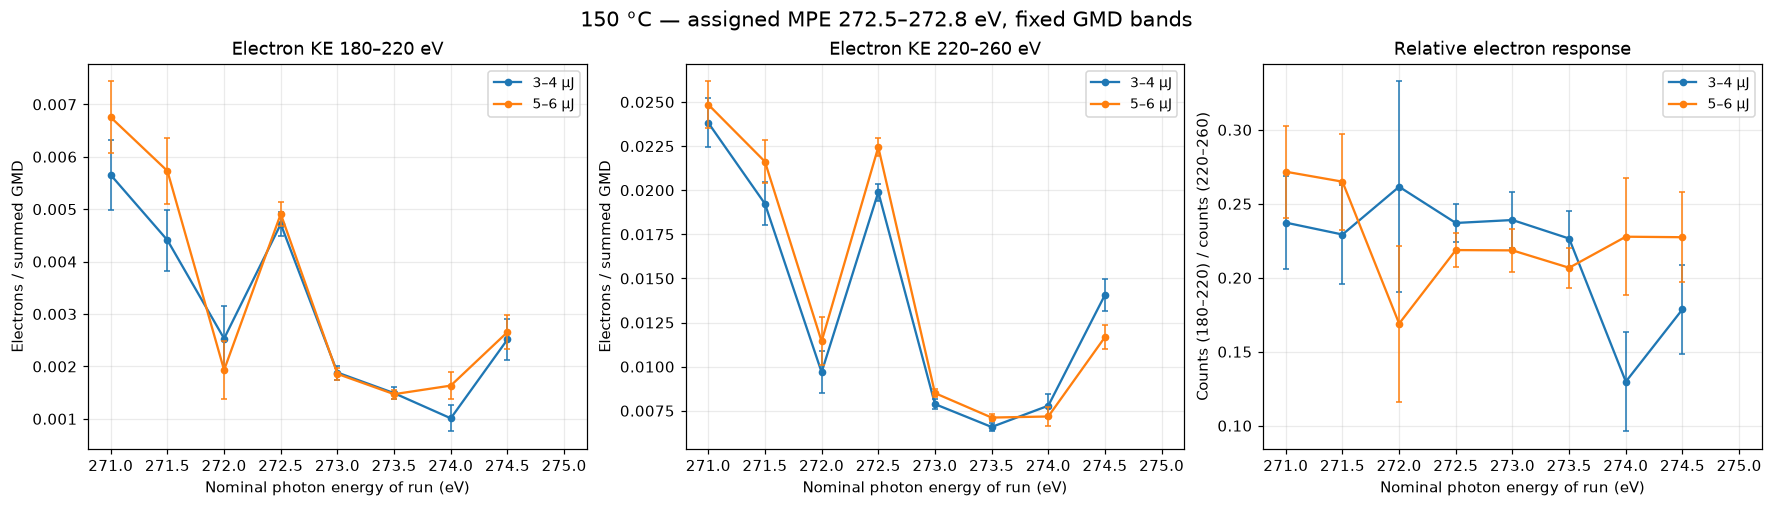

In [40]:

# --- Matched-MPE electron yield in two kinetic-energy windows -----------

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

KE_COMPARE_MPE_RANGE_EV = (272.5, 272.8)
KE_COMPARE_WINDOWS = {"180–220 eV": (180.0, 220.0), "220–260 eV": (220.0, 260.0)}
KE_COMPARE_GMD_BANDS = {"3–4 µJ": (3.0, 4.0), "5–6 µJ": (5.0, 6.0)}
KE_COMPARE_ASSIGNMENT = "stable_hold"  # "stable_hold" or "measured_only"
KE_COMPARE_MIN_SHOTS = 1000
KE_COMPARE_MAX_GAP_TRAINS = 12
KE_COMPARE_MAX_STEP_EV = 0.10
KE_COMPARE_CHUNK_TRAINS = 100

if KE_COMPARE_ASSIGNMENT not in ("stable_hold", "measured_only"):
    raise ValueError("Invalid assignment mode.")

# Map the calibrated KE windows back to the original TOF-bin ordering.
n_tof_bins = len(tof_edges_prod2d) - 1
ke_select = np.asarray(ke_select_prod2d, dtype=bool)
ke_centres = np.asarray(ke_plot_prod2d, dtype=float)

if len(ke_select) != n_tof_bins or np.count_nonzero(ke_select) != len(ke_centres):
    raise ValueError("Existing KE calibration and TOF masks are inconsistent.")
if not np.all(np.diff(ke_centres) > 0):
    raise ValueError("Expected increasing KE centres.")

tof_window_masks = {}
for name, (lo, hi) in KE_COMPARE_WINDOWS.items():
    mask = np.zeros(n_tof_bins, dtype=bool)
    mask[ke_select] = (ke_centres >= lo) & (ke_centres < hi)
    tof_window_masks[name] = mask[::-1] if reverse_ke_prod2d else mask
    if not mask.any():
        raise ValueError(f"No KE bins selected in {name}.")

ke_compare_results = {band: [] for band in KE_COMPARE_GMD_BANDS}
tof_low, tof_high = PROD2D_TOF_RANGE

for ds in prod2d_datasets:
    source = Path(ds["source_h5"])
    run_name = f"{ds['photon_energy_ev']:g} eV" + (" (long)" if "_long_" in source.name else "")
    accum = {
        band: {"shots": 0, "gmd": 0.0, "counts": {window: 0 for window in KE_COMPARE_WINDOWS}}
        for band in KE_COMPARE_GMD_BANDS
    }

    with h5py.File(source, "r") as f:
        n_trains, n_bunches = f["gmd"].shape
        keep = keep_mask_like_compute_aggregates_from_h5(
            f, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        mpe = np.asarray(f["mpe"][:], dtype=float)

        if mpe.shape != (n_trains,) or f["tofs_e"].shape[:2] != (n_trains, n_bunches):
            raise ValueError(f"Inconsistent HDF5 dimensions in {source.name}.")

        valid_mpe = keep & np.isfinite(mpe) & (mpe >= 250) & (mpe <= 310)
        assigned = np.full(n_trains, np.nan)
        assigned[valid_mpe] = mpe[valid_mpe]

        if KE_COMPARE_ASSIGNMENT == "stable_hold":
            idx = np.flatnonzero(valid_mpe)
            for left, right in zip(idx[:-1], idx[1:]):
                if (right - left <= KE_COMPARE_MAX_GAP_TRAINS
                        and abs(mpe[right] - mpe[left]) <= KE_COMPARE_MAX_STEP_EV
                        and np.all(keep[left:right + 1])):
                    assigned[left + 1:right] = mpe[left]

        selected_energy = keep & np.isfinite(assigned) & (
            assigned >= KE_COMPARE_MPE_RANGE_EV[0]
        ) & (assigned < KE_COMPARE_MPE_RANGE_EV[1])

        for start in range(0, n_trains, KE_COMPARE_CHUNK_TRAINS):
            stop = min(start + KE_COMPARE_CHUNK_TRAINS, n_trains)
            rows = np.flatnonzero(selected_energy[start:stop])
            if not rows.size:
                continue

            gmd = np.asarray(f["gmd"][start:stop][rows], dtype=float)
            selected_masks = {
                band: np.isfinite(gmd) & (gmd >= lo) & (gmd < hi)
                for band, (lo, hi) in KE_COMPARE_GMD_BANDS.items()
            }
            if not any(mask.any() for mask in selected_masks.values()):
                continue

            tofs = f["tofs_e"][start:stop][rows]

            for band, selected in selected_masks.items():
                if not selected.any():
                    continue

                a = accum[band]
                shot_gmd = gmd[selected]
                hits = tofs[selected].reshape(-1)
                valid_hits = (hits >= tof_low) & (hits <= tof_high)
                hit_idx = hits[valid_hits].astype(np.int64) - tof_low

                a["shots"] += len(shot_gmd)
                a["gmd"] += float(shot_gmd.sum())

                for window, tof_mask in tof_window_masks.items():
                    a["counts"][window] += int(np.count_nonzero(tof_mask[hit_idx]))

    for band, a in accum.items():
        ke_compare_results[band].append({
            "name": run_name,
            "energy": float(ds["photon_energy_ev"]),
            "shots": a["shots"],
            "sum_gmd": a["gmd"],
            "counts": a["counts"],
        })

# --- Plot window yields and their ratio ---------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
window_names = list(KE_COMPARE_WINDOWS)
band_colors = {"3–4 µJ": "tab:blue", "5–6 µJ": "tab:orange"}

for band, rows in ke_compare_results.items():
    rows = sorted(rows, key=lambda r: r["energy"])
    x = np.array([r["energy"] for r in rows])
    shots = np.array([r["shots"] for r in rows])
    gmd = np.array([r["sum_gmd"] for r in rows])
    counts = [np.array([r["counts"][w] for r in rows], dtype=float) for w in window_names]
    valid = (shots >= KE_COMPARE_MIN_SHOTS) & (gmd > 0)
    color = band_colors[band]

    for ax, window, n in zip(axes[:2], window_names, counts):
        y = np.divide(n, gmd, out=np.full_like(n, np.nan), where=valid)
        err = np.divide(np.sqrt(n), gmd, out=np.full_like(n, np.nan), where=valid)
        ax.plot(x, y, "o-", color=color, lw=1.5, ms=4, label=band)
        ax.errorbar(x[valid], y[valid], yerr=err[valid], fmt="none",
                    ecolor=color, capsize=2, elinewidth=1)
        ax.set(title=f"Electron KE {window}", ylabel="Electrons / summed GMD")

    good_ratio = valid & (counts[0] > 0) & (counts[1] > 0)
    ratio = np.divide(counts[0], counts[1], out=np.full_like(gmd, np.nan), where=good_ratio)
    ratio_err = np.full_like(ratio, np.nan)
    ratio_err[good_ratio] = ratio[good_ratio] * np.sqrt(
        1 / counts[0][good_ratio] + 1 / counts[1][good_ratio]
    )
    axes[2].plot(x, ratio, "o-", color=color, lw=1.5, ms=4, label=band)
    axes[2].errorbar(x[good_ratio], ratio[good_ratio], yerr=ratio_err[good_ratio],
                     fmt="none", ecolor=color, capsize=2, elinewidth=1)

    print(f"\nGMD {band}")
    print(f"{'Run':17s} {'Shots':>8s} {'N low':>9s} {'N high':>9s} {'Low / high':>12s}")
    for r, low, high, value in zip(rows, counts[0], counts[1], ratio):
        if r["shots"]:
            print(f"{r['name']:17s} {r['shots']:8,d} {int(low):9,d} {int(high):9,d} {value:12.4f}")

axes[2].set(title="Relative electron response", ylabel="Counts (180–220) / counts (220–260)")

for ax in axes:
    ax.set_xlabel("Nominal photon energy of run (eV)")
    ax.set_xlim(270.8, 275.2)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(
    f"150 °C — assigned MPE {KE_COMPARE_MPE_RANGE_EV[0]:g}–"
    f"{KE_COMPARE_MPE_RANGE_EV[1]:g} eV, fixed GMD bands",
    fontsize=14
)
plt.show()


## Run diagnostics

energy    shots        mean GMD    e/shot       e/uJ        Cb RMS (%)
274.0   2,303,574     5.5314    0.105615    0.019094       22.717
274.5   2,896,435     5.3210    0.094458    0.017752       20.985
275.0   2,985,515     5.1092    0.085806    0.016794       20.257
275.5   2,827,332     4.9543    0.074755    0.015089       21.174
276.0   2,608,961     4.6637    0.064069    0.013738       19.908


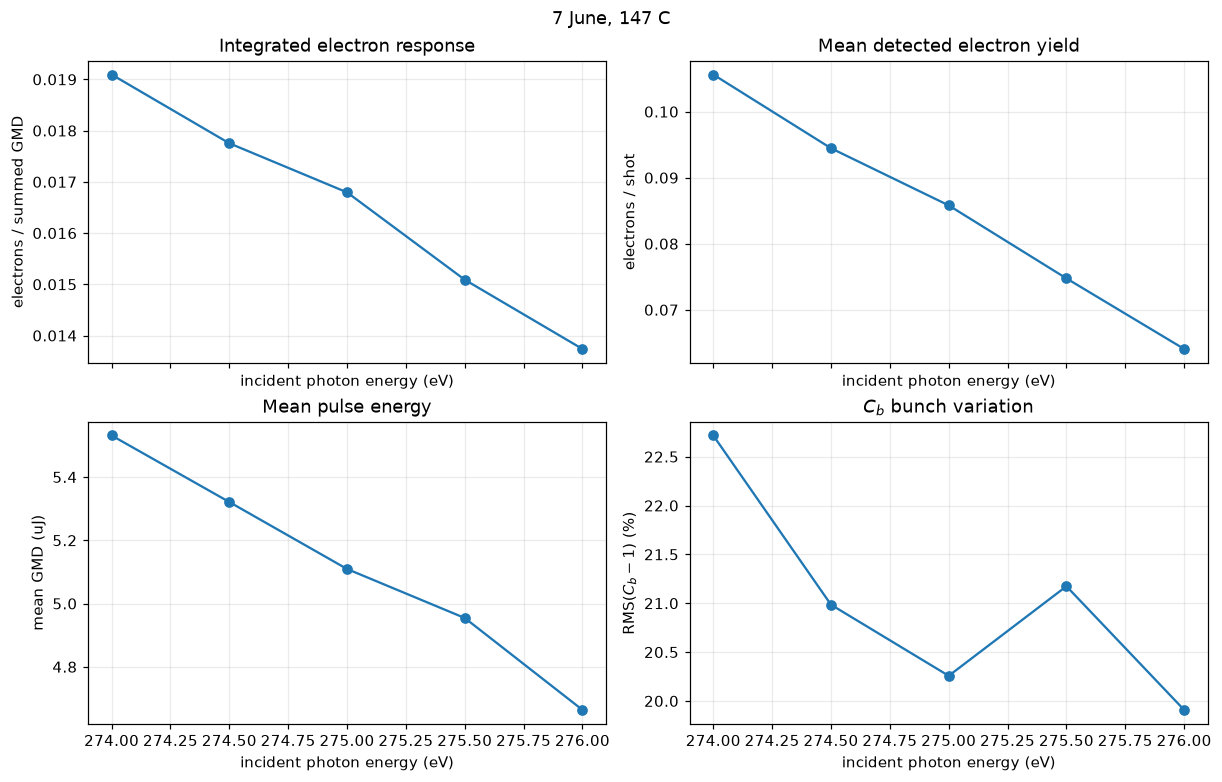

In [31]:

# --- 7 June: diagnose incident-energy-dependent scaling in the 2D map ----

j7_diag_energy = np.array([r["photon_energy_ev"] for r in j7_results])

j7_diag_sum_gmd = np.array([
    result["sum_gmd"]
    for result in j7_results
])

j7_diag_shots = np.array([
    result["shots"]
    for result in j7_results
])

j7_diag_mean_gmd = j7_diag_sum_gmd / j7_diag_shots

# Integral of spectrum over the plotted KE range:
# electrons / summed GMD.
j7_diag_e_per_gmd = np.array([
    np.nansum(
        result["spectrum_gmd"]
        * j7_ke_width_plot
    )
    for result in j7_results
])

# Convert back to mean detected electrons per selected shot.
j7_diag_e_per_shot = (
    j7_diag_e_per_gmd
    * j7_diag_sum_gmd
    / j7_diag_shots
)

# RMS bunch-dependent deviation of Cb from 1, in percent.
j7_diag_cb_rms = np.array([
    100.0 * np.sqrt(np.mean((np.asarray(result["cb"], dtype=float) - 1.0)**2))
    for result in j7_results
])

print(
    "energy    shots        mean GMD    "
    "e/shot       e/uJ        Cb RMS (%)"
)

for i, energy in enumerate(j7_diag_energy):
    print(
        f"{energy:5.1f}  "
        f"{j7_diag_shots[i]:10,d}  "
        f"{j7_diag_mean_gmd[i]:9.4f}  "
        f"{j7_diag_e_per_shot[i]:10.6f}  "
        f"{j7_diag_e_per_gmd[i]:10.6f}  "
        f"{j7_diag_cb_rms[i]:11.3f}"
    )

fig, axes = plt.subplots(
    2, 2, figsize=(11, 7),
    sharex=True, constrained_layout=True,
)

axes[0, 0].plot(j7_diag_energy, j7_diag_e_per_gmd, "o-")
axes[0, 0].set_ylabel("electrons / summed GMD")
axes[0, 0].set_title("Integrated electron response")

axes[0, 1].plot(j7_diag_energy, j7_diag_e_per_shot, "o-")
axes[0, 1].set_ylabel("electrons / shot")
axes[0, 1].set_title("Mean detected electron yield")

axes[1, 0].plot(j7_diag_energy, j7_diag_mean_gmd, "o-")
axes[1, 0].set_ylabel("mean GMD (uJ)")
axes[1, 0].set_title("Mean pulse energy")

axes[1, 1].plot(j7_diag_energy, j7_diag_cb_rms, "o-")
# axes[1, 1].axhline(0.0, ls="--", lw=1)
axes[1, 1].set_ylabel(r"RMS($C_b-1$) (%)")
axes[1, 1].set_title(r"$C_b$ bunch variation")

for ax in axes.flat:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)

fig.suptitle("7 June, 147 C")
plt.show()


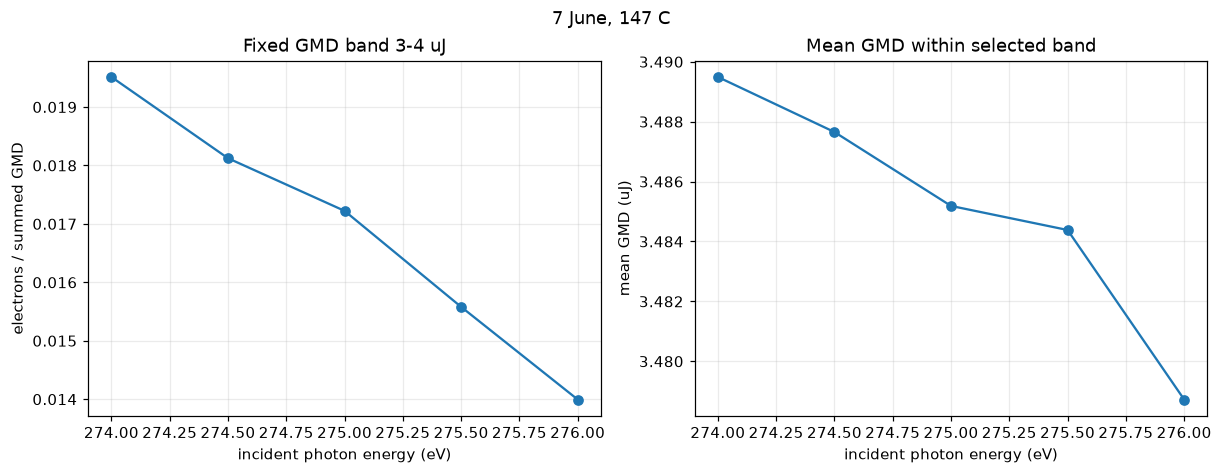

energy    shots       mean GMD    electrons/uJ
274.0     289,185     3.4895      0.019514
274.5     382,061     3.4877      0.018124
275.0     419,389     3.4852      0.017223
275.5     399,175     3.4844      0.015580
276.0     369,296     3.4787      0.013995


In [32]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

# --- 7 June: fixed-GMD test across incident photon energy ----------------

J7_FIXED_GMD_RANGE = (3.0, 4.0)

j7_fixed_results = []

for ds in j7_datasets:
    energy = ds["photon_energy_ev"]

    with h5py.File(ds["source_h5"], "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=ds["trim_start"],
            trim_end=ds["trim_end"],
        )

        if not keep.any():
            gmd_selected = np.array([], dtype=float)
            tofs_selected = np.array([], dtype=float)
        else:
            # Read only valid rows from HDF5
            gmd_selected = handle["gmd"][...][keep].astype(float)
            tofs_selected = handle["tofs_e"][...][keep]

    # Combine GMD range and finite checks
    gmd_mask = (
        np.isfinite(gmd_selected)
        & (gmd_selected >= J7_FIXED_GMD_RANGE[0])
        & (gmd_selected < J7_FIXED_GMD_RANGE[1])
    )

    gmd_filtered = gmd_selected[gmd_mask]
    tofs_filtered = tofs_selected[gmd_mask].reshape(-1)

    # Filter Time-of-Flight events
    valid_hits = (
        np.isfinite(tofs_filtered)
        & (tofs_filtered >= J7_TOF_RANGE[0])
        & (tofs_filtered <= J7_TOF_RANGE[1])
    )

    counts, _ = np.histogram(tofs_filtered[valid_hits], bins=j7_tof_edges)

    if j7_reverse_ke:
        counts = counts[::-1]

    counts = counts[j7_ke_select]

    # Accumulate metrics
    sum_gmd = float(np.sum(gmd_filtered))
    shots = int(len(gmd_filtered))
    mean_gmd = (sum_gmd / shots) if shots > 0 else 0.0

    # Calculate spectrum and yield with zero-division safety
    if sum_gmd > 0:
        spectrum = counts / sum_gmd / j7_ke_width_plot
        integrated_yield = float(np.sum(spectrum * j7_ke_width_plot))
    else:
        spectrum = np.zeros_like(counts, dtype=float)
        integrated_yield = 0.0

    j7_fixed_results.append({
        "energy": energy,
        "shots": shots,
        "sum_gmd": sum_gmd,
        "mean_gmd": mean_gmd,
        "spectrum": spectrum,
        "integrated_yield": integrated_yield,
    })


# Sort and extract arrays for plotting
j7_fixed_results.sort(key=lambda r: r["energy"])

j7_fixed_energy = np.array([r["energy"] for r in j7_fixed_results])
j7_fixed_yield = np.array([r["integrated_yield"] for r in j7_fixed_results])
j7_fixed_mean_gmd = np.array([r["mean_gmd"] for r in j7_fixed_results])


# Plotting
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.2),
    constrained_layout=True,
)

axes[0].plot(j7_fixed_energy, j7_fixed_yield, "o-")
axes[0].set_xlabel("incident photon energy (eV)")
axes[0].set_ylabel("electrons / summed GMD")
axes[0].set_title(
    f"Fixed GMD band {J7_FIXED_GMD_RANGE[0]:g}-{J7_FIXED_GMD_RANGE[1]:g} uJ"
)
axes[0].grid(alpha=0.25)

axes[1].plot(j7_fixed_energy, j7_fixed_mean_gmd, "o-")
axes[1].set_xlabel("incident photon energy (eV)")
axes[1].set_ylabel("mean GMD (uJ)")
axes[1].set_title("Mean GMD within selected band")
axes[1].grid(alpha=0.25)

fig.suptitle("7 June, 147 C")
plt.show()


# Summary table display
print("energy    shots       mean GMD    electrons/uJ")
for r in j7_fixed_results:
    print(
        f"{r['energy']:5.1f}  "
        f"{r['shots']:10,d}  "
        f"{r['mean_gmd']:9.4f}  "
        f"{r['integrated_yield']:12.6f}"
    )


150C
energy    all eTOF hits / summed GMD    all eTOF hits / shot    mean GMD    Cb RMS (%)
271.0        0.127090                  0.594259      4.6759       8.755
271.5        0.114214                  0.484962      4.2461       6.698
272.0        0.064238                  0.240187      3.7390       7.033
272.5        0.093999                  0.390740      4.1568      12.172
273.0        0.041397                  0.249500      6.0270      16.921
273.5        0.032446                  0.216483      6.6722      20.631
274.0        0.034833                  0.231241      6.6386      24.906
274.5        0.058158                  0.371788      6.3927      24.994
275.0        0.077437                  0.480234      6.2016      23.492

147C (7 June)
energy    all eTOF hits / summed GMD    all eTOF hits / shot    mean GMD    Cb RMS (%)
274.0        0.085515                  0.487688      5.7029      22.717
274.5        0.088466                  0.474903      5.3682      20.985
275.0        

/tmp/ipykernel_3137283/1324731453.py:10: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 0].plot(diag["energy"], diag["e_per_gmd"], "o-", color=c, ls=ls, label=name)
/tmp/ipykernel_3137283/1324731453.py:11: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 1].plot(diag["energy"], diag["e_per_shot"], "o-", color=c, ls=ls, label=name)
/tmp/ipykernel_3137283/1324731453.py:12: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[1, 0].plot(diag["energy"], diag["mean_gmd"], "o-", color=c, ls=ls, label=name)
/tmp/ipykernel_3137283/1324731453.py:13: UserWarning: linestyle is redundantly defined by the 'linestyle' key

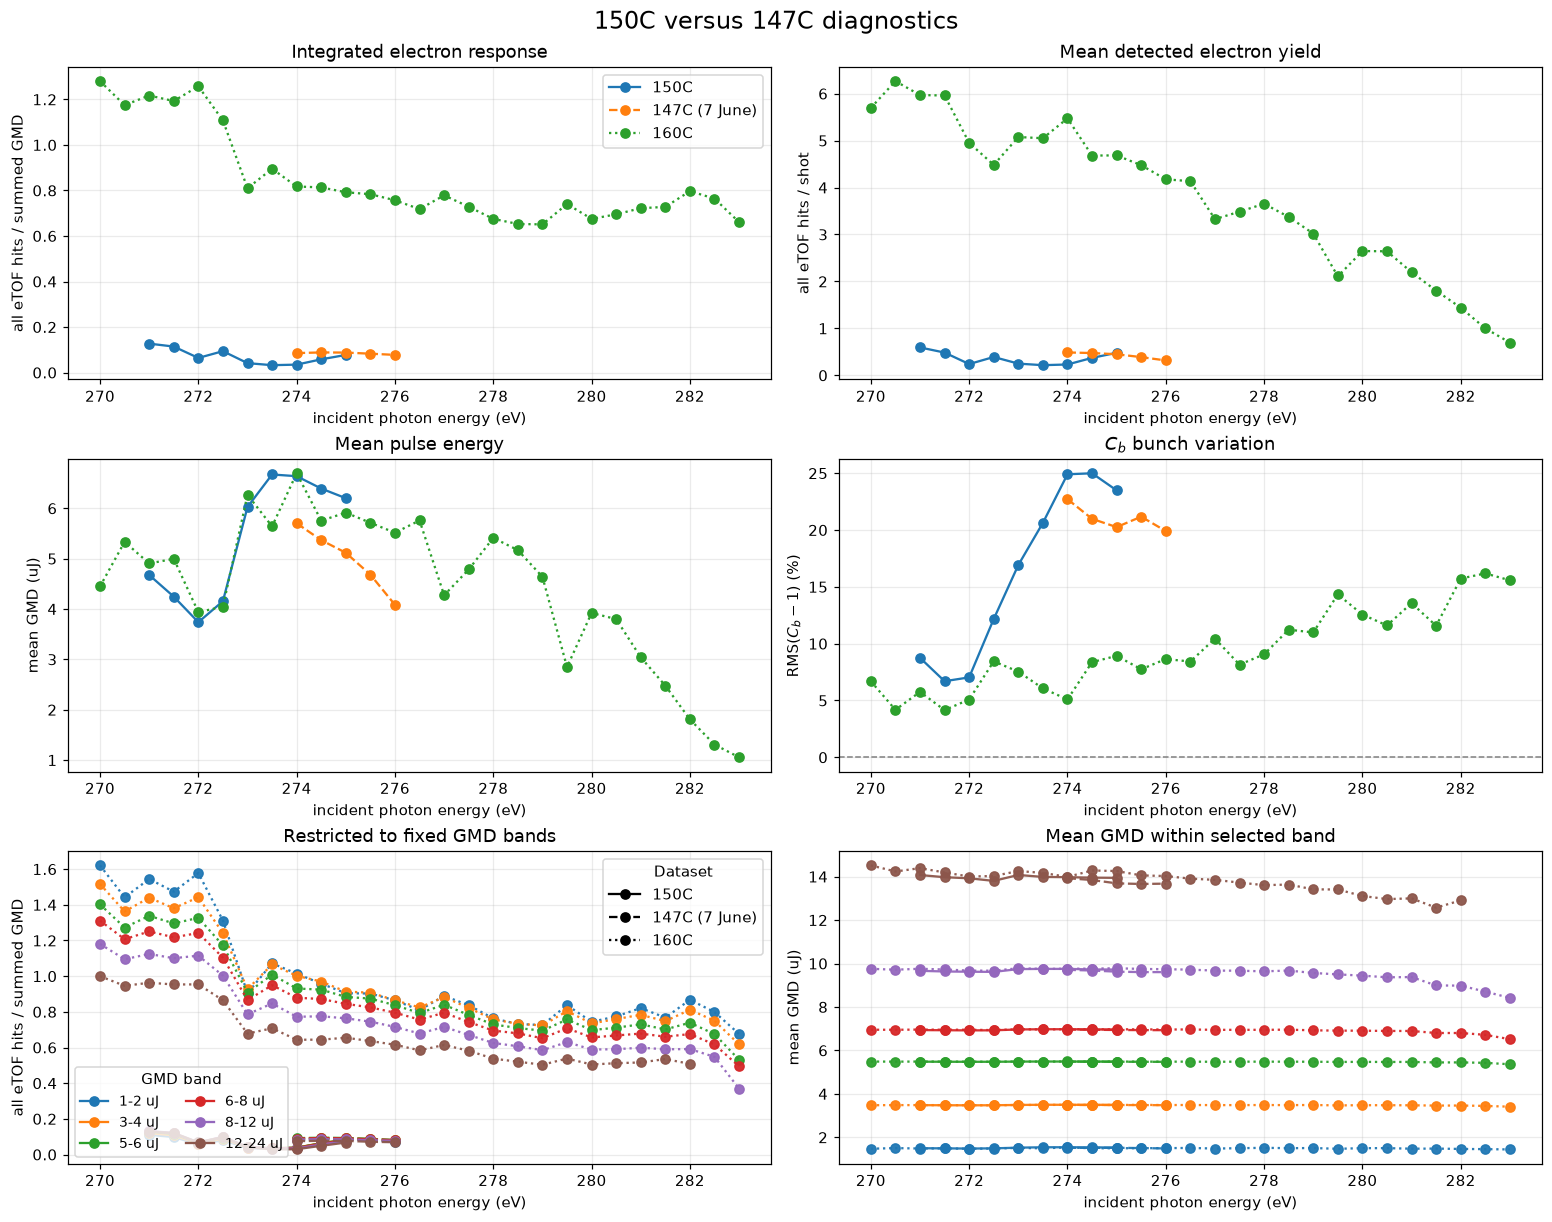

In [33]:
for name in FAMILY_ORDER:
    diag = family_diags[name]
    print(f"\n{name}\nenergy    {count_label} / summed GMD    {count_label} / shot    mean GMD    Cb RMS (%)")
    for e, a, b, c, d in zip(diag["energy"], diag["e_per_gmd"], diag["e_per_shot"], diag["mean_gmd"], diag["cb_rms"]):
        print(f"{e:5.1f}    {a:12.6f}                {b:10.6f}    {c:8.4f}    {d:8.3f}")

fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=False, constrained_layout=True)
for name in FAMILY_ORDER:
    diag, c, ls = family_diags[name], FAMILY_COLOURS[name], FAMILY_LINESTYLES[name]
    axes[0, 0].plot(diag["energy"], diag["e_per_gmd"], "o-", color=c, ls=ls, label=name)
    axes[0, 1].plot(diag["energy"], diag["e_per_shot"], "o-", color=c, ls=ls, label=name)
    axes[1, 0].plot(diag["energy"], diag["mean_gmd"], "o-", color=c, ls=ls, label=name)
    axes[1, 1].plot(diag["energy"], diag["cb_rms"], "o-", color=c, ls=ls, label=name)

axes[0, 0].set(ylabel=f"{count_label} / summed GMD", title="Integrated electron response")
axes[0, 1].set(ylabel=f"{count_label} / shot", title="Mean detected electron yield")
axes[1, 0].set(ylabel="mean GMD (uJ)", title="Mean pulse energy")
axes[1, 1].set(ylabel=r"RMS($C_b-1$) (%)", title=r"$C_b$ bunch variation")
axes[1, 1].axhline(0.0, ls="--", lw=1, color="0.5")

for name in FAMILY_ORDER:
    diag, ls = family_diags[name], FAMILY_LINESTYLES[name]
    for l, c in BAND_COLOURS.items():
        axes[2, 0].plot(diag["energy"], diag["bands"][l]["e_per_gmd"], "o-", color=c, ls=ls, alpha=0.95)
        axes[2, 1].plot(diag["energy"], diag["bands"][l]["mean_gmd"], "o-", color=c, ls=ls, alpha=0.95)

axes[2, 0].set(ylabel=f"{count_label} / summed GMD", title="Restricted to fixed GMD bands")
axes[2, 1].set(ylabel="mean GMD (uJ)", title="Mean GMD within selected band")

for ax in axes.flat:
    ax.set(xlabel="incident photon energy (eV)")
    ax.grid(alpha=0.25)

fam_handles = [Line2D([0], [0], color="black", ls=FAMILY_LINESTYLES[n], marker="o", label=n) for n in FAMILY_ORDER]
band_handles = [Line2D([0], [0], color=BAND_COLOURS[l], ls="-", marker="o", label=f"{l} uJ") for l in COMPARE_GMD_BANDS]

leg1 = axes[2, 0].legend(handles=fam_handles, title="Dataset", loc="upper right")
axes[2, 0].add_artist(leg1)
axes[2, 0].legend(handles=band_handles, title="GMD band", loc="lower left", ncol=2, fontsize=9)
axes[0, 0].legend(loc="best")
fig.suptitle("150C versus 147C diagnostics", fontsize=16)
plt.show()

In [34]:
from pathlib import Path
import h5py, numpy as np, matplotlib.pyplot as plt

USE_ALL_ELECTRONS, ELECTRON_KE_RANGE = True, (180.0, 280.0)
CB_RMS_GMD_BANDS = {"1-2": (1.0, 2.0), "3-4": (3.0, 4.0), "5-6": (5.0, 6.0), "6-8": (6.0, 8.0), "8-12": (8.0, 12.0), "12-24": (12.0, 24.0)}
CB_RMS_BUNCH_START = 20
CB_RMS_FAMILY_ORDER = ["150C", "147C (7 June)"]
BAND_COLOURS = {"1-2": "tab:blue", "3-4": "tab:orange", "5-6": "tab:green", "6-8": "tab:red", "8-12": "tab:purple", "12-24": "tab:brown"}
CB_FAMILIES = {
    "150C": {"datasets": prod2d_datasets, "chunk_trains": PROD2D_CHUNK_TRAINS},
    "147C (7 June)": {"datasets": j7_datasets, "chunk_trains": PROD2D_CHUNK_TRAINS},
}

def _counts_per_shot(tofs):
    return np.count_nonzero(np.isfinite(tofs) & (tofs > 0), axis=-1).astype(float) if USE_ALL_ELECTRONS else electron_counts_from_tof(tofs, ke_range=ELECTRON_KE_RANGE).astype(float)

def _dataset_band_cb_rms(ds, chunk_trains, gmd_bands, bunch_start):
    with h5py.File(Path(ds["source_h5"]), "r") as f:
        keep = keep_mask_like_compute_aggregates_from_h5(f, trim_start=ds["trim_start"], trim_end=ds["trim_end"])
        n_trains, n_bunch = f["gmd"].shape
        sum_counts, sum_gmd, shots = {l: np.zeros(n_bunch) for l in gmd_bands}, {l: np.zeros(n_bunch) for l in gmd_bands}, {l: np.zeros(n_bunch, dtype=int) for l in gmd_bands}
        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]
            if not np.any(row_keep): continue
            gmd, tofs, valid, cps = f["gmd"][start:stop][row_keep].astype(float), f["tofs_e"][start:stop][row_keep], np.isfinite(f["gmd"][start:stop][row_keep]), _counts_per_shot(f["tofs_e"][start:stop][row_keep])
            for l, (lo, hi) in gmd_bands.items():
                sel = valid & (gmd >= lo) & (gmd < hi)
                if not np.any(sel): continue
                shots[l] += np.sum(sel, axis=0)
                sum_gmd[l] += np.sum(np.where(sel, gmd, 0.0), axis=0)
                sum_counts[l] += np.sum(np.where(sel, cps, 0.0), axis=0)
    fit_mask = np.arange(n_bunch) >= bunch_start
    band_rms = {}
    for l in gmd_bands:
        response = np.full(n_bunch, np.nan)
        valid_norm = sum_gmd[l] > 0
        response[valid_norm] = sum_counts[l][valid_norm] / sum_gmd[l][valid_norm]
        scale_mask = fit_mask & np.isfinite(response) & (shots[l] > 0)
        if not np.any(scale_mask):
            band_rms[l] = np.nan; continue
        scale = np.sum(sum_counts[l][scale_mask]) / np.sum(sum_gmd[l][scale_mask])
        relative = response / scale
        valid_rms = fit_mask & np.isfinite(relative) & (shots[l] > 0)
        band_rms[l] = 100.0 * np.sqrt(np.mean((relative[valid_rms] - 1.0) ** 2)) if np.any(valid_rms) else np.nan
    return band_rms

cb_band_results = {name: {"energy": [], **{l: [] for l in CB_RMS_GMD_BANDS}} for name in CB_RMS_FAMILY_ORDER}
for name in CB_RMS_FAMILY_ORDER:
    for ds in sorted(CB_FAMILIES[name]["datasets"], key=lambda d: d["photon_energy_ev"]):
        cb_band_results[name]["energy"].append(ds["photon_energy_ev"])
        band_rms = _dataset_band_cb_rms(ds, CB_FAMILIES[name]["chunk_trains"], CB_RMS_GMD_BANDS, CB_RMS_BUNCH_START)
        for l in CB_RMS_GMD_BANDS: cb_band_results[name][l].append(band_rms[l])
    cb_band_results[name]["energy"] = np.asarray(cb_band_results[name]["energy"], dtype=float)
    for l in CB_RMS_GMD_BANDS: cb_band_results[name][l] = np.asarray(cb_band_results[name][l], dtype=float)



KeyboardInterrupt: 

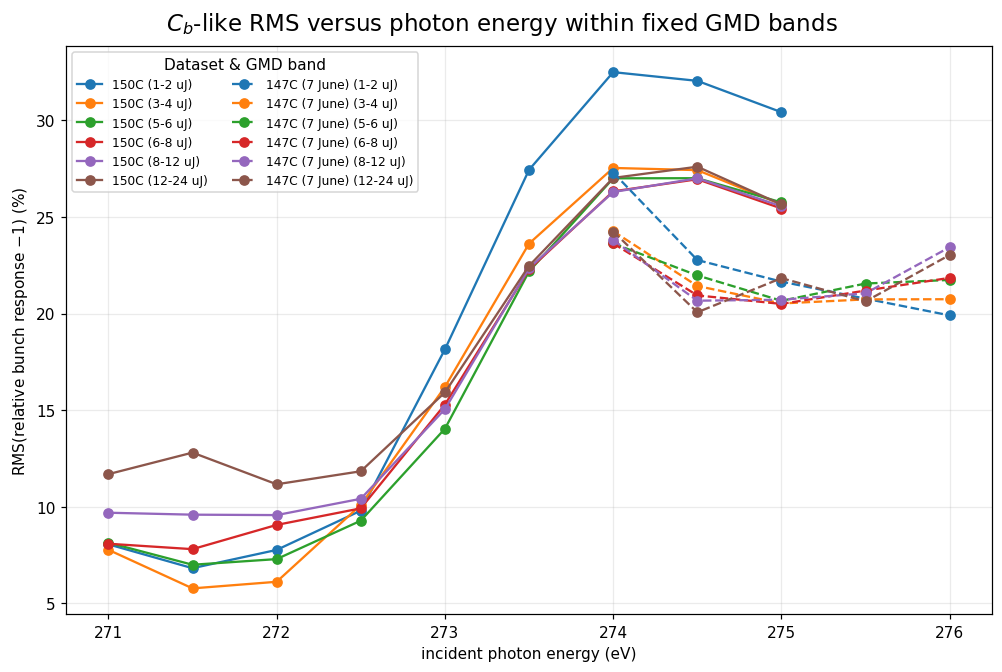

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)

for name in CB_RMS_FAMILY_ORDER:
    energy = cb_band_results[name]["energy"]
    ls = FAMILY_LINESTYLES[name]
    for l, c in BAND_COLOURS.items():
        ax.plot(energy, cb_band_results[name][l], "o-", color=c, ls=ls, label=f"{name} ({l} uJ)")

ax.set(xlabel="incident photon energy (eV)", ylabel=r"RMS(relative bunch response $-1$) (%)")
ax.grid(alpha=0.25)
ax.legend(title="Dataset & GMD band", ncol=2, fontsize=8, loc="best")
fig.suptitle(r"$C_b$-like RMS versus photon energy within fixed GMD bands", fontsize=15)
plt.show()

## 150C versus 147C: why do both spectral features lose intensity?

This section compares the **150C 271.5–275 eV** series with the **7 June / 147C 274–276 eV** series selected above. It asks whether the intensity dips affect both features together, whether their relative yield changes, and whether acquisition stability can explain the difference. Constant intensity is a hypothesis to test, not a constraint imposed on the data.

Run the two production-map loading/calculation sections first (`prod2d_datasets`, `prod2d_results`, `j7_datasets`, `j7_results`). The first plots reuse those results without reading large HDF5 arrays. The subsequent reader independently applies **identical, explicit selections** to both families and records source paths, run metadata and train IDs. Full ranges remain visible; direct family comparisons use only shared photon energies, with no extrapolation.

The two feature windows below are diagnostic integration windows, not peak fits or background-subtracted signals. The streamed reader counts hits directly inside each KE window; cached map integrals use the existing TOF-bin-to-KE grid, so small boundary-bin differences are expected. Fixed-KE and photon-energy-tracking windows are both tested. No changes are made to the preceding analysis, calibration, background subtraction or production correction. Area-normalised spectra are used only to inspect shape, never to replace absolute yields.

In [ ]:
# Explicit comparison settings; all new names are isolated from earlier cells.
# Uses prod2d_datasets/j7_datasets selected by CB_AGG_FILENAMES/J7_AGG_FILENAMES.
# After changing filenames, rerun both families' loading and spectrum-calculation
# cells before this comparison setup so datasets and spectra use the same scans.
import importlib.util
import copy
import shlex
from datetime import datetime

cmp_module_path = repo_root / "analysis" / "post" / "incident_yield_comparison.py"
cmp_spec = importlib.util.spec_from_file_location("incident_yield_comparison", cmp_module_path)
cmp_reader = importlib.util.module_from_spec(cmp_spec)
cmp_spec.loader.exec_module(cmp_reader)

CMP_FEATURE_WINDOWS = [(225.0, 242.0), (245.0, 262.0)]
CMP_REFERENCE_ENERGY = 274.0
CMP_WINDOWS = [(180.0, 280.0), *CMP_FEATURE_WINDOWS, (180.0, 220.0)]
CMP_WINDOW_LABELS = ["broad 180–280", "feature A 225–242", "feature B 245–262", "low KE 180–220"]
CMP_FAMILIES = {
    "150C": {"datasets": prod2d_datasets, "results": prod2d_results,
             "edges": np.asarray(ke_edges_plot_prod2d)},
    "147C (7 June)": {"datasets": j7_datasets, "results": j7_results,
                     "edges": np.asarray(j7_ke_edges_plot)},
}
CMP_COLOURS = {"150C": "tab:blue", "147C (7 June)": "tab:orange"}
CMP_COMMON = sorted(set(r["photon_energy_ev"] for r in prod2d_results)
                    & set(r["photon_energy_ev"] for r in j7_results))
if not CMP_COMMON:
    raise ValueError("No shared incident energies: matched-energy comparisons are unavailable")
print("Shared incident energies:", CMP_COMMON)
print("The missing 147C points below 274 eV cannot test the 150C low-energy dip directly.")

# Cached maps used all bunches and all delays. Match that baseline explicitly.
# None retains all delays, including missing z; delay validity is reported separately.
cmp_settings = {
    "calibration": {k: float(calib[k]) for k in
                    ("t0_tof_units", "slope_eV_tof_unit2", "E0_eV")},
    "gmd_ranges": [[1.0, 12.0], [3.0, 4.0]],
    "bunch_range": [0, 101],
    "delay_stage_range": None,
    "ke_windows": [list(w) for w in CMP_WINDOWS],
    "reference_energy": CMP_REFERENCE_ENERGY,
    "ion_tof_range": [0.0, 50000.0],
    "delay_zero_stage": float(DELAY_ZERO_STAGE),
    "fs_per_stage_unit": float(FS_PER_STAGE_UNIT),
    "delay_edges_fs": np.arange(-5.0, 40.0, 5.0).tolist(),
    "n_blocks": 8, "chunk_trains": 100, "max_trains": 100,
}
cmp_manifest = {"settings": cmp_settings, "datasets": []}
for family, item in CMP_FAMILIES.items():
    for ds in item["datasets"]:
        entry = dict(ds, family=family)
        entry["source_h5"] = str(entry["source_h5"])
        entry["agg_path"] = str(entry["agg_path"])
        cmp_manifest["datasets"].append(entry)
        print(f"{family:14s} {entry['photon_energy_ev']:5.1f} eV  {entry['source_h5']}")
print("Streamed selection:", cmp_settings)

Shared incident energies: [274.0, 274.5, 275.0]
The missing 147C points below 274 eV cannot test the 150C low-energy dip directly.
150C           271.0 eV  /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long_271.0eV.h5
150C           271.5 eV  /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long_271.5eV.h5
150C           272.0 eV  /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long_272.0eV.h5
150C           272.5 eV  /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_272.5eV.h5
150C           273.0 eV  /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_273.0eV.h5
150C           273.5 eV  /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_273.5eV.h5
150C           274.0 eV  /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_274.0eV.h5
150C   

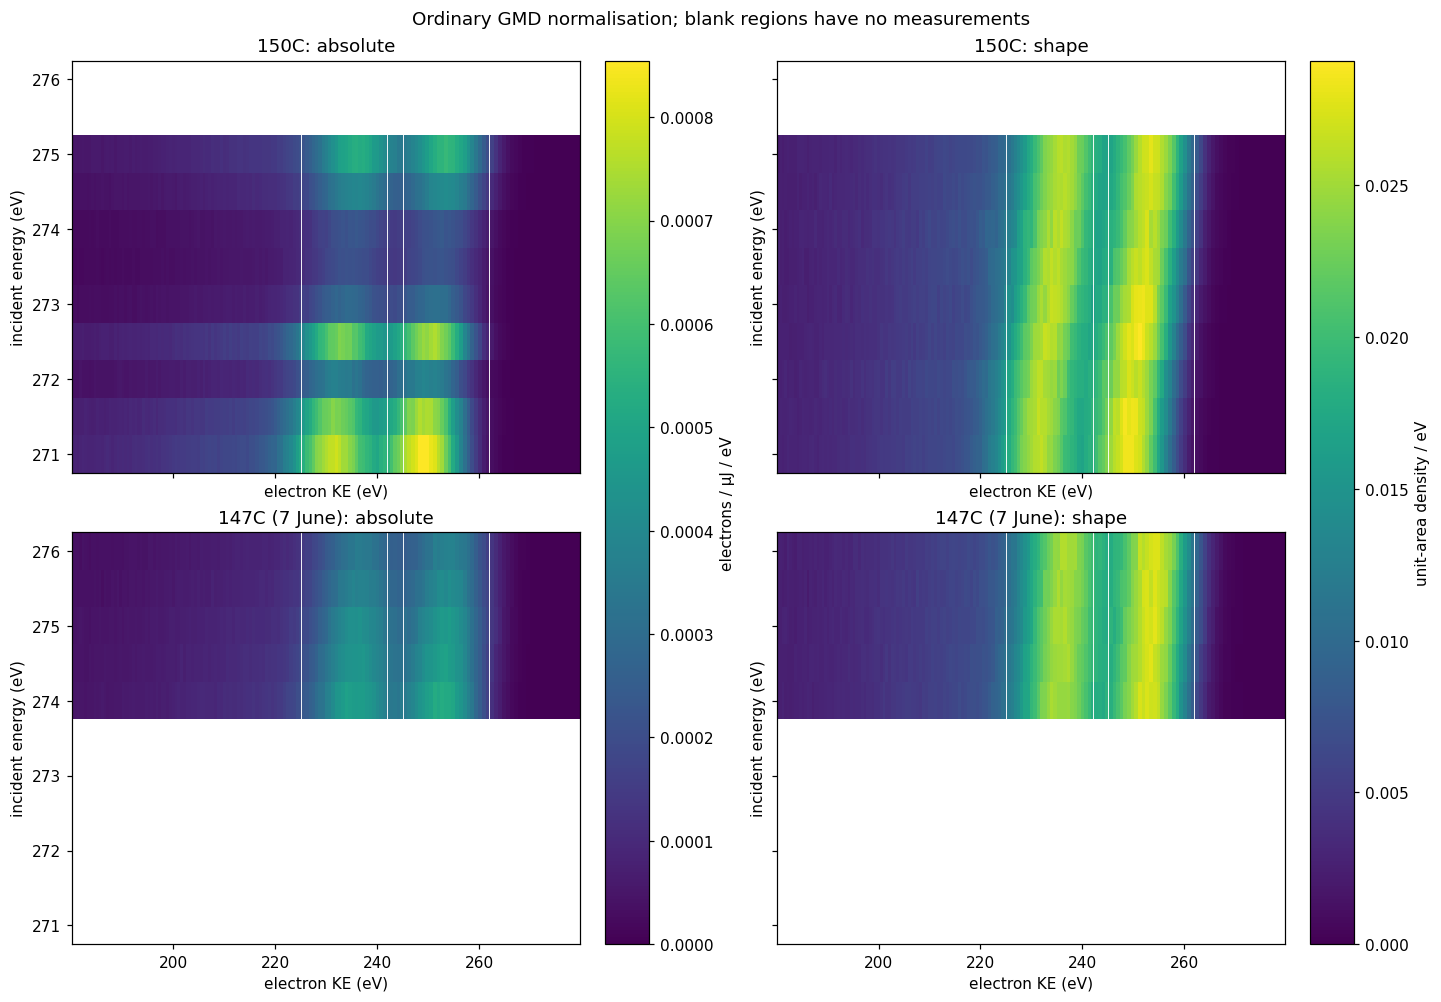

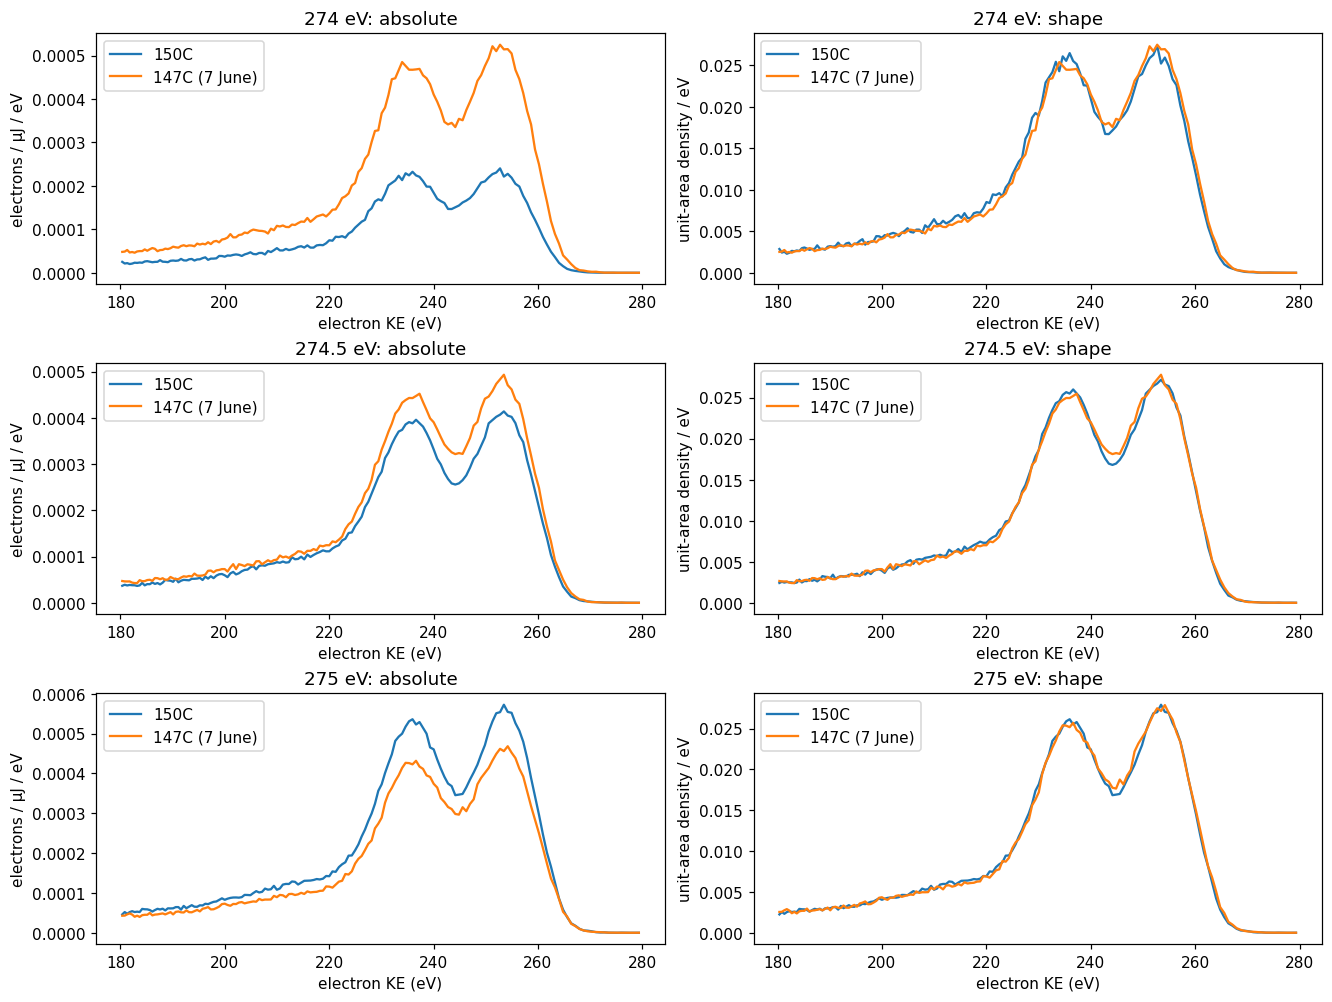

In [ ]:
# Compare absolute intensity with ONE colour scale and actual energy coverage.
# Independent shape normalisation is diagnostic only; no interpolation/smoothing.
cmp_maps = {}
for family, item in CMP_FAMILIES.items():
    ordered = sorted(item["results"], key=lambda r: r["photon_energy_ev"])
    edges = item["edges"]
    values = np.vstack([r["spectrum_gmd"] for r in ordered])
    area = np.sum(values * np.diff(edges)[None, :], axis=1)
    cmp_maps[family] = {
        "energy": np.array([r["photon_energy_ev"] for r in ordered]),
        "edges": edges, "absolute": values,
        "shape": cmp_reader.divide(values, area[:, None]), "area": area,
        "results": ordered,
    }
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True,
                         constrained_layout=True)
for col, kind in enumerate(["absolute", "shape"]):
    pooled = np.concatenate([m[kind].ravel() for m in cmp_maps.values()])
    vmax_cmp = np.nanmax(pooled)  # No percentile clipping of peak brightness.
    for row, (family, m) in enumerate(cmp_maps.items()):
        im = axes[row, col].pcolormesh(m["edges"], centres_to_edges(m["energy"]),
                                     m[kind], shading="flat", vmin=0, vmax=vmax_cmp)
        axes[row, col].set_title(f"{family}: {kind}")
        axes[row, col].set_xlabel("electron KE (eV)")
        axes[row, col].set_ylabel("incident energy (eV)")
        for lo, hi in CMP_FEATURE_WINDOWS:
            axes[row, col].axvspan(lo, hi, facecolor="none", edgecolor="white", lw=0.6)
    fig.colorbar(im, ax=axes[:, col], label=("electrons / µJ / eV" if col == 0 else "unit-area density / eV"))
fig.suptitle("Ordinary GMD normalisation; blank regions have no measurements")
plt.show()

# Shared-energy lineouts distinguish a common amplitude change from feature ratios.
fig, axes = plt.subplots(len(CMP_COMMON), 2, figsize=(12, 3 * len(CMP_COMMON)),
                         squeeze=False, constrained_layout=True)
for i, energy in enumerate(CMP_COMMON):
    for family, m in cmp_maps.items():
        index = np.flatnonzero(np.isclose(m["energy"], energy))[0]
        x = 0.5 * (m["edges"][:-1] + m["edges"][1:])
        for j, kind in enumerate(["absolute", "shape"]):
            axes[i, j].plot(x, m[kind][index], label=family, color=CMP_COLOURS[family])
            axes[i, j].set_title(f"{energy:g} eV: {kind}")
            axes[i, j].set_xlabel("electron KE (eV)")
            axes[i, j].set_ylabel("electrons / µJ / eV" if j == 0 else "unit-area density / eV")
            axes[i, j].legend()
plt.show()

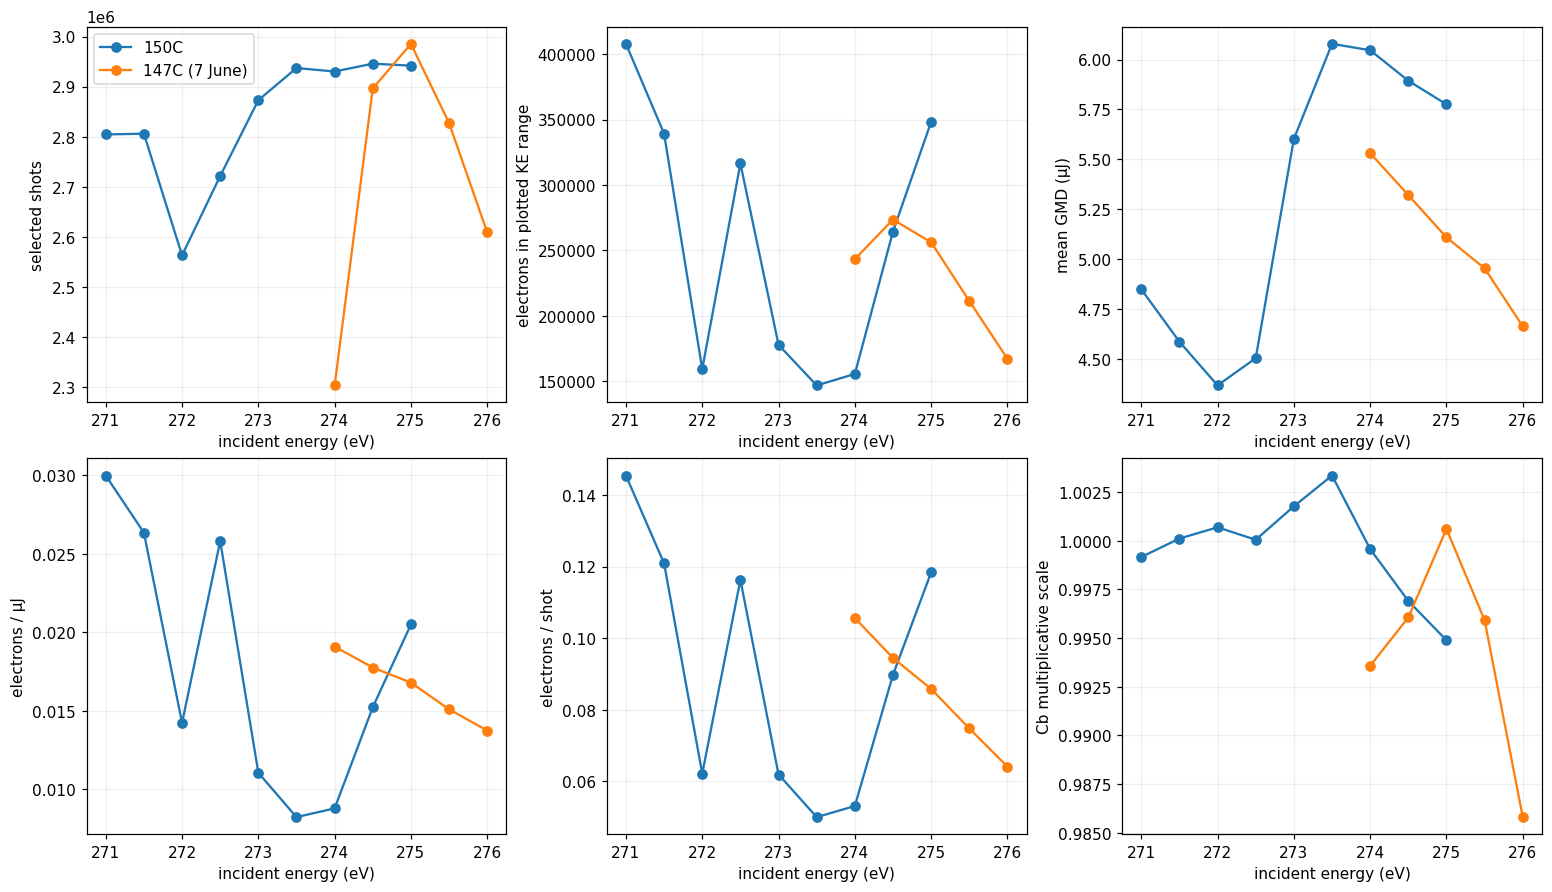

Cb rescales each complete spectrum here; it cannot remove changes in relative feature intensity.


In [ ]:
# Exposure and absolute yield from already-computed full production maps.
# Counts below are reconstructed from the saved normalised spectra and exposure.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for family, m in cmp_maps.items():
    rr = m["results"]
    shots_cmp = np.array([r["shots"] for r in rr])
    gmd_cmp = np.array([r["sum_gmd"] for r in rr])
    counts_cmp = m["area"] * gmd_cmp
    metrics = [shots_cmp, counts_cmp, cmp_reader.divide(gmd_cmp, shots_cmp),
               m["area"], cmp_reader.divide(counts_cmp, shots_cmp),
               np.array([r["correction_scale"] for r in rr])]
    for ax, values, label in zip(axes.flat, metrics,
            ["selected shots", "electrons in plotted KE range", "mean GMD (µJ)",
             "electrons / µJ", "electrons / shot", "Cb multiplicative scale"]):
        ax.plot(m["energy"], values, "o-", label=family, color=CMP_COLOURS[family])
        ax.set_ylabel(label)
        ax.set_xlabel("incident energy (eV)")
        ax.grid(alpha=0.2)
axes[0, 0].legend()
plt.show()
print("Cb rescales each complete spectrum here; it cannot remove changes in relative feature intensity.")

### Matched selections, electron/ion comparison and acquisition stability

The next reader makes one streamed pass per source, collecting both **1–12 µJ** and **3–4 µJ** groups, fixed and moving KE-window counts, electron/ion ratios, bunch profiles, delay exposure, and eight consecutive acquisition blocks. Blocks are defined on the original train-index axis before filtering. Monitors are averaged with selected-shot weights. Missing monitor/ion data remain missing, not zero.

**Default: 100 evenly spaced kept trains per run, for a small execution preview only.** Preview fluctuations are not evidence about the real maps. For the full result use the Slurm preparation cell below, then point `CMP_RESULT_FILE` to its output and rerun from the loading cell. Do not run the full pass on a Maxwell display/login node.

The plotted yield error bars use train-cluster ratio uncertainties (allowing shots within a train to covary). They do not account for slow inter-train drift or calibration/GMD systematics. Feature and electron/ion ratios are descriptive and are plotted without significance claims. Ion counts cover 0–50000 ns, while electrons cover the stated KE windows; their ratio is not a branching ratio. Windows are not background-subtracted.

In [ ]:
# Small preview OR load completed full-data Slurm results. No full scan here.
CMP_RESULT_FILE = None  # Path to the JSON result printed by the Slurm cell below.
if CMP_RESULT_FILE is None:
    cmp_preview_manifest = copy.deepcopy(cmp_manifest)
    cmp_preview_manifest["settings"]["max_trains"] = 100
    cmp_bundle = cmp_reader.run_manifest(cmp_preview_manifest)
else:
    with open(CMP_RESULT_FILE) as handle:
        cmp_bundle = json.load(handle)
    expected = copy.deepcopy(cmp_manifest)
    expected["settings"]["max_trains"] = cmp_bundle["manifest"]["settings"]["max_trains"]
    if cmp_bundle["manifest"] != expected:
        raise ValueError("Saved result settings/sources differ; inspect its manifest before comparing")
cmp_rows = cmp_bundle["rows"]
cmp_active = cmp_bundle["manifest"]["settings"]
cmp_status = "PREVIEW — 100 trains/run; do not interpret" if cmp_active["max_trains"] is not None else "FULL DATA"
cmp_nw = len(cmp_active["ke_windows"])
cmp_ion_index = 2 * cmp_nw
print(cmp_status)
for r in cmp_rows:
    ds = r["dataset"]
    print(f"{ds['family']:14s} {ds['photon_energy_ev']:5.1f} eV: "
          f"{r['read_trains']}/{r['kept_trains']} trains; run={r['run_no']}; "
          f"tID={r['train_id_range']}; monitors={r['available_monitors']}")

Reading 150C 271 eV


KeyboardInterrupt: 

In [ ]:
# Fixed versus broad GMD selections: do BOTH spectral features dip together?
fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
for family in CMP_FAMILIES:
    rr = sorted([r for r in cmp_rows if r["dataset"]["family"] == family],
                key=lambda r: r["dataset"]["photon_energy_ev"])
    energy = np.array([r["dataset"]["photon_energy_ev"] for r in rr])
    yy = np.array([r["yield"] for r in rr])
    se = np.array([r["train_se"] for r in rr])
    for g, g_range in enumerate(cmp_active["gmd_ranges"]):
        for j, metric in enumerate([0, 1, 2, cmp_ion_index]):
            axes[g, j].errorbar(energy, yy[:, g, metric], yerr=se[:, g, metric],
                               fmt="o-", capsize=2, label=family, color=CMP_COLOURS[family])
            axes[g, j].set_title(f"{g_range[0]:g}–{g_range[1]:g} µJ: " +
                                (["broad electron yield", "feature A", "feature B", "ion yield"][j]))
            axes[g, j].set_xlabel("incident energy (eV)")
            axes[g, j].set_ylabel("counts / µJ")
            axes[g, j].grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle(cmp_status + "; error bars: train-cluster SE")
plt.show()

# Use the common 274 eV reference, not different whole-scan averages.
# Tracking windows move by hν − 274 eV; neither rule assumes the feature's origin.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for family in CMP_FAMILIES:
    rr = sorted([r for r in cmp_rows if r["dataset"]["family"] == family],
                key=lambda r: r["dataset"]["photon_energy_ev"])
    energy = np.array([r["dataset"]["photon_energy_ev"] for r in rr])
    yy = np.array([r["yield"] for r in rr])[:, 1]  # Fixed 3–4 µJ group.
    ref = np.flatnonzero(np.isclose(energy, CMP_REFERENCE_ENERGY))
    for mode, offset in enumerate([0, cmp_nw]):
        for metric, style in [(1, "-"), (2, "--")]:
            relative = cmp_reader.divide(yy[:, offset + metric], yy[ref[0], offset + metric]) if len(ref) == 1 else np.full(len(energy), np.nan)
            axes[mode, 0].plot(energy, relative, "o" + style, color=CMP_COLOURS[family],
                               label=f"{family}, {'A' if metric == 1 else 'B'}")
        axes[mode, 1].plot(energy, cmp_reader.divide(yy[:, offset + 1], yy[:, offset + 2]),
                           "o-", label=family, color=CMP_COLOURS[family])
        axes[mode, 2].plot(energy, cmp_reader.divide(yy[:, offset], yy[:, cmp_ion_index]),
                           "o-", label=family, color=CMP_COLOURS[family])
for mode in range(2):
    for j, label in enumerate(["feature yield / its 274 eV yield", "feature A / feature B", "broad electrons / ions"]):
        axes[mode, j].set_title(("Fixed KE: " if mode == 0 else "Tracking KE: ") + label)
        axes[mode, j].set_xlabel("incident energy (eV)")
        axes[mode, j].grid(alpha=0.2)
        axes[mode, j].legend(fontsize=8)
fig.suptitle(cmp_status + "; fixed 3–4 µJ; ratios are descriptive")
plt.show()

print("Shared-energy 150C / 147C ratios, fixed 3–4 µJ, fixed KE (no extrapolation)")
print("energy    broad e      feature A     feature B      ions")
for energy in CMP_COMMON:
    matched = {r["dataset"]["family"]: np.asarray(r["yield"])[1]
               for r in cmp_rows if np.isclose(r["dataset"]["photon_energy_ev"], energy)}
    ratio = cmp_reader.divide(matched["150C"], matched["147C (7 June)"])
    print(f"{energy:6.1f}  " + "  ".join(f"{ratio[i]:12.5g}" for i in [0, 1, 2, cmp_ion_index]))

In [ ]:
# Run-by-run stability: a pooled map can hide yield changes during acquisition.
# Each curve is divided by its OWN whole-run yield to compare shared modulation.
fig, axes = plt.subplots(len(cmp_rows), 2, figsize=(13, 2.6 * len(cmp_rows)),
                         squeeze=False, constrained_layout=True)
for i, r in enumerate(cmp_rows):
    c = np.asarray(r["counts"])
    g = np.asarray(r["gmd"])
    n = np.asarray(r["shots"])
    yy = cmp_reader.divide(c[:, 1], g[:, 1, None])
    total = np.asarray(r["yield"])[1]
    x = np.arange(len(g)) + 1
    for metric, label in [(1, "feature A"), (2, "feature B"), (cmp_ion_index, "ions")]:
        axes[i, 0].plot(x, cmp_reader.divide(yy[:, metric], total[metric]), "o-", label=label)
    axes[i, 0].axhline(1, color="k", lw=0.6)
    axes[i, 1].plot(x, cmp_reader.divide(c[:, 1, 1], c[:, 1, 2]), "o-", label="A/B")
    ds = r["dataset"]
    for ax in axes[i]:
        ax.set_title(f"{ds['family']}, {ds['photon_energy_ev']:g} eV")
        ax.set_xlabel("consecutive acquisition block")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    axes[i, 0].set_ylabel("yield / whole-run yield")
    axes[i, 1].set_ylabel("feature A / B")
fig.suptitle(cmp_status + "; fixed 3–4 µJ; gaps denote empty selections")
plt.show()

# Beam/DAQ diagnostics at the same incident energy in both families.
CMP_MONITOR_ENERGY = 274.0
cmp_selected_runs = [r for r in cmp_rows if np.isclose(r["dataset"]["photon_energy_ev"], CMP_MONITOR_ENERGY)]
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for r in cmp_selected_runs:
    family = r["dataset"]["family"]
    n, g = np.asarray(r["shots"])[:, 1], np.asarray(r["gmd"])[:, 1]
    c = np.asarray(r["counts"])[:, 1]
    vals = [cmp_reader.divide(g, n), n, cmp_reader.divide(c[:, -1], n)]
    labels = ["mean selected GMD (µJ)", "selected shots", "fraction with all eTOF slots filled"]
    for key in ["hor_pos", "ver_pos", "mpe", "shutter", "local_DAQ_running"]:
        vals.append(np.asarray(r["monitors"][key])[:, 1])
        labels.append(key + " (selected-shot weighted)")
    for ax, v, label in zip(axes.flat, vals, labels):
        ax.plot(np.arange(len(v)) + 1, v, "o-", label=family, color=CMP_COLOURS[family])
        ax.set_title(label, fontsize=9)
        ax.set_xlabel("acquisition block")
        ax.grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle(f"{cmp_status}; {CMP_MONITOR_ENERGY:g} eV, fixed 3–4 µJ; missing monitors give no curve")
plt.show()
print("MPE is a monitor, not a replacement for nominal scan energy. Shutter polarity is not inferred here.")

In [ ]:
# Compare bunch and delay mixing at matched energies without imposing corrections.
# Both distributions and yields matter: exposure differences alone do not establish bias.
fig, axes = plt.subplots(len(CMP_COMMON), 4, figsize=(17, 3 * len(CMP_COMMON)),
                         squeeze=False, constrained_layout=True)
for i, energy in enumerate(CMP_COMMON):
    for r in cmp_rows:
        if not np.isclose(r["dataset"]["photon_energy_ev"], energy):
            continue
        family = r["dataset"]["family"]
        col = CMP_COLOURS[family]
        bn = np.asarray(r["bunch_shots"])[1]
        bg = np.asarray(r["bunch_gmd"])[1]
        bc = np.asarray(r["bunch_counts"])[1]
        dn = np.asarray(r["delay_shots"])[1]
        dg = np.asarray(r["delay_gmd"])[1]
        de = np.asarray(r["delay_e"])[1]
        dax = 0.5 * (np.array(cmp_active["delay_edges_fs"][:-1]) + np.array(cmp_active["delay_edges_fs"][1:]))
        axes[i, 0].plot(cmp_reader.divide(bn, bn.sum()), color=col, label=family)
        for metric, style in [(1, "-"), (2, "--")]:
            by = cmp_reader.divide(bc[:, metric], bg)
            by = cmp_reader.divide(by, np.asarray(r["yield"])[1, metric])
            axes[i, 1].plot(by, style, color=col, label=f"{family} {'A' if metric == 1 else 'B'}")
        axes[i, 2].plot(dax, cmp_reader.divide(dg, np.asarray(r["gmd"])[:, 1].sum()), "o-", color=col, label=family)
        axes[i, 3].plot(dax, cmp_reader.divide(de, dg), "o-", color=col, label=family)
        print(f"{family} {energy:g} eV: missing delay shots={np.asarray(r['delay_missing'])[1]:g}; "
              f"outside plotted delay range={np.asarray(r['delay_outside'])[1]:g}")
    for j, label in enumerate(["selected shot fraction", "feature yield / run yield", "fraction of total GMD exposure", "broad electrons / µJ"]):
        axes[i, j].set_title(f"{energy:g} eV: {label}", fontsize=9)
        axes[i, j].set_xlabel("bunch index" if j < 2 else "delay (fs)")
        axes[i, j].legend(fontsize=7)
        axes[i, j].grid(alpha=0.2)
fig.suptitle(cmp_status + "; fixed 3–4 µJ; all selected shots retained in totals")
plt.show()

### Full-data execution on Slurm

Run this preparation cell to write a timestamped manifest under the processed results directory and print a submission command. It **does not submit a job**. Supply your normal Maxwell partition/account options if required. The job reads the combined HDF5 files in chunks with one process and writes only a compact JSON summary. After completion, set `CMP_RESULT_FILE` above to the printed result path and rerun the loading and diagnostic plots. Reuse the result for plotting; there is no need to reread the sources.

Changing windows, bunch selection, delay cuts or calibration requires a fresh full result. The manifest check prevents accidentally plotting an old result under new settings.

In [ ]:
# Prepare a reproducible full scan for a compute node; no job submission here.
cmp_full_manifest = copy.deepcopy(cmp_manifest)
cmp_full_manifest["settings"]["max_trains"] = None
cmp_output_dir = Path(config.COMBINED_DIR).parent / "results" / "incident_yield_comparison"
cmp_output_dir.mkdir(parents=True, exist_ok=True)
cmp_stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
cmp_manifest_file = cmp_output_dir / f"comparison_{cmp_stamp}_manifest.json"
cmp_result_file = cmp_output_dir / f"comparison_{cmp_stamp}_results.json"
with cmp_manifest_file.open("x") as handle:
    json.dump(cmp_full_manifest, handle, indent=2)
cmp_python = repo_root / ".venv" / "bin" / "python"
cmp_command = shlex.join([str(cmp_python), str(cmp_module_path),
                          str(cmp_manifest_file), str(cmp_result_file)])
print("Submit from your terminal, adding your usual partition/account options if needed:")
print("sbatch --job-name=yield-compare --cpus-per-task=1 --mem=4G --time=02:00:00 "
      + "--output=" + shlex.quote(str(cmp_output_dir / f"comparison_{cmp_stamp}_%j.log"))
      + " --wrap=" + shlex.quote(cmp_command))
print("After completion, set CMP_RESULT_FILE =", repr(str(cmp_result_file)))

### How to interpret the comparison

- **Both feature yields dip, but A/B and unit-area shapes remain stable:** a common amplitude change dominates. Look for matching ion changes, acquisition drift, sample/beam overlap and transmission evidence. This does not identify which mechanism is responsible.
- **A/B or the unit-area shapes also change:** a common scale factor is insufficient. Compare the fixed and tracking windows and inspect the matched-energy spectra before assigning a spectral mechanism.
- **Electrons and ions dip together:** investigate common acquisition/sample/illumination changes; this alone does not prove a density change. A varying e/i ratio indicates that a single common factor is not the whole description.
- **Within-run feature yields move together in consecutive blocks:** compare with the monitor and delay plots. Block changes can also follow a repeated delay scan, so block trends alone do not establish temporal drift.
- **Bunch response or delay exposure differs between families:** test a common restricted selection or matched delay/bunch weighting as a separate sensitivity analysis, rather than silently modifying the main map.
- **Only preview results fluctuate:** collect the full result before drawing conclusions. Train-cluster errors still omit slow drift and calibration systematics.

Different energy ranges are fine for plotting each scan. Direct statements that one family is stronger/weaker require matched energies; the absent 147C 271.5–273.5 eV measurements remain an experimental limitation. Nominal energy and acquisition time can be confounded when each energy comes from a different run. Smoothness of the 147C map does not by itself establish the expected physical intensity of the 150C map.

## Full-run chronology and independent-monitor diagnostics

**Question:** is the 150C amplitude modulation consistent with acquisition chronology or a common experimental factor, and does broad iTOF track it well enough to motivate a later correction?

This independent section reads the 150C 271.5–275.0 eV and 7 June / 147C 274.0–276.5 eV source files selected by `CB_AGG_FILENAMES` and `J7_AGG_FILENAMES`, using aggregate provenance. It prints the actual available energies and paths; missing energies are not invented. Execute the two filename-selection/loading cells first; it needs no earlier spectra or preview results. Feature definitions reuse `CMP_WINDOWS` when available, otherwise the identical earlier definitions (broad 180–280, A 225–242, B 245–262 eV). Calibration and paths use the project configuration.

Selections: raw GMD **3–4 µJ**, the same valid-train/trim rule as the preceding analysis, and the preceding comparison's bunch/delay choices if defined. Defaults are bunches 0–100 and all delays. No Cb, smoothing, interpolation or ion correction. All selection parameters are printed and recorded.

**Full data only.** Set `CHRON_EXECUTION_MODE = "local"` (the default) to run the chunked, single-process analysis directly in this notebook kernel. Set it to `"slurm"` to prepare a batch command and load its completed output. In either mode, an optional `CHRON_RESULT_FILE` reuses an existing matching result instead of recomputing. Local mode keeps the result in memory and needs no job submission or result file. No sampled preview is substituted for the full result.

Eight blocks contain equal numbers (within one train) of **valid, trimmed trains sorted by tID**, before the raw-GMD shot cut. tID is an acquisition-order proxy, not a timestamp in seconds. Gaps remain visible; no repetition rate is assumed. Nonpositive, missing or duplicate tIDs are flagged: those files remain in energy-domain diagnostics but are excluded from time-ordered plots. Their blocks retain source-row order, and train-cluster errors are suppressed because train identity is unverified. Source ordering is reported, and only small per-train summaries are sorted, keeping hits/GMD/monitors aligned.

In [ ]:
# Independent setup: reuse existing feature definitions and explicit selections.
CHRON_EXECUTION_MODE = "local"  # "local": this notebook kernel; "slurm": batch job.
CHRON_RESULT_FILE = None  # Optional existing results.json to reuse in either mode.
if CHRON_EXECUTION_MODE not in {"local", "slurm"}:
    raise ValueError('CHRON_EXECUTION_MODE must be "local" or "slurm"')

import os as chron_os
import sys as chron_sys
import json as chron_json
import copy as chron_copy
import shlex as chron_shlex
import importlib.util as chron_importlib
from pathlib import Path as ChronPath
from datetime import datetime as ChronDatetime
import numpy as chron_np
import matplotlib.pyplot as chron_plt

chron_root = next((q for q in [ChronPath.cwd().resolve(), *ChronPath.cwd().resolve().parents]
                   if (q / "analysis" / "scripts" / "config.py").is_file()), None)
if chron_root is None:
    raise RuntimeError("Open this notebook inside the glycine26 repository")
for chron_dir in [chron_root / "analysis" / "scripts", chron_root / "analysis" / "post"]:
    if str(chron_dir) not in chron_sys.path:
        chron_sys.path.insert(0, str(chron_dir))
chron_os.environ.setdefault("FLASH_ENV", "remote")
import config as chron_config
chron_module_path = chron_root / "analysis" / "post" / "incident_chronology.py"
chron_spec = chron_importlib.spec_from_file_location("incident_chronology_current", chron_module_path)
chron_reader = chron_importlib.module_from_spec(chron_spec)
chron_spec.loader.exec_module(chron_reader)
chron_calibration_path = ChronPath(chron_config.COMBINED_DIR).parent / "Calibrations" / "etof_energy_calibration_t0_scan.json"
with chron_calibration_path.open() as chron_handle:
    chron_calibration = chron_json.load(chron_handle)
chron_previous_settings = globals().get("cmp_settings", {})
CHRON_WINDOWS = [list(w) for w in globals().get("CMP_WINDOWS", [(180.,280.), (225.,242.), (245.,262.), (180.,220.)])][:3]
chron_settings = {
    "calibration": {k:float(chron_calibration[k]) for k in ("t0_tof_units", "slope_eV_tof_unit2", "E0_eV")},
    "ke_windows": CHRON_WINDOWS, "gmd_range": [3.,4.],
    "bunch_range": list(chron_previous_settings.get("bunch_range", [0,101])),
    "delay_stage_range": chron_previous_settings.get("delay_stage_range", None),
    "ion_tof_range": list(chron_previous_settings.get("ion_tof_range", [0.,50000.])),
    "n_blocks": 8, "chunk_trains": 250, "max_trains": None,
}
# Use the notebook's explicit file choices, including long-scan replacements.
# Execute CB_AGG_FILENAMES and the J7 dataset-loading cell before this setup.
import h5py as chron_h5py
import re as chron_re

if "CB_AGG_FILENAMES" not in globals() or "J7_AGG_FILENAMES" not in globals():
    raise RuntimeError("Run the CB_AGG_FILENAMES cell and the J7 dataset-loading cell first.")
chron_datasets = []
for chron_family, chron_filenames in [
    ("150C", CB_AGG_FILENAMES), ("147C (7 June)", J7_AGG_FILENAMES)
]:
    if not chron_filenames:
        raise ValueError(f"No aggregate files selected for {chron_family}.")
    for chron_filename in chron_filenames:
        chron_agg_path = ChronPath(chron_filename)
        if not chron_agg_path.is_absolute():
            chron_agg_path = ChronPath(chron_config.COMBINED_DIR) / chron_agg_path
        chron_match = chron_re.search(r"([0-9]+(?:\.[0-9]+)?)eV", chron_agg_path.name)
        if chron_match is None:
            raise ValueError(f"Cannot read photon energy from {chron_agg_path.name}")
        with chron_h5py.File(chron_agg_path, "r") as chron_agg:
            chron_source = chron_agg.attrs.get("input_h5", "")
            if isinstance(chron_source, bytes):
                chron_source = chron_source.decode()
            if not chron_source or not ChronPath(chron_source).is_file():
                raise FileNotFoundError(f"{chron_agg_path.name}: missing source input_h5={chron_source!r}")
            chron_datasets.append({
                "family": chron_family,
                "photon_energy_ev": float(chron_match[1]),
                "source_h5": str(chron_source), "agg_path": str(chron_agg_path),
                "trim_start": int(chron_agg.attrs.get("trim_start", 0) or 0),
                "trim_end": int(chron_agg.attrs.get("trim_end", 0) or 0),
            })
chron_dataset_keys = [(d["family"], d["photon_energy_ev"]) for d in chron_datasets]
if len(chron_dataset_keys) != len(set(chron_dataset_keys)):
    raise ValueError("Duplicate energies within a family: choose one scan file per energy.")
chron_manifest = {"datasets":chron_datasets, "settings":chron_settings}
chron_families = list(dict.fromkeys(d["family"] for d in chron_datasets))
chron_colours = {"150C":"tab:blue", "147C (7 June)":"tab:orange"}
print("Diagnostic settings:", chron_json.dumps(chron_settings, indent=2))
for chron_family in chron_families:
    chron_es = [d["photon_energy_ev"] for d in chron_datasets if d["family"]==chron_family]
    print(chron_family, "available energies:", chron_es)
for chron_ds in chron_datasets:
    print(chron_ds["family"], chron_ds["photon_energy_ev"], chron_ds["source_h5"])

Diagnostic settings: {
  "calibration": {
    "t0_tof_units": 70.31711711711705,
    "slope_eV_tof_unit2": 172656057.91151598,
    "E0_eV": -32.01574693372097
  },
  "ke_windows": [
    [
      180.0,
      280.0
    ],
    [
      225.0,
      242.0
    ],
    [
      245.0,
      262.0
    ]
  ],
  "gmd_range": [
    3.0,
    4.0
  ],
  "bunch_range": [
    0,
    101
  ],
  "delay_stage_range": null,
  "ion_tof_range": [
    0.0,
    50000.0
  ],
  "n_blocks": 8,
  "chunk_trains": 250,
  "max_trains": null
}
150C available energies: [271.0, 271.5, 272.0, 272.5, 273.0, 273.5, 274.0, 274.5, 275.0]
147C (7 June) available energies: [274.0, 274.5, 275.0, 275.5, 276.0]
150C 271.0 /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long_271.0eV.h5
150C 271.5 /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long_271.5eV.h5
150C 272.0 /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long

Diagnostic chronology: duration is tID span, NOT elapsed seconds
order series          hν    start_tID     end_tID      mean_tID      median_tID   span    valid trains filename
1 150C 272.5 2660200723 2660234935 2660217917.8875 2660217966.0 34212 32791 glycine_delay_scan_150C_272.5eV.h5
2 150C 273.0 2660236291 2660272294 2660254028.003119 2660252924.5 36003 32704 glycine_delay_scan_150C_273.0eV.h5
3 150C 273.5 2660273842 2660307412 2660290490.3844028 2660290426.5 33570 32890 glycine_delay_scan_150C_273.5eV.h5
4 150C 274.0 2660308301 2660342005 2660325000.875625 2660324823.5 33704 32788 glycine_delay_scan_150C_274.0eV.h5
5 150C 274.5 2660383854 2660418534 2660400688.5992293 2660400333.0 34680 32707 glycine_delay_scan_150C_274.5eV.h5
6 150C 275.0 2660419938 2660455370 2660438147.777039 2660438359.0 35432 32795 glycine_delay_scan_150C_275.0eV.h5
7 150C 271.5 2660457108 2660492126 2660474739.1447735 2660474717.5 35018 34364 glycine_delay_scan_150C_long_271.5eV.h5
8 150C 271.0 2660493894 26

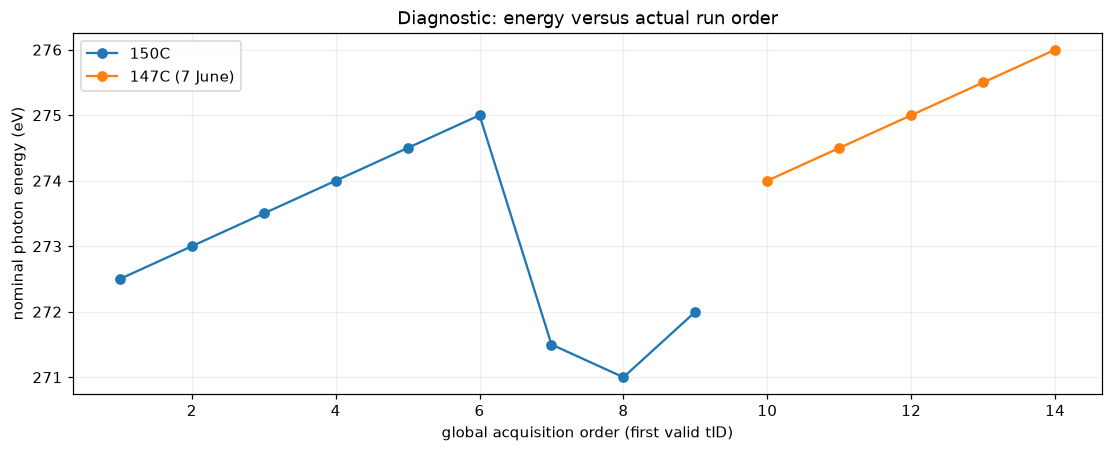

If photon energy is monotonic in time, visual smoothness in either order cannot separate drift from spectroscopy.


In [ ]:
# Lightweight actual chronology: only tID and bounded metadata are read here.
chron_headers = [chron_reader.inspect_chronology(d) for d in chron_datasets]
chron_headers.sort(key=lambda r:(r["start_tid"] is None, r["start_tid"] or 0))
print("Diagnostic chronology: duration is tID span, NOT elapsed seconds")
print("order series          hν    start_tID     end_tID      mean_tID      median_tID   span    valid trains filename")
for chron_order, chron_r in enumerate(chron_headers, 1):
    chron_d = chron_r["dataset"]
    chron_span = chron_r["end_tid"]-chron_r["start_tid"] if chron_r["start_tid"] is not None else None
    print(chron_order if chron_r["chronology_valid"] else "unplaced", chron_d["family"], chron_d["photon_energy_ev"], chron_r["start_tid"], chron_r["end_tid"],
          chron_r["tid"]["mean"], chron_r["tid"]["median"], chron_span, chron_r["valid_trains"], ChronPath(chron_d["source_h5"]).name)
    if not chron_r["chronology_valid"]:
        print("  CHRONOLOGY UNAVAILABLE:",chron_r["chronology_issue"],"duplicate rows=",chron_r["duplicate_tid_rows"],"nonpositive IDs=",chron_r["nonpositive_tid_rows"])
    elif not chron_r["source_tid_monotonic"]:
        print("  Source tIDs are not strictly increasing: small summaries will be reordered by tID.")
# Check overlaps against all earlier runs, not just adjacent endpoints.
for chron_i, chron_r in enumerate(chron_headers):
    for chron_prior in chron_headers[:chron_i]:
        if chron_r["start_tid"] is not None and chron_prior["end_tid"] is not None and chron_r["start_tid"]<=chron_prior["end_tid"]:
            print("OVERLAPPING tID RANGES:", ChronPath(chron_prior["dataset"]["source_h5"]).name,
                  ChronPath(chron_r["dataset"]["source_h5"]).name, "— verify provenance before treating runs as independent.")
chron_fig, chron_ax = chron_plt.subplots(figsize=(10,4), constrained_layout=True)
for chron_family in chron_families:
    chron_points = [(i+1,r) for i,r in enumerate(chron_headers) if r["dataset"]["family"]==chron_family and r["chronology_valid"]]
    chron_ax.plot([i for i,r in chron_points], [r["dataset"]["photon_energy_ev"] for i,r in chron_points],
                  "o-", label=chron_family, color=chron_colours[chron_family])
chron_ax.set(xlabel="global acquisition order (first valid tID)", ylabel="nominal photon energy (eV)",
             title="Diagnostic: energy versus actual run order")
chron_ax.legend(); chron_ax.grid(alpha=0.2); chron_plt.show()
print("If photon energy is monotonic in time, visual smoothness in either order cannot separate drift from spectroscopy.")

In [ ]:
# Local mode needs no job files. Slurm mode prepares a command without submitting.
if CHRON_EXECUTION_MODE not in {"local", "slurm"}:
    raise ValueError('CHRON_EXECUTION_MODE must be "local" or "slurm"')
if CHRON_RESULT_FILE is not None:
    print("The next cell will reuse:", CHRON_RESULT_FILE)
elif CHRON_EXECUTION_MODE == "local":
    print("Local mode: the next cell runs the full chunked analysis in this notebook.")
else:
    chron_output_dir = ChronPath(chron_config.COMBINED_DIR).parent / "results" / "incident_chronology"
    chron_output_dir.mkdir(parents=True, exist_ok=True)
    chron_stamp = ChronDatetime.now().strftime("%Y%m%d_%H%M%S_%f")
    chron_manifest_path = chron_output_dir / f"chronology_{chron_stamp}_manifest.json"
    chron_output_path = chron_output_dir / f"chronology_{chron_stamp}_results.json"
    with chron_manifest_path.open("x") as chron_handle:
        chron_json.dump(chron_manifest, chron_handle, indent=2)
    chron_command = chron_shlex.join([str(chron_root / ".venv" / "bin" / "python"),
                                     str(chron_module_path), str(chron_manifest_path), str(chron_output_path)])
    print("Submit in a terminal, adding your usual partition/account options if needed:")
    print("sbatch --job-name=chronology --cpus-per-task=1 --mem=4G --time=02:00:00 "
          + "--output=" + chron_shlex.quote(str(chron_output_dir / f"chronology_{chron_stamp}_%j.log"))
          + " --wrap=" + chron_shlex.quote(chron_command))
    print("Then set CHRON_RESULT_FILE =", repr(str(chron_output_path)))

Local mode: the next cell runs the full chunked analysis in this notebook.


In [ ]:
# Run locally or load a completed result; both modes use the same full-data reader.
if CHRON_EXECUTION_MODE not in {"local", "slurm"}:
    raise ValueError('CHRON_EXECUTION_MODE must be "local" or "slurm"')
if CHRON_RESULT_FILE is not None:
    with open(CHRON_RESULT_FILE) as chron_handle:
        chron_bundle = chron_json.load(chron_handle)
elif CHRON_EXECUTION_MODE == "local":
    print("Running full data locally; chunk size:", chron_settings["chunk_trains"], "trains")
    # Match the JSON representation used by Slurm, including null for missing values.
    chron_bundle = chron_reader.clean_json(chron_reader.run(chron_manifest))
else:
    raise RuntimeError("Run the printed Slurm command, set CHRON_RESULT_FILE, then rerun this cell")
if chron_bundle.get("schema") != "incident_chronology_v1" or chron_bundle["manifest"] != chron_manifest:
    raise ValueError("Result provenance/settings differ from this section; inspect the manifest")
chron_rows = chron_bundle["rows"]
if len(chron_rows)!=len(chron_datasets) or not all(r.get("full_data") for r in chron_rows):
    raise ValueError("Expected full results for every discovered source")
chron_rows.sort(key=lambda r:(r["start_tid"] is None,r["start_tid"] or 0))
chron_order_by_source = {r["dataset"]["source_h5"]:i+1 for i,r in enumerate(r for r in chron_rows if r["chronology_valid"])}

def chron_value(r, metric, block=None):
    value = (r["whole"] if block is None else r["blocks"][block])["metrics"][metric]["value"]
    return float(value) if value is not None else chron_np.nan

def chron_monitor(r, key, statistic="mean", block=None):
    value = (r["whole"] if block is None else r["blocks"][block])["monitors"][key][statistic]
    return float(value) if value is not None else chron_np.nan

print("Full-data selected exposure; train mask then raw GMD 3–4 µJ")
print("order series hν valid_trains selected_trains selected_shots start_tID end_tID median_tID filename")
for chron_r in chron_rows:
    chron_d,chron_w = chron_r["dataset"],chron_r["whole"]
    print(chron_order_by_source.get(chron_d["source_h5"],chron_np.nan),chron_d["family"],chron_d["photon_energy_ev"],
          chron_w["valid_trains"],chron_w["selected_trains"],chron_w["shots"],chron_w["start_tid"],
          chron_w["end_tid"],chron_w["tid"]["median"],ChronPath(chron_d["source_h5"]).name)

Running full data locally; chunk size: 250 trains
Full chronology: 150C 271 eV
Full chronology: 150C 271.5 eV
Full chronology: 150C 272 eV
Full chronology: 150C 272.5 eV
Full chronology: 150C 273 eV
Full chronology: 150C 273.5 eV
Full chronology: 150C 274 eV
Full chronology: 150C 274.5 eV
Full chronology: 150C 275 eV
Full chronology: 147C (7 June) 274 eV
Full chronology: 147C (7 June) 274.5 eV
Full chronology: 147C (7 June) 275 eV
Full chronology: 147C (7 June) 275.5 eV
Full chronology: 147C (7 June) 276 eV
Full-data selected exposure; train mask then raw GMD 3–4 µJ
order series hν valid_trains selected_trains selected_shots start_tID end_tID median_tID filename
1 150C 272.5 32791 32781 395602 2660200723 2660234935 2660217966.0 glycine_delay_scan_150C_272.5eV.h5
2 150C 273.0 32704 32598 357425 2660236291 2660272294 2660252924.5 glycine_delay_scan_150C_273.0eV.h5
3 150C 273.5 32890 32879 331289 2660273842 2660307412 2660290426.5 glycine_delay_scan_150C_273.5eV.h5
4 150C 274.0 32788 3273

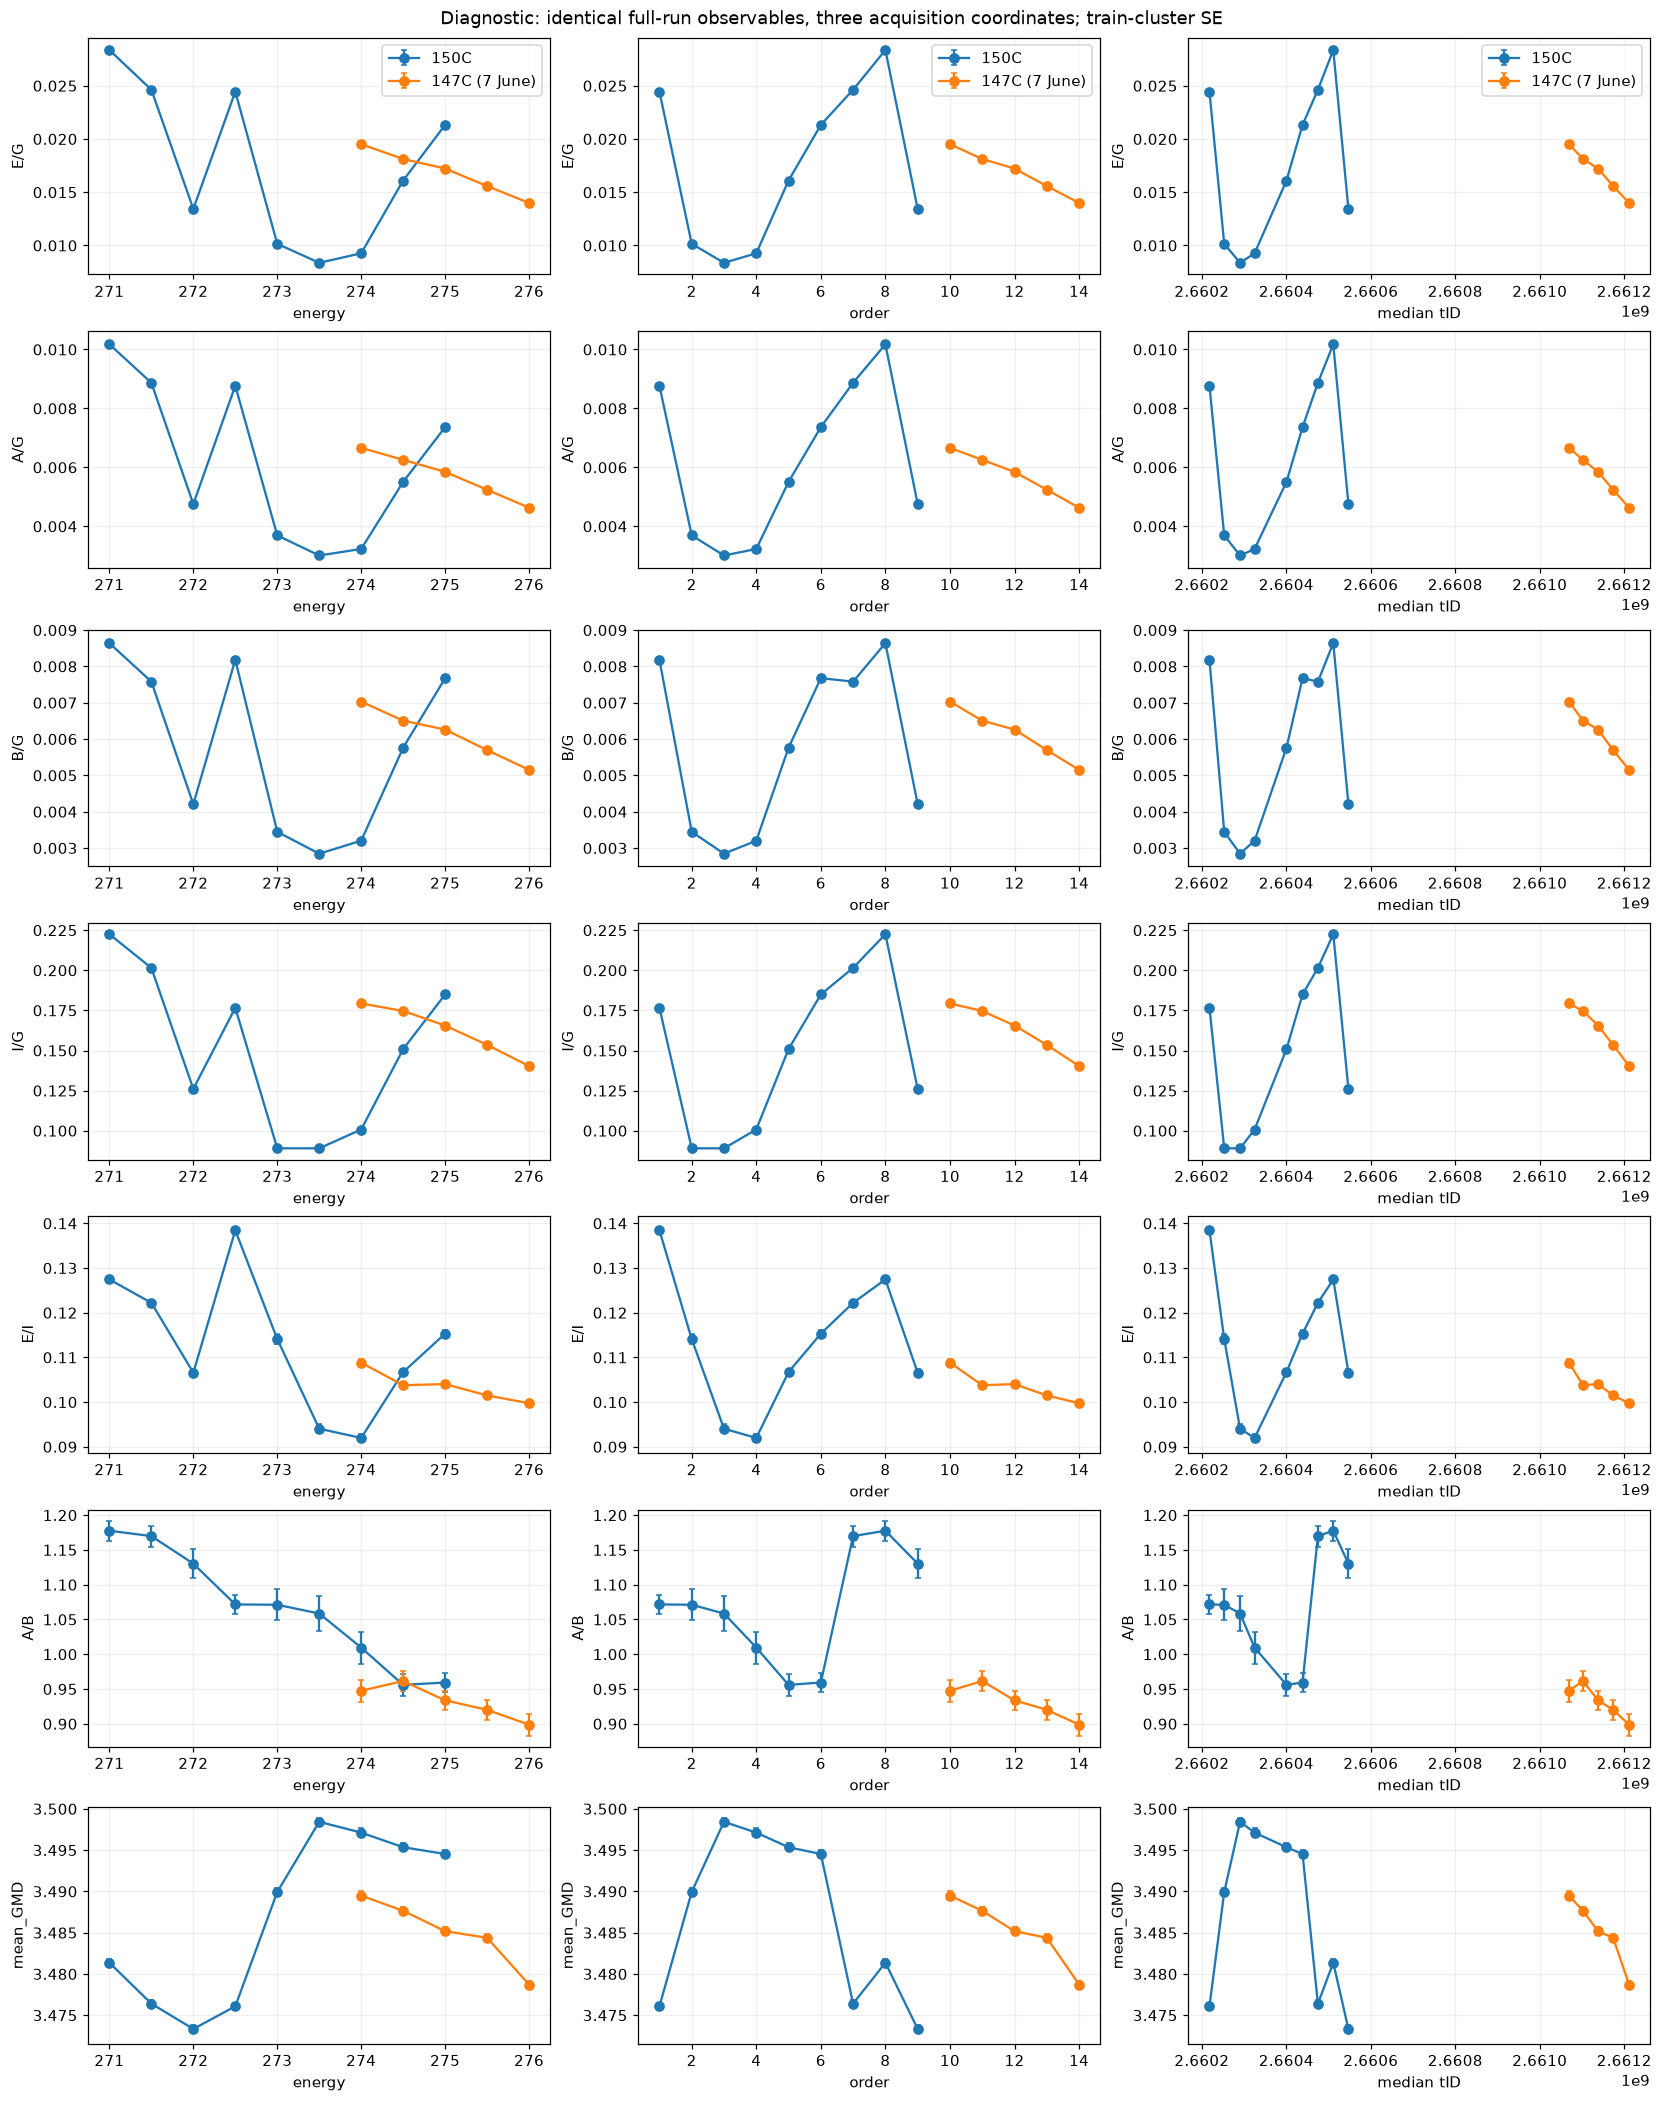

In [ ]:
# Identical observables against energy, chronology and median train ID.
chron_observables = ["E/G","A/G","B/G","I/G","E/I","A/B","mean_GMD"]
chron_fig,chron_axes = chron_plt.subplots(len(chron_observables),3,figsize=(15,19),constrained_layout=True)
for chron_col,chron_axis in enumerate(["energy","order","median tID"]):
    for chron_family in chron_families:
        chron_rr = [r for r in chron_rows if r["dataset"]["family"]==chron_family and (chron_axis=="energy" or r["chronology_valid"])]
        if chron_axis=="energy":
            chron_rr.sort(key=lambda r:r["dataset"]["photon_energy_ev"])
        chron_x = [r["dataset"]["photon_energy_ev"] if chron_axis=="energy" else
                   chron_order_by_source.get(r["dataset"]["source_h5"],chron_np.nan) if chron_axis=="order" else
                   r["whole"]["tid"]["median"] for r in chron_rr]
        for chron_j,chron_metric in enumerate(chron_observables):
            chron_y = [chron_value(r,chron_metric) for r in chron_rr]
            chron_err = chron_np.array([r["whole"]["metrics"][chron_metric]["se"] for r in chron_rr],float)
            chron_axes[chron_j,chron_col].errorbar(chron_x,chron_y,yerr=chron_err,fmt="o-",capsize=2,
                                                  label=chron_family,color=chron_colours[chron_family])
            chron_axes[chron_j,chron_col].set(xlabel=chron_axis,ylabel=chron_metric)
            chron_axes[chron_j,chron_col].grid(alpha=0.2)
    chron_axes[0,chron_col].legend()
chron_fig.suptitle("Diagnostic: identical full-run observables, three acquisition coordinates; train-cluster SE")
chron_plt.show()

Diagnostic monitor summary: trains with >=1 selected shot, equal train weights
series hν hor_mean hor_std hor_median hor_MAD ver_mean ver_std ver_median ver_MAD mpe_mean mpe_median meanG E/G I/G
150C 272.5 -0.181399 0.059582 -0.170999 0.0380607 -0.810018 0.0831065 -0.814746 0.0591549 271.117 272.52 3.47609 0.0244519 0.176625
150C 273.0 0.0715329 0.0450116 0.0835009 0.0245774 -0.89604 0.0794056 -0.907091 0.0547613 272.709 272.809 3.48993 0.010158 0.0890235
150C 273.5 -0.00684223 0.0451171 0.00138511 0.0287238 -0.879472 0.0763689 -0.884667 0.0569298 271.661 272.866 3.49843 0.00837193 0.0890205
150C 274.0 -0.00594267 0.0366927 0.00106263 0.0240074 -0.881154 0.0734102 -0.889403 0.0517891 273.344 273.347 3.49712 0.0092662 0.100744
150C 274.5 -0.0187759 0.0393468 -0.0106521 0.0227968 -0.891992 0.0735177 -0.901001 0.0493951 272.688 273.766 3.49535 0.0160983 0.150854
150C 275.0 -0.0420208 0.0466344 -0.028817 0.0279601 -0.885651 0.0759882 -0.898487 0.0517293 272.901 274.151 3.49453 0.0213245 0.

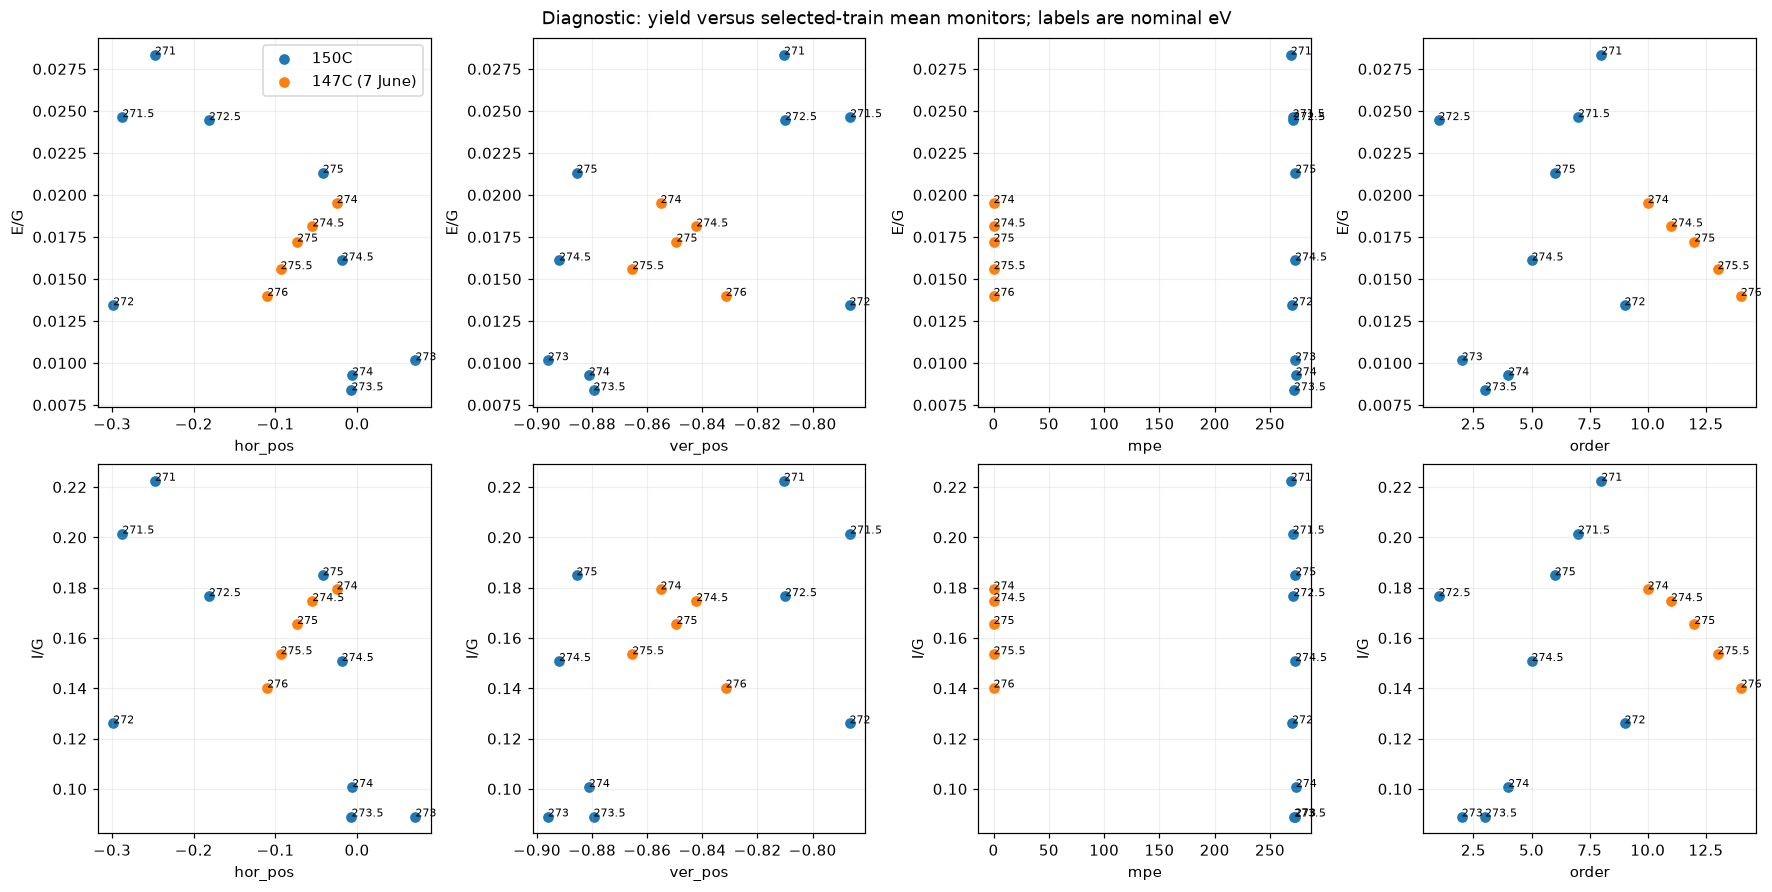

Diagnostic Pearson correlations; small n, shared trends/confounding, no causal interpretation
scope predictor observable n Pearson_r
150C hor_pos E/G 9 -0.6468
150C hor_pos I/G 9 -0.6451
150C ver_pos E/G 9 0.5889
150C ver_pos I/G 9 0.5510
150C mpe E/G 9 -0.5858
150C mpe I/G 9 -0.5532
150C order E/G 9 0.3335
150C order I/G 9 0.4600
147C (7 June) hor_pos E/G 5 0.9849
147C (7 June) hor_pos I/G 5 0.9606
147C (7 June) ver_pos E/G 5 -0.3338
147C (7 June) ver_pos I/G 5 -0.3217
147C (7 June) mpe E/G 5 nan
147C (7 June) mpe I/G 5 nan
147C (7 June) order E/G 5 -0.9954
147C (7 June) order I/G 5 -0.9852
pooled (confounded) hor_pos E/G 14 -0.5896
pooled (confounded) hor_pos I/G 14 -0.5386
pooled (confounded) ver_pos E/G 14 0.5548
pooled (confounded) ver_pos I/G 14 0.5053
pooled (confounded) mpe E/G 14 0.0324
pooled (confounded) mpe I/G 14 -0.1701
pooled (confounded) order E/G 14 0.0951
pooled (confounded) order I/G 14 0.3205


In [ ]:
# Equal-weight selected-train monitor summaries: mean/std plus median/MAD.
print("Diagnostic monitor summary: trains with >=1 selected shot, equal train weights")
print("series hν hor_mean hor_std hor_median hor_MAD ver_mean ver_std ver_median ver_MAD mpe_mean mpe_median meanG E/G I/G")
for chron_r in chron_rows:
    chron_vals = [chron_monitor(chron_r,k,s) for k in ["hor_pos","ver_pos"] for s in ["mean","std","median","mad"]]
    chron_vals += [chron_monitor(chron_r,"mpe",s) for s in ["mean","median"]]
    chron_vals += [chron_value(chron_r,m) for m in ["mean_GMD","E/G","I/G"]]
    print(chron_r["dataset"]["family"],chron_r["dataset"]["photon_energy_ev"]," ".join(f"{v:.6g}" for v in chron_vals))

chron_fig,chron_axes = chron_plt.subplots(2,4,figsize=(16,8),constrained_layout=True)
chron_predictors = ["hor_pos","ver_pos","mpe","order"]
def chron_predictor(r,key):
    return chron_order_by_source.get(r["dataset"]["source_h5"],chron_np.nan) if key=="order" else chron_monitor(r,key)
for chron_family in chron_families:
    chron_rr=[r for r in chron_rows if r["dataset"]["family"]==chron_family]
    for chron_j,chron_key in enumerate(chron_predictors):
        chron_x=[chron_predictor(r,chron_key) for r in chron_rr]
        for chron_i,chron_metric in enumerate(["E/G","I/G"]):
            chron_ax=chron_axes[chron_i,chron_j]
            chron_ax.scatter(chron_x,[chron_value(r,chron_metric) for r in chron_rr],label=chron_family,color=chron_colours[chron_family])
            for chron_xi,chron_r in zip(chron_x,chron_rr):
                chron_yi=chron_value(chron_r,chron_metric)
                if chron_np.isfinite(chron_xi) and chron_np.isfinite(chron_yi):
                    chron_ax.annotate(f"{chron_r['dataset']['photon_energy_ev']:g}",(chron_xi,chron_yi),fontsize=7)
            chron_ax.set(xlabel=chron_key,ylabel=chron_metric)
            chron_ax.grid(alpha=0.2)
chron_axes[0,0].legend()
chron_fig.suptitle("Diagnostic: yield versus selected-train mean monitors; labels are nominal eV")
chron_plt.show()

# Pearson r uses only finite pairs; constant vectors and n<3 return undefined.
# Within-family correlations are primary; pooled values can reflect family offsets.
chron_correlations=[]
print("Diagnostic Pearson correlations; small n, shared trends/confounding, no causal interpretation")
print("scope predictor observable n Pearson_r")
for chron_scope in [*chron_families,"pooled (confounded)"]:
    chron_rr=[r for r in chron_rows if chron_scope.startswith("pooled") or r["dataset"]["family"]==chron_scope]
    for chron_key in chron_predictors:
        for chron_metric in ["E/G","I/G"]:
            chron_x=chron_np.array([chron_predictor(r,chron_key) for r in chron_rr],float)
            chron_y=chron_np.array([chron_value(r,chron_metric) for r in chron_rr],float)
            chron_ok=chron_np.isfinite(chron_x)&chron_np.isfinite(chron_y)
            chron_n=int(chron_ok.sum())
            chron_corr=float(chron_np.corrcoef(chron_x[chron_ok],chron_y[chron_ok])[0,1]) if chron_n>=3 and chron_np.std(chron_x[chron_ok])>0 and chron_np.std(chron_y[chron_ok])>0 else chron_np.nan
            chron_correlations.append(dict(scope=chron_scope,predictor=chron_key,observable=chron_metric,n=chron_n,pearson_r=chron_corr))
            print(chron_scope,chron_key,chron_metric,chron_n,f"{chron_corr:.4f}")

### Within-run versus between-run behaviour

These plots use every valid train, split into eight chronological blocks before shot selection. Yield error bars are train-cluster SE divided by the whole-run yield **with the whole-run reference held fixed**; they are descriptive, not a significance test against one. Slow correlated drift is not included in these errors.

Horizontal/vertical positions use equal weights for selected trains. Their zero and sign may be arbitrary: ratios to a small or zero run mean are unstable, and a negative run mean reverses the apparent direction. Inspect the absolute monitor plots alongside these normalised plots. Undefined ratios are gaps. Whole-run summaries also retain monitors for all valid trains, separately from selected-train summaries.

In [ ]:
# Every observable requested, including broad E/G and machine variables, per run.
chron_block_metrics=["E/G","A/G","B/G","I/G","mean_GMD","hor_pos","ver_pos"]
for chron_r in chron_rows:
    chron_fig,chron_axes=chron_plt.subplots(2,4,figsize=(15,6),constrained_layout=True)
    for chron_ax,chron_metric in zip(chron_axes.flat,chron_block_metrics):
        chron_is_monitor=chron_metric in ["hor_pos","ver_pos"]
        chron_ref=chron_monitor(chron_r,chron_metric) if chron_is_monitor else chron_value(chron_r,chron_metric)
        chron_values=chron_np.array([chron_monitor(chron_r,chron_metric,block=i) if chron_is_monitor
                                    else chron_value(chron_r,chron_metric,block=i) for i in range(8)])
        if chron_np.isfinite(chron_ref) and abs(chron_ref)>1e-12:
            chron_err=None if chron_is_monitor else chron_np.array([b["metrics"][chron_metric]["se"] for b in chron_r["blocks"]],float)/abs(chron_ref)
            chron_ax.errorbar(chron_np.arange(1,9),chron_values/chron_ref,yerr=chron_err,fmt="o-",capsize=2)
        else:
            chron_ax.text(.05,.5,"Undefined: zero/missing run mean",transform=chron_ax.transAxes,fontsize=9)
        chron_ax.axhline(1.,color="k",lw=.7)
        chron_ax.set(title=chron_metric,xlabel="equal valid-train block" if chron_r["chronology_valid"] else "source-row block (time unverified)",ylabel="block / whole run")
        chron_ax.grid(alpha=.2)
    chron_axes.flat[-1].plot(chron_np.arange(1,9),[b["shots"] for b in chron_r["blocks"]],"o-")
    chron_axes.flat[-1].set(title="Selected shots",xlabel="block",ylabel="shots")
    chron_d=chron_r["dataset"]
    chron_fig.suptitle(f"Diagnostic full data: {chron_d['family']}, {chron_d['photon_energy_ev']:g} eV; {chron_r['block_order_basis']}")
    chron_plt.show()

# Keep absolute offsets and real tID gaps visible across runs; no lines span run gaps.
chron_fig,chron_axes=chron_plt.subplots(4,1,figsize=(13,11),sharex=True,constrained_layout=True)
for chron_r in chron_rows:
    if not chron_r["chronology_valid"]:
        continue
    chron_t=chron_np.array([b["tid"]["median"] for b in chron_r["blocks"]],float)
    chron_d=chron_r["dataset"]
    chron_label=f"{chron_d['family']} {chron_d['photon_energy_ev']:g} eV"
    for chron_ax,chron_metric in zip(chron_axes,["E/G","I/G","hor_pos","ver_pos"]):
        chron_vals=[chron_value(chron_r,chron_metric,block=i) if chron_metric in ["E/G","I/G"]
                    else chron_monitor(chron_r,chron_metric,block=i) for i in range(8)]
        chron_ax.plot(chron_t,chron_vals,"o-",ms=3,label=chron_label,color=chron_colours[chron_d["family"]])
        chron_ax.set_ylabel(chron_metric); chron_ax.grid(alpha=.2)
chron_axes[0].legend(fontsize=7,ncols=3)
chron_axes[-1].set_xlabel("median tID of each block; gaps are not compressed")
chron_fig.suptitle("Diagnostic: absolute within-run trends and between-run offsets")
chron_plt.show()

In [ ]:
# Is broad iTOF a useful candidate monitor? Ratios only, no correction applied.
chron_fig,chron_axes=chron_plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
for chron_family in chron_families:
    chron_rr=sorted([r for r in chron_rows if r["dataset"]["family"]==chron_family],key=lambda r:r["dataset"]["photon_energy_ev"])
    chron_x=[r["dataset"]["photon_energy_ev"] for r in chron_rr]
    for chron_ax,chron_metric in zip(chron_axes.flat,["E/G","I/G","E/I","A/I","B/I","A/B"]):
        chron_err=chron_np.array([r["whole"]["metrics"][chron_metric]["se"] for r in chron_rr],float)
        chron_ax.errorbar(chron_x,[chron_value(r,chron_metric) for r in chron_rr],yerr=chron_err,
                          fmt="o-",capsize=2,label=chron_family,color=chron_colours[chron_family])
        chron_ax.set(xlabel="incident photon energy (eV)",ylabel=chron_metric)
        chron_ax.grid(alpha=.2)
chron_axes[0,0].legend()
chron_fig.suptitle("Diagnostic: candidate ion monitor; train-cluster SE includes electron–ion covariance")
chron_plt.show()

# Descriptive spread comparison; different energy coverages remain explicit.
print("Diagnostic within-series coefficient of variation across runs (std/mean; not intrinsic variance)")
for chron_family in chron_families:
    chron_rr=[r for r in chron_rows if r["dataset"]["family"]==chron_family]
    for chron_metric in ["E/G","A/G","B/G","I/G","E/I","A/I","B/I","A/B"]:
        chron_v=chron_np.array([chron_value(r,chron_metric) for r in chron_rr])
        chron_v=chron_v[chron_np.isfinite(chron_v)]
        chron_cv=chron_np.std(chron_v,ddof=1)/abs(chron_np.mean(chron_v)) if len(chron_v)>1 and chron_np.mean(chron_v)!=0 else chron_np.nan
        print(chron_family,chron_metric,"n=",len(chron_v),"CV=",f"{chron_cv:.4g}")
print("Cancellation in A/I and B/I supports shared modulation, but does not establish an independent calibration.")
print("Ion yield can depend on photon energy, fragmentation, acceptance, background and detector response.")

In [ ]:
# Exact shared-energy family comparison; no extrapolation or pooled reference energy.
chron_overlap=[]
chron_ratio_metrics=["E/G","I/G","E/I","A/G","B/G","A/B"]
print("Diagnostic 150C / 147C ratios at raw GMD 3–4 µJ")
print("energy " + " ".join(f"{m:>12s}" for m in chron_ratio_metrics))
for chron_energy in [274.,274.5,275.]:
    chron_match={family:[r for r in chron_rows if r["dataset"]["family"]==family
                         and chron_np.isclose(r["dataset"]["photon_energy_ev"],chron_energy)] for family in chron_families}
    if any(len(chron_match.get(f,[]))!=1 for f in ["150C","147C (7 June)"]):
        print(chron_energy,"missing or duplicate match; skipped")
        continue
    chron_a,chron_b=chron_match["150C"][0],chron_match["147C (7 June)"][0]
    chron_ratios={m:float(chron_reader.divide(chron_value(chron_a,m),chron_value(chron_b,m))) for m in chron_ratio_metrics}
    chron_overlap.append(dict(energy=chron_energy,ratios=chron_ratios))
    print(f"{chron_energy:6.1f} " + " ".join(f"{chron_ratios[m]:12.5g}" for m in chron_ratio_metrics))

In [ ]:
# Metadata candidates: show names, shapes and scalar values; apply no new cuts/corrections.
print("Diagnostic root metadata inventory (unknown arrays are not loaded in full)")
for chron_r in chron_rows:
    print("\n",ChronPath(chron_r["dataset"]["source_h5"]).name)
    print("root attributes:",chron_json.dumps(chron_r["metadata"]["root_attributes"],sort_keys=True))
    print("candidate datasets:",chron_json.dumps({k:v for k,v in chron_r["metadata"]["root_datasets"].items()
                                                if v.get("candidate") or "small_value" in v},sort_keys=True))
chron_attr_names=sorted(set().union(*(r["metadata"]["root_attributes"] for r in chron_rows)))
print("\nRoot attribute names with different recorded values across sources:")
for chron_key in chron_attr_names:
    chron_attr_values=[r["metadata"]["root_attributes"].get(chron_key,"<missing>") for r in chron_rows]
    if len({chron_json.dumps(v,sort_keys=True) for v in chron_attr_values})>1:
        print(chron_key,chron_attr_values)

### Interpretation boundaries

- **Direct observations:** inspect full-run yields, counting uncertainties, monitor summaries and within-run blocks before assigning a cause. Stable spectra with changing amplitude do not uniquely identify the mechanism.
- **Common multiplicative effect:** matching electron and ion modulation and reduced spread in E/I, A/I and B/I would support a shared factor. Ratios use correlated electron/ion observations, not independent Poisson denominators.
- **Detector-specific or spectral effects:** persistent changes in E/I or A/B argue against one common scale factor, but can also reflect different backgrounds, acceptance, ion fragmentation or spectral response.
- **Chronological drift:** continuous block-level changes, including across adjacent runs, support time dependence. Stable runs with abrupt offsets suggest run-dependent conditions. If incident energy and chronology are monotonic together, neither visual smoothness nor Pearson correlation separates their causes.
- **Target density or beam position:** a position/yield association is evidence to investigate overlap, not proof. Density changes remain a hypothesis unless an independent density/temperature/pressure record supports them. No variable here is automatically called transmission or oven drift.

The ion ratios are a **candidate-monitor test only**. A later correction requires independent validation that the monitor does not remove the desired physical energy dependence; this section applies none. The strict JSON summary below contains measurements and diagnostics, not an automatically assigned cause.

In [ ]:
# Compact machine-readable per-run output; missing values are JSON null.
chron_summary_rows=[]
for chron_r in chron_rows:
    chron_d,chron_w=chron_r["dataset"],chron_r["whole"]
    chron_summary_rows.append({
        "series":chron_d["family"],"photon_energy_ev":chron_d["photon_energy_ev"],
        "source":chron_d["source_h5"],"order":chron_order_by_source.get(chron_d["source_h5"],chron_np.nan),
        "chronology_valid":chron_r["chronology_valid"],"chronology_issue":chron_r["chronology_issue"],
        "start_tid":chron_w["start_tid"],"end_tid":chron_w["end_tid"],
        "mean_tid":chron_w["tid"]["mean"],"median_tid":chron_w["tid"]["median"],
        "valid_trains":chron_w["valid_trains"],"selected_trains":chron_w["selected_trains"],
        "selected_shots":chron_w["shots"],"sum_gmd":chron_w["sum_gmd"],
        "observables":chron_w["metrics"],"selected_train_monitors":chron_w["monitors"],
    })
chron_summary={"schema":"incident_chronology_summary_v1","full_data":True,
               "settings":chron_settings,"runs":chron_summary_rows,"overlap_ratios":chron_overlap,
               "correction_applied":False,"cause":"not assigned"}
print(chron_json.dumps(chron_reader.clean_json(chron_summary),allow_nan=False,separators=(",",":")))

In [ ]:
# Actual recorded scan limits from the base combined HDF5 /z (all trains/bunches).
# Choose the family; run its dataset-loading cell first. No spectra are required.
SCAN_FAMILY = "150"  # "150" or "147"
SCAN_EDGE_CHUNK_TRAINS = 250

import h5py
import numpy as np

scan_dataset_variable = {"150": "prod2d_datasets", "147": "j7_datasets"}
if SCAN_FAMILY not in scan_dataset_variable:
    raise ValueError('SCAN_FAMILY must be "150" or "147".')
scan_datasets = globals().get(scan_dataset_variable[SCAN_FAMILY])
if not scan_datasets:
    raise RuntimeError(
        f"Run the {SCAN_FAMILY}C dataset-loading cell first "
        f"({scan_dataset_variable[SCAN_FAMILY]})."
    )

print(f"{SCAN_FAMILY}C: actual recorded /z limits, in source stage units")
print("All finite recorded positions; no train, bunch, GMD or delay cuts applied.")
print(f"{'hν (eV)':>8} {'z min':>16} {'z max':>16}  source HDF5")
for scan_ds in sorted(scan_datasets, key=lambda d: d["photon_energy_ev"]):
    scan_z_min, scan_z_max = np.inf, -np.inf
    with h5py.File(scan_ds["source_h5"], "r") as scan_handle:
        if "z" not in scan_handle:
            scan_status = "missing /z"
        else:
            scan_z_dataset = scan_handle["z"]
            for scan_start in range(0, scan_z_dataset.shape[0], SCAN_EDGE_CHUNK_TRAINS):
                scan_z_chunk = scan_z_dataset[
                    scan_start:scan_start + SCAN_EDGE_CHUNK_TRAINS
                ]
                scan_z_finite = scan_z_chunk[np.isfinite(scan_z_chunk)]
                if scan_z_finite.size:
                    scan_z_min = min(scan_z_min, float(scan_z_finite.min()))
                    scan_z_max = max(scan_z_max, float(scan_z_finite.max()))
            scan_status = "" if np.isfinite(scan_z_min) else "no finite /z values"
    scan_source_name = str(scan_ds["source_h5"]).replace("\\", "/").rsplit("/", 1)[-1]
    if scan_status:
        print(f"{scan_ds['photon_energy_ev']:8.1f} {'—':>16} {'—':>16}  {scan_source_name} ({scan_status})")
    else:
        print(f"{scan_ds['photon_energy_ev']:8.1f} {scan_z_min:16.9g} {scan_z_max:16.9g}  {scan_source_name}")


150C: actual recorded /z limits, in source stage units
All finite recorded positions; no train, bunch, GMD or delay cuts applied.
 hν (eV)            z min            z max  source HDF5
   271.0      -30005.4082       239960.203  glycine_delay_scan_150C_long_271.0eV.h5
   271.5      -30001.0527       239963.672  glycine_delay_scan_150C_long_271.5eV.h5
   272.0      -29997.8262       239948.469  glycine_delay_scan_150C_long_272.0eV.h5
   272.5       -15002.207       89983.4297  glycine_delay_scan_150C_272.5eV.h5
   273.0      -15007.4141       89970.2266  glycine_delay_scan_150C_273.0eV.h5
   273.5      -15003.2334       89974.3516  glycine_delay_scan_150C_273.5eV.h5
   274.0      -15002.4688       89975.5469  glycine_delay_scan_150C_274.0eV.h5
   274.5      -15004.8008       89977.9766  glycine_delay_scan_150C_274.5eV.h5
   275.0      -15001.7217       89982.6406  glycine_delay_scan_150C_275.0eV.h5


## Investigating low energy runs

In [ ]:
# --- 271.5-272.5 eV dip: delay/GMD diagnostic setup ---------------------

DIP_ENERGIES = [271.0, 271.5, 272.0]
DIP_GMD_RANGES = {"1-12 uJ": (1.0, 12.0), "3-4 uJ": (3.0, 4.0)}
DIP_ELECTRON_KE_RANGE = (180.0, 280.0)
DIP_ION_TOF_RANGE = (0.0, 50000.0)
DIP_CHUNK_TRAINS = 250

# Select exactly the three corrected datasets currently loaded.
dip_datasets = []
for energy in DIP_ENERGIES:
    matches = [ds for ds in prod2d_datasets if np.isclose(ds["photon_energy_ev"], energy)]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one dataset at {energy:g} eV, found {len(matches)}.")
    dip_datasets.append(matches[0])

# Read aggregate delay axes.
dip_delay_info = []
for ds in dip_datasets:
    agg = load_aggregate_info(ds["agg_path"])
    if agg["z_edges"] is None:
        raise ValueError(f"{ds['agg_path'].name} has no z/delay axis.")

    z_edges = np.asarray(agg["z_edges"], dtype=float)
    delay_edges_fs = (z_edges - DELAY_ZERO_STAGE) * FS_PER_STAGE_UNIT
    if delay_edges_fs[0] > delay_edges_fs[-1]:
        delay_edges_fs = delay_edges_fs[::-1]

    spacing = np.diff(delay_edges_fs)
    spacing = spacing[np.isfinite(spacing) & (spacing > 0)]

    dip_delay_info.append({
        "energy": ds["photon_energy_ev"],
        "delay_edges_fs": delay_edges_fs,
        "delay_min": float(delay_edges_fs[0]),
        "delay_max": float(delay_edges_fs[-1]),
        "median_spacing": float(np.median(spacing)),
        "n_bins": len(delay_edges_fs) - 1,
    })

common_delay_lo = max(item["delay_min"] for item in dip_delay_info)
common_delay_hi = min(item["delay_max"] for item in dip_delay_info)
if common_delay_hi <= common_delay_lo:
    raise ValueError("The three files have no overlapping delay interval.")

# Use the coarsest native aggregate spacing for the common diagnostic grid.
dip_delay_step = max(item["median_spacing"] for item in dip_delay_info)
union_delay_lo = min(item["delay_min"] for item in dip_delay_info)
union_delay_hi = max(item["delay_max"] for item in dip_delay_info)

dip_delay_edges = np.arange(union_delay_lo, union_delay_hi + dip_delay_step, dip_delay_step)
if dip_delay_edges[-1] < union_delay_hi:
    dip_delay_edges = np.append(dip_delay_edges, union_delay_hi)

dip_delay_centres = 0.5 * (dip_delay_edges[:-1] + dip_delay_edges[1:])

print("Delay coverage:")
print("energy    bins     delay min     delay max     median spacing")
for item in dip_delay_info:
    print(f"{item['energy']:5.1f}    {item['n_bins']:4d}    {item['delay_min']:10.3f}    {item['delay_max']:10.3f}    {item['median_spacing']:10.3f} fs")

print(f"\nCommon delay interval: {common_delay_lo:.3f} to {common_delay_hi:.3f} fs")
print(f"Diagnostic delay-bin width: {dip_delay_step:.3f} fs")

Delay coverage:
energy    bins     delay min     delay max     median spacing
271.0      53        -4.995        30.303         0.666 fs
271.5      53        -4.995        30.303         0.666 fs
272.0      53        -4.995        30.303         0.666 fs

Common delay interval: -4.995 to 30.303 fs
Diagnostic delay-bin width: 0.666 fs


In [ ]:
# --- 271.5-272.5 eV dip: stream eTOF/iTOF versus delay ------------------

def dip_expand_z_to_gmd_shape(z, gmd):
    """Return z with the same (train, bunch) shape as GMD."""
    z = np.asarray(z, dtype=float)
    if z.shape == gmd.shape: return z
    if z.ndim == 1 and z.shape[0] == gmd.shape[0]: return np.broadcast_to(z[:, None], gmd.shape)
    if z.ndim == 2 and z.shape[0] == gmd.shape[0] and z.shape[1] == 1: return np.broadcast_to(z, gmd.shape)
    raise ValueError(f"Cannot match z shape {z.shape} to GMD shape {gmd.shape}.")


def dip_empty_total():
    return {"shots": 0, "sum_gmd": 0.0, "electrons": 0.0, "ions": 0.0}


n_delay_bins = len(dip_delay_centres)
dip_results = []

for ds in dip_datasets:
    print(f"Processing {ds['photon_energy_ev']:g} eV ...")
    range_results = {}

    for label in DIP_GMD_RANGES:
        range_results[label] = {
            "shots_delay": np.zeros(n_delay_bins, dtype=np.int64),
            "gmd_delay": np.zeros(n_delay_bins, dtype=float),
            "electron_delay": np.zeros(n_delay_bins, dtype=float),
            "ion_delay": np.zeros(n_delay_bins, dtype=float),
            "all": dip_empty_total(),
            "common_delay": dip_empty_total(),
            "missing_delay_shots": 0,
        }

    with h5py.File(ds["source_h5"], "r") as handle:
        if "z" not in handle: raise KeyError(f"No /z dataset in {ds['source_h5'].name}")
        if "tofs_i" not in handle: raise KeyError(f"No /tofs_i dataset in {ds['source_h5'].name}")

        keep = keep_mask_like_compute_aggregates_from_h5(
            handle, trim_start=ds["trim_start"], trim_end=ds["trim_end"]
        )
        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, DIP_CHUNK_TRAINS):
            stop = min(start + DIP_CHUNK_TRAINS, n_trains)
            row_keep = keep[start:stop]
            if not row_keep.any(): continue

            gmd = handle["gmd"][start:stop][row_keep].astype(float)
            z = handle["z"][start:stop][row_keep]
            z = dip_expand_z_to_gmd_shape(z, gmd)

            delay_fs = (z - DELAY_ZERO_STAGE) * FS_PER_STAGE_UNIT
            tofs_e = handle["tofs_e"][start:stop][row_keep]
            tofs_i = handle["tofs_i"][start:stop][row_keep]

            e_counts = electron_counts_from_tof(tofs_e, ke_range=DIP_ELECTRON_KE_RANGE).astype(float)
            i_counts = np.sum(
                np.isfinite(tofs_i) & (tofs_i > DIP_ION_TOF_RANGE[0]) & (tofs_i < DIP_ION_TOF_RANGE[1]),
                axis=-1,
            ).astype(float)

            finite_delay = np.isfinite(delay_fs)
            delay_bin = np.searchsorted(dip_delay_edges, delay_fs, side="right") - 1

            for label, (gmd_lo, gmd_hi) in DIP_GMD_RANGES.items():
                result = range_results[label]
                selected = np.isfinite(gmd) & (gmd >= gmd_lo) & (gmd < gmd_hi)

                # Whole-run totals
                result["all"]["shots"] += int(np.count_nonzero(selected))
                result["all"]["sum_gmd"] += float(np.sum(gmd[selected]))
                result["all"]["electrons"] += float(np.sum(e_counts[selected]))
                result["all"]["ions"] += float(np.sum(i_counts[selected]))
                result["missing_delay_shots"] += int(np.count_nonzero(selected & ~finite_delay))

                # Exact common delay interval
                common = selected & finite_delay & (delay_fs >= common_delay_lo) & (delay_fs < common_delay_hi)
                result["common_delay"]["shots"] += int(np.count_nonzero(common))
                result["common_delay"]["sum_gmd"] += float(np.sum(gmd[common]))
                result["common_delay"]["electrons"] += float(np.sum(e_counts[common]))
                result["common_delay"]["ions"] += float(np.sum(i_counts[common]))

                # Delay-resolved quantities
                in_hist = selected & finite_delay & (delay_bin >= 0) & (delay_bin < n_delay_bins)
                if not np.any(in_hist): continue

                idx = delay_bin[in_hist].astype(int)
                result["shots_delay"] += np.bincount(idx, minlength=n_delay_bins)
                result["gmd_delay"] += np.bincount(idx, weights=gmd[in_hist], minlength=n_delay_bins)
                result["electron_delay"] += np.bincount(idx, weights=e_counts[in_hist], minlength=n_delay_bins)
                result["ion_delay"] += np.bincount(idx, weights=i_counts[in_hist], minlength=n_delay_bins)

    dip_results.append({
        "energy": ds["photon_energy_ev"],
        "source_h5": ds["source_h5"],
        "ranges": range_results,
    })

print("Done.")

Processing 271 eV ...
Processing 271.5 eV ...
Processing 272 eV ...
Done.


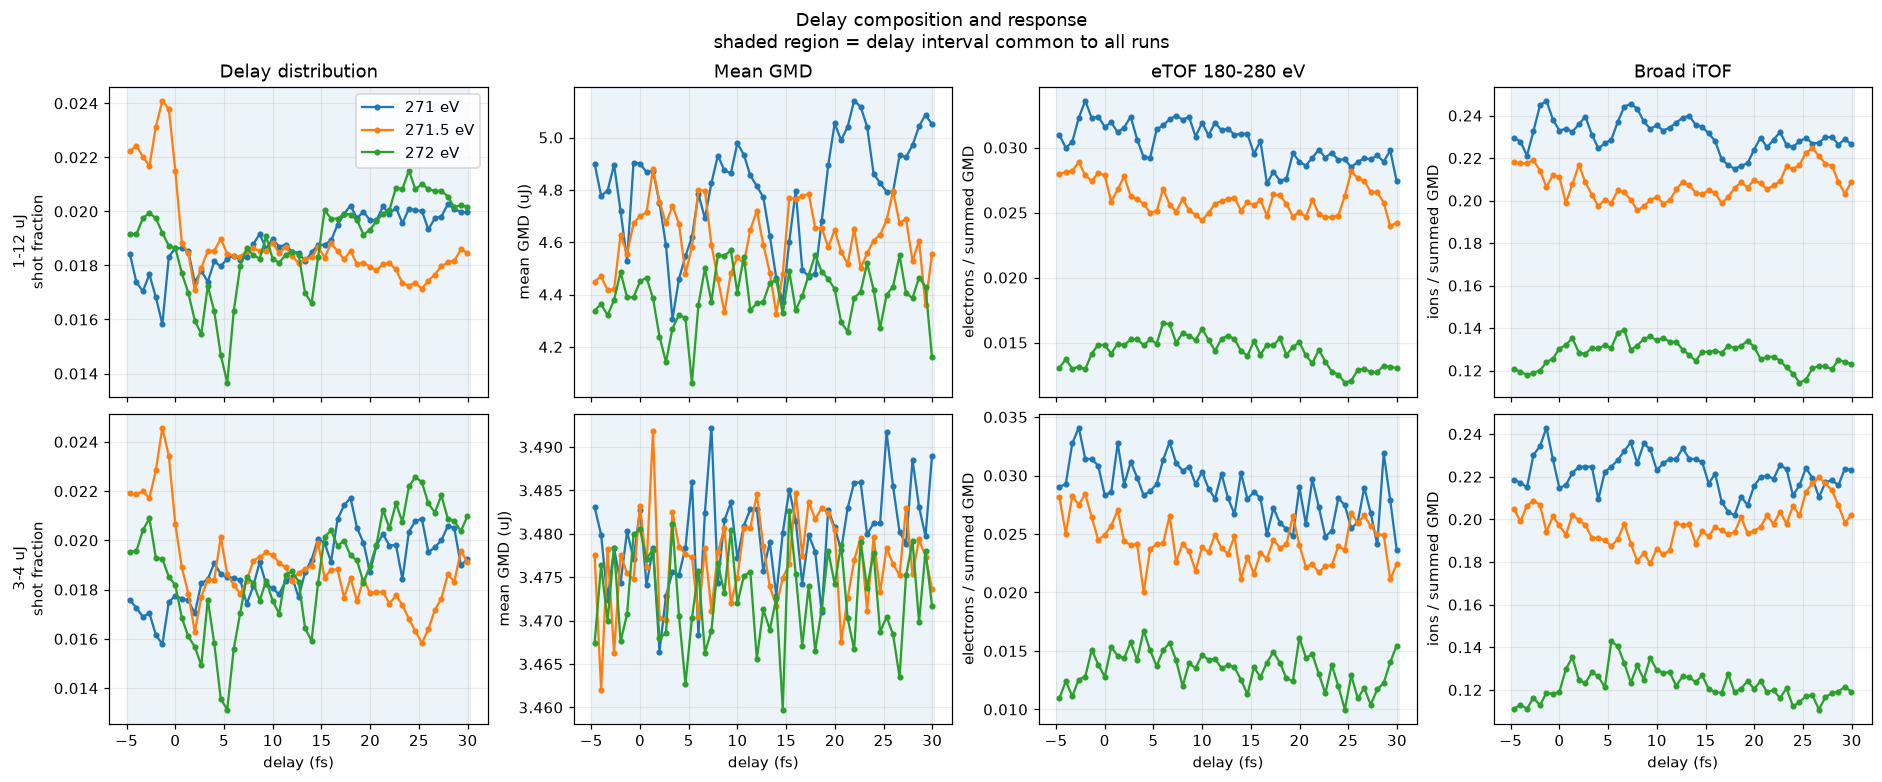

In [ ]:
# --- Delay distribution, mean GMD and delay-resolved eTOF/iTOF response -

fig, axes = plt.subplots(len(DIP_GMD_RANGES), 4, figsize=(17, 7), sharex=True, constrained_layout=True)

for row, (label, _) in enumerate(DIP_GMD_RANGES.items()):
    for result in dip_results:
        data = result["ranges"][label]
        shots, sum_gmd = data["shots_delay"], data["gmd_delay"]

        with np.errstate(invalid="ignore", divide="ignore"):
            shot_fraction = shots / np.sum(shots)
            mean_gmd = sum_gmd / shots
            e_per_gmd = data["electron_delay"] / sum_gmd
            i_per_gmd = data["ion_delay"] / sum_gmd

        good = shots > 0
        lbl = f"{result['energy']:g} eV"

        axes[row, 0].plot(dip_delay_centres[good], shot_fraction[good], "o-", ms=3, label=lbl)
        axes[row, 1].plot(dip_delay_centres[good], mean_gmd[good], "o-", ms=3, label=lbl)
        axes[row, 2].plot(dip_delay_centres[good], e_per_gmd[good], "o-", ms=3, label=lbl)
        axes[row, 3].plot(dip_delay_centres[good], i_per_gmd[good], "o-", ms=3, label=lbl)

    for ax in axes[row]:
        ax.axvspan(common_delay_lo, common_delay_hi, alpha=0.08)
        ax.grid(alpha=0.25)

    axes[row, 0].set_ylabel(f"{label}\nshot fraction")
    axes[row, 1].set_ylabel("mean GMD (uJ)")
    axes[row, 2].set_ylabel("electrons / summed GMD")
    axes[row, 3].set_ylabel("ions / summed GMD")

axes[0, 0].set_title("Delay distribution")
axes[0, 1].set_title("Mean GMD")
axes[0, 2].set_title(f"eTOF {DIP_ELECTRON_KE_RANGE[0]:g}-{DIP_ELECTRON_KE_RANGE[1]:g} eV")
axes[0, 3].set_title("Broad iTOF")

for ax in axes[-1]: ax.set_xlabel("delay (fs)")
axes[0, 0].legend()

fig.suptitle("Delay composition and response\nshaded region = delay interval common to all runs")
plt.show()

selection   energy    E/G all      E/G common   E/G balanced   I/G all      I/G common   I/G balanced   common shots/all
1-12 uJ   271.0     0.029993    0.030284    0.030276     0.230159    0.230814    0.230797      0.389
1-12 uJ   271.5     0.026350    0.026126    0.026067     0.210584    0.207956    0.208146      0.409
1-12 uJ   272.0     0.014225    0.014214    0.014220     0.130335    0.127213    0.127245      0.395
3-4 uJ    271.0     0.028355    0.028537    0.028541     0.222494    0.221425    0.221516      0.389
3-4 uJ    271.5     0.024628    0.024308    0.024224     0.201512    0.197516    0.197931      0.412
3-4 uJ    272.0     0.013434    0.013359    0.013403     0.126045    0.121833    0.122081      0.395


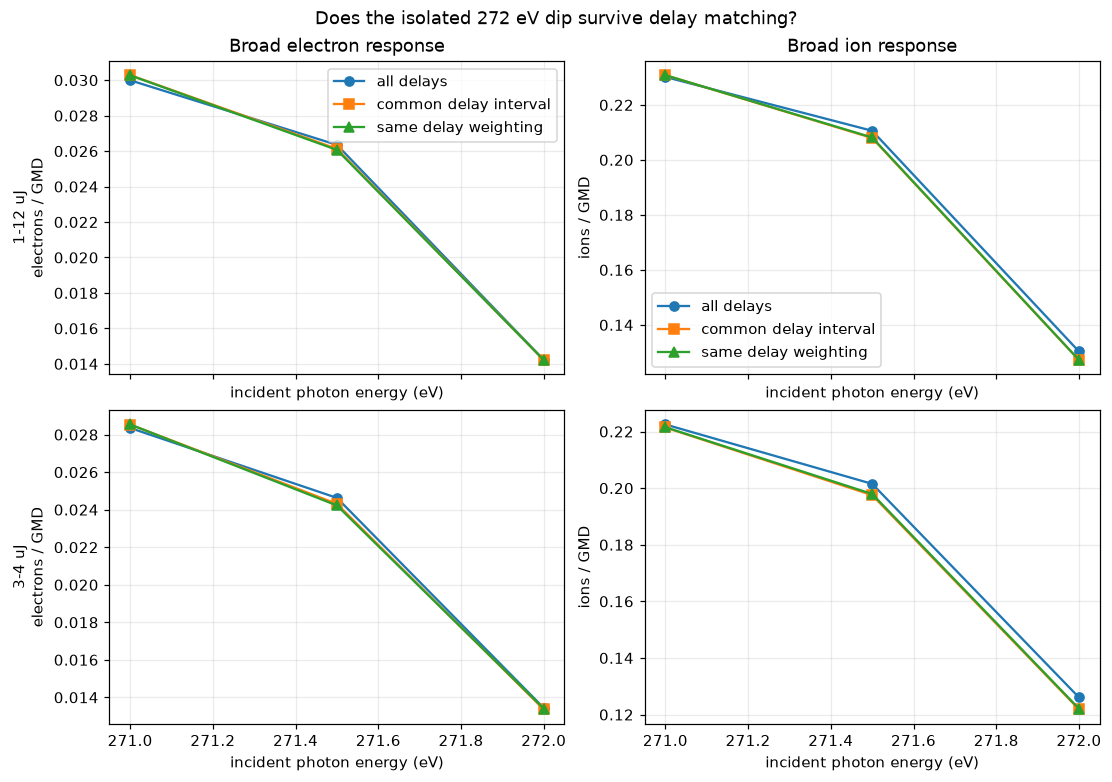


272 eV / mean(271.5, 272.5 eV):

1-12 uJ
  E_all       : 1.1918
  E_common    : 1.1743
  E_balanced  : 1.1717
  I_all       : 1.1683
  I_common    : 1.1617
  I_balanced  : 1.1627

3-4 uJ
  E_all       : 1.1787
  E_common    : 1.1604
  E_balanced  : 1.1551
  I_all       : 1.1563
  I_common    : 1.1508
  I_balanced  : 1.1521


In [ ]:
# --- Does the 272 eV dip survive matched delay and GMD composition? ------

def dip_ratio(total, numerator):
    return total[numerator] / total["sum_gmd"] if total["sum_gmd"] > 0 else np.nan


fig, axes = plt.subplots(len(DIP_GMD_RANGES), 2, figsize=(10, 7), sharex=True, constrained_layout=True)

print("selection   energy    E/G all      E/G common   E/G balanced   I/G all      I/G common   I/G balanced   common shots/all")

dip_summary = {}

for row, label in enumerate(DIP_GMD_RANGES):
    energies = np.array([result["energy"] for result in dip_results])

    e_all, e_common, i_all, i_common = [], [], [], []

    # Build one identical delay weighting for all three energies.
    gmd_stack = np.vstack([result["ranges"][label]["gmd_delay"] for result in dip_results])
    shots_stack = np.vstack([result["ranges"][label]["shots_delay"] for result in dip_results])

    common_bin = np.all(shots_stack > 0, axis=0) & (dip_delay_centres >= common_delay_lo) & (dip_delay_centres < common_delay_hi)
    common_weight = np.zeros(n_delay_bins, dtype=float)
    if np.any(common_bin): common_weight[common_bin] = np.min(gmd_stack[:, common_bin], axis=0)

    e_balanced, i_balanced = [], []

    for result in dip_results:
        data = result["ranges"][label]

        e_all.append(dip_ratio(data["all"], "electrons"))
        e_common.append(dip_ratio(data["common_delay"], "electrons"))
        i_all.append(dip_ratio(data["all"], "ions"))
        i_common.append(dip_ratio(data["common_delay"], "ions"))

        with np.errstate(invalid="ignore", divide="ignore"):
            e_delay_response = data["electron_delay"] / data["gmd_delay"]
            i_delay_response = data["ion_delay"] / data["gmd_delay"]

        valid_e = (common_weight > 0) & np.isfinite(e_delay_response)
        valid_i = (common_weight > 0) & np.isfinite(i_delay_response)

        e_balanced.append(np.average(e_delay_response[valid_e], weights=common_weight[valid_e]) if np.any(valid_e) else np.nan)
        i_balanced.append(np.average(i_delay_response[valid_i], weights=common_weight[valid_i]) if np.any(valid_i) else np.nan)

    e_all, e_common, e_balanced = np.asarray(e_all), np.asarray(e_common), np.asarray(e_balanced)
    i_all, i_common, i_balanced = np.asarray(i_all), np.asarray(i_common), np.asarray(i_balanced)

    dip_summary[label] = {
        "energy": energies, "E_all": e_all, "E_common": e_common, "E_balanced": e_balanced,
        "I_all": i_all, "I_common": i_common, "I_balanced": i_balanced,
    }

    axes[row, 0].plot(energies, e_all, "o-", label="all delays")
    axes[row, 0].plot(energies, e_common, "s-", label="common delay interval")
    axes[row, 0].plot(energies, e_balanced, "^-", label="same delay weighting")

    axes[row, 1].plot(energies, i_all, "o-", label="all delays")
    axes[row, 1].plot(energies, i_common, "s-", label="common delay interval")
    axes[row, 1].plot(energies, i_balanced, "^-", label="same delay weighting")

    axes[row, 0].set_ylabel(f"{label}\nelectrons / GMD")
    axes[row, 1].set_ylabel("ions / GMD")

    for result, ea, ec, eb, ia, ic, ib in zip(dip_results, e_all, e_common, e_balanced, i_all, i_common, i_balanced):
        data = result["ranges"][label]
        fraction = data["common_delay"]["shots"] / data["all"]["shots"] if data["all"]["shots"] > 0 else np.nan
        print(f"{label:9s} {result['energy']:5.1f}   {ea:10.6f}  {ec:10.6f}  {eb:10.6f}   {ia:10.6f}  {ic:10.6f}  {ib:10.6f}   {fraction:8.3f}")

axes[0, 0].set_title("Broad electron response")
axes[0, 1].set_title("Broad ion response")

for ax in axes.flat:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)

axes[0, 0].legend()
axes[0, 1].legend()

fig.suptitle("Does the isolated 272 eV dip survive delay matching?")
plt.show()

# --- Quantify the 272 eV dip relative to its two neighbouring runs -------
print("\n271.5 eV / mean(271.0, 272.0 eV):")

for label, summary in dip_summary.items():
    print(f"\n{label}")
    for metric in ["E_all", "E_common", "E_balanced", "I_all", "I_common", "I_balanced"]:
        values = summary[metric]
        neighbour_mean = 0.5 * (values[0] + values[2])
        ratio = values[1] / neighbour_mean
        print(f"  {metric:12s}: {ratio:.4f}")